# 3팀 공통 노트북 — 첫 결제 후 7일 이내 재결제 단절 요인 분석

| 항목 | 내용 |
|---|---|
| 우리 팀 | 데이터 분석팀 |
| 의사결정자 | PM |
| 상황 | PM이 2023년 하반기에 상품 판매액을 늘리기 위한 전략을 도출하고자 한다.<br>분석 시점에 가까운 고객 행동 데이터를 토대로 고객의 세그먼트를 나누어 분석한다. |
| 분석 시점 | 2023년 8월 중순 (데이터 기간: ~2023-08-10) |
| 분석 내용 | 1. 재결제 단절 확인<br>2. 재결제 퍼널과 병목 탐색<br>3. 첫 결제자 세그먼트 구분<br>4. 재결제 병목 유저 하트 잔액 세그먼트와 개선 우선순위<br>5. 세그먼트별 개선안 근거 |
| 현상 | 첫 결제 후 7일 안에 다시 결제한 비율은 결제 시작 첫 주(5/14~) 20%에서 한 달 뒤(6/11~) 7%로 떨어졌고, 7/9~8/3에는 6%에 머물렀다. |
| 문제 정의 | 첫 결제 후 7일 안에 다시 결제한 비율은 결제 시작 첫 주(5/14~) 20%에서 한 달 뒤(6/11~) 7%로 떨어졌다. 같은 기간 새로 결제하는 학생도 주 30,035명에서 536명으로 줄어, 매출은 이미 결제한 학생의 재결제에 달려 있다.<br>그런데 첫 결제 후 7일 안에 다시 결제하지 않은 학생의 92%는 그 7일 동안 친구 요청, 출석 같은 활동을 이어 갔다. 즉, 이들은 앱을 떠나지 않고 남아 있지만, 다시 결제로 이어지지 않고 있다. |
| 주제 | 첫 결제 후 7일 이내 재결제 단절 요인 분석을 통한 재결제율 개선안 제안 |

| 장 | 내용 |
|---|---|
| 전처리 | 원본 DB 정리와 CSV 만들기 (로컬 MySQL에서 실행, 코랩에서는 건너뜀) |
| 0 | 공통 기준, 데이터 불러오기, 공통 테이블(`base`, `pay`, `buyer`, `rb`) |
| 1 | 배경: 결제 건수의 88%가 5월에 집중 |
| 2 | 현상과 문제: 첫 결제 후 재결제 단절, 재결제 여부별 매출 |
| 3 | 재결제까지의 퍼널과 병목, 앱을 다시 켜도 상점에 안 가는 이유 |
| 4 | 첫 결제자를 재결제·활동 기준으로 나눈 세 그룹 (재결제 유저: 재결제함, 재결제 병목 유저: 활동은 하는데 재결제 안 함, 이탈 유저: 기록상 활동도 재결제도 없음) |
| 5 | 재결제 병목 유저를 하트 잔액 구간으로 나눈 개선 우선순위 |
| 6 | 세그먼트별 개선안의 근거 (상점 진입 경로, 상점 안 행동, 재결제 유저의 첫 재결제 상품, 힌트 단계) |
| 7 | 결론: 세그먼트별 개선안과 우선순위, 확인 방법과 한계 |
| 부록 A | 재결제 기준(관찰 기간 7일, 10분 안 연속 결제 제외)을 정한 근거 |
| 부록 B~H | 결론에 직접 쓰지 않은 분석: 결제 구성, 재결제 유저 특성, 로지스틱 회귀, 상점 재방문과 상점 진입 보충, 7월 복귀, 세 그룹 보충, 첫 결제 분석 |
| 부록 I | 힌트 기능 확인: 힌트를 쓴 사람과 글자를 여는 순서 (5장 세그먼트 경계의 전제) |

- 실행: 0장을 위에서부터 끝까지 실행한 뒤 1장부터 이어서 씀. 1장 이후는 0장이 만든 `base`, `pay`, `buyer`, `rb`만 사용하고, 기준값은 0-4 셀의 상수를 그대로 씀. 부록은 본문을 모두 실행한 뒤 이어서 실행함
- 기준을 바꿀 때는 0-4 셀의 상수와 0-1~0-3 표를 함께 고치고, 0-9 확인 셀을 다시 실행해 바뀐 수치를 팀에 공유함
- 실행 환경: 구글 코랩 권장. 필요 라이브러리 pandas, numpy, matplotlib, scikit-learn

---
## 전처리. 원본 DB 정리와 CSV 만들기 (로컬 MySQL)

제공받은 덤프를 로컬 MySQL에 restore한 원본 DB(`final`)를 정리해 새 스키마 `final_clean`을 만들고, 테이블마다 CSV로 내보냄. 0장부터는 이 CSV를 읽음.

| 단계 | 내용 |
|---|---|
| 전처리-0 | DB 연결 |
| 전처리-1 | 사용할 테이블 22개 확인 (팀이 제외하기로 한 3개는 복사하지 않음) |
| 전처리-2 | 원본을 `final_clean`으로 복사하면서 완전중복 행 제거 |
| 전처리-3 | 관리자·직원 계정과 그 계정의 기록 제거 |
| 전처리-4 | 서비스 내부 데이터의 시각을 한국 시간으로 변환 |
| 전처리-5 | 원본의 외래키 16개를 다시 연결 |
| 전처리-6 | 결과 확인 |
| 전처리-7 | 테이블마다 CSV로 내보내기 |
| 전처리-8 | 분석 단계로 넘긴 추가 전처리 |

- 이 장은 MySQL 서버와 원본 DB가 있는 로컬에서만 실행됨. 아래 `RUN_PREPROCESS`가 `False`이면 이 장의 셀은 아무것도 하지 않고 넘어가므로, 코랩에서는 그대로 0장부터 실행됨
- 아래 출력은 2026-11-13 로컬(MySQL 8.0, 버퍼 풀 4GB)에서 `RUN_PREPROCESS = True`로 실행한 결과임. `False`인 채로 이 장을 다시 실행하면 저장된 출력이 지워지므로, 제출본은 출력이 남아 있는 상태로 냄
- 전체 실행에 약 30분 걸림. 대부분 `accounts_friendrequest`(1,714만 행)와 `hackle_events`(1,144만 행)를 복사하고 바꾸는 시간임
- 실행하면 `final_clean`의 외래키를 풀고 같은 이름의 테이블을 지운 뒤 다시 만듦. 몇 번 실행해도 결과가 같음
- `final_clean`과 CSV의 시각은 모두 한국 시간(KST)임. 서비스 내부 데이터는 UTC로 저장되어 있어 전처리-4에서 9시간을 더했고, 핵클은 처음부터 한국 시간임

In [1]:
RUN_PREPROCESS = False   # True: 로컬 MySQL에서 final_clean과 CSV를 다시 만듦 (약 30분). 코랩에서는 False

if not RUN_PREPROCESS:
    print('RUN_PREPROCESS = False: 전처리 장을 건너뛰고 0장부터 실행함')

RUN_PREPROCESS = False: 전처리 장을 건너뛰고 0장부터 실행함


### 전처리-0. DB 연결

- 비밀번호는 실행할 때 입력받음. 노트북을 공유해도 비밀번호가 함께 퍼지지 않게 하려는 것임
- 원본 DB 이름을 `final`이 아닌 다른 이름으로 restore했다면 `SOURCE_DB`만 바꿈

In [2]:
if RUN_PREPROCESS:
    from getpass import getpass
    import time

    import pandas as pd
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    SOURCE_DB = "final"        # restore한 원본 DB
    CLEAN_DB = "final_clean"   # 정리한 테이블을 만들 스키마

    # 두 스키마를 오가야 하므로 database는 지정하지 않고, 쿼리에서 스키마 이름을 붙여 씀
    MYSQL_PASSWORD = getpass("MySQL 비밀번호: ")     # CSV 내보내기(전처리-7)의 mysql 클라이언트도 씀
    engine = create_engine(URL.create(
        drivername="mysql+pymysql",
        username="root",
        password=MYSQL_PASSWORD,
        host="localhost",
        port=3306,
    ))


    def run(sql):
        """결과를 돌려주지 않는 SQL(CREATE, INSERT, DELETE 등)을 실행하고 바뀐 행 수를 돌려줌"""
        with engine.begin() as conn:
            result = conn.execute(text(sql))
        return result.rowcount


    def query(sql):
        """SELECT 결과를 DataFrame으로 돌려줌"""
        return pd.read_sql(text(sql), engine)


    def count_rows(db, table):
        return int(query(f"SELECT COUNT(*) AS n FROM `{db}`.`{table}`")["n"].iloc[0])


    print(query("SELECT VERSION() AS mysql_version"))

  mysql_version
0        8.0.45


### 전처리-1. 사용할 테이블

- 팀이 제외하기로 한 테이블 3개(탈퇴 기록, 타임라인 신고, 기기 속성)는 `final_clean`에 만들지 않음. 나머지 22개를 씀
- 질문 신고(`polls_questionreport`)와 차단 기록(`accounts_blockrecord`)은 처음에 제외했다가 되살림. 질문을 신고하거나 친구를 차단한 경험이 있는 유저의 결제율이 없는 유저보다 높았고, 출석 일수로 활동량을 맞춘 뒤에도 차이가 남았음
- 타임라인 신고는 경험한 유저가 115명(전체의 0.02%)뿐이라 계속 제외함

In [3]:
if RUN_PREPROCESS:
    KEEP_TABLES = [
        # 가입·소속
        "accounts_user", "accounts_school", "accounts_group", "accounts_nearbyschool",
        # 친구 관계
        "accounts_friendrequest", "accounts_user_contacts", "accounts_blockrecord",
        # 투표
        "polls_question", "polls_questionset", "polls_questionpiece",
        "polls_usercandidate", "accounts_userquestionrecord", "polls_questionreport",
        # 포인트·결제
        "accounts_pointhistory", "accounts_paymenthistory", "accounts_failpaymenthistory",
        "accounts_attendance", "events", "event_receipts",
        # 핵클 로그
        "hackle_events", "hackle_properties", "user_properties",
    ]

    EXCLUDED_TABLES = [
        "accounts_userwithdraw", "accounts_timelinereport", "device_properties",
    ]

    source_tables = query(f"""
        SELECT TABLE_NAME AS table_name
        FROM information_schema.TABLES
        WHERE TABLE_SCHEMA = '{SOURCE_DB}'
    """)["table_name"].tolist()

    missing = [t for t in KEEP_TABLES if t not in source_tables]
    print("원본 테이블 수:", len(source_tables))
    print("사용할 테이블 수:", len(KEEP_TABLES))
    print("원본에 없는 테이블:", missing if missing else "없음")

원본 테이블 수: 25
사용할 테이블 수: 22
원본에 없는 테이블: 없음


### 전처리-2. 완전중복 제거

#### 완전중복의 기준
- id를 뺀 나머지 컬럼 값이 모두 같은 행을 완전중복으로 봄. id는 행마다 새로 붙는 번호라서, id까지 같은 행은 원본에 없음
- 같은 묶음에서는 id가 가장 작은 행 하나만 남김

#### 적용하는 테이블
- 기록이 쌓이는 테이블(요청, 차단, 신고, 후보, 포인트, 결제, 이벤트 로그)에만 적용함
- id가 다른 테이블에서 참조되는 테이블(학교, 학급, 질문, 질문 칸 등)은 지우지 않음. 이런 테이블은 id 외 값이 같아도 서로 다른 대상임
  - `polls_questionpiece`에서 id 외 컬럼이 같은 572행은 서로 다른 세트의 질문 칸임. 지우면 그 칸을 가리키던 투표 기록에 연결된 질문 칸이 없어짐
  - `accounts_school`의 458행도 같은 시·군·구에서 가입자 수가 우연히 같은 서로 다른 학교임. 학교명 컬럼이 없어 주소, 가입자 수, 학교 종류만으로는 구분되지 않음

| 테이블 | 지울 것으로 확인한 행 수 (2026-11-03) |
|---|---:|
| accounts_friendrequest | 63 |
| accounts_blockrecord | 5 |
| polls_questionreport | 0 |
| polls_usercandidate | 487 |
| accounts_pointhistory | 1,939 |
| accounts_paymenthistory | 531 |
| accounts_failpaymenthistory | 1 |
| hackle_events | 195,247 |

- `hackle_events`는 시각이 초 단위라서, 같은 초에 같은 이벤트를 두 번 보낸 것인지 한 번이 두 번 기록된 것인지 구분할 수 없음. 결제 전환 퍼널에서 같은 클릭이 두 번 세어지지 않도록 지우는 쪽을 택함

In [4]:
if RUN_PREPROCESS:
    # 테이블별로 "중복을 판단할 때 빼는 컬럼"을 적음. 여기 없는 테이블은 그대로 복사함
    DEDUP_TABLES = {
        "accounts_friendrequest": ["id"],
        "accounts_blockrecord": ["id"],
        "polls_questionreport": ["id"],
        "polls_usercandidate": ["id"],
        "accounts_pointhistory": ["id"],
        "accounts_paymenthistory": ["id"],
        "accounts_failpaymenthistory": ["id"],
        "hackle_events": ["event_id", "id"],  # id는 모든 행에서 event_id와 같은 값임
    }


    def columns_of(db, table):
        cols = query(f"""
            SELECT COLUMN_NAME AS col
            FROM information_schema.COLUMNS
            WHERE TABLE_SCHEMA = '{db}' AND TABLE_NAME = '{table}'
            ORDER BY ORDINAL_POSITION
        """)["col"].tolist()
        return cols


    run(f"CREATE DATABASE IF NOT EXISTS `{CLEAN_DB}`")

In [5]:
if RUN_PREPROCESS:
    # 전처리-5에서 건 외래키가 남아 있으면 다른 테이블이 참조하는 테이블(accounts_user 등)을 DROP할 수 없음.
    # 테이블을 다시 만들기 전에 final_clean의 외래키를 모두 풂
    existing_fks = query(f"""
        SELECT TABLE_NAME AS table_name, CONSTRAINT_NAME AS fk_name
        FROM information_schema.REFERENTIAL_CONSTRAINTS
        WHERE CONSTRAINT_SCHEMA = '{CLEAN_DB}'
    """)
    for row in existing_fks.itertuples():
        run(f"ALTER TABLE `{CLEAN_DB}`.`{row.table_name}` DROP FOREIGN KEY `{row.fk_name}`")
    print("푼 외래키:", len(existing_fks))

    summary = []

    for table in KEEP_TABLES:
        start = time.time()
        cols = columns_of(SOURCE_DB, table)
        col_list = ", ".join(f"`{c}`" for c in cols)

        # 원본과 같은 구조(컬럼, 기본키, 인덱스)로 빈 테이블을 만듦. 외래키는 복사되지 않아 전처리-5에서 검
        run(f"DROP TABLE IF EXISTS `{CLEAN_DB}`.`{table}`")
        run(f"CREATE TABLE `{CLEAN_DB}`.`{table}` LIKE `{SOURCE_DB}`.`{table}`")

        if table in DEDUP_TABLES:
            skip = DEDUP_TABLES[table]
            key_cols = ", ".join(f"`{c}`" for c in cols if c not in skip)
            order_col = skip[0]
            # 같은 값 묶음마다 번호를 매기고(id가 작은 순) 1번만 넣음.
            # 마지막 ORDER BY는 행을 id 순서로 넣으려는 것임. 순서가 뒤섞이면 MySQL이 페이지를
            # 반으로 나누며 빈 공간을 남겨, 테이블 용량이 원본의 최대 3배까지 커짐
            insert_sql = f"""
                INSERT INTO `{CLEAN_DB}`.`{table}` ({col_list})
                SELECT {col_list}
                FROM (
                    SELECT *,
                           ROW_NUMBER() OVER (PARTITION BY {key_cols} ORDER BY `{order_col}`) AS rn
                    FROM `{SOURCE_DB}`.`{table}`
                ) t
                WHERE rn = 1
                ORDER BY `{order_col}`
            """
        else:
            insert_sql = f"""
                INSERT INTO `{CLEAN_DB}`.`{table}` ({col_list})
                SELECT {col_list} FROM `{SOURCE_DB}`.`{table}`
            """
        run(insert_sql)

        before = count_rows(SOURCE_DB, table)
        after = count_rows(CLEAN_DB, table)
        summary.append({"table": table, "원본": before, "완전중복 제거 후": after})
        print(f"{table:<30} {before:>12,} → {after:>12,}  ({time.time() - start:,.0f}초)")

    summary = pd.DataFrame(summary).set_index("table")
    summary["완전중복 제거"] = summary["원본"] - summary["완전중복 제거 후"]

푼 외래키: 16
accounts_user                       677,085 →      677,085  (16초)
accounts_school                       5,951 →        5,951  (0초)
accounts_group                       84,515 →       84,515  (1초)
accounts_nearbyschool                59,500 →       59,500  (1초)
accounts_friendrequest           17,147,175 →   17,147,112  (479초)
accounts_user_contacts                5,063 →        5,063  (0초)
accounts_blockrecord                 19,482 →       19,477  (1초)
polls_question                        5,025 →        5,025  (0초)
polls_questionset                   158,384 →      158,384  (4초)
polls_questionpiece               1,265,476 →    1,265,476  (14초)
polls_usercandidate               4,769,609 →    4,769,122  (87초)
accounts_userquestionrecord       1,217,558 →    1,217,558  (29초)
polls_questionreport                 51,424 →       51,424  (2초)
accounts_pointhistory             2,338,918 →    2,336,979  (42초)
accounts_paymenthistory              95,140 →       94,609  (2초)
accounts

In [6]:
if RUN_PREPROCESS:
    # 지운 행이 있는 테이블만 봄. 마크다운 표의 확인 값과 같아야 함
    display(summary.loc[summary["완전중복 제거"] > 0])

,원본,완전중복 제거 후,완전중복 제거
table,,,
accounts_friendrequest,17147175,17147112,63
accounts_blockrecord,19482,19477,5
polls_usercandidate,4769609,4769122,487
accounts_pointhistory,2338918,2336979,1939
accounts_paymenthistory,95140,94609,531
accounts_failpaymenthistory,163,162,1
hackle_events,11441319,11246072,195247


### 전처리-3. 관리자·직원 계정 제거

- `is_staff = 1` 또는 `is_superuser = 1`인 계정을 지움. 이 계정이 남긴 기록(친구 요청, 투표, 포인트, 결제, 핵클 로그 등)도 함께 지움
- 2026-11-03 원본 기준으로 4명이고, 다른 테이블에 남긴 기록은 없음. 4명 중 2명은 `gender`가 NULL이라, 이 단계를 거치면 `gender` 결측이 0명이 됨

In [ ]:
if RUN_PREPROCESS:
    staff = query(f"""
        SELECT id, is_staff, is_superuser, gender, point, created_at
        FROM `{CLEAN_DB}`.accounts_user
        WHERE is_staff = 1 OR is_superuser = 1
    """)
    staff_ids = staff["id"].tolist()
    display(staff)

In [8]:
if RUN_PREPROCESS:
    # 유저 id를 담은 컬럼. 숫자 id와 같은 값이 들어 있는 핵클 컬럼(문자열)도 포함함
    USER_COLUMNS = {
        "accounts_friendrequest": ["send_user_id", "receive_user_id"],
        "accounts_user_contacts": ["user_id"],
        "accounts_blockrecord": ["user_id", "block_user_id"],
        "polls_questionset": ["user_id"],
        "polls_usercandidate": ["user_id"],
        "accounts_userquestionrecord": ["user_id", "chosen_user_id"],
        "polls_questionreport": ["user_id"],
        "accounts_pointhistory": ["user_id"],
        "accounts_paymenthistory": ["user_id"],
        "accounts_failpaymenthistory": ["user_id"],
        "accounts_attendance": ["user_id"],
        "event_receipts": ["user_id"],
        "user_properties": ["user_id"],
    }

    removed_staff = {table: 0 for table in KEEP_TABLES}

    if staff_ids:
        id_list = ", ".join(str(i) for i in staff_ids)
        id_text_list = ", ".join(f"'{i}'" for i in staff_ids)

        # 핵클 이벤트에는 유저 id가 없음. 직원 계정이 쓴 session_id의 이벤트를 먼저 지움
        removed_staff["hackle_events"] = run(f"""
            DELETE FROM `{CLEAN_DB}`.hackle_events
            WHERE session_id IN (
                SELECT session_id
                FROM `{CLEAN_DB}`.hackle_properties
                WHERE user_id IN ({id_text_list})
            )
        """)
        removed_staff["hackle_properties"] = run(f"""
            DELETE FROM `{CLEAN_DB}`.hackle_properties WHERE user_id IN ({id_text_list})
        """)

        for table, cols in USER_COLUMNS.items():
            ids = id_text_list if table == "user_properties" else id_list
            where = " OR ".join(f"`{c}` IN ({ids})" for c in cols)
            removed_staff[table] += run(f"DELETE FROM `{CLEAN_DB}`.`{table}` WHERE {where}")

        removed_staff["accounts_user"] = run(f"""
            DELETE FROM `{CLEAN_DB}`.accounts_user WHERE id IN ({id_list})
        """)

    summary["직원 계정 제거"] = pd.Series(removed_staff)
    display(summary.loc[summary["직원 계정 제거"] > 0, ["직원 계정 제거"]])

,직원 계정 제거
table,
accounts_user,4


### 전처리-4. 시각을 한국 시간으로 바꾸기

#### 서비스 내부 데이터가 UTC라는 근거
- 같은 결제를 서비스 DB(`accounts_paymenthistory`)와 핵클(`complete_purchase`, 하트 구입 완료)이 각각 기록함. 핵클 기간(2023-07-18 ~ 08-10)에 같은 유저의 결제와 구입 완료 이벤트를 짝지어 두 시각의 차이를 셈
- 핵클 이벤트에는 유저 id가 없으므로, `session_id`에 숫자 유저 id가 하나만 붙은 세션만 씀
- 짝이 9시간 차이에 몰려 있으면 서비스 DB가 핵클보다 9시간 이르게 찍혀 있는 것임. 핵클은 20시에 이벤트가 가장 많아 한국 시간으로 보고, 서비스 내부 데이터를 UTC로 판단함

In [9]:
if RUN_PREPROCESS:
    offset = query(f"""
        WITH session_user AS (
            SELECT session_id, MIN(CAST(user_id AS UNSIGNED)) AS uid
            FROM `{SOURCE_DB}`.hackle_properties
            WHERE user_id REGEXP '^[0-9]+$'
            GROUP BY session_id
            HAVING COUNT(DISTINCT user_id) = 1
        ), purchase AS (
            SELECT su.uid, e.event_datetime
            FROM `{SOURCE_DB}`.hackle_events e
            JOIN session_user su ON su.session_id = e.session_id
            WHERE e.event_key = 'complete_purchase'
        ), pairs AS (
            SELECT p.user_id,
                   TIMESTAMPDIFF(MINUTE, p.created_at, pu.event_datetime) AS diff_min
            FROM `{SOURCE_DB}`.accounts_paymenthistory p
            JOIN purchase pu ON pu.uid = p.user_id
            WHERE p.created_at BETWEEN '2023-07-17' AND '2023-08-11'
              AND pu.event_datetime BETWEEN p.created_at - INTERVAL 14 HOUR
                                        AND p.created_at + INTERVAL 14 HOUR
        )
        SELECT ROUND(diff_min / 60) AS diff_hour,
               COUNT(*) AS pairs,
               COUNT(DISTINCT user_id) AS users
        FROM pairs
        GROUP BY diff_hour
        ORDER BY pairs DESC
    """)

    # 핵클 시각 - 결제 시각. 9시간에 짝이 몰려 있어야 함
    display(offset.head(5))

,diff_hour,pairs,users
0,9.0,3378,1616
1,7.0,11,7
2,11.0,11,7
3,8.0,8,8
4,10.0,8,8


#### 바꾸는 방법
- 서비스 테이블 14개의 시각 컬럼 17개에 9시간을 더함. `_kst` 컬럼을 따로 만들지 않고 값을 바로 바꿈. 쿼리마다 9시간을 더하다가 빠뜨리거나 두 번 더하는 실수를 막기 위해서임
- 핵클 테이블의 `event_datetime`은 이미 한국 시간이라 그대로 둠
- `accounts_attendance.attendance_date_list`는 시각 없이 날짜만 담은 목록이라 바꾸지 않음. 어느 기준의 날짜인지는 확인하지 못함
- 이 셀을 두 번 실행해도 18시간이 더해지지 않도록, 컬럼마다 원본과 같은 id의 행 하나를 비교해서 이미 9시간이 더해진 컬럼은 건너뜀

In [10]:
if RUN_PREPROCESS:
    TIME_COLUMNS = {
        "accounts_user": ["created_at"],
        "accounts_friendrequest": ["created_at", "updated_at"],
        "accounts_blockrecord": ["created_at"],
        "polls_question": ["created_at"],
        "polls_questionset": ["opening_time", "created_at"],
        "polls_questionpiece": ["created_at"],
        "polls_usercandidate": ["created_at"],
        "accounts_userquestionrecord": ["created_at", "answer_updated_at"],
        "polls_questionreport": ["created_at"],
        "accounts_pointhistory": ["created_at"],
        "accounts_paymenthistory": ["created_at"],
        "accounts_failpaymenthistory": ["created_at"],
        "events": ["created_at"],
        "event_receipts": ["created_at"],
    }
    KST_SECONDS = 9 * 60 * 60


    def current_offset(table, col):
        """원본과 final_clean에서 같은 id인 행 하나를 골라 시각 차이(초)를 돌려줌"""
        result = query(f"""
            SELECT TIMESTAMPDIFF(SECOND, s.`{col}`, c.`{col}`) AS diff
            FROM `{CLEAN_DB}`.`{table}` c
            JOIN `{SOURCE_DB}`.`{table}` s ON s.id = c.id
            WHERE s.`{col}` IS NOT NULL
            LIMIT 1
        """)
        return int(result["diff"].iloc[0])


    kst_log = []
    for table, cols in TIME_COLUMNS.items():
        start = time.time()
        todo = []
        for col in cols:
            diff = current_offset(table, col)
            if diff == 0:
                todo.append(col)
            elif diff == KST_SECONDS:
                print(f"{table}.{col}: 이미 한국 시간이라 건너뜀")
            else:
                raise ValueError(f"{table}.{col}: 원본과 {diff}초 차이. final_clean을 전처리-2부터 다시 만들어야 함")

        if todo:
            set_list = ", ".join(f"`{c}` = `{c}` + INTERVAL 9 HOUR" for c in todo)
            changed = run(f"UPDATE `{CLEAN_DB}`.`{table}` SET {set_list}")
            print(f"{table:<30} {', '.join(todo):<30} {changed:>12,}행  ({time.time() - start:,.0f}초)")
            for c in todo:
                kst_log.append({"table": table, "column": c, "바꾼 행": changed})

accounts_user                  created_at                          677,081행  (8초)
accounts_friendrequest         created_at, updated_at           17,147,112행  (109초)
accounts_blockrecord           created_at                           19,477행  (0초)
polls_question                 created_at                            5,025행  (0초)
polls_questionset              opening_time, created_at            158,384행  (2초)
polls_questionpiece            created_at                        1,265,476행  (8초)
polls_usercandidate            created_at                        4,769,122행  (26초)
accounts_userquestionrecord    created_at, answer_updated_at     1,217,558행  (9초)
polls_questionreport           created_at                           51,424행  (0초)
accounts_pointhistory          created_at                        2,336,979행  (13초)
accounts_paymenthistory        created_at                           94,609행  (1초)
accounts_failpaymenthistory    created_at                              162행  (0초)
events      

In [11]:
if RUN_PREPROCESS:
    # 원본과 같은 id의 모든 행을 비교함. "9시간 차이가 아닌 행"이 모두 0이어야 함
    kst_check = []
    for table, cols in TIME_COLUMNS.items():
        parts = ", ".join(
            f"SUM(s.`{c}` IS NOT NULL AND TIMESTAMPDIFF(SECOND, s.`{c}`, c.`{c}`) <> {KST_SECONDS}) AS `{c}`"
            for c in cols
        )
        result = query(f"""
            SELECT {parts}
            FROM `{CLEAN_DB}`.`{table}` c
            JOIN `{SOURCE_DB}`.`{table}` s ON s.id = c.id
        """)
        for col in cols:
            kst_check.append({"table": table, "column": col, "9시간 차이가 아닌 행": int(result[col].iloc[0])})

    kst_check = pd.DataFrame(kst_check)
    print("9시간 차이가 아닌 행이 있는 컬럼:", int((kst_check["9시간 차이가 아닌 행"] != 0).sum()))
    display(kst_check)

9시간 차이가 아닌 행이 있는 컬럼: 0


,table,column,9시간 차이가 아닌 행
0,accounts_user,created_at,0
1,accounts_friendrequest,created_at,0
2,accounts_friendrequest,updated_at,0
3,accounts_blockrecord,created_at,0
4,polls_question,created_at,0
5,polls_questionset,opening_time,0
6,polls_questionset,created_at,0
7,polls_questionpiece,created_at,0
8,polls_usercandidate,created_at,0
9,accounts_userquestionrecord,created_at,0


### 전처리-5. 외래키 연결

- 전처리-2의 `CREATE TABLE ... LIKE`는 컬럼, 기본키, 인덱스만 복사하고 외래키는 복사하지 않음. 원본 `final`의 외래키 17개 중 제외한 테이블(`accounts_timelinereport`)에 걸린 1개를 뺀 16개를 다시 검. 외래키 이름은 팀에 공유한 외래키 쿼리와 같음
- 외래키 검사를 켠 채로 외래키를 추가하면 MySQL이 테이블을 통째로 복사해 다시 만듦. `accounts_friendrequest`(1,714만 행)에서 오래 걸리므로, 부모 테이블에 없는 id를 가리키는 행이 0건인지 먼저 직접 센 뒤 검사를 끄고 검
- 원본에서도 외래키가 아니었던 연결은 걸지 않음. 질문 칸과 질문(`polls_questionpiece.question_id`), 세트와 유저(`polls_questionset.user_id`), 투표 기록과 유저(`accounts_userquestionrecord.user_id`, `chosen_user_id`) 등이 해당함. 세트와 질문 칸을 잇는 `question_piece_id_list`는 JSON 배열 문자열이라 외래키로 걸 수 없음

In [12]:
if RUN_PREPROCESS:
    # (자식 테이블, 컬럼, 부모 테이블, 외래키 이름). 부모 쪽 컬럼은 모두 id임
    FOREIGN_KEYS = [
        ("accounts_attendance", "user_id", "accounts_user", "fk_attendance_user"),
        ("accounts_blockrecord", "user_id", "accounts_user", "fk_blockrecord_user"),
        ("accounts_blockrecord", "block_user_id", "accounts_user", "fk_blockrecord_block_user"),
        ("accounts_failpaymenthistory", "user_id", "accounts_user", "fk_failpaymenthistory_user"),
        ("accounts_paymenthistory", "user_id", "accounts_user", "fk_paymenthistory_user"),
        ("accounts_friendrequest", "send_user_id", "accounts_user", "fk_friendrequest_send"),
        ("accounts_friendrequest", "receive_user_id", "accounts_user", "fk_friendrequest_receive"),
        ("accounts_nearbyschool", "school_id", "accounts_school", "fk_nearbyschool_school"),
        ("accounts_nearbyschool", "nearby_school_id", "accounts_school", "fk_nearbyschool_nearby"),
        ("accounts_pointhistory", "user_question_record_id", "accounts_userquestionrecord", "fk_pointhistory_uqr"),
        ("accounts_userquestionrecord", "question_piece_id", "polls_questionpiece", "fk_uqr_question_piece"),
        ("polls_usercandidate", "question_piece_id", "polls_questionpiece", "fk_usercandidate_piece"),
        ("event_receipts", "event_id", "events", "fk_event_receipts_event"),
        ("event_receipts", "user_id", "accounts_user", "fk_event_receipts_user"),
        ("polls_questionreport", "question_id", "polls_question", "fk_questionreport_question"),
        ("polls_questionreport", "user_id", "accounts_user", "fk_questionreport_user"),
    ]

    # 위 목록이 원본 외래키 중 자식·부모 테이블이 모두 final_clean에 있는 것과 같은지 확인함
    source_fks = query(f"""
        SELECT TABLE_NAME AS child, COLUMN_NAME AS col, REFERENCED_TABLE_NAME AS parent
        FROM information_schema.KEY_COLUMN_USAGE
        WHERE TABLE_SCHEMA = '{SOURCE_DB}' AND REFERENCED_TABLE_NAME IS NOT NULL
    """)
    expected = [
        (r.child, r.col, r.parent) for r in source_fks.itertuples()
        if r.child in KEEP_TABLES and r.parent in KEEP_TABLES
    ]
    declared = [(child, col, parent) for child, col, parent, _ in FOREIGN_KEYS]
    not_declared = [fk for fk in expected if fk not in declared]
    not_in_source = [fk for fk in declared if fk not in expected]
    if not_declared or not_in_source:
        raise ValueError(f"원본 외래키와 다름. 목록에 없음: {not_declared}, 원본에 없음: {not_in_source}")

    # 부모 테이블에 없는 id를 가리키는 행을 셈. 모두 0이어야 외래키를 검
    orphan_sql = "\nUNION ALL\n".join(
        f"""SELECT '{child}.{col}' AS fk, COUNT(*) AS n
            FROM `{CLEAN_DB}`.`{child}` x
            LEFT JOIN `{CLEAN_DB}`.`{parent}` y ON y.id = x.`{col}`
            WHERE x.`{col}` IS NOT NULL AND y.id IS NULL"""
        for child, col, parent, _ in FOREIGN_KEYS
    )
    orphans = query(orphan_sql)
    if (orphans["n"] > 0).any():
        raise ValueError(f"부모가 없는 행이 있음:\n{orphans[orphans['n'] > 0]}")

    # 이미 걸린 외래키는 건너뜀. 이 셀만 다시 실행해도 같은 이름을 두 번 만들지 않음
    existing = query(f"""
        SELECT CONSTRAINT_NAME AS fk_name
        FROM information_schema.REFERENTIAL_CONSTRAINTS
        WHERE CONSTRAINT_SCHEMA = '{CLEAN_DB}'
    """)["fk_name"].tolist()

    # 외래키 검사 설정은 연결마다 따로 적용되므로, 한 연결 안에서 끄고, 걸고, 다시 켬
    start = time.time()
    added = 0
    with engine.begin() as conn:
        conn.execute(text("SET SESSION FOREIGN_KEY_CHECKS = 0"))
        try:
            for child, col, parent, name in FOREIGN_KEYS:
                if name in existing:
                    continue
                conn.execute(text(f"""
                    ALTER TABLE `{CLEAN_DB}`.`{child}`
                    ADD CONSTRAINT `{name}` FOREIGN KEY (`{col}`) REFERENCES `{CLEAN_DB}`.`{parent}` (id)
                """))
                added += 1
        finally:
            conn.execute(text("SET SESSION FOREIGN_KEY_CHECKS = 1"))

    print(f"새로 건 외래키: {added}개, 이미 있던 외래키: {len(FOREIGN_KEYS) - added}개  ({time.time() - start:,.0f}초)")

새로 건 외래키: 16개, 이미 있던 외래키: 0개  (0초)


In [13]:
if RUN_PREPROCESS:
    # final_clean에 걸린 외래키. 16개여야 함
    fk_check = query(f"""
        SELECT k.TABLE_NAME AS child, k.COLUMN_NAME AS col,
               k.REFERENCED_TABLE_NAME AS parent, k.CONSTRAINT_NAME AS fk_name
        FROM information_schema.KEY_COLUMN_USAGE k
        WHERE k.TABLE_SCHEMA = '{CLEAN_DB}' AND k.REFERENCED_TABLE_NAME IS NOT NULL
        ORDER BY k.TABLE_NAME, k.COLUMN_NAME
    """)
    print("외래키 수:", len(fk_check))
    display(fk_check)

외래키 수: 16


,child,col,parent,fk_name
0,accounts_attendance,user_id,accounts_user,fk_attendance_user
1,accounts_blockrecord,block_user_id,accounts_user,fk_blockrecord_block_user
2,accounts_blockrecord,user_id,accounts_user,fk_blockrecord_user
3,accounts_failpaymenthistory,user_id,accounts_user,fk_failpaymenthistory_user
4,accounts_friendrequest,receive_user_id,accounts_user,fk_friendrequest_receive
5,accounts_friendrequest,send_user_id,accounts_user,fk_friendrequest_send
6,accounts_nearbyschool,nearby_school_id,accounts_school,fk_nearbyschool_nearby
7,accounts_nearbyschool,school_id,accounts_school,fk_nearbyschool_school
8,accounts_paymenthistory,user_id,accounts_user,fk_paymenthistory_user
9,accounts_pointhistory,user_question_record_id,accounts_userquestionrecord,fk_pointhistory_uqr


### 전처리-6. 결과 확인

- `최종`은 `final_clean`에서 다시 센 행 수임. `원본 − 완전중복 제거 − 직원 계정 제거`와 같아야 함
- 두 번째 셀의 네 값(남은 직원 계정, `gender` 결측, 질문 칸이 없는 투표 기록, 투표 기록이 없는 포인트 기록)은 모두 0이어야 함

In [14]:
if RUN_PREPROCESS:
    summary["최종"] = [count_rows(CLEAN_DB, t) for t in summary.index]
    summary["차이 확인"] = summary["원본"] - summary["완전중복 제거"] - summary["직원 계정 제거"] - summary["최종"]

    print("행 수가 맞지 않는 테이블:", int((summary["차이 확인"] != 0).sum()))
    display(summary[["원본", "완전중복 제거", "직원 계정 제거", "최종"]].style.format("{:,}"))

행 수가 맞지 않는 테이블: 0


,원본,완전중복 제거,직원 계정 제거,최종
table,,,,
accounts_user,"677,085",0,4,"677,081"
accounts_school,"5,951",0,0,"5,951"
accounts_group,"84,515",0,0,"84,515"
accounts_nearbyschool,"59,500",0,0,"59,500"
accounts_friendrequest,"17,147,175",63,0,"17,147,112"
accounts_user_contacts,"5,063",0,0,"5,063"
accounts_blockrecord,"19,482",5,0,"19,477"
polls_question,"5,025",0,0,"5,025"
polls_questionset,"158,384",0,0,"158,384"


In [15]:
if RUN_PREPROCESS:
    checks = query(f"""
        SELECT
          (SELECT COUNT(*) FROM `{CLEAN_DB}`.accounts_user
            WHERE is_staff = 1 OR is_superuser = 1)                                AS staff_left,
          (SELECT COUNT(*) FROM `{CLEAN_DB}`.accounts_user WHERE gender IS NULL)   AS gender_null,
          (SELECT COUNT(*) FROM `{CLEAN_DB}`.accounts_userquestionrecord r
            LEFT JOIN `{CLEAN_DB}`.polls_questionpiece p ON p.id = r.question_piece_id
            WHERE p.id IS NULL)                                                    AS record_without_piece,
          (SELECT COUNT(*) FROM `{CLEAN_DB}`.accounts_pointhistory h
            LEFT JOIN `{CLEAN_DB}`.accounts_userquestionrecord r ON r.id = h.user_question_record_id
            WHERE h.user_question_record_id IS NOT NULL AND r.id IS NULL)          AS point_without_record
    """)

    # 모두 0이어야 함
    display(checks.T.rename(columns={0: "건수"}))

,건수
staff_left,0
gender_null,0
record_without_piece,0
point_without_record,0


### 전처리-7. CSV로 내보내기

- `final_clean`의 22개 테이블을 테이블마다 CSV 하나로 내보냄. 팀은 이 CSV를 구글 드라이브 `data_csv` 폴더로 공유했고, 0장부터 이 파일을 읽음
- 형식: UTF-8(BOM 포함), 쉼표 구분, 첫 줄은 컬럼명. 문자열 컬럼은 큰따옴표로 감싸고(값 안의 큰따옴표는 두 번 씀), NULL은 빈칸. 시각은 한국 시간
- pandas로 읽으면 MySQL의 빈 문자열(`''`)도 결측(NaN)이 됨. `hackle_events.item_name`, `page_name`, `hackle_properties.user_id`에 빈 문자열이 많음
- 큰 테이블을 메모리에 올리지 않도록 mysql 클라이언트(`--quick`)로 한 행씩 받아 바로 파일에 씀. `--raw`는 값 안의 특수 문자를 바꾸지 않고 그대로 내보냄
- 두 번째 셀은 새로 내보낸 CSV가 팀이 공유한 CSV(`data_csv/`)와 같은지 파일 내용을 바이트 단위로 비교함

In [16]:
if RUN_PREPROCESS:
    import os
    import shutil
    import subprocess
    from pathlib import Path

    # mysql 클라이언트 위치. PATH에 없으면 설치 경로를 직접 적음
    MYSQL_EXE = shutil.which('mysql') or r'C:\Program Files\MySQL\MySQL Server 8.0\bin\mysql.exe'
    EXPORT_DIR = Path('csv_export')            # 새로 내보낼 폴더 (노트북 옆)
    EXPORT_DIR.mkdir(exist_ok=True)
    TEXT_TYPES = {'char', 'varchar', 'tinytext', 'text', 'mediumtext', 'longtext', 'enum', 'set', 'json'}

    def csv_select(table):
        # 컬럼마다 CSV 한 칸이 되는 식을 만듦. 문자열은 큰따옴표로 감싸고, NULL은 빈칸
        meta = query("SELECT COLUMN_NAME AS col, DATA_TYPE AS dtype FROM information_schema.COLUMNS "
                     f"WHERE TABLE_SCHEMA = '{CLEAN_DB}' AND TABLE_NAME = '{table}' ORDER BY ORDINAL_POSITION")
        parts = []
        for col, dtype in zip(meta.col, meta.dtype):
            if dtype in TEXT_TYPES:
                parts.append(f"""IF(`{col}` IS NULL, '', CONCAT('"', REPLACE(`{col}`, '"', '""'), '"'))""")
            else:
                parts.append(f"IFNULL(`{col}`, '')")
        return meta.col.tolist(), f"SELECT CONCAT_WS(',', {', '.join(parts)}) FROM `{CLEAN_DB}`.`{table}`"

    export_log = []
    for table in KEEP_TABLES:
        start = time.time()
        cols, sql = csv_select(table)
        path = EXPORT_DIR / f'{table}.csv'
        with open(path, 'wb') as f:
            f.write(('\ufeff' + ','.join(cols) + '\n').encode('utf-8'))      # BOM과 컬럼명
            f.flush()
            subprocess.run([MYSQL_EXE, '-u', 'root', '-h', 'localhost', '-P', '3306',
                            '--default-character-set=utf8mb4', '--batch', '--skip-column-names',
                            '--raw', '--quick', '-e', sql],
                           stdout=f, check=True, env={**os.environ, 'MYSQL_PWD': MYSQL_PASSWORD})
        export_log.append({'table': table, 'MB': round(path.stat().st_size / 1e6, 1), '초': round(time.time() - start)})
        print(f"{table:<30} {export_log[-1]['MB']:>10,.1f} MB  ({export_log[-1]['초']}초)")

accounts_user                       376.0 MB  (7초)
accounts_school                       0.2 MB  (0초)
accounts_group                        1.3 MB  (0초)
accounts_nearbyschool                 1.7 MB  (0초)
accounts_friendrequest            1,182.0 MB  (24초)
accounts_user_contacts                0.1 MB  (0초)
accounts_blockrecord                  1.3 MB  (0초)
polls_question                        0.4 MB  (0초)
polls_questionset                    26.2 MB  (0초)
polls_questionpiece                  48.6 MB  (1초)
polls_usercandidate                 225.9 MB  (5초)
accounts_userquestionrecord         112.7 MB  (2초)
polls_questionreport                  3.3 MB  (0초)
accounts_pointhistory               116.1 MB  (2초)
accounts_paymenthistory               4.8 MB  (0초)
accounts_failpaymenthistory           0.0 MB  (0초)
accounts_attendance                  42.1 MB  (1초)
events                                0.0 MB  (0초)
event_receipts                        0.0 MB  (0초)
hackle_events                 

In [17]:
if RUN_PREPROCESS:
    COMPARE_DIR = Path('data_csv')             # 팀이 공유한 CSV (노트북 옆 폴더 또는 정션)

    def first_diff(a, b, chunk=1 << 20):
        # 두 파일이 같으면 None, 다르면 처음 다른 바이트 위치
        with open(a, 'rb') as fa, open(b, 'rb') as fb:
            pos = 0
            while True:
                x, y = fa.read(chunk), fb.read(chunk)
                if x != y:
                    n = min(len(x), len(y))
                    return pos + next((i for i in range(n) if x[i] != y[i]), n)
                if not x:
                    return None
                pos += len(x)

    if COMPARE_DIR.exists():
        rows = []
        for table in KEEP_TABLES:
            new, old = EXPORT_DIR / f'{table}.csv', COMPARE_DIR / f'{table}.csv'
            d = first_diff(new, old) if old.exists() else -1
            rows.append({'table': table, '새 CSV (byte)': new.stat().st_size,
                         '공유 CSV (byte)': old.stat().st_size if old.exists() else None,
                         '결과': '같음' if d is None else ('공유 CSV 없음' if d == -1 else f'다름 ({d:,} byte부터)')})
        cmp_tbl = pd.DataFrame(rows).set_index('table')
        print('공유 CSV와 다른 테이블:', int((cmp_tbl['결과'] != '같음').sum()))
        display(cmp_tbl)
    else:
        print('비교할 공유 CSV 폴더가 없어 비교를 건너뜀:', COMPARE_DIR.resolve())

공유 CSV와 다른 테이블: 0


,새 CSV (byte),공유 CSV (byte),결과
table,,,
accounts_user,375973262,375973262,같음
accounts_school,237770,237770,같음
accounts_group,1337660,1337660,같음
accounts_nearbyschool,1748461,1748461,같음
accounts_friendrequest,1182026476,1182026476,같음
accounts_user_contacts,134492,134492,같음
accounts_blockrecord,1337053,1337053,같음
polls_question,381330,381330,같음
polls_questionset,26165507,26165507,같음


### 전처리-8. 분석 단계로 넘긴 추가 전처리

DB 전처리 뒤에 팀이 정한 처리는 CSV를 고치지 않고 이 노트북의 분석 셀에서 함.

| 항목 | 처리 | 위치 |
|---|---|---|
| 테스트 계정 | `point`가 100만을 넘는 4명을 분석 대상에서 뺌. 최대 885,000,006포인트이고, 그중 2명이 결제 기록 3건을 남김 | 0-6 |
| 데이터 끝 | 분석 시점에 맞춰 2023-08-10 23:59:59에서 자름 | 0-4 상수, 0-6·0-7 |
| 핵클 세션과 유저 연결 | `hackle_properties`에서 숫자 `user_id`가 정확히 1개인 세션만 그 유저와 연결함 | 3-1 |

- 결제 주제에 영향이 작다고 보고 처리하지 않은 것: 학교·학년·반이 같은 학급 5쌍(같은 반이 id 두 개로 나뉨), 같은 쌍의 친구 요청이 같은 상태로 반복된 행(A 1,957 · P 416), 선착순 이벤트에 두 번 참여한 유저 1명

---
## 0. 공통 기준

### 0-1. 기간과 분석 대상

| 항목 | 기준 | 비고 |
|---|---|---|
| 데이터 끝 | 2023-08-10 23:59:59 (한국 시간) | 분석 시점(2023년 8월 중순)에 맞춤. 가입, 결제, 친구 요청에 모두 적용 |
| 결제 시작 | 2023-05-14 00:00 (한국 시간) | 결제 기록이 처음 나타난 날. 첫 기록은 06:28이지만 날짜 경계로 0시를 씀 |
| 이전 / 이후 가입자 | 가입 시각이 결제 시작 전이면 이전 가입자, 그 뒤면 이후 가입자 | |
| 분석 대상 유저 | 데이터 끝까지 가입한 유저에서 직원·관리자, 테스트 계정(`point` 100만 초과) 제외 | 테스트 계정은 전처리-8 참고 |
| 주 | 2023-05-14(일) 00:00부터 7일씩 끊은 구간 (일~토) | 첫 결제 주 0주 = 5/14~5/20 |
| 시각 | 모두 한국 시간 | CSV는 전처리-4에서 이미 한국 시간으로 바뀐 상태 |
| 핵클 기간 | 2023-07-18 ~ 2023-08-10 | 3장, 4장, 5장, 6-1·6-2, 부록 A-3 보충, 부록 E, 부록 F-7에서만 사용 |

### 0-2. 용어

| 용어 | 정의 |
|---|---|
| 첫 결제 | 유저의 결제 기록 중 시각이 가장 빠른 1건 |
| 재결제 | 첫 결제 후 10분이 지나고 7일(168시간) 안에 다시 한 결제. 그런 결제가 1건이라도 있으면 재결제자 |
| 연속 결제 | 첫 결제 후 10분 안에 이어서 한 결제. 같은 방문에서 더 산 것으로 보고 재결제에서 제외 |
| 7일 관찰 대상 | 첫 결제가 2023-08-03 이전(8/3 포함)인 첫 결제자. 그 뒤 첫 결제자는 데이터 끝까지 7일이 지나지 않아 재결제율 계산에서 뺌 |
| 초기 친구 요청 수 | 가입 후 1시간 안에 보낸 요청 수와 받은 요청 수의 합. 수락 여부와 상관없이 셈. 1시간 안에 수락된 요청만 세면 수가 너무 적어 요청 수로 대체 |
| 추정 매출 | 결제 건수 × 상품 판매가 (heart.777 1,900원, heart.1000 2,900원, heart.4000 9,900원, heart.200 900원). 금액 컬럼이 없어 와이어프레임 가격으로 추정 |

### 0-3. 지표 계산법

| 지표 | 계산식 | 분모 |
|---|---|---|
| 7일 재결제율 | 재결제자 수 ÷ 7일 관찰 대상 수 × 100 | 7일 관찰 대상 |
| 연속 결제율 | 첫 결제 후 10분 안에 결제가 있는 첫 결제자 수 ÷ 7일 관찰 대상 수 × 100 | 7일 관찰 대상 |
| 7일 재결제 없음 비율 | 100 − 7일 재결제율 | 7일 관찰 대상 |
| 재결제율 민감도 | 10분 대신 1시간을 경계로 계산한 7일 재결제율 | 7일 관찰 대상 |
| 월별 결제 비중 | 그 달 결제 건수 ÷ 데이터 끝까지의 결제 건수 × 100 | 전체 결제 |

### 0-4. 설정

In [18]:
from pathlib import Path
import platform
import sys, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules               # 구글 코랩에서 실행 중인지

# 한글 폰트 (코랩은 나눔고딕을 설치해서 사용)
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':
    plt.rc('font', family='AppleGothic')
elif IN_COLAB:
    from matplotlib import font_manager as fm
    subprocess.run(['apt-get', '-qq', 'install', '-y', 'fonts-nanum'], check=False)
    for f in fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum']):
        fm.fontManager.addfont(f)
    plt.rc('font', family='NanumGothic')
plt.rc('axes', unicode_minus=False)
C1, C2, C3 = '#0F4C75', '#3282B8', '#BBE1FA'          # 팀 그래프 색 (보고서 테마)
GRAY_BAR     = '#B9BCC4'                              # 비교 대상 막대 색
PROD_COLORS  = {'heart.777': '#0F4C75', 'heart.1000': '#3282B8', 'heart.200': '#7FB3D5', 'heart.4000': '#1B262C'}   # 상품별 색
pd.set_option('display.max_columns', 40)

# ---- 공통 기준 (0-1~0-3 표와 같은 값. 기준을 바꾸려면 여기만 수정) ----
DATA_END     = pd.Timestamp('2023-08-11')             # 데이터 끝 (08-10 23:59:59까지 포함하려고 다음 날 0시, 이 시각 미만만 씀)
PAY_START    = pd.Timestamp('2023-05-14')             # 결제 시작 = 이전/이후 가입자 경계 = 0주 시작
HK_START     = pd.Timestamp('2023-07-18')             # 핵클 기간 시작 (끝은 DATA_END)
RE_WINDOW    = pd.Timedelta(days=7)                   # 재결제 관찰 기간
QUICK_GAP    = pd.Timedelta(minutes=10)               # 이 시간 안의 결제는 연속 결제 (재결제에서 제외)
QUICK_GAP_SENS = pd.Timedelta(hours=1)                # 민감도 확인용 경계
OBS_END      = DATA_END - RE_WINDOW                   # 이 시각 전에 첫 결제한 사람만 7일 관찰 대상 (= 08-03 23:59:59까지)
REQ_WINDOW   = pd.Timedelta(hours=1)                  # 초기 친구 요청 집계 구간
WEEK         = pd.Timedelta(days=7)
PERIODS      = ['이전 가입자', '이후 가입자']
PRICE        = {'heart.777': 1900, 'heart.1000': 2900, 'heart.4000': 9900, 'heart.200': 900}
MIN_N        = 1000                                   # 이 인원 미만 구간은 그래프에서 제외

def week_no(ts):
    # 2023-05-14(일) 00:00부터 7일씩 끊은 주 번호 (0주 = 5/14~5/20, 그 전은 음수)
    return (ts - PAY_START) // WEEK

def week_start(ts):
    # 주의 시작일(일요일)
    return PAY_START + week_no(ts) * WEEK

print('데이터 끝:', DATA_END - pd.Timedelta(seconds=1), '/ 7일 관찰 대상 첫 결제:', OBS_END - pd.Timedelta(seconds=1), '까지')

데이터 끝: 2023-08-10 23:59:59 / 7일 관찰 대상 첫 결제: 2023-08-03 23:59:59 까지


### 0-5. 데이터 위치 정하기 (구글 드라이브 연동)

- 코랩: 드라이브의 `data_csv` 폴더(폴더 id로 지정)에서 `NEED`에 적은 CSV만 코랩 임시 디스크(`/content/data_csv`)로 받아 옴. 처음 실행할 때 구글 계정 인증 창이 뜸
- 로컬: 노트북 옆의 `data_csv/` 폴더를 그대로 씀
- 다른 테이블이 필요하면 그 자리에서 `fetch_csv(['테이블 이름'])`을 실행함. 3장의 핵클 테이블(`hackle_events`, `hackle_properties`)이 이렇게 받음
- CSV 형식: UTF-8(BOM 포함), 시각은 모두 한국 시간, 전처리 장(완전중복 제거, 직원 계정 제거, 한국 시간 변환)이 끝난 상태

In [19]:
FOLDER_ID = 'YOUR_DRIVE_FOLDER_ID'                   # 구글 드라이브 data_csv 폴더 (원본 데이터 비공개)
NEED = ['accounts_user', 'accounts_group', 'accounts_school', 'accounts_paymenthistory',
        'accounts_friendrequest']                     # 본문과 부록이 쓰는 테이블 (3장은 핵클 테이블을 따로 받음)

if IN_COLAB:
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    DATA_DIR = Path('/content/data_csv'); DATA_DIR.mkdir(exist_ok=True)
    auth.authenticate_user()                                        # 구글 계정 인증 (창이 뜸)
    drive = build('drive', 'v3')
    drive_files, token = {}, None
    while True:
        res = drive.files().list(q=f"'{FOLDER_ID}' in parents and trashed = false", fields='nextPageToken, files(id, name, size)',
                                 pageSize=100, pageToken=token, supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
        drive_files.update({f['name']: f for f in res['files']})
        token = res.get('nextPageToken')
        if not token:
            break
else:
    DATA_DIR = Path('data_csv')

def fetch_csv(names):
    # 코랩이면 드라이브에서 CSV를 받아 옴(이미 다 받은 파일은 건너뜀). 로컬이면 파일 크기만 확인
    for name in names:
        fn = f'{name}.csv'
        dst = DATA_DIR / fn
        if IN_COLAB:
            assert fn in drive_files, f'드라이브 폴더에 {fn}이 없음 (업로드가 끝났는지 확인)'
            if not (dst.exists() and dst.stat().st_size == int(drive_files[fn]['size'])):
                req = drive.files().get_media(fileId=drive_files[fn]['id'], supportsAllDrives=True)
                with open(dst, 'wb') as f:
                    dl = MediaIoBaseDownload(f, req, chunksize=100 * 1024 * 1024)
                    done = False
                    while not done:
                        status, done = dl.next_chunk()
                print(f'받음: {fn}')
        print(f'  {fn}:', f'{dst.stat().st_size / 1024**2:,.1f} MB' if dst.exists() else '없음')

fetch_csv(NEED)

def read_cols(name, cols, **kw):
    # CSV에서 필요한 컬럼만 읽음
    return pd.read_csv(DATA_DIR / f'{name}.csv', usecols=lambda c: c in cols, encoding='utf-8-sig', **kw)

  accounts_user.csv: 358.6 MB
  accounts_group.csv: 1.3 MB
  accounts_school.csv: 0.2 MB
  accounts_paymenthistory.csv: 4.6 MB
  accounts_friendrequest.csv: 1,127.3 MB


### 0-6. 유저 불러오기: `base`

- `accounts_user`에서 데이터 끝 전에 가입한 유저만 남기고, 직원·관리자와 `point` 100만 초과 계정을 뺌
- `accounts_group`(학년·반), `accounts_school`(학교 종류·주소)을 `group_id` → `school_id` 순서로 붙임. 붙이기 전후 행 수가 같아야 함
- `period`(이전/이후 가입자), `signup_week`(가입 주 시작일)를 붙임

In [20]:
user_raw = read_cols('accounts_user', ['id', 'is_superuser', 'is_staff', 'gender', 'point', 'created_at', 'group_id'],
                     parse_dates=['created_at'])
print(f'accounts_user 원본: {len(user_raw):,}명 / 가입 시각 {user_raw.created_at.min()} ~ {user_raw.created_at.max()}')

in_period = user_raw.created_at < DATA_END
drop_mask = (user_raw.is_staff == 1) | (user_raw.is_superuser == 1) | (user_raw.point > 1_000_000)
print(f'데이터 끝 뒤 가입: {int((~in_period).sum()):,}명 / 직원·관리자·테스트 계정: {int((in_period & drop_mask).sum())}명 제외')
base = user_raw[in_period & ~drop_mask].drop(columns=['is_superuser', 'is_staff', 'point']).copy()

group = read_cols('accounts_group', ['id', 'grade', 'class_num', 'school_id'])
school = read_cols('accounts_school', ['id', 'address', 'school_type'])
n_before = len(base)
base = base.merge(group.rename(columns={'id': 'group_id'}), on='group_id', how='left', validate='m:1')
base = base.merge(school.rename(columns={'id': 'school_id'}), on='school_id', how='left', validate='m:1')
assert len(base) == n_before, '조인 후 행 수가 달라짐 → 키 중복 확인 필요'

base['period'] = np.where(base.created_at < PAY_START, PERIODS[0], PERIODS[1])
base['signup_week'] = week_start(base.created_at)
base = base.rename(columns={'id': 'user_id', 'created_at': 'signup_at'})

print(f'분석 대상 유저(base): {len(base):,}명')
print(base.period.value_counts().reindex(PERIODS).to_string())
print('학교 정보를 못 붙인 유저:', int(base.school_type.isna().sum()))

accounts_user 원본: 677,081명 / 가입 시각 2023-03-29 14:18:56.162368 ~ 2024-05-09 17:31:17.710824
데이터 끝 뒤 가입: 3,659명 / 직원·관리자·테스트 계정: 4명 제외


분석 대상 유저(base): 673,418명
period
이전 가입자    357255
이후 가입자    316163
학교 정보를 못 붙인 유저: 86


**[확인할 것]**
- 분석 대상 유저 수와 이전/이후 가입자 수가 0-9의 값과 같은지

### 0-7. 결제 불러오기: `pay`

- `accounts_paymenthistory`에서 데이터 끝 전 결제만 남기고, 분석 대상 유저의 결제만 씀
- 같은 유저·상품·초 중복은 전처리-2에서 이미 지워져 0행이 정상
- 유저별 결제 순번(`seq`, 1 = 첫 결제), 첫 결제 후 지난 시간(`gap`), 추정 판매가(`price`)를 붙임

In [21]:
pay_raw = read_cols('accounts_paymenthistory', ['id', 'productId', 'created_at', 'user_id'], parse_dates=['created_at'])
pay = pay_raw[(pay_raw.created_at < DATA_END) & pay_raw.user_id.isin(base.user_id)].copy()
print(f'결제 원본 {len(pay_raw):,}건 → 데이터 끝 전·분석 대상 유저 {len(pay):,}건')

dup = pay.duplicated(['user_id', 'productId', 'created_at'])
print('같은 유저·상품·초 중복:', int(dup.sum()), '행')
pay = pay[~dup].sort_values(['user_id', 'created_at', 'id']).reset_index(drop=True)

pay['seq'] = pay.groupby('user_id').cumcount() + 1
pay['first_at'] = pay.groupby('user_id').created_at.transform('min')
pay['gap'] = pay.created_at - pay.first_at                     # 첫 결제 후 지난 시간 (첫 결제는 0)
pay['price'] = pay.productId.map(PRICE)
assert pay.price.notna().all(), f'판매가가 없는 상품: {pay.loc[pay.price.isna(), "productId"].unique()}'
print(f'결제자: {pay.user_id.nunique():,}명 / 결제 기간 {pay.created_at.min()} ~ {pay.created_at.max()}')

결제 원본 94,609건 → 데이터 끝 전·분석 대상 유저 92,944건
같은 유저·상품·초 중복: 0 행


결제자: 58,266명 / 결제 기간 2023-05-14 06:28:34 ~ 2023-08-10 21:33:52


### 0-8. 첫 결제자 테이블: `buyer`

첫 결제자 1명이 1행이고, 아래 컬럼을 붙임. 2장 이후의 재결제 분석은 이 테이블에서 `obs7 == True`인 행만 씀.

| 컬럼 | 뜻 |
|---|---|
| `first_at`, `first_product`, `first_week` | 첫 결제 시각, 상품, 첫 결제 주 번호(0주 = 5/14~5/20) |
| `obs7` | 7일 관찰 대상 여부 (첫 결제가 8/3 이전) |
| `re7` | 재결제 여부 (첫 결제 후 10분 초과 7일 이내 결제가 있음) |
| `quick` | 연속 결제 여부 (첫 결제 후 10분 안 결제가 있음) |
| `re7_1h` | 민감도 확인용 재결제 여부 (경계를 1시간으로 바꿈) |
| `req_1h`, `sent_1h`, `recv_1h` | 초기 친구 요청 수와 그중 보낸 요청 수, 받은 요청 수 (부록 준비에서 붙임) |
| `base`의 컬럼 | 성별, 가입 시각, 학교·학년, 이전/이후 가입자 등 |

In [22]:
later = pay[pay.seq > 1]
def has(mask):
    # 조건에 맞는 첫 결제 이후 결제가 있는 유저 집합
    return set(later.loc[mask, 'user_id'])

re7_users    = has((later.gap > QUICK_GAP) & (later.gap <= RE_WINDOW))
quick_users  = has(later.gap <= QUICK_GAP)
re7_1h_users = has((later.gap > QUICK_GAP_SENS) & (later.gap <= RE_WINDOW))

buyer = (pay[pay.seq == 1][['user_id', 'created_at', 'productId']]
         .rename(columns={'created_at': 'first_at', 'productId': 'first_product'}))
buyer['first_week'] = week_no(buyer.first_at)
buyer['obs7']   = buyer.first_at < OBS_END
buyer['re7']    = buyer.user_id.isin(re7_users)
buyer['quick']  = buyer.user_id.isin(quick_users)
buyer['re7_1h'] = buyer.user_id.isin(re7_1h_users)
buyer = buyer.merge(base, on='user_id', how='left', validate='1:1')

obs = buyer[buyer.obs7]
print(f'첫 결제자: {len(buyer):,}명 / 7일 관찰 대상: {len(obs):,}명')
print(f'7일 재결제율: {obs.re7.mean():.1%} / 7일 재결제 없음: {1 - obs.re7.mean():.1%} '
      f'/ 연속 결제율: {obs.quick.mean():.1%} / 민감도(1시간 경계): {obs.re7_1h.mean():.1%}')

첫 결제자: 58,266명 / 7일 관찰 대상: 57,871명
7일 재결제율: 18.8% / 7일 재결제 없음: 81.2% / 연속 결제율: 8.2% / 민감도(1시간 경계): 17.8%


### 0-9. 공통 수치 확인

0장을 끝까지 실행했을 때 팀이 공유하는 숫자임. 아래 '확인할 것'의 수치와 같아야 하고, 다르면 기준(0-4 상수)이나 불러온 데이터가 다른 것임.

In [23]:
# 1) 배경: 월별 결제 비중
month_share = pay.created_at.dt.strftime('%Y-%m').value_counts(normalize=True).sort_index().mul(100).round(1)
print('월별 결제 비중(%):', month_share.to_dict())
print(f'7일 관찰 대상 {buyer.obs7.sum():,}명 / 7일 재결제율 {buyer.loc[buyer.obs7, "re7"].mean():.1%}')

# 2) 현상: 첫 결제 주별 7일 재결제율
obs = buyer[buyer.obs7]
week_tbl = (obs.groupby('first_week')
               .agg(첫결제자=('user_id', 'size'), 재결제율=('re7', 'mean'),
                    재결제율_1시간=('re7_1h', 'mean'), 연속결제율=('quick', 'mean')))
week_tbl[['재결제율', '재결제율_1시간', '연속결제율']] = week_tbl[['재결제율', '재결제율_1시간', '연속결제율']].mul(100).round(1)
week_tbl.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in week_tbl.index]
week_tbl

월별 결제 비중(%): {'2023-05': 88.1, '2023-06': 8.6, '2023-07': 2.3, '2023-08': 1.0}
7일 관찰 대상 57,871명 / 7일 재결제율 18.8%


,첫결제자,재결제율,재결제율_1시간,연속결제율
0주 (05/14~),30035,20.4,19.4,8.4
1주 (05/21~),16879,20.7,19.6,8.2
2주 (05/28~),7207,13.9,12.9,7.1
3주 (06/04~),1682,8.3,7.0,7.6
4주 (06/11~),536,7.1,6.5,5.6
5주 (06/18~),254,6.3,5.5,6.3
6주 (06/25~),110,3.6,3.6,8.2
7주 (07/02~),68,1.5,1.5,8.8
8주 (07/09~),422,8.5,6.9,10.4
9주 (07/16~),323,5.3,5.3,12.1


**[확인할 것]** (2026-11-13 실행 결과. MySQL `final_clean`으로 따로 계산한 값과 같고, 테스트 계정을 빼서 건수가 1~3씩 적음. 예: 결제 92,947 → 92,944건, 7일 관찰 대상 57,873 → 57,871명)
- 분석 대상 유저 673,418명 (이전 가입자 357,255명, 이후 가입자 316,163명), 결제 92,944건, 첫 결제자 58,266명
- 5월 결제 비중 88.1%
- 7일 관찰 대상 57,871명, 7일 재결제율 18.8%, 7일 재결제 없음 81.2%, 연속 결제율 8.2%, 1시간 경계 민감도 17.8%
- 첫 결제 주별 7일 재결제율: 0주 20.4%, 1주 20.7%, 2주 13.9%, 3주 8.3%, 4주 7.1%
- 가입 후 1시간 안에 친구 요청이 1건 이상인 유저 92.4%, 중앙값 12건 (이 값은 0장이 아니라 부록 준비 셀에서 출력됨)

### 0-10. 재결제 분석용 첫 결제자 테이블: `rb`
- `buyer`에 학교·반 가입자 수, 학교 유형·학년, 성별, 시·도와 권역, 첫 결제 주 구간, 첫 결제 상품 구분을 붙이고, 7일 관찰 대상만 남긴 테이블을 `rb`로 부름
- 4장 그룹 나누기와 부록 C·D가 씀
- 학교 가입자 수, 반 가입자 수는 데이터 끝까지 가입한 분석 대상 유저를 학교(`school_id`)·반(`group_id`)별로 직접 센 값. `accounts_school.student_count`는 쓰지 않음
- 지역은 학교 주소의 첫 단어(시·도)이고, 권역은 수도권(서울·경기·인천), 광역시(부산·대구·광주·대전·울산·세종), 도(그 밖)로 묶음

In [24]:
MIN_N_RB = 300

# 학교·반 가입자 수
base['school_size'] = base.school_id.map(base.groupby('school_id').size())
base['class_size'] = base.group_id.map(base.groupby('group_id').size())
base['school_size_bin'] = pd.cut(base.school_size, [0, 99, 299, np.inf], labels=['100명 미만', '100~299명', '300명 이상'])
base['class_size_bin'] = pd.cut(base.class_size, [0, 9, 19, 29, np.inf], labels=['10명 미만', '10~19명', '20~29명', '30명 이상'])

# 학교 유형·학년 (중1은 인원이 거의 없어 그대로 두되 부록 D 모형에서는 뺌)
st = base.school_type.map({'M': '중', 'H': '고'})
sg = st + base.grade.astype('Int64').astype(str)
base['school_grade'] = pd.Categorical(sg.where(st.notna() & base.grade.isin([1, 2, 3])),
                                      ['중1', '중2', '중3', '고1', '고2', '고3'], ordered=True)
base['gender_k'] = pd.Categorical(base.gender.map({'F': '여', 'M': '남'}), ['여', '남'], ordered=True)

# 지역: 주소의 첫 단어를 시·도로 씀. '대한민국'으로 시작하면 그다음 단어
tok = base.address.fillna('-').astype(str).str.strip().str.split()
sido = tok.str[0].where(tok.str[0] != '대한민국', tok.str[1])
SIDO_MAP = {'강원': '강원도', '경기': '경기도', '경남': '경상남도', '경북': '경상북도', '대구': '대구광역시',
            '서울': '서울특별시', '인천': '인천광역시', '전북': '전라북도', '제주': '제주특별자치도', '충남': '충청남도',
            '충북': '충청북도', '전남': '전라남도', '부산': '부산광역시', '광주': '광주광역시', '대전': '대전광역시',
            '울산': '울산광역시', '세종': '세종특별자치시'}
sido = sido.replace(SIDO_MAP)
base['sido'] = sido.where(sido.notna() & (sido != '-'), '미상').astype(str)
CAPITAL = ['서울특별시', '경기도', '인천광역시']
METRO = ['부산광역시', '대구광역시', '광주광역시', '대전광역시', '울산광역시', '세종특별자치시']
base['region'] = pd.Categorical(np.select([base.sido.isin(CAPITAL), base.sido.isin(METRO), base.sido == '미상'],
                                          ['수도권', '광역시', '미상'], '도'), ['수도권', '광역시', '도', '미상'], ordered=True)

NEW_COLS = ['school_size_bin', 'class_size_bin', 'school_grade', 'gender_k', 'sido', 'region']
buyer = buyer.drop(columns=NEW_COLS, errors='ignore').merge(base[['user_id'] + NEW_COLS], on='user_id', how='left')

# 첫 결제 관련 조건
buyer['first_week_g'] = pd.Categorical(np.where(buyer.first_week >= 4, '4주 이후', buyer.first_week.astype(str) + '주'),
                                       ['0주', '1주', '2주', '3주', '4주 이후'], ordered=True)
buyer['first_kind'] = pd.Categorical(np.where(buyer.first_product == 'heart.777', '특가 (heart.777)', '정가 상품'),
                                     ['특가 (heart.777)', '정가 상품'], ordered=True)
buyer['quick_k'] = pd.Categorical(np.where(buyer.quick, '있음', '없음'), ['없음', '있음'], ordered=True)
buyer['signup_week_lbl'] = buyer.signup_week.dt.strftime('%m/%d~')

rb = buyer[buyer.obs7].copy()
print(f'7일 관찰 대상(rb): {len(rb):,}명 / 7일 재결제율 {rb.re7.mean():.1%}')

7일 관찰 대상(rb): 57,871명 / 7일 재결제율 18.8%


---
### 1장 이후 공통 함수

- `rate_table`: 구간별 인원, 해당자 수, 비율(%)을 이전 가입자·이후 가입자·전체로 나눠 보여 줌
- `show_rate`: `rate_table`을 출력하고 가입 시기별 막대그래프를 그림. 인원이 `min_n` 미만인 구간은 그래프에서 뺌(표에는 남김). 점선은 가입 시기별 평균임

In [25]:
def rate_table(df, by, y):
    # by 구간 × 가입 시기별 인원, 해당자 수, 비율(%)
    out = {}
    for p in PERIODS + ['전체']:
        d = df if p == '전체' else df[df.period == p]
        g = d.groupby(by, observed=True)[y].agg(['size', 'sum'])
        out[(p, '인원')] = g['size']
        out[(p, '해당자')] = g['sum']
        out[(p, '비율(%)')] = (g['sum'] / g['size'] * 100).round(1)
    t = pd.DataFrame(out)
    for p in PERIODS + ['전체']:
        t[[(p, '인원'), (p, '해당자')]] = t[[(p, '인원'), (p, '해당자')]].fillna(0).astype(int)
    return t

def show_rate(df, by, y, title, ylabel, xlabel='', figsize=(10, 3.8), min_n=MIN_N):
    # 표를 출력하고, 가입 시기별 비율 막대그래프를 그림 (인원 min_n 미만 구간은 그래프에서 뺌)
    t = rate_table(df, by, y)
    display(t)
    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(t)); w = 0.4
    for i, (p, c) in enumerate(zip(PERIODS, [C2, C1])):
        r = t[(p, '비율(%)')].where(t[(p, '인원')] >= min_n)
        bars = ax.bar(x + (i - 0.5) * w, r.fillna(0), w, color=c, label=p)
        if len(t) <= 12:
            for b, v in zip(bars, r):
                if pd.notna(v):
                    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
        d = df[df.period == p]
        if len(d):
            ax.axhline(d[y].mean() * 100, color=c, linestyle='--', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(t.index, rotation=45 if len(t) > 8 else 0, ha='right' if len(t) > 8 else 'center')
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout(); plt.show()
    return t

---
## 1. 배경: 결제 건수의 88%가 5월에 집중

- 데이터 끝(8/10)까지의 가입과 결제를 주별·월별로 집계함
- 투표 수는 유저 약 5천 명(투표자 표본)의 기록만 있어 전체 유저 추이와 함께 그리지 않음
- 추정 매출 = 결제 건수 × 상품 판매가 (0-2 용어 참고)

### 1-1. 주별 가입자 수와 결제 건수
- 주는 일요일 시작 (0주 = 5/14~5/20). 마지막 주(08/06~)는 8/10까지 5일만 들어 있음

,주 번호,가입자,결제 건수,결제자,추정 매출(원)
주 시작일,,,,,
03/26~,-7,47,0,0,0
04/02~,-6,23,0,0,0
04/09~,-5,30,0,0,0
04/16~,-4,2921,0,0,0
04/23~,-3,9788,0,0,0
04/30~,-2,59764,0,0,0
05/07~,-1,284682,0,0,0
05/14~,0,161483,43678,30035,93302200
05/21~,1,108871,28163,19071,59947700


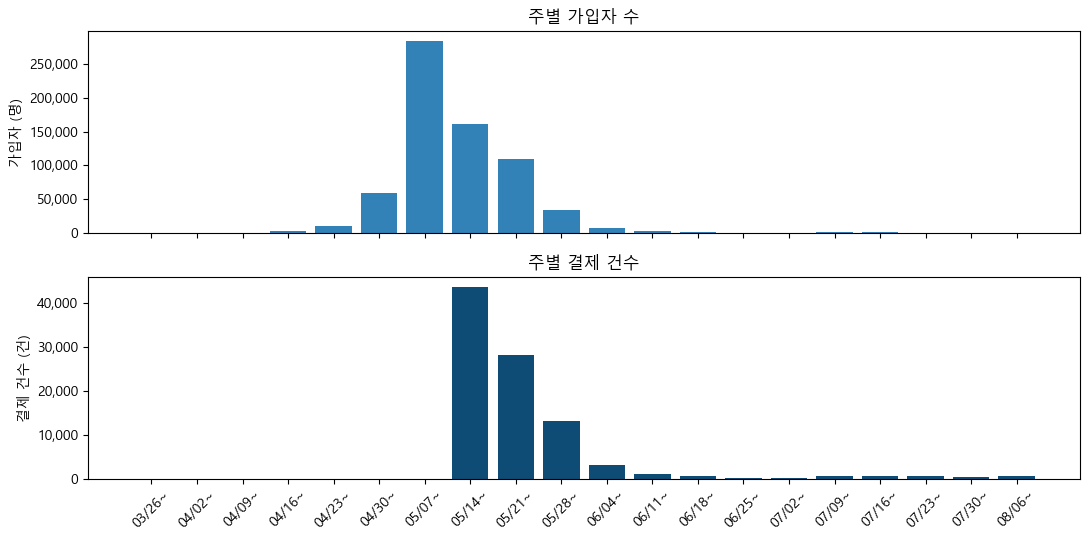

In [26]:
pay_week = week_start(pay.created_at)
wk = pd.DataFrame({'가입자': base.groupby('signup_week').size(),
                   '결제 건수': pay.groupby(pay_week).size(),
                   '결제자': pay.groupby(pay_week).user_id.nunique(),
                   '추정 매출(원)': pay.groupby(pay_week).price.sum()}).fillna(0).astype('int64')
wk.insert(0, '주 번호', week_no(wk.index))
wk.index = wk.index.strftime('%m/%d~')
wk.index.name = '주 시작일'
display(wk)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].bar(wk.index, wk['가입자'], color=C2); axes[0].set_ylabel('가입자 (명)'); axes[0].set_title('주별 가입자 수')
axes[1].bar(wk.index, wk['결제 건수'], color=C1); axes[1].set_ylabel('결제 건수 (건)'); axes[1].set_title('주별 결제 건수')
for ax in axes:
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

- 가입은 결제 시작 직전 주(05/07~)에 284,682명으로 가장 많았고, 결제가 시작된 0주 161,483명, 2주 33,728명, 4주 2,142명으로 빠르게 줄어듦
- 결제 건수도 0주 43,678건에서 4주 981건으로 줄었고, 7주(07/02~)에는 126건까지 내려감
- 8주(07/09~)부터 주 470~700건으로 다시 늘었지만 5월과는 차이가 큼. 마지막 주(08/06~)는 5일분임

### 1-2. 월별 가입자 수와 결제 건수, 결제 비중

,가입자,결제 건수,결제자,추정 매출(원),가입 비중(%),결제 건수 비중(%),추정 매출 비중(%)
월,,,,,,,
2023-03,11,0,0,0,0.0,0.0,0.0
2023-04,17958,0,0,0,2.7,0.0,0.0
2023-05,636059,81881,52499,174076900,94.5,88.1,88.4
2023-06,17293,8007,5798,16795300,2.6,8.6,8.5
2023-07,1852,2136,1647,4196400,0.3,2.3,2.1
2023-08,245,920,706,1839000,0.0,1.0,0.9
합계,673418,92944,58266,196907600,100.0,100.0,100.0


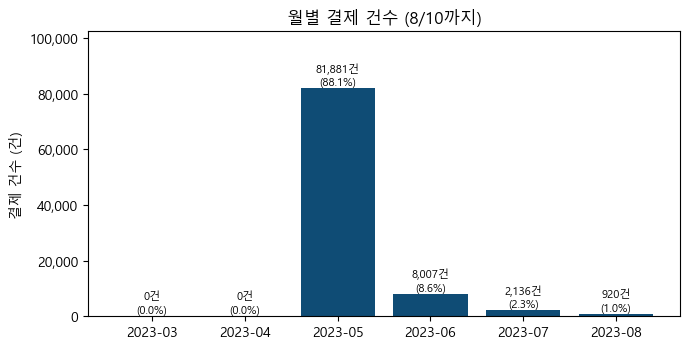

,결제 건수,추정 매출(원),건수 비중(%),추정 매출 비중(%)
첫 결제,58266,116463400,62.7,59.1
첫 결제 이후 결제,34678,80444200,37.3,40.9


In [27]:
signup_m = base.signup_at.dt.strftime('%Y-%m')
pay_m = pay.created_at.dt.strftime('%Y-%m')
month = pd.DataFrame({'가입자': signup_m.value_counts(),
                      '결제 건수': pay_m.value_counts(),
                      '결제자': pay.groupby(pay_m).user_id.nunique(),
                      '추정 매출(원)': pay.groupby(pay_m).price.sum()}).sort_index().fillna(0).astype('int64')
month.loc['합계'] = [len(base), len(pay), pay.user_id.nunique(), pay.price.sum()]
for col, name in [('가입자', '가입 비중(%)'), ('결제 건수', '결제 건수 비중(%)'), ('추정 매출(원)', '추정 매출 비중(%)')]:
    month[name] = (month[col] / month.loc['합계', col] * 100).round(1)
month.index.name = '월'
display(month)

m = month.drop('합계')
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(m.index, m['결제 건수'], color=C1)
for b, v, s in zip(bars, m['결제 건수'], m['결제 건수 비중(%)']):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}건\n({s}%)', ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, m['결제 건수'].max() * 1.25)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title('월별 결제 건수 (8/10까지)'); ax.set_ylabel('결제 건수 (건)')
plt.tight_layout(); plt.show()

# 추정 매출을 첫 결제와 첫 결제 이후 결제로 나눔
rev = pay.groupby(np.where(pay.seq == 1, '첫 결제', '첫 결제 이후 결제')).price.agg(['size', 'sum'])
rev.columns = ['결제 건수', '추정 매출(원)']
rev['건수 비중(%)'] = (rev['결제 건수'] / rev['결제 건수'].sum() * 100).round(1)
rev['추정 매출 비중(%)'] = (rev['추정 매출(원)'] / rev['추정 매출(원)'].sum() * 100).round(1)
rev

추정 매출(원),첫 결제,연속 결제 (10분 안),7일 안 재결제,첫 결제 7일 뒤 결제
월,,,,
2023-05,105003100,12084900,50948000,6040900
2023-06,8374200,798300,3072200,4550600
2023-07,2237700,306200,228100,1424400
2023-08,848400,136900,44500,809200


추정 매출 비중(%),첫 결제,연속 결제 (10분 안),7일 안 재결제,첫 결제 7일 뒤 결제,첫 결제 이후 결제 합계
월,,,,,
2023-05,60.3,6.9,29.3,3.5,39.7
2023-06,49.9,4.8,18.3,27.1,50.1
2023-07,53.3,7.3,5.4,33.9,46.7
2023-08,46.1,7.4,2.4,44.0,53.9


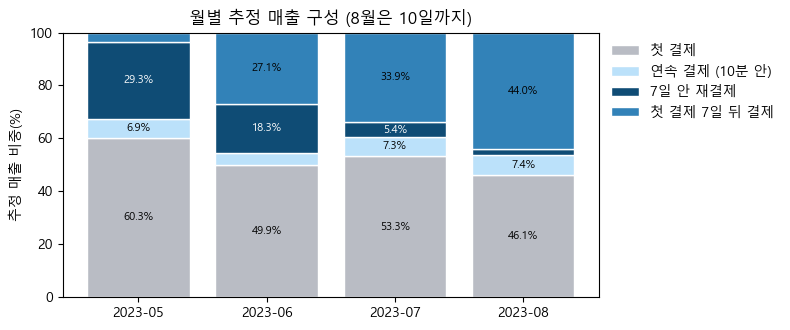

In [28]:
# 월별 추정 매출을 결제 종류로 나눔. 연속 결제와 7일 안 재결제는 0-2 용어와 같은 기준
REV_KINDS = ['첫 결제', '연속 결제 (10분 안)', '7일 안 재결제', '첫 결제 7일 뒤 결제']
kind_m = np.select([pay.seq == 1, pay.gap <= QUICK_GAP, pay.gap <= RE_WINDOW], REV_KINDS[:3], REV_KINDS[3])
rev_m = (pay.assign(월=pay_m, 구분=kind_m)
            .pivot_table(index='월', columns='구분', values='price', aggfunc='sum', fill_value=0)[REV_KINDS])
share_m = rev_m.div(rev_m.sum(axis=1), axis=0).mul(100)
share_m['첫 결제 이후 결제 합계'] = 100 - share_m['첫 결제']
display(rev_m.rename_axis(index='월', columns='추정 매출(원)'))
display(share_m.round(1).rename_axis(index='월', columns='추정 매출 비중(%)'))

REV_COLORS = [GRAY_BAR, C3, C1, C2]
fig, ax = plt.subplots(figsize=(8, 3.4))
bottom = np.zeros(len(share_m))
for kname, col in zip(REV_KINDS, REV_COLORS):
    v = share_m[kname].values
    ax.bar(share_m.index, v, bottom=bottom, color=col, label=kname, edgecolor='white', linewidth=1)
    for i, (b0, x) in enumerate(zip(bottom, v)):
        if x >= 5:
            ax.text(i, b0 + x / 2, f'{x:.1f}%', ha='center', va='center', fontsize=8, color='white' if col == C1 else 'black')
    bottom += v
ax.set_ylim(0, 100); ax.set_ylabel('추정 매출 비중(%)')
ax.set_title('월별 추정 매출 구성 (8월은 10일까지)')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

- 8/10까지 결제 92,944건 중 81,881건(88.1%)이 5월에 몰려 있음. 추정 매출도 5월 비중이 88.4%임
- 6월 8,007건(8.6%), 7월 2,136건(2.3%)으로 줄었고, 8월은 10일까지 920건임
- 가입도 94.5%가 5월이라 결제가 가입 몰림을 따라간 것으로 보임. 2장에서는 가입 감소와 별개로 첫 결제자 안에서 재결제가 끊기는 문제를 봄
- 결제 감소의 큰 원인은 신규 유입 감소지만, 이 데이터로는 유입 증가 방안을 제시하기 어려움. 그래서 이미 확보한 첫 결제자 5.8만 명의 재결제에 집중함. 첫 결제 이후 결제는 추정 매출의 약 40%를 차지함
- 월별로 보면 첫 결제 이후 결제의 매출 비중은 5월 39.7%, 6월 50.1%, 7월 46.7%, 8월(10일까지) 53.9%임. 새 첫 결제자가 줄면서 6월부터 매출의 절반 안팎이 이미 결제한 학생에게서 나옴
- 그 구성은 시기마다 다름. 5월에는 7일 안 재결제가 29.3%로 가장 컸지만, 7월에는 5.4%로 줄고 첫 결제 7일 뒤 결제가 33.9%(8월 44.0%)를 차지함. 6월 이후 이미 결제한 학생에게서 나온 매출은 대부분 첫 결제 7일 뒤에 다시 산 결제이고, 8주 이후 이 결제의 대부분은 5/14~6/17 첫 결제자의 복귀 구매임(부록 F-1)
- 연속 결제(10분 안)는 4.8~7.4%임. 첫 결제와 같은 방문에서 더 산 것이라 재결제에 넣지 않음(0-2)

---
## 2. 현상과 문제: 첫 결제 후 재결제 단절

- 현상: 첫 결제 후 7일 재결제율이 결제 시작 첫 주(5/14~) 20%에서 한 달 뒤(6/11~) 7%로 떨어졌고, 7/9~8/3에는 6%에 머묾 (2-2)
- 문제 정의: 같은 기간 새로 결제하는 학생도 주 30,035명에서 536명으로 줄어(2-2), 매출은 이미 결제한 학생의 재결제에 달려 있음(1-2 월별 매출 구성, 2-3). 그런데 7일 안에 다시 결제하지 않은 첫 결제자의 92%는 그 7일 동안 친구 요청, 출석 같은 활동을 이어 감(4-2). 앱을 떠나지 않고 남아 있지만 다시 결제로 이어지지 않고 있음
- 재결제율은 0장 기준(첫 결제 후 10분 초과 7일 이내 결제, 7일 관찰 대상만)으로 계산함

### 2-1. 결제 횟수와 재결제 없음 비율
- 결제 횟수는 8/10까지의 전체 결제를 셈
- 재결제 없음 비율은 기준에 따라 달라지므로 세 기준을 나란히 둠. 현상과 문제 정의의 재결제율은 마지막 줄(0장 기준)을 씀

In [29]:
n_pay = pay.groupby('user_id').size()
cnt = n_pay.clip(upper=5).value_counts().sort_index()
cnt.index = ['1회', '2회', '3회', '4회', '5회 이상']
cnt_tbl = pd.DataFrame({'결제자': cnt, '비율(%)': (cnt / cnt.sum() * 100).round(1)})
cnt_tbl.index.name = '결제 횟수 (8/10까지)'
display(cnt_tbl)

obs = buyer[buyer.obs7]
later_any = set(pay.loc[(pay.seq > 1) & (pay.gap > QUICK_GAP), 'user_id'])   # 10분이 지난 뒤 결제가 있는 유저 (기간 제한 없음)
no_re = pd.DataFrame([
    ['결제가 한 번뿐 (10분 안 연속 결제도 재결제로 셈)', '결제자 전체', len(n_pay), (n_pay == 1).mean() * 100],
    ['첫 결제 후 10분이 지난 결제가 8/10까지 없음', '7일 관찰 대상', len(obs), (~obs.user_id.isin(later_any)).mean() * 100],
    ['7일 재결제 없음 (0장 기준)', '7일 관찰 대상', len(obs), (~obs.re7).mean() * 100]],
    columns=['기준', '대상', '대상 인원', '재결제 없음 비율(%)']).round(1)
no_re

,결제자,비율(%)
결제 횟수 (8/10까지),,
1회,42682,73.3
2회,8284,14.2
3회,3312,5.7
4회,1607,2.8
5회 이상,2381,4.1


,기준,대상,대상 인원,재결제 없음 비율(%)
0,결제가 한 번뿐 (10분 안 연속 결제도 재결제로 셈),결제자 전체,58266,73.3
1,첫 결제 후 10분이 지난 결제가 8/10까지 없음,7일 관찰 대상,57871,78.1
2,7일 재결제 없음 (0장 기준),7일 관찰 대상,57871,81.2


- 결제자 58,266명 중 42,682명(73.3%)이 8/10까지 한 번만 결제함. 첫 결제 후 10분 안의 연속 결제를 재결제로 센 값임
- 연속 결제를 빼고 7일 관찰 대상으로 보면 81.2%가 7일 안에 다시 결제하지 않음
- 기간 제한 없이 8/10까지 봐도 78.1%가 첫 결제 후 10분이 지난 결제가 없음. 7일 기준(81.2%)과 큰 차이가 없어, 관찰 기간을 7일로 정해도 결론은 같음

### 2-2. 첫 결제 주별 7일 재결제율
- 대상: 7일 관찰 대상 (첫 결제가 8/3 이전). 11주(07/30~)는 7/30~8/3 첫 결제자만 들어 있음
- 1시간 경계는 0장의 민감도 확인용 재결제율이고, 연속 결제율은 첫 결제 후 10분 안에 결제가 있는 비율임
- 첫 결제자가 500명 미만인 주는 그래프에서 속이 빈 점으로 표시함

,첫 결제자,재결제자,7일 재결제율(%),"7일 재결제율, 1시간 경계(%)",연속 결제율(%)
0주 (05/14~),30035,6130,20.4,19.4,8.4
1주 (05/21~),16879,3492,20.7,19.6,8.2
2주 (05/28~),7207,1003,13.9,12.9,7.1
3주 (06/04~),1682,139,8.3,7.0,7.6
4주 (06/11~),536,38,7.1,6.5,5.6
5주 (06/18~),254,16,6.3,5.5,6.3
6주 (06/25~),110,4,3.6,3.6,8.2
7주 (07/02~),68,1,1.5,1.5,8.8
8주 (07/09~),422,36,8.5,6.9,10.4
9주 (07/16~),323,17,5.3,5.3,12.1


8~11주(07/09~08/03) 첫 결제자 1,100명 중 재결제 65명, 7일 재결제율 5.9%


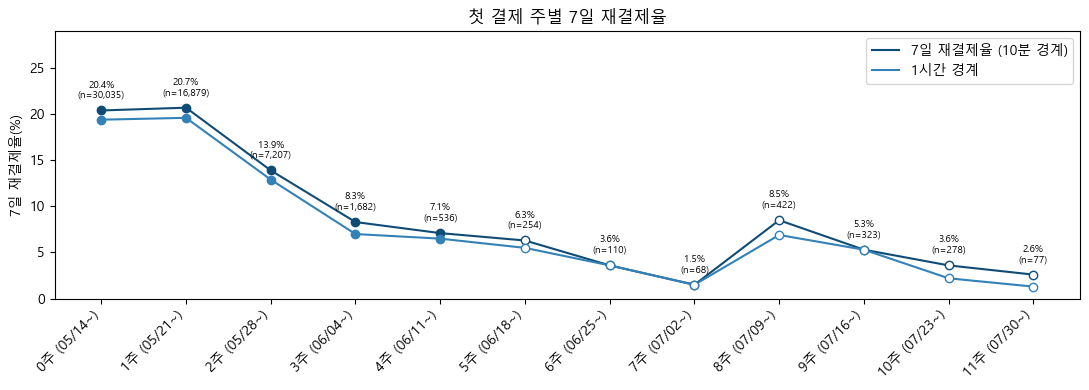

In [30]:
obs = buyer[buyer.obs7]
re_week = obs.groupby('first_week').agg(첫결제자=('user_id', 'size'), 재결제자=('re7', 'sum'),
                                        재결제율=('re7', 'mean'), 재결제율_1시간=('re7_1h', 'mean'), 연속결제율=('quick', 'mean'))
rate_cols = ['재결제율', '재결제율_1시간', '연속결제율']
re_week[rate_cols] = re_week[rate_cols].mul(100).round(1)
re_week.columns = ['첫 결제자', '재결제자', '7일 재결제율(%)', '7일 재결제율, 1시간 경계(%)', '연속 결제율(%)']
re_week.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in re_week.index]
display(re_week)
late = obs[obs.first_week.between(8, 11)]                          # 현상에 쓰는 값: 07/09~08/03 첫 결제자 전체
print(f'8~11주(07/09~08/03) 첫 결제자 {len(late):,}명 중 재결제 {int(late.re7.sum())}명, 7일 재결제율 {late.re7.mean():.1%}')

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(re_week)); small = re_week['첫 결제자'] < 500
for col, c, lab in [('7일 재결제율(%)', C1, '7일 재결제율 (10분 경계)'), ('7일 재결제율, 1시간 경계(%)', C2, '1시간 경계')]:
    ax.plot(x, re_week[col], color=c, label=lab)
    ax.scatter(x[~small], re_week[col][~small], color=c, zorder=3)
    ax.scatter(x[small], re_week[col][small], facecolor='white', edgecolor=c, zorder=3)
for i, (v, n) in enumerate(zip(re_week['7일 재결제율(%)'], re_week['첫 결제자'])):
    ax.annotate(f'{v:.1f}%\n(n={n:,})', (i, v), textcoords='offset points', xytext=(0, 9), ha='center', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(re_week.index, rotation=45, ha='right')
ax.set_ylim(0, re_week['7일 재결제율(%)'].max() * 1.4)
ax.set_title('첫 결제 주별 7일 재결제율'); ax.set_ylabel('7일 재결제율(%)')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

- 7일 재결제율은 0주 20.4%, 1주 20.7%에서 2주 13.9%, 3주 8.3%, 4주 7.1%로 떨어짐. 현상의 "20%에서 7%"는 이 0~4주 값임
- 같은 기간 첫 결제자도 0주 30,035명에서 4주 536명으로 줄었음. 문제 정의의 "주 30,035명에서 536명"은 이 값임
- 8~11주(07/09~08/03) 첫 결제자 1,100명 중 재결제는 65명으로 5.9%임. 현상의 "7/9~8/3에는 6%"는 이 값임
- 1시간 경계로 바꿔도 19.4%에서 6.5%로 흐름이 같음
- 연속 결제율은 0~4주 5.6~8.4%로 큰 변화가 없음. 첫 결제 때 같은 방문에서 더 사는 비율은 유지됐고, 다음 방문에서 다시 사는 비율이 줄었음
- 5주 이후는 첫 결제자가 주 68~422명이라 값이 크게 흔들림. 8주(07/09~) 8.5%는 이전 가입자의 첫 결제가 몰린 주(첫 결제자 422명 중 324명)의 값이고 재결제자가 36명뿐이라, 재결제 회복으로 보기 어려움(이 주의 결제는 부록 F에서 자세히 봄)

### 2-3. 재결제 여부별 첫 결제 후 7일 추정 매출
- 7일 관찰 대상 첫 결제자를 재결제한 사람과 하지 않은 사람으로 나눠, 첫 결제부터 7일 안의 추정 매출(첫 결제·연속 결제 포함)을 비교함
- 7일 추정 매출을 첫 결제, 연속 결제(10분 안), 7일 안 재결제로 나눠 차이가 어디서 나는지 봄
- 두 집단 모두 같은 7일로 셈. 8/10까지 누적하면 일찍 첫 결제한 사람이 쌓을 시간이 길어 차이가 부풀려짐
- 추정 매출 = 결제 건수 × 상품 판매가 (0-2 용어 참고)

,인원,1인당 7일 추정 매출 평균(원),1인당 중앙값(원),7일 추정 매출 합계(원),7일 추정 매출 비중(%)
재결제,,,,,
재결제함,10888,7558,4800,82287100,44.9
재결제 없음,46983,2147,1900,100855700,55.1


1인당 7일 추정 매출(원),첫 결제,연속 결제 (10분 안),7일 안 재결제,합계
재결제,,,,
재결제함,2091,484,4983,7558
재결제 없음,1978,169,0,2147


재결제한 사람의 1인당 재결제 매출 4,983원 = 자기 첫 결제(2,091원)의 2.4배
참고: 1인당 7일 추정 매출 평균의 비 3.5배 (재결제가 정의상 한 번 더 있어 생기는 차이를 포함)
재결제하지 않은 사람 중 7일 추정 매출이 1,900원(heart.777 한 번)뿐인 사람: 90.4%


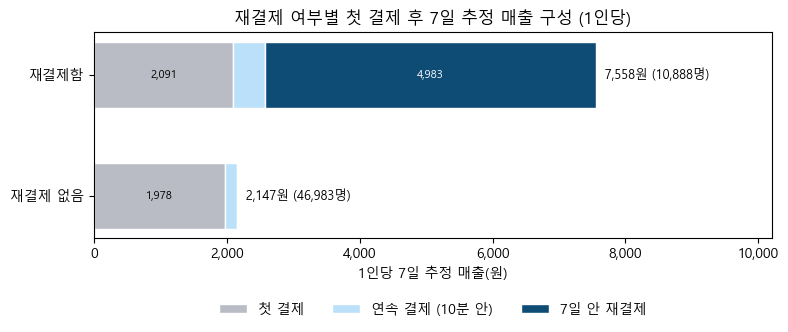

In [31]:
rev7 = pay[pay.gap <= RE_WINDOW].groupby('user_id').price.sum()       # 첫 결제부터 7일 안의 추정 매출
buyer7 = buyer[buyer.obs7].copy()
buyer7['rev7'] = buyer7.user_id.map(rev7)
buyer7['재결제'] = np.where(buyer7.re7, '재결제함', '재결제 없음')
GRP_RE = ['재결제함', '재결제 없음']
rev7_tbl = (buyer7.groupby('재결제').agg(인원=('user_id', 'size'), 평균=('rev7', 'mean'), 중앙값=('rev7', 'median'), 합계=('rev7', 'sum'))
               .reindex(GRP_RE))
rev7_tbl['비중'] = rev7_tbl['합계'] / rev7_tbl['합계'].sum() * 100
rev7_tbl.columns = ['인원', '1인당 7일 추정 매출 평균(원)', '1인당 중앙값(원)', '7일 추정 매출 합계(원)', '7일 추정 매출 비중(%)']
display(rev7_tbl.round({'1인당 7일 추정 매출 평균(원)': 0, '7일 추정 매출 비중(%)': 1})
                .astype({'1인당 7일 추정 매출 평균(원)': int, '1인당 중앙값(원)': int}))

# 1인당 7일 추정 매출을 결제 종류로 나눔
PARTS7 = ['첫 결제', '연속 결제 (10분 안)', '7일 안 재결제']
pay7d = pay[(pay.gap <= RE_WINDOW) & pay.user_id.isin(buyer7.user_id)]
pay7d = pay7d.assign(구분=np.select([pay7d.seq == 1, pay7d.gap <= QUICK_GAP], PARTS7[:2], PARTS7[2]),
                     재결제=pay7d.user_id.map(buyer7.set_index('user_id')['재결제']))
comp7 = pay7d.pivot_table(index='재결제', columns='구분', values='price', aggfunc='sum', fill_value=0).reindex(index=GRP_RE, columns=PARTS7, fill_value=0)
comp7 = comp7.div(rev7_tbl['인원'], axis=0)
comp7['합계'] = comp7.sum(axis=1)
display(comp7.round(0).astype(int).rename_axis(index='재결제', columns='1인당 7일 추정 매출(원)'))
print(f"재결제한 사람의 1인당 재결제 매출 {comp7.loc['재결제함', '7일 안 재결제']:,.0f}원 = 자기 첫 결제({comp7.loc['재결제함', '첫 결제']:,.0f}원)의 "
      f"{comp7.loc['재결제함', '7일 안 재결제'] / comp7.loc['재결제함', '첫 결제']:.1f}배")
print(f"참고: 1인당 7일 추정 매출 평균의 비 {rev7_tbl.iloc[0, 1] / rev7_tbl.iloc[1, 1]:.1f}배 (재결제가 정의상 한 번 더 있어 생기는 차이를 포함)")
no = buyer7[~buyer7.re7]
print(f'재결제하지 않은 사람 중 7일 추정 매출이 1,900원(heart.777 한 번)뿐인 사람: {(no.rev7 == PRICE["heart.777"]).mean():.1%}')

fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(comp7))
for pname, col in zip(PARTS7, [GRAY_BAR, C3, C1]):
    v = comp7[pname].values
    ax.barh(comp7.index, v, left=left, color=col, label=pname, height=0.55, edgecolor='white', linewidth=1)
    for i, (l0, x) in enumerate(zip(left, v)):
        if x >= 900:                                                  # 좁은 칸에는 숫자를 쓰지 않음
            ax.text(l0 + x / 2, i, f'{x:,.0f}', ha='center', va='center', fontsize=8, color='white' if col == C1 else 'black')
    left += v
for i, (t, n) in enumerate(zip(comp7['합계'], rev7_tbl['인원'])):
    ax.text(t, i, f'  {t:,.0f}원 ({n:,}명)', va='center', fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, comp7['합계'].max() * 1.35)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_xlabel('1인당 7일 추정 매출(원)'); ax.set_title('재결제 여부별 첫 결제 후 7일 추정 매출 구성 (1인당)')
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=3)
plt.tight_layout(); plt.show()

- 재결제한 10,888명의 1인당 7일 추정 매출은 7,558원, 재결제하지 않은 46,983명은 2,147원임. 재결제한 사람은 정의상 결제가 한 번 더 있으므로 이 차이(3.5배)는 당연히 생기는 값이고, 차이가 어디서 나는지를 봐야 함
- 1인당 7일 추정 매출을 나누면, 첫 결제는 두 집단이 2,091원과 1,978원으로 비슷함. 차이는 거의 재결제에서 나옴. 재결제한 사람은 7일 안 재결제로 1인당 4,983원을 더 썼고, 이는 자기 첫 결제의 2.4배임. 연속 결제도 484원 대 169원으로 재결제한 사람이 많음
- 재결제한 18.8%가 7일 추정 매출의 44.9%를 냄
- 재결제하지 않은 사람의 90.4%는 7일 추정 매출이 1,900원, 즉 특가 heart.777 한 번뿐임. 첫 결제의 94.1%가 1인 1회로 보이는 특가라(부록 B-2), 재결제가 없으면 한 사람에게서 나오는 매출이 거의 1,900원에서 멈춤
- 1-2의 월별 매출 구성과 함께, 문제 정의의 "매출은 이미 결제한 학생의 재결제에 달려 있음"의 근거임

---
## 3. 재결제까지의 퍼널과 병목

첫 결제자가 앱을 다시 켜고 상점에 다시 들어와 재결제하기까지의 단계를 핵클 로그로 봄. 핵클 로그가 있는 기간만 볼 수 있음.

| 항목 | 기준 |
|---|---|
| 기간 | 핵클 기간 2023-07-18 ~ 08-10 |
| 대상 (3-1~3-2, 부록 E-1~E-3) | 핵클 기간에 첫 결제한 7일 관찰 대상(첫 결제 7/18 0시 ~ 8/3) 중 핵클 이벤트에 연결된 유저. 3-3·3-4는 결제 경험자 전체로 넓힘 |
| 유저 연결 | `hackle_events.session_id` → `hackle_properties`에서 숫자 `user_id`가 정확히 1개인 세션만 사용 |
| 관찰 구간 | 첫 결제 후 10분 초과 ~ 7일. 첫 결제와 같은 방문 안의 행동(연속 결제)은 뺌 |
| 제외 이벤트 | `button`, `click_appbar_setting` |
| 결제 시각 | `accounts_paymenthistory.created_at`. 핵클 `complete_purchase`는 결제 기록보다 0~60초 먼저 찍혀 쓰지 않음 |

- 3-1~3-2와 부록 E-1~E-3은 대상이 수백 명이라 결과를 방향을 보는 참고용으로 씀. 결제가 크게 줄어든 7~8월의 첫 결제자라 5월 첫 결제자와 다를 수 있음
- 숫자 `user_id`가 없는 세션은 유저에 연결되지 않으므로, 앱 재실행과 상점 진입이 실제보다 적게 잡힐 수 있음 (연결 비율은 3-1에서 출력)

### 3-1. 핵클 데이터 불러오기

In [32]:
fetch_csv(['hackle_properties', 'hackle_events'])

hk_buyer = buyer[(buyer.first_at >= HK_START) & buyer.obs7][['user_id', 'first_at', 're7', 'quick']].copy()

# session_id → 숫자 user_id 연결표
hp = read_cols('hackle_properties', ['session_id', 'user_id'], dtype=str)
num = hp[hp.user_id.fillna('').str.fullmatch(r'\d+')].drop_duplicates()
n_id = num.groupby('session_id').user_id.nunique()
sess2user = (num[num.session_id.isin(n_id[n_id == 1].index)]
             .drop_duplicates('session_id').set_index('session_id').user_id.astype('int64'))
print(f'핵클 세션 {hp.session_id.nunique():,}개 중 유저에 연결된 세션 {len(sess2user):,}개 ({len(sess2user) / hp.session_id.nunique():.1%})')
del hp, num

# hackle_events는 커서 나눠 읽으면서 대상 유저의 이벤트만 남김
parts = []
reader = read_cols('hackle_events', ['event_datetime', 'event_key', 'session_id', 'item_name', 'heart_balance'],
                   parse_dates=['event_datetime'], chunksize=2_000_000)
for ch in reader:
    ch['user_id'] = ch.session_id.map(sess2user)
    parts.append(ch[ch.user_id.isin(hk_buyer.user_id) & ~ch.event_key.isin(['button', 'click_appbar_setting'])])
hev = pd.concat(parts, ignore_index=True)
del parts
hev['user_id'] = hev.user_id.astype('int64')
hev = hev.merge(hk_buyer[['user_id', 'first_at']], on='user_id')
hev['t'] = hev.event_datetime - hev.first_at                        # 첫 결제 후 지난 시간
hev = hev.sort_values(['user_id', 'event_datetime']).reset_index(drop=True)

target = hk_buyer[hk_buyer.user_id.isin(hev.user_id)].copy()
print(f'핵클 기간 첫 결제자(7일 관찰 대상): {len(hk_buyer):,}명 / 핵클 이벤트에 연결된 유저: {len(target):,}명')
print(f'연결된 유저의 7일 재결제율 {target.re7.mean():.1%} (전체 7일 관찰 대상 {buyer.loc[buyer.obs7, "re7"].mean():.1%})')

  hackle_properties.csv: 61.4 MB
  hackle_events.csv: 1,850.7 MB


핵클 세션 253,616개 중 유저에 연결된 세션 233,539개 (92.1%)


핵클 기간 첫 결제자(7일 관찰 대상): 627명 / 핵클 이벤트에 연결된 유저: 626명
연결된 유저의 7일 재결제율 4.2% (전체 7일 관찰 대상 18.8%)


- 핵클 기간(7/18~8/3)의 첫 결제자는 627명이고, 그중 626명이 핵클 이벤트에 연결됨. 핵클 세션 전체로는 92.1%가 유저에 연결됨
- 이 유저들의 7일 재결제율은 4.2%로 전체 7일 관찰 대상(18.8%)보다 훨씬 낮음. 2-2의 9~11주 값(2.6~5.3%)과 같은 수준으로, 재결제가 이미 끊긴 시기의 첫 결제자임
- 재결제자가 26명뿐이라 3-2와 부록 E-1~E-3의 비율은 몇 명 차이로도 크게 바뀜

### 3-2. 첫 결제 후 재결제까지의 퍼널
- 단계: 첫 결제 → 앱 다시 실행(`launch_app`, `$session_start`) → 상점 재방문(`view_shop`) → 유료 상품 클릭(`click_purchase` 중 상품 이름에 '하트'가 있는 것, 무료충전소 제외) → 재결제
- 순서 지킴: 앞 단계가 처음 일어난 시각 뒤에 다음 단계가 있어야 다음 단계로 셈
- 순서 무시: 관찰 구간 안에 그 행동이 한 번이라도 있으면 셈 (참고)

,유저(순서 지킴),유저(순서 무시),이전 단계 대비(%),첫 결제자 대비(%)
단계,,,,
첫 결제,626,626,NaN,100.0
앱 다시 실행,455,455,72.7,72.7
상점 재방문,100,106,22.0,16.0
유료 상품 클릭,32,36,32.0,5.1
재결제,23,26,71.9,3.7


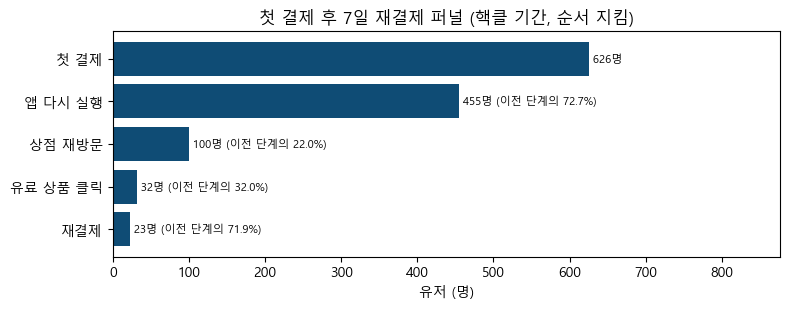

In [33]:
win = hev[(hev.t > QUICK_GAP) & (hev.t <= RE_WINDOW)]
re_pay = pay[pay.user_id.isin(target.user_id) & (pay.seq > 1) & (pay.gap > QUICK_GAP) & (pay.gap <= RE_WINDOW)]
STEPS = {
    '앱 다시 실행': win[win.event_key.isin(['launch_app', '$session_start'])][['user_id', 'event_datetime']],
    '상점 재방문': win[win.event_key == 'view_shop'][['user_id', 'event_datetime']],
    '유료 상품 클릭': win[(win.event_key == 'click_purchase') & win.item_name.fillna('').str.contains('하트')][['user_id', 'event_datetime']],
    '재결제': re_pay[['user_id', 'created_at']].rename(columns={'created_at': 'event_datetime'}),
}

prev = (target.set_index('user_id').first_at + QUICK_GAP).rename('prev')    # 출발 시각 = 첫 결제 후 10분
rows = [{'단계': '첫 결제', '유저(순서 지킴)': len(target), '유저(순서 무시)': len(target)}]
for name, ev_s in STEPS.items():
    d = ev_s.merge(prev, left_on='user_id', right_index=True)
    prev = d[d.event_datetime >= d.prev].groupby('user_id').event_datetime.min().rename('prev')
    rows.append({'단계': name, '유저(순서 지킴)': len(prev), '유저(순서 무시)': ev_s.user_id.nunique()})
funnel = pd.DataFrame(rows).set_index('단계')
funnel['이전 단계 대비(%)'] = (funnel['유저(순서 지킴)'] / funnel['유저(순서 지킴)'].shift() * 100).round(1)
funnel['첫 결제자 대비(%)'] = (funnel['유저(순서 지킴)'] / len(target) * 100).round(1)
display(funnel)

fig, ax = plt.subplots(figsize=(8, 3.2))
f = funnel.iloc[::-1]
ax.barh(f.index, f['유저(순서 지킴)'], color=C1)
for i, (n, r) in enumerate(zip(f['유저(순서 지킴)'], f['이전 단계 대비(%)'])):
    ax.text(n, i, f' {n:,}명' + (f' (이전 단계의 {r:.1f}%)' if pd.notna(r) else ''), va='center', fontsize=8)
ax.set_xlim(0, len(target) * 1.4)
ax.set_title('첫 결제 후 7일 재결제 퍼널 (핵클 기간, 순서 지킴)'); ax.set_xlabel('유저 (명)')
plt.tight_layout(); plt.show()

- 첫 결제자의 72.7%(455명)가 첫 결제 10분 뒤부터 7일 안에 앱을 다시 켰음
- 앱을 다시 켠 유저 중 상점에 다시 들어간 유저는 22.0%(100명)뿐이고, 첫 결제자 기준으로는 16.0%임. 이탈이 가장 큰 단계임
- 상점에 다시 들어간 뒤 유료 상품을 누른 비율은 32.0%, 누른 뒤 실제로 결제한 비율은 71.9%임
- 앱 이용은 이어지는데 상점까지 가지 않는 것이 병목으로 보임. 첫 결제로 산 하트가 남아 있어 상점에 갈 일이 없는지, 하트를 쓸 곳을 찾지 못하는지는 하트 사용 기록으로 확인해야 함(정리의 다음 분석 참고)

### 3-3. 앱을 다시 켜도 상점에 안 가는 이유: 결제 경험자의 방문 만들기

3-2에서 이탈이 가장 큰 단계는 앱 재실행 → 상점 재방문이었음. 부록 E-1·E-2는 상점에 들어간 경우만 봐서 "무엇이 있으면 상점에 가는가"를 알 수 없었음. 3-3·3-4는 상점에 간 방문과 안 간 방문을 함께 놓고 비교함. 어떤 행동 뒤에 상점에 가는지, 상점 안에서 무엇을 누르는지는 6-1·6-2에서 5장 세그먼트별로 봄.

| 항목 | 기준 |
|---|---|
| 대상 | 핵클 기간(7/18~8/10)에 앱을 쓴 결제 경험자 전체. 3-1~3-2의 핵클 기간 첫 결제자(626명)보다 넓힘 |
| 방문 | 같은 유저의 핵클 이벤트를 시간순으로 놓고, 이벤트 사이가 30분 넘게 비면 새 방문으로 나눔. 핵클 `session_id`는 앱 실행 한 번이 아니라 유저(기기) 단위에 가까워 쓰지 않음 |
| 결제 경험자의 방문 | 방문 시작이 그 유저의 첫 결제 후 10분이 지난 방문 |
| 상점 진입 | 방문 안에 `view_shop` 이벤트가 있음 |
| 방문 중 결제 | 결제 기록이 방문 시작부터 방문 마지막 이벤트 2분 뒤 사이에 있음 |
| 하트 잔액 | 방문의 첫 이벤트 중 `heart_balance`가 찍힌 값. 결제 직후에는 늦게 찍히지만, 방문 시작 시점이라 영향이 작음 |

In [34]:
VISIT_GAP = pd.Timedelta(minutes=30)                     # 이벤트 사이가 이만큼 비면 새 방문
payer_first = buyer.set_index('user_id').first_at

parts = []
for ch in read_cols('hackle_events', ['event_datetime', 'event_key', 'session_id', 'item_name', 'heart_balance'],
                    parse_dates=['event_datetime'], chunksize=2_000_000):
    ch['user_id'] = ch.session_id.map(sess2user)                    # 3-1에서 만든 세션 → 유저 연결표
    keep = ch.user_id.isin(payer_first.index) & ~ch.event_key.isin(['button', 'click_appbar_setting'])
    parts.append(ch[keep].drop(columns='session_id'))
ev5 = pd.concat(parts, ignore_index=True)
del parts
ev5['user_id'] = ev5.user_id.astype('int64')
ev5 = ev5.sort_values(['user_id', 'event_datetime']).reset_index(drop=True)

gap5 = ev5.groupby('user_id').event_datetime.diff()
ev5['visit'] = (gap5.isna() | (gap5 > VISIT_GAP)).cumsum()          # 방문 번호
vis = ev5.groupby('visit').agg(user_id=('user_id', 'first'), start=('event_datetime', 'min'), end=('event_datetime', 'max'))
vis = vis[vis.start >= vis.user_id.map(payer_first) + QUICK_GAP]     # 첫 결제 후 10분이 지난 방문만
ev5 = ev5[ev5.visit.isin(vis.index)]

shop_at = ev5[ev5.event_key == 'view_shop'].groupby('visit').event_datetime.min()
vis['shop'] = vis.index.isin(shop_at.index)
vis['heart'] = ev5.dropna(subset=['heart_balance']).groupby('visit').heart_balance.first()

pv = vis.reset_index()[['visit', 'user_id', 'start', 'end']].merge(
    pay[pay.created_at >= HK_START][['user_id', 'created_at']], on='user_id')
paid_visits = pv[(pv.created_at >= pv.start) & (pv.created_at <= pv.end + pd.Timedelta(minutes=2))].visit.unique()
vis['paid'] = vis.index.isin(paid_visits)

print(f'결제 경험자 {vis.user_id.nunique():,}명의 방문 {len(vis):,}회')
print(f'상점에 들어간 방문 {vis.shop.mean():.2%} / 방문 중 결제 {vis.paid.mean():.2%} / 상점에 들어간 방문 중 결제 {vis[vis.shop].paid.mean():.1%}')

결제 경험자 25,786명의 방문 105,674회
상점에 들어간 방문 3.61% / 방문 중 결제 0.66% / 상점에 들어간 방문 중 결제 18.3%


- 핵클 기간 결제 경험자 25,786명의 방문 105,674회 중 상점에 들어간 방문은 3.61%, 방문 중 결제는 0.66%임
- 상점에 들어간 방문의 18.3%가 결제로 이어짐. 결제는 상점에 들어간 방문에서 일어나므로 상점까지 오는 단계가 병목임. 다만 결제하려는 사람이 상점에 들어가는 것이기도 해서, 상점 진입을 늘린 만큼 결제가 늘어난다고 볼 수는 없음

### 3-4. 하트가 남아 있으면 상점에 안 가나
- 방문 시작 때 하트 잔액 구간별로 상점에 들어간 방문의 비율과 방문 중 결제 비율을 봄
- 받은 질문을 연 방문과 열지 않은 방문으로 다시 나눔. 앱 화면 설계상 받은 질문의 힌트를 열 때 잔액이 모자라면 상점으로 이어짐

,방문,상점 진입(%),방문 중 결제(%),방문 비중(%)
방문 시작 때 하트 잔액,,,,
0~99,7439,6.72,1.83,7.2
100~199,9336,6.22,1.51,9.1
200~299,7273,5.18,1.13,7.1
300~499,12931,5.18,1.08,12.6
500~999,18585,4.24,0.69,18.1
1000~1999,16736,3.04,0.38,16.3
2000 이상,30582,1.27,0.02,29.7


하트 잔액이 찍히지 않은 방문: 2792


,받은 질문 안 엶: 상점 진입(%),받은 질문 엶: 상점 진입(%),받은 질문 엶: 방문
방문 시작 때 하트 잔액,,,
0~99,3.55,14.71,2114
100~199,2.89,14.30,2727
200~299,2.74,11.38,2056
300~499,2.82,10.77,3845
500~999,2.20,9.80,4978
1000~1999,1.34,7.65,4499
2000 이상,0.57,3.80,6548


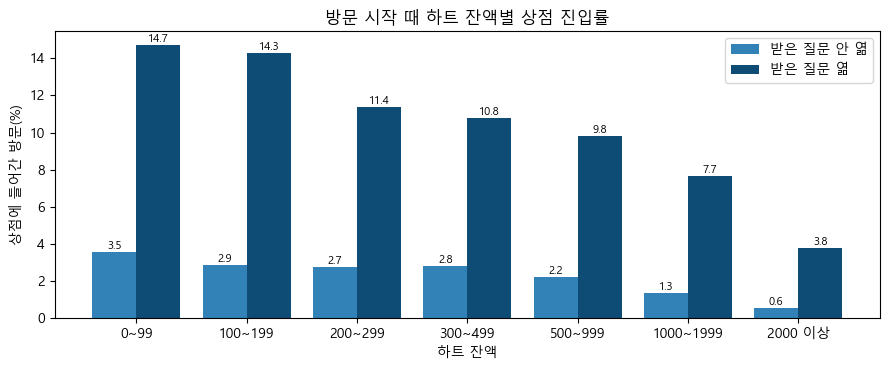

In [35]:
HEART_LABELS = ['0~99', '100~199', '200~299', '300~499', '500~999', '1000~1999', '2000 이상']
vis['heart_bin'] = pd.cut(vis.heart, [-1, 99, 199, 299, 499, 999, 1999, np.inf], labels=HEART_LABELS)
heart_tbl = vis.groupby('heart_bin', observed=False).agg(방문=('shop', 'size'), 상점_진입=('shop', 'mean'), 방문_중_결제=('paid', 'mean'))
heart_tbl[['상점_진입', '방문_중_결제']] = heart_tbl[['상점_진입', '방문_중_결제']].mul(100).round(2)
heart_tbl['방문 비중(%)'] = (heart_tbl['방문'] / heart_tbl['방문'].sum() * 100).round(1)
heart_tbl.columns = ['방문', '상점 진입(%)', '방문 중 결제(%)', '방문 비중(%)']
display(heart_tbl.rename_axis('방문 시작 때 하트 잔액'))
print('하트 잔액이 찍히지 않은 방문:', int(vis.heart.isna().sum()))

vis['q_open'] = vis.index.isin(ev5[ev5.event_key == 'click_question_open'].visit)
cross = vis.pivot_table(index='heart_bin', columns='q_open', values='shop', aggfunc='mean', observed=False).mul(100).round(2)
cross.columns = ['받은 질문 안 엶: 상점 진입(%)', '받은 질문 엶: 상점 진입(%)']
cross_n = vis.pivot_table(index='heart_bin', columns='q_open', values='shop', aggfunc='size', observed=False)
cross['받은 질문 엶: 방문'] = cross_n[True]
display(cross.rename_axis('방문 시작 때 하트 잔액'))

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(HEART_LABELS)); w = 0.4
for i, (col, c) in enumerate(zip(cross.columns[:2], [C2, C1])):
    bars = ax.bar(x + (i - 0.5) * w, cross[col], w, color=c, label=col.split(':')[0])
    for b_, v in zip(bars, cross[col]):
        ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(HEART_LABELS)
ax.set_title('방문 시작 때 하트 잔액별 상점 진입률'); ax.set_xlabel('하트 잔액'); ax.set_ylabel('상점에 들어간 방문(%)')
ax.legend()
plt.tight_layout(); plt.show()

- 방문 시작 때 하트 잔액이 많을수록 상점에 덜 들어감. 0~99 6.72%, 1000~1999 3.04%, 2000 이상 1.27%이고, 방문 중 결제도 1.83%에서 0.02%로 줄어듦
- 결제 경험자 방문의 29.7%가 잔액 2,000 이상에서 시작함. 이 방문들은 상점 진입이 1.27%뿐임
- 받은 질문을 연 방문은 잔액이 적을수록 상점 진입이 크게 높음(0~99 14.71%, 2000 이상 3.80%). 받은 질문을 열지 않은 방문은 잔액과 상관없이 0.57~3.55%로 낮음
- 받은 질문을 열어 보다가 하트가 모자랄 때 상점으로 가는 흐름임. 앱을 다시 켜도 상점에 안 가는 이유는 하트가 남아 있어 갈 일이 없기 때문으로 보임
- `heart_balance`가 결제로 산 하트만인지, 무료로 받은 하트까지 포함하는지는 확인하지 못함

---
## 4. 첫 결제자를 재결제·활동 기준으로 나눈 세 그룹

재결제 방안을 그룹별로 세우기 위해 7일 관찰 대상 첫 결제자를 세 그룹으로 나눔. 재결제 여부(0장 기준)와 첫 결제 후 7일 동안의 활동 기록으로 나누고, 그룹마다 어떤 사람들인지 비교함.

| 그룹 | 정의 (모두 첫 결제 후 7일 기준) | 방안에서 맡는 역할 |
|---|---|---|
| 재결제 유저 | 재결제 있음 | 비교 기준 |
| 재결제 병목 유저 | 재결제 없음, 친구 요청·출석·투표 데이터·핵클 중 하나라도 기록 있음 | 전환 대상 |
| 이탈 유저 | 재결제 없음, 네 가지 기록이 모두 없음 | 복귀 대상 |

| 활동 기록 | 7일 안에 있었는지 보는 기준 | 기록이 있는 기간·대상 |
|---|---|---|
| 친구 요청 | 보낸 요청이나 받은 요청이 만들어진 시각이 첫 결제 시각부터 7일 안 | 전체 기간, 전체 유저 |
| 출석 | 출석 날짜가 첫 결제일부터 7일 안 (날짜 단위) | 2023-05-27부터 |
| 투표 데이터 | 투표(`accounts_userquestionrecord`), 질문 세트(`polls_questionset`), 포인트 기록(`accounts_pointhistory`) 중 하나라도 첫 결제 시각부터 7일 안에 있음 | 투표를 시작한 유저 약 5천 명만 |
| 핵클 | 첫 결제 시각 뒤 7일 안의 이벤트. `complete_purchase`, `$session_end`, `button`, `click_appbar_setting`은 제외 | 2023-07-18부터 |

- 전체 유저의 활동을 볼 수 있는 기록은 친구 요청뿐임. 나머지 셋은 기간이나 대상이 좁아 보조로 씀
- 시기마다 볼 수 있는 기록이 다름. 0주(5/14~5/20) 첫 결제자는 출석·핵클 기록이 없던 때라 친구 요청과 투표 데이터만으로 그룹이 정해짐. 그래서 이탈 유저는 활동이 없던 사람이 아니라 기록이 남지 않은 사람임
- 받은 친구 요청은 다른 사람이 보낸 것이라 본인 활동의 근거로는 약함. 받은 요청만 있는 사람을 활동 없음으로 본 결과는 부록 G-2에서 함께 봄
- 유저 연결은 3-1의 `sess2user`를 씀. 같은 반 친구 활동별 그룹 구성은 부록 G-1에서 봄

### 4-1. 첫 결제 후 7일 동안의 활동 기록 모으기

In [36]:
import json
fetch_csv(['accounts_userquestionrecord', 'polls_questionset', 'accounts_pointhistory', 'accounts_attendance'])

g7 = rb[['user_id', 'first_at', 'signup_at', 're7', 'quick', 'period', 'gender_k', 'school_grade', 'region',
         'first_product', 'first_week_g']].copy()
t0 = g7.set_index('user_id').first_at                                  # 첫 결제 시각
uset = set(g7.user_id)

def in_window(df, tcol):
    # 첫 결제 시각부터 7일 안의 기록만 남김 (df에 user_id 컬럼이 있어야 함)
    t = df.user_id.map(t0)
    return df[(df[tcol] >= t) & (df[tcol] < t + RE_WINDOW)]

# 친구 요청: 보낸 요청, 받은 요청, 받은 요청을 수락한 시각(부록 G-2 확인용). 나눠 읽으면서 첫 결제자의 요청만 남김
parts = []
for ch in read_cols('accounts_friendrequest', ['send_user_id', 'receive_user_id', 'status', 'created_at', 'updated_at'],
                    parse_dates=['created_at', 'updated_at'], chunksize=2_000_000):
    s = ch[ch.send_user_id.isin(uset)]
    r = ch[ch.receive_user_id.isin(uset)]
    a = r[r.status == 'A']
    parts += [pd.DataFrame({'user_id': s.send_user_id, 'kind': 'sent', 't': s.created_at}),
              pd.DataFrame({'user_id': r.receive_user_id, 'kind': 'recv', 't': r.created_at}),
              pd.DataFrame({'user_id': a.receive_user_id, 'kind': 'acc', 't': a.updated_at})]
fr7 = in_window(pd.concat(parts, ignore_index=True), 't')
del parts
cnt = fr7.groupby(['user_id', 'kind']).size().unstack(fill_value=0)
for k in ['sent', 'recv', 'acc']:
    g7[f'fr_{k}'] = g7.user_id.map(cnt[k]).fillna(0).astype(int)

# 출석: 첫 결제일부터 7일 안의 출석 날짜 수
att7 = read_cols('accounts_attendance', ['attendance_date_list', 'user_id'])
att7 = att7[att7.user_id.isin(uset)]
att7 = att7.assign(day=att7.attendance_date_list.apply(lambda s: json.loads(s) if isinstance(s, str) else [])).explode('day')
att7 = att7.dropna(subset=['day'])
att7['day'] = pd.to_datetime(att7.day)
d0 = att7.user_id.map(t0).dt.normalize()
att7 = att7[(att7.day >= d0) & (att7.day < d0 + RE_WINDOW)]
g7['att_days'] = g7.user_id.map(att7.groupby('user_id').size()).fillna(0).astype(int)

# 투표 데이터: 투표, 질문 세트, 포인트 기록
vparts = []
for name in ['accounts_userquestionrecord', 'polls_questionset', 'accounts_pointhistory']:
    v = read_cols(name, ['user_id', 'created_at'], parse_dates=['created_at'])
    vparts.append(in_window(v[v.user_id.isin(uset)], 'created_at'))
vote7 = pd.concat(vparts, ignore_index=True)
del vparts, v
g7['n_vote'] = g7.user_id.map(vote7.groupby('user_id').size()).fillna(0).astype(int)

# 핵클: 첫 결제 시각 뒤 7일 안의 이벤트, 그리고 핵클 기간 전체에서 앱을 쓴 적이 있는지
HK_DROP = ['button', 'click_appbar_setting', '$session_end', 'complete_purchase']
parts, hk_any = [], set()
for ch in read_cols('hackle_events', ['event_datetime', 'event_key', 'session_id'], parse_dates=['event_datetime'], chunksize=2_000_000):
    ch['user_id'] = ch.session_id.map(sess2user)
    ch = ch[ch.user_id.isin(uset) & ~ch.event_key.isin(HK_DROP)]
    hk_any |= set(ch.user_id.astype('int64'))
    parts.append(ch[['user_id', 'event_datetime', 'event_key']])
hk7 = pd.concat(parts, ignore_index=True)
del parts
hk7['user_id'] = hk7.user_id.astype('int64')
t = hk7.user_id.map(t0)
hk7 = hk7[(hk7.event_datetime > t) & (hk7.event_datetime < t + RE_WINDOW)]
hk7['day'] = hk7.event_datetime.dt.normalize()
g7['hk_days'] = g7.user_id.map(hk7.groupby('user_id').day.nunique()).fillna(0).astype(int)
g7['hk_qopen'] = g7.user_id.map(hk7[hk7.event_key == 'click_question_open'].groupby('user_id').size()).fillna(0).astype(int)
g7['hk_shop'] = g7.user_id.map(hk7[hk7.event_key == 'view_shop'].groupby('user_id').size()).fillna(0).astype(int)
g7['hk_period'] = g7.user_id.isin(hk_any)                              # 핵클 기간(7/18~8/10) 어느 때든 앱 기록 있음

# 그룹 나누기
g7['fr7'] = (g7.fr_sent + g7.fr_recv) > 0
g7['att7'] = g7.att_days > 0
g7['vote7'] = g7.n_vote > 0
g7['hk7'] = g7.hk_days > 0
g7['act7'] = g7.fr7 | g7.att7 | g7.vote7 | g7.hk7
GROUPS7 = ['재결제 유저', '재결제 병목 유저', '이탈 유저']
g7['grp'] = pd.Categorical(np.select([g7.re7, g7.act7], GROUPS7[:2], GROUPS7[2]), GROUPS7, ordered=True)

print(f'7일 관찰 대상 첫 결제자 {len(g7):,}명')
print('첫 결제 후 7일 안에 기록이 있는 비율:',
      ', '.join(f'{n} {g7[c].mean():.1%}' for n, c in [('친구 요청', 'fr7'), ('출석', 'att7'), ('투표 데이터', 'vote7'), ('핵클', 'hk7'), ('하나라도', 'act7')]))

  accounts_userquestionrecord.csv: 107.5 MB
  polls_questionset.csv: 25.0 MB
  accounts_pointhistory.csv: 110.8 MB
  accounts_attendance.csv: 40.1 MB


7일 관찰 대상 첫 결제자 57,871명
첫 결제 후 7일 안에 기록이 있는 비율: 친구 요청 87.9%, 출석 29.0%, 투표 데이터 0.7%, 핵클 1.4%, 하나라도 92.8%


- 7일 관찰 대상 첫 결제자 57,871명 중 첫 결제 후 7일 안에 친구 요청 기록이 있는 사람은 87.9%, 출석 29.0%, 투표 데이터 0.7%, 핵클 1.4%임. 네 기록 중 하나라도 있는 사람은 92.8%임
- 투표 데이터와 핵클은 대상이 좁아 그룹을 가르는 데 미치는 영향이 작음. 대부분은 친구 요청과 출석으로 갈림

### 4-2. 그룹 크기와 첫 결제 주별 구성
- 첫 결제 주마다 세 그룹이 어떻게 나뉘는지, 그 주의 첫 결제자에게 어떤 활동 기록이 남아 있는지 함께 봄

,인원,비중(%)
그룹,,
재결제 유저,10888,18.8
재결제 병목 유저,43136,74.5
이탈 유저,3847,6.6


7일 안에 재결제하지 않은 첫 결제자 46,983명 중 재결제 병목 유저(7일 안 활동 기록 있음) 43,136명, 91.8%


그룹 (행 비중 %),첫 결제자,재결제 유저,재결제 병목 유저,이탈 유저
첫 결제 주,,,,
0주,30035,20.4,73.7,5.9
1주,16879,20.7,76.3,3.0
2주,7207,13.9,78.1,8.0
3주,1682,8.3,66.5,25.2
4주 이후,2068,6.0,66.8,27.2


첫 결제 후 7일 안에 기록이 있는 비율(%),친구 요청,출석,투표 데이터,핵클
첫 결제 주,,,,
0주,93.3,0.0,0.9,0.0
1주,94.5,56.5,0.4,0.0
2주,77.8,73.5,0.3,0.0
3주,50.0,52.7,0.6,0.0
4주 이후,20.5,52.4,0.8,38.9


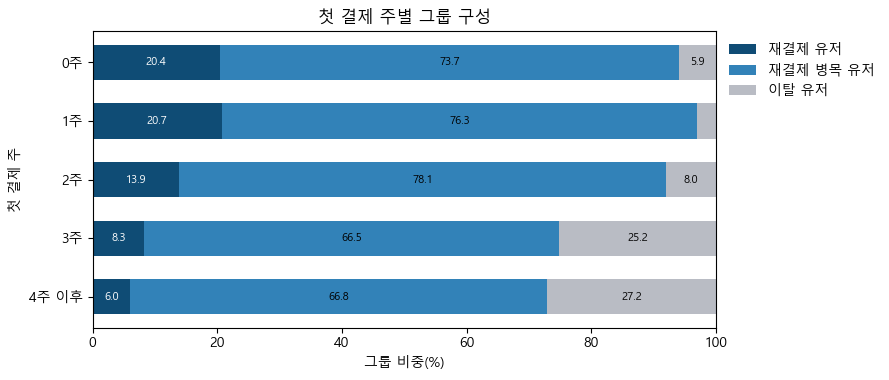

In [37]:
def stack_bar(ct, title, ylabel):
    # 행마다 재결제 유저·재결제 병목 유저·이탈 유저 비중(%)을 가로 누적 막대로 그림
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(ct) + 1.4))
    left = np.zeros(len(ct))
    for gname, col in zip(GROUPS7, [C1, C2, GRAY_BAR]):
        v = ct[gname].values
        ax.barh(range(len(ct)), v, left=left, color=col, label=gname, height=0.6)
        for i, (l, x) in enumerate(zip(left, v)):
            if x >= 4:
                ax.text(l + x / 2, i, f'{x:.1f}', ha='center', va='center', fontsize=8, color='white' if col == C1 else 'black')
        left += v
    ax.set_yticks(range(len(ct))); ax.set_yticklabels(ct.index.astype(str)); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel('그룹 비중(%)'); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    plt.tight_layout(); plt.show()

n7 = g7.grp.value_counts().reindex(GROUPS7)
display(pd.DataFrame({'인원': n7, '비중(%)': (n7 / len(g7) * 100).round(1)}).rename_axis('그룹'))
no_re7 = g7[~g7.re7]                                                # 문제 정의에 쓰는 값
print(f'7일 안에 재결제하지 않은 첫 결제자 {len(no_re7):,}명 중 재결제 병목 유저(7일 안 활동 기록 있음) '
      f'{int((no_re7.grp == GROUPS7[1]).sum()):,}명, {(no_re7.grp == GROUPS7[1]).mean():.1%}')

wk7 = pd.crosstab(g7.first_week_g, g7.grp, normalize='index').mul(100).round(1)
wk7.insert(0, '첫 결제자', g7.groupby('first_week_g', observed=False).size())
display(wk7.rename_axis(index='첫 결제 주', columns='그룹 (행 비중 %)'))

obs7 = g7.groupby('first_week_g', observed=False)[['fr7', 'att7', 'vote7', 'hk7']].mean().mul(100).round(1)
obs7.columns = ['친구 요청', '출석', '투표 데이터', '핵클']
display(obs7.rename_axis(index='첫 결제 주', columns='첫 결제 후 7일 안에 기록이 있는 비율(%)'))

stack_bar(wk7[GROUPS7], '첫 결제 주별 그룹 구성', '첫 결제 주')

- 재결제 유저 10,888명(18.8%), 재결제 병목 유저 43,136명(74.5%), 이탈 유저 3,847명(6.6%)임. 7일 안에 재결제하지 않은 46,983명 중 91.8%가 7일 안에 활동 기록이 있는 재결제 병목 유저임. 문제 정의의 "92%"는 이 값임. 받은 친구 요청만 있는 사람을 빼고 본인 행동만 세도 83.7%임(부록 G-2)
- 이탈 유저 비중은 0~2주 첫 결제자에서 3.0~8.0%이지만 3주 25.2%, 4주 이후 27.2%로 커짐. 늦게 첫 결제한 사람일수록 기록이 남지 않음
- 볼 수 있는 기록은 시기마다 다름. 0주 첫 결제자는 출석·핵클 기록이 0%라 친구 요청(93.3%)과 투표 데이터로만 판단됨. 4주 이후 첫 결제자는 친구 요청이 20.5%로 줄었지만 출석(52.4%)과 핵클(38.9%) 기록으로 재결제 병목 유저에 들어간 사람이 많음. 시기끼리 이탈 유저 비중을 비교할 때는 이 차이를 함께 봐야 함

### 4-3. 그룹별 특성
- 그룹 안에서 각 조건에 해당하는 유저의 비중(%)과 중앙값을 비교함. 분모는 각 그룹 인원임
- '7일 뒤~8/10 결제'는 첫 결제 후 7일이 지난 때부터 데이터 끝까지의 결제임. 7일 재결제율에는 잡히지 않음
- 7일 보낸·받은 요청 수는 첫 결제 후 7일 동안 센 값임

In [38]:
def pct(s):
    return round(s.mean() * 100, 1)

g7['signup_to_first'] = (g7.first_at - g7.signup_at).dt.total_seconds() / 86400      # 가입 → 첫 결제 (일)
g7['late_pay'] = g7.user_id.isin(pay[(pay.seq > 1) & (pay.gap > RE_WINDOW)].user_id)
rows = {}
for k, d in g7.groupby('grp', observed=False):
    wk_d = d.first_week_g.astype(str)
    rows[k] = {
        '연속 결제율(%)': pct(d.quick),
        '7일 뒤~8/10 결제 있음(%)': pct(d.late_pay),
        '이후 가입자(%)': pct(d.period == PERIODS[1]),
        '여학생(%)': pct(d.gender_k.astype(str) == '여'),
        '고등학생(%)': pct(d.school_grade.astype(str).str.startswith('고')),
        '수도권(%)': pct(d.region.astype(str) == '수도권'),
        '첫 결제가 특가 heart.777(%)': pct(d.first_product == 'heart.777'),
        '첫 결제 0~1주(%)': pct(wk_d.isin(['0주', '1주'])),
        '첫 결제 4주 이후(%)': pct(wk_d == '4주 이후'),
        '가입 → 첫 결제 일수 중앙값': round(d.signup_to_first.median(), 1),
        '가입 후 7일 넘어 첫 결제(%)': pct(d.signup_to_first > 7),
        '7일 보낸 요청 수 중앙값': d.fr_sent.median(),
        '7일 받은 요청 수 중앙값': d.fr_recv.median(),
        '7일 받은 요청만 있음(%)': pct((d.fr_recv > 0) & (d.fr_sent == 0) & (d.fr_acc == 0)),
        '7일 출석 있음(%)': pct(d.att7),
        '7일 투표 데이터 기록 있음(%)': pct(d.vote7),
        '7일 핵클 기록 있음(%)': pct(d.hk7),
        '핵클 기간(7/18~8/10)에 앱 사용(%)': pct(d.hk_period),
    }
prof7 = pd.DataFrame(rows)
prof7.columns = [f'{k} ({n:,}명)' for k, n in g7.grp.value_counts().reindex(GROUPS7).items()]
display(prof7.rename_axis('항목'))

,"재결제 유저 (10,888명)","재결제 병목 유저 (43,136명)","이탈 유저 (3,847명)"
항목,,,
연속 결제율(%),15.6,6.4,7.0
7일 뒤~8/10 결제 있음(%),15.2,3.8,4.5
이후 가입자(%),63.1,56.5,27.1
여학생(%),51.0,46.8,45.5
고등학생(%),68.4,64.1,63.8
수도권(%),30.6,36.2,62.1
첫 결제가 특가 heart.777(%),87.8,95.6,95.3
첫 결제 0~1주(%),88.4,81.2,59.4
첫 결제 4주 이후(%),1.1,3.2,14.6


- 재결제 유저와 재결제 병목 유저는 학교 유형·성별 구성이 비슷하고, 결제 방식에서 갈림. 재결제 유저의 연속 결제율은 15.6%로 재결제 병목 유저(6.4%)의 2.4배이고, 첫 결제를 정가 상품으로 한 비율도 12.2%로 재결제 병목 유저(4.4%)보다 높음
- 재결제 유저는 7일이 지난 뒤에도 계속 삼. 7일 뒤~8/10 결제가 15.2%로 재결제 병목 유저(3.8%)의 4배임
- 이탈 유저는 이전 가입자가 72.9%, 수도권이 62.1%임. 첫 결제 후 7일 동안 활동한 같은 반 친구가 적을수록 이탈 유저 비중이 커짐(부록 G-1)
- 이탈 유저는 가입 후 첫 결제까지 오래 걸림. 중앙값 11.6일이고 74.6%가 가입하고 7일이 넘어서 첫 결제함
- 이탈 유저도 앱을 완전히 떠난 것은 아님. 7일 뒤~8/10 결제가 4.5%로 재결제 병목 유저(3.8%)보다 조금 높고, 37.0%는 핵클 기간(7/18~8/10)에 앱을 씀

---
## 5. 재결제 병목 유저를 하트 잔액 구간으로 나눈 개선 우선순위

4장의 재결제 병목 유저(전환 대상)를 핵클 기간의 하트 잔액으로 다시 나눠, 어느 구간부터 개선할지 정함. 3-4에서 방문 시작 때 잔액이 적을수록 상점에 많이 가고 방문 중 결제도 많았으므로 잔액을 나누는 기준으로 씀.

| 항목 | 기준 |
|---|---|
| 대상 | 4장의 재결제 병목 유저 중 핵클 기간에 3-3 기준 방문이 있고 방문 시작 잔액이 찍힌 사람. 비교 기준인 재결제 유저도 같은 기준으로 셈 |
| 재결제 유저에서 뺀 사람 | 핵클 기간(7/18~)에 첫 결제한 재결제 유저. 7일 안 재결제가 핵클 기간 안에 있어 '방문 중 결제'가 정의상 잡힘 |
| 재결제 병목 유저에서 빼지 않은 사람 | 핵클 기간에 첫 결제한 재결제 병목 유저 459명. 정의상 첫 결제 후 7일 동안은 결제가 없어 방문 중 결제율이 낮게 잡힘(0.87%). 이들을 함께 빼도 우선순위(B→A→C→D)는 같고, 추가 결제자는 354명에서 331명이 됨 |
| 방문, 방문 시작 잔액, 상점 진입, 방문 중 결제 | 3-3과 같음 |
| 사람의 잔액 | 시작 잔액이 찍힌 방문 중 마지막 방문의 시작 잔액. 개입할 때는 가장 최근 상태를 기준으로 삼기 때문 |
| 받은 질문 엶 | 방문 안에 `click_question_open`이 있음 (3-4와 같음) |
| 사람 단위 행동 | 받은 질문 엶, 상점 진입, 방문 중 결제는 시작 잔액이 찍힌 방문에서 한 번이라도 있었는지로 셈 |
| 포인트를 씀 | 3-3 이벤트에서 같은 유저의 직전 `heart_balance`보다 줄어든 기록이 있음. 줄어든 폭은 보지 않음(5-1 참고). 힌트 말고 채팅방 열기 같은 다른 지출도 들어감 |
| 방문 중 결제한 사람 | 방문 중 결제가 한 번이라도 있는 사람. 이 장의 '결제율'은 이 비율임 |

구간 경계는 힌트 가격으로 정함. 5/18 이후 받은 질문의 힌트는 첫째 글자 200, 둘째 글자 500, 셋째 글자 1,000임. 핵클 기간 포인트 기록의 감소 폭이 이 세 값뿐인 것은 5-1 첫 출력에서, 이 가격의 첫 기록(2023-05-18 21:19)은 6-4 첫 출력에서 확인함. 가격이 바뀌기 전과 후의 재결제율 비교는 부록 D-7에 있음. 한 질문에서 첫째 글자부터 차례로 연다고 보고, 가격을 더해 간 200, 700, 1,700을 경계로 씀. 경계가 앱 기능과 이어져 구간의 뜻을 설명할 수 있음.

| 세그먼트 | 잔액 구간 | 이 잔액으로 열 수 있는 힌트 |
|---|---|---|
| A | 200 미만 | 첫째 글자도 열 수 없음 |
| B | 200~699 | 첫째 글자까지 |
| C | 700~1,699 | 둘째 글자까지 |
| D | 1,700 이상 | 한 질문의 세 글자 모두 |

- `heart_balance`에 결제로 산 하트가 들어 있는지는 확인하지 못함(3-4). 이 장에서는 힌트에 쓰는 포인트 잔액으로 봄
- 4장 그룹은 첫 결제 후 7일(대부분 5월) 기준이고, 잔액은 약 두 달 뒤인 핵클 기간의 상태임. 이 장의 구간은 재결제가 끊긴 원인이 아니라 핵클 기간에 개입할 대상을 정하는 기준임

### 5-1. 재결제 병목 유저의 하트 잔액 구간별 특성
- 세그먼트마다 받은 질문을 연 사람, 포인트를 쓴 사람, 상점에 간 사람, 방문 중 결제한 사람의 비율을 봄. 분모는 각 세그먼트 인원임

In [39]:
HEART_BINS8 = [-1, 199, 699, 1699, np.inf]
ph4 = read_cols('accounts_pointhistory', ['delta_point', 'created_at', 'user_id'], parse_dates=['created_at'])   # 포인트 기록 (투표 데이터 유저)
SEG8 = ['A: 200 미만', 'B: 200~699', 'C: 700~1,699', 'D: 1,700 이상']
PAY8 = '방문 중 결제한 사람(%)'

# 포인트를 쓴 사람: 같은 유저의 직전 잔액보다 줄어든 이벤트가 있음 (ev5는 유저·시각 순)
# 핵클 기간 포인트 기록의 감소는 힌트 가격뿐이고 보상은 늘어나기만 하므로, 잔액이 줄었다면 그 사이 지출이 있었다는 뜻
hb = ev5.dropna(subset=['heart_balance'])
drop = hb.groupby('user_id').heart_balance.diff()
spent_users = set(hb.loc[drop < 0, 'user_id'])
print('핵클 기간 포인트 기록의 감소 폭:', ph4[(ph4.created_at >= HK_START) & (ph4.created_at < DATA_END) & (ph4.delta_point < 0)].delta_point.value_counts().to_dict())
print(f'결제 경험자 핵클 잔액 감소 {int((drop < 0).sum()):,}건 중 힌트 한 글자 가격(200·500·1,000)과 같은 폭: '
      f'{drop[drop < 0].isin([-200, -500, -1000]).mean():.1%}')
del hb, drop

# 사람마다 잔액이 찍힌 마지막 방문의 시작 잔액으로 세그먼트를 정함
g7_idx = g7.set_index('user_id')
v8 = vis.dropna(subset=['heart']).assign(grp=lambda d: d.user_id.map(g7_idx.grp))
v8 = v8[v8.grp.notna()].sort_values('start')
p8 = v8.groupby('user_id').agg(grp=('grp', 'first'), heart=('heart', 'last'), q_open=('q_open', 'any'),
                               shop=('shop', 'any'), paid=('paid', 'any'))
p8['spent'] = p8.index.isin(spent_users)
p8['seg'] = pd.cut(p8.heart, HEART_BINS8, labels=SEG8)
p8 = p8[~((p8.grp == GROUPS7[0]) & (p8.index.map(g7_idx.first_at) >= HK_START))]   # 핵클 기간 첫 결제 재결제 유저 제외

def seg_table(d):
    # 세그먼트별 인원, 비중, 잔액 중앙값과 각 행동을 한 사람의 비율(%). 마지막 행은 합계
    t = d.groupby('seg', observed=False).agg(n=('shop', 'size'), med=('heart', 'median'), q=('q_open', 'mean'),
                                             h=('spent', 'mean'), s=('shop', 'mean'), p=('paid', 'mean'), pn=('paid', 'sum'))
    t.insert(1, 'share', t.n / t.n.sum() * 100)
    t[['q', 'h', 's', 'p']] *= 100
    t.index = t.index.astype(str)
    t.loc['합계'] = [t.n.sum(), 100, np.nan, np.nan, np.nan, d.shop.mean() * 100, d.paid.mean() * 100, t.pn.sum()]
    t.columns = ['인원', '비중(%)', '잔액 중앙값', '받은 질문을 연 사람(%)', '포인트를 쓴 사람(%)',
                 '상점에 간 사람(%)', PAY8, '결제한 사람']
    return t

def show_seg(t):
    display(t.round(1).astype({'인원': int, '결제한 사람': int}).rename_axis('세그먼트'))

g2_mask = g7.grp == GROUPS7[1]
print(f'재결제 병목 유저 {g2_mask.sum():,}명 중 핵클 기간에 방문이 있는 사람 {g7[g2_mask].user_id.isin(vis.user_id).sum():,}명, '
      f'그중 방문 시작 잔액이 찍힌 사람 {(p8.grp == GROUPS7[1]).sum():,}명')
g2t = seg_table(p8[p8.grp == GROUPS7[1]])
show_seg(g2t)

핵클 기간 포인트 기록의 감소 폭: {-200: 183, -500: 103, -1000: 46}
결제 경험자 핵클 잔액 감소 5,525건 중 힌트 한 글자 가격(200·500·1,000)과 같은 폭: 14.0%
재결제 병목 유저 43,136명 중 핵클 기간에 방문이 있는 사람 18,787명, 그중 방문 시작 잔액이 찍힌 사람 18,205명


,인원,비중(%),잔액 중앙값,받은 질문을 연 사람(%),포인트를 쓴 사람(%),상점에 간 사람(%),방문 중 결제한 사람(%),결제한 사람
세그먼트,,,,,,,,
A: 200 미만,2681,14.7,114.0,57.9,20.2,21.6,5.1,138
B: 200~699,5209,28.6,411.0,53.3,17.9,14.5,2.6,133
"C: 700~1,699",4594,25.2,1073.5,51.0,13.1,9.6,1.4,63
"D: 1,700 이상",5721,31.4,3148.0,50.6,8.9,4.9,0.1,4
합계,18205,100.0,NaN,NaN,NaN,11.3,1.9,338


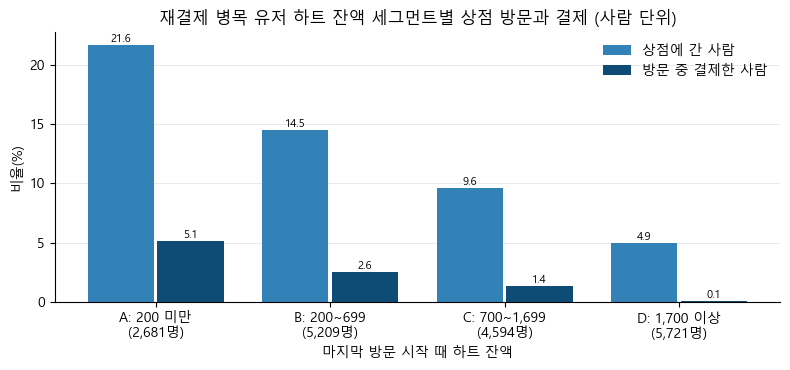

In [40]:
# 5-1 그래프: 세그먼트별 상점에 간 사람과 방문 중 결제한 사람
t81 = g2t.drop('합계')
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(t81)); w = 0.4
for i, (col, c, lab) in enumerate([('상점에 간 사람(%)', C2, '상점에 간 사람'), (PAY8, C1, '방문 중 결제한 사람')]):
    bars = ax.bar(x + (i - 0.5) * w, t81[col], w * 0.95, color=c, label=lab)
    for b_, v in zip(bars, t81[col]):
        ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([f'{s}\n({int(n):,}명)' for s, n in zip(t81.index, t81['인원'])])
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#E5E5E5', lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel('마지막 방문 시작 때 하트 잔액'); ax.set_ylabel('비율(%)')
ax.set_title('재결제 병목 유저 하트 잔액 세그먼트별 상점 방문과 결제 (사람 단위)')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

- 재결제 병목 유저 43,136명 중 핵클 기간에 방문이 있는 사람은 18,787명이고, 그중 방문 시작 잔액이 찍힌 18,205명을 네 세그먼트로 나눔
- 잔액이 적을수록 상점에 간 사람과 방문 중 결제한 사람이 많음. 방문 중 결제한 사람은 A(200 미만) 5.1%, B(200~699) 2.6%, C(700~1,699) 1.4%, D(1,700 이상) 0.1%로 세그먼트마다 줄어듦
- 받은 질문을 연 사람은 50.6~57.9%로 세그먼트 사이 차이가 작음. 받은 질문을 보는 행동은 비슷하고, 그 뒤 상점으로 이어지는지가 잔액에 따라 달라짐
- 핵클 기간 포인트 기록의 감소는 −200·−500·−1,000뿐임(포인트 기록은 투표 표본 유저만 있음). 그런데 결제 경험자의 핵클 잔액 감소 5,525건 중 이 폭과 같은 것은 14.0%뿐임. 잔액이 몰아서 갱신돼 그 사이의 지출과 보상이 합쳐져 찍히기 때문으로 보임. 그래서 폭을 맞추지 않고 잔액이 줄어든 기록이 있는지만 봄. 보상은 잔액을 늘리기만 하므로 줄어든 기록이 있으면 그 사이에 지출이 있었다는 뜻임
- 포인트를 쓴 사람은 A(200 미만) 20.2%, B 17.9%, C 13.1%, D 8.9%로 잔액이 적을수록 많음. 잔액이 적은 것이 포인트를 많이 쓴 결과일 수도 있어, 어느 쪽이 먼저인지는 가를 수 없음
- 상점에 간 사람이 포인트를 쓴 사람보다 많은 세그먼트는 A(200 미만, 21.6% 대 20.2%)뿐임. B~D는 포인트를 쓴 사람이 더 많음(B: 17.9% 대 14.5%, C: 13.1% 대 9.6%, D: 8.9% 대 4.9%). A는 잔액으로 첫째 글자도 열 수 없어, 포인트를 쓰기보다 상점으로 가는 사람이 많은 구간으로 보임(상점 진입 경로는 6-1)
- D(1,700 이상)가 31.4%로 가장 큼. 포인트를 쓴 사람이 8.9%로 가장 적고, 방문 중 결제한 사람은 5,721명 중 4명임
- 핵클 기간에 방문이 없는 재결제 병목 유저(24,349명)는 이 장에서 다루지 않음. 잔액 구간으로 나눌 수 없어, 앱으로 다시 불러오는 것이 먼저인 대상임(부록 F)

### 5-2. 개선 기준치: 같은 잔액 구간 재결제 유저의 방문 중 결제율

재결제 병목 유저의 개선 기준치를 같은 세그먼트 재결제 유저의 방문 중 결제율로 둠.

- 재무 데이터(매출 목표, 비용)가 없어 매출이 개선되는 임계치로 목표를 정할 수 없음
- 그래서 재결제가 이루어진 재결제 유저의 결제율을 1차 기준치로 둠. 4장에서 재결제 유저는 비교 기준 역할임
- 같은 잔액 구간끼리 비교하므로, 잔액 차이 때문에 생기는 결제율 차이는 기준치에 섞이지 않음
- '추가 결제자' = 재결제 병목 유저 인원 × (재결제 유저 결제율 − 재결제 병목 유저 결제율). 재결제 병목 유저가 같은 세그먼트 재결제 유저 수준에 이르렀을 때 늘어나는 결제한 사람 수임

In [41]:
g1t = seg_table(p8[p8.grp == GROUPS7[0]])
print(f'재결제 유저 {(g7.grp == GROUPS7[0]).sum():,}명 중 방문 시작 잔액이 찍힌 사람 {int(g1t.loc["합계", "인원"]):,}명 (핵클 기간 첫 결제자 제외)')
show_seg(g1t)

tgt = pd.DataFrame({'재결제 병목 유저 인원': g2t['인원'], '재결제 병목 유저 결제율(%)': g2t[PAY8], '기준치: 재결제 유저 결제율(%)': g1t[PAY8]}).drop('합계')
tgt['차이(%p)'] = tgt['기준치: 재결제 유저 결제율(%)'] - tgt['재결제 병목 유저 결제율(%)']
tgt['추가 결제자'] = tgt['재결제 병목 유저 인원'] * tgt['차이(%p)'] / 100
tgt['재결제 유저 결제한 사람'] = g1t['결제한 사람']
tgt.loc['합계'] = [tgt['재결제 병목 유저 인원'].sum(), g2t.loc['합계', PAY8], np.nan, np.nan, tgt['추가 결제자'].sum(), tgt['재결제 유저 결제한 사람'].sum()]
display(tgt.round({'재결제 병목 유저 결제율(%)': 1, '기준치: 재결제 유저 결제율(%)': 1, '차이(%p)': 1, '추가 결제자': 0})
           .astype({'재결제 병목 유저 인원': int, '재결제 유저 결제한 사람': int}).rename_axis('세그먼트'))

재결제 유저 10,888명 중 방문 시작 잔액이 찍힌 사람 5,177명 (핵클 기간 첫 결제자 제외)


,인원,비중(%),잔액 중앙값,받은 질문을 연 사람(%),포인트를 쓴 사람(%),상점에 간 사람(%),방문 중 결제한 사람(%),결제한 사람
세그먼트,,,,,,,,
A: 200 미만,1038,20.1,109.0,60.1,20.6,23.4,8.4,87
B: 200~699,1647,31.8,412.0,56.5,19.6,16.8,5.5,91
"C: 700~1,699",1217,23.5,1104.0,49.5,16.8,12.8,3.6,44
"D: 1,700 이상",1275,24.6,3063.0,50.7,11.8,6.4,0.2,3
합계,5177,100.0,NaN,NaN,NaN,14.6,4.3,225


,재결제 병목 유저 인원,재결제 병목 유저 결제율(%),기준치: 재결제 유저 결제율(%),차이(%p),추가 결제자,재결제 유저 결제한 사람
세그먼트,,,,,,
A: 200 미만,2681,5.1,8.4,3.2,87.0,87
B: 200~699,5209,2.6,5.5,3.0,155.0,91
"C: 700~1,699",4594,1.4,3.6,2.2,103.0,44
"D: 1,700 이상",5721,0.1,0.2,0.2,9.0,3
합계,18205,1.9,NaN,NaN,354.0,225


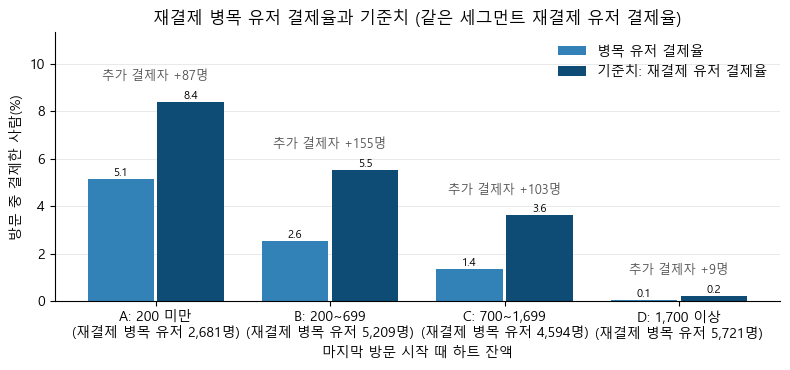

In [42]:
# 5-2 그래프: 세그먼트별 재결제 병목 유저 결제율과 기준치(같은 세그먼트 재결제 유저 결제율), 막대 위는 추가 결제자
t82 = tgt.drop('합계')
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(len(t82)); w = 0.4
for i, (col, c, lab) in enumerate([('재결제 병목 유저 결제율(%)', C2, '병목 유저 결제율'), ('기준치: 재결제 유저 결제율(%)', C1, '기준치: 재결제 유저 결제율')]):
    bars = ax.bar(x + (i - 0.5) * w, t82[col], w * 0.95, color=c, label=lab)
    for b_, v in zip(bars, t82[col]):
        ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v:.1f}', ha='center', va='bottom', fontsize=8)
top = t82[['재결제 병목 유저 결제율(%)', '기준치: 재결제 유저 결제율(%)']].max(axis=1)
for xi, y, a in zip(x, top, t82['추가 결제자']):
    ax.text(xi, y + 0.8, f'추가 결제자 +{a:.0f}명', ha='center', va='bottom', fontsize=9, color='#555')
ax.set_ylim(0, top.max() * 1.35)
ax.set_xticks(x); ax.set_xticklabels([f'{s}\n(재결제 병목 유저 {int(n):,}명)' for s, n in zip(t82.index, t82['재결제 병목 유저 인원'])])
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#E5E5E5', lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel('마지막 방문 시작 때 하트 잔액'); ax.set_ylabel('방문 중 결제한 사람(%)')
ax.set_title('재결제 병목 유저 결제율과 기준치 (같은 세그먼트 재결제 유저 결제율)')
ax.legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

- 재결제 유저 10,888명 중 방문 시작 잔액이 찍힌 5,177명(핵클 기간 첫 결제자 제외)을 같은 세그먼트로 나눔
- 같은 세그먼트에서 재결제 유저의 방문 중 결제율이 재결제 병목 유저보다 높음(A: 8.4% 대 5.1%, B: 5.5% 대 2.6%, C: 3.6% 대 1.4%). A~C에서 상점에 간 사람은 재결제 유저가 재결제 병목 유저의 1.1~1.3배인데, 방문 중 결제한 사람은 1.6~2.6배임
- 잔액에 따른 기울기는 재결제 유저에도 같음. D(1,700 이상)는 재결제 유저도 방문 중 결제율이 0.2%(1,275명 중 3명)로 거의 사지 않음
- 재결제 병목 유저가 같은 세그먼트 재결제 유저 수준에 이르면 추가 결제자는 A: 87명, B: 155명, C: 103명, D: 9명, 합계 354명임(지금 재결제 병목 유저 결제한 사람 338명)
- 기준치는 예상 효과가 아님. 재결제 유저는 첫 결제 직후 재결제를 한 사람이라 같은 잔액에서도 원래 더 사는 사람일 수 있음. 추가 결제자는 개선 여지로 읽음
- 재결제 유저 쪽 결제한 사람이 세그먼트마다 87·91·44·3명이라, 특히 D의 기준치는 흔들릴 수 있음

### 5-3. 세그먼트 개선 우선순위
- x축은 지금 결제에 얼마나 가까운지(재결제 병목 유저 방문 중 결제율), y축은 규모(재결제 병목 유저 인원), 버블 크기는 5-2의 추가 결제자임
- 점선은 재결제 병목 유저 전체 결제율과 세그먼트 평균 인원

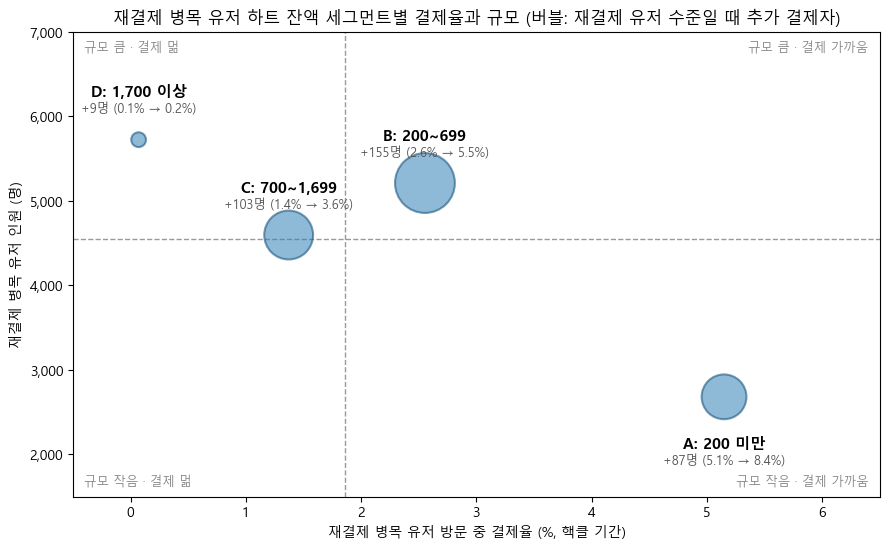

In [43]:
fig, ax = plt.subplots(figsize=(9, 5.6))
t8 = tgt.drop('합계')
xm, ym = g2t.loc['합계', PAY8], t8['재결제 병목 유저 인원'].mean()
ax.axvline(xm, color='#999', ls='--', lw=1)
ax.axhline(ym, color='#999', ls='--', lw=1)
ax.scatter(t8['재결제 병목 유저 결제율(%)'], t8['재결제 병목 유저 인원'], s=t8['추가 결제자'].clip(lower=5) * 12,
           color=C2, alpha=0.55, edgecolor=C1, lw=1.5, zorder=3)
for seg, r in t8.iterrows():
    dy = -560 if r['재결제 병목 유저 인원'] < ym * 0.8 else 560        # 버블 위나 아래에 이름을 씀
    ax.text(r['재결제 병목 유저 결제율(%)'], r['재결제 병목 유저 인원'] + dy, seg, ha='center', va='center', fontsize=11, fontweight='bold')
    ax.text(r['재결제 병목 유저 결제율(%)'], r['재결제 병목 유저 인원'] + dy - 200,
            f"+{r['추가 결제자']:.0f}명 ({r['재결제 병목 유저 결제율(%)']:.1f}% → {r['기준치: 재결제 유저 결제율(%)']:.1f}%)",
            ha='center', va='center', fontsize=9, color='#555')
ax.set_xlim(-0.5, 6.5); ax.set_ylim(1500, 7000)
for x_, y_, txt, ha, va in [(-0.4, 6880, '규모 큼 · 결제 멂', 'left', 'top'), (6.4, 6880, '규모 큼 · 결제 가까움', 'right', 'top'),
                            (-0.4, 1600, '규모 작음 · 결제 멂', 'left', 'bottom'), (6.4, 1600, '규모 작음 · 결제 가까움', 'right', 'bottom')]:
    ax.text(x_, y_, txt, ha=ha, va=va, fontsize=9, color='#888')
ax.set_xlabel('재결제 병목 유저 방문 중 결제율 (%, 핵클 기간)'); ax.set_ylabel('재결제 병목 유저 인원 (명)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title('재결제 병목 유저 하트 잔액 세그먼트별 결제율과 규모 (버블: 재결제 유저 수준일 때 추가 결제자)')
plt.tight_layout(); plt.show()

우선순위: B → A → C → D

| 순위 | 세그먼트 | 근거 |
|---|---|---|
| 1 | B (200~699) | 추가 결제자 155명으로 가장 많고, 결제율 2.6%로 재결제 병목 유저 평균(1.9%)보다 높아 결제에 가까운 편임 |
| 2 | A (200 미만) | 추가 결제자 87명으로 C(103명)와 비슷함. 결제율이 5.1%로 가장 높아 C보다 앞에 둠 |
| 3 | C (700~1,699) | 추가 결제자 103명으로 A와 비슷하지만 결제율 1.4%로 재결제 병목 유저 평균보다 낮음 |
| 4 | D (1,700 이상) | 인원은 5,721명으로 가장 많지만 결제율 0.1%로 결제에서 가장 멂. 재결제 유저도 이 세그먼트에서는 0.2%만 결제해 재결제 유저 수준에 이르러도 추가 결제자가 9명뿐임 |

- 우선순위는 개선 여지(추가 결제자)를 먼저 보고, 비슷하면 결제에 가까운 쪽을 앞에 둠
- 버블은 재결제 병목 유저가 재결제 유저 수준에 이른다는 가정의 값이라 효과를 보장하지 않음. 세그먼트별 개선안의 효과는 실험(A/B 테스트)으로 확인해야 함

---
## 6. 세그먼트별 개선안의 근거

5장에서 정한 우선순위의 세그먼트마다 개선안을 정할 때 쓴 근거를 모음. 6-1·6-2는 결제 경험자 전체로 계산한 부록 E-4·E-5를 5장의 재결제 유저·재결제 병목 유저 세그먼트별로 다시 계산하고, 6-3·6-4는 제안할 상품과 힌트 단계를 정할 때 쓴 값임.

| 절 | 내용 | 근거로 쓰는 세그먼트 |
|---|---|---|
| 6-1 | 세그먼트별로 어떤 행동 뒤에 상점에 들어갔나 (재결제 유저 대 재결제 병목 유저) | A(200 미만), C(700~1,699) |
| 6-2 | 세그먼트별로 상점에 들어가서 무엇을 눌렀나 (재결제 유저 대 재결제 병목 유저) | B(200~699), D(1,700 이상) |
| 6-3 | 재결제 유저가 처음 재결제할 때 산 상품 | B(200~699) |
| 6-4 | 받은 질문 하나에서 힌트를 몇 번째 글자까지 열었나 | C(700~1,699) |

| 항목 | 기준 |
|---|---|
| 대상 (6-1, 6-2) | 5장의 재결제 유저·재결제 병목 유저와 같음. 방문 시작 잔액이 찍힌 방문만 쓰고, 핵클 기간에 첫 결제한 재결제 유저는 뺌 |
| 세그먼트 | 5-1과 같음. 사람마다 마지막 방문의 시작 잔액으로 정하고, 그 사람의 방문은 모두 같은 세그먼트로 셈 |
| 방문, 상점 진입, 방문 중 결제 | 3-3과 같음 |
| 행동 뒤 상점 진입, 상점에서 누른 것 | 부록 E-4, E-5와 같음 |

### 6-1. 세그먼트별로 어떤 행동 뒤에 상점에 들어갔나
- 부록 E-4와 같은 방법으로, 행동마다 그 행동이 있었던 방문 중 그 행동을 처음 한 뒤에 상점에 들어간 방문의 비율을 셈
- 세그먼트마다 재결제 유저와 재결제 병목 유저를 나란히 놓음. 같은 세그먼트·그룹의 전체 방문 상점 진입률보다 높으면 상점으로 이어지는 행동임

In [44]:
# 5장의 재결제 유저·재결제 병목 유저(p8)를 방문 단위로 되돌림. 방문의 세그먼트는 그 사람의 세그먼트(마지막 방문 시작 잔액)
GRP9 = {g: g for g in GROUPS7[:2]}
p9 = p8[p8.grp.isin(GRP9)]
v9 = v8[v8.user_id.isin(p9.index)].copy()
v9['g'] = v9.grp.map(GRP9)
v9['seg'] = v9.user_id.map(p9.seg).astype(str)

# 방문 안의 행동 (부록 E-4에서도 씀)
ACTS5 = {'click_question_open': '받은 질문 열기', 'click_attendance': '출석체크', 'click_notice_detail': '공지 상세 보기',
         'click_appbar_alarm_center': '알림 센터 열기', 'click_bottom_navigation_questions': '질문 탭 누르기',
         'click_appbar_chat_rooms': '채팅방 열기', 'complete_question': '질문 세트 완료',
         'view_profile_tap': '프로필 보기', 'view_lab_tap': '실험실 보기', 'view_timeline_tap': '타임라인 보기'}

# 방문마다 행동을 처음 한 시각
first_act9 = (ev5[ev5.event_key.isin(list(ACTS5)) & ev5.visit.isin(v9.index)]
              .groupby(['event_key', 'visit']).event_datetime.min())

def act_shop(vv):
    # 행동별로, 그 행동이 있는 방문 중 처음 한 뒤에 상점에 들어간 방문의 비율(%)
    out = {}
    for k, name in ACTS5.items():
        fa = first_act9.xs(k, level='event_key')
        fa = fa[fa.index.isin(vv.index)]
        out[name] = (shop_at.reindex(fa.index) >= fa).mean() * 100
    return pd.Series(out)

meta9, act9 = {}, {}
for seg in SEG8:
    for g in GROUPS7[:2]:
        vv = v9[(v9.seg == seg) & (v9.g == g)]
        meta9[(seg, g)] = {'사람': vv.user_id.nunique(), '방문': len(vv), '상점 방문': int(vv.shop.sum()),
                           '전체 방문 상점 진입(%)': vv.shop.mean() * 100}
        act9[(seg, g)] = act_shop(vv)
meta9 = pd.DataFrame(meta9).T.rename_axis(['세그먼트', '그룹'])
act9 = pd.DataFrame(act9)                      # 행 = 행동, 열 = (세그먼트, 그룹)
display(meta9.astype({'사람': int, '방문': int, '상점 방문': int}).round(2))
for seg in SEG8:
    t = act9[seg].sort_values(GROUPS7[1], ascending=False)
    t['차이(재결제 병목 유저−재결제 유저, %p)'] = t[GROUPS7[1]] - t[GROUPS7[0]]
    t.columns = ['재결제 유저 행동 뒤 상점 진입(%)', '재결제 병목 유저 행동 뒤 상점 진입(%)', '차이(재결제 병목 유저−재결제 유저, %p)']
    print(f'\n[{seg}]')
    display(t.round(2).rename_axis('행동'))

사람     방문  상점 방문  전체 방문 상점 진입(%)
세그먼트         그룹                                           
A: 200 미만    재결제 유저     1038   4272    319            7.47
             재결제 병목 유저  2681  10921    729            6.68
B: 200~699   재결제 유저     1647   6927    352            5.08
             재결제 병목 유저  5209  19756    924            4.68
C: 700~1,699 재결제 유저     1217   4798    180            3.75
             재결제 병목 유저  4594  16011    541            3.38
D: 1,700 이상  재결제 유저     1275   7726     92            1.19
             재결제 병목 유저  5721  25846    318            1.23


[A: 200 미만]


,재결제 유저 행동 뒤 상점 진입(%),재결제 병목 유저 행동 뒤 상점 진입(%),"차이(재결제 병목 유저−재결제 유저, %p)"
행동,,,
공지 상세 보기,11.83,12.69,0.85
받은 질문 열기,12.60,12.24,-0.36
알림 센터 열기,11.94,11.83,-0.11
질문 탭 누르기,11.46,10.60,-0.86
출석체크,12.11,10.20,-1.90
채팅방 열기,9.90,8.98,-0.92
질문 세트 완료,11.67,8.15,-3.52
프로필 보기,7.81,7.94,0.13
실험실 보기,7.61,7.61,0.00



[B: 200~699]


,재결제 유저 행동 뒤 상점 진입(%),재결제 병목 유저 행동 뒤 상점 진입(%),"차이(재결제 병목 유저−재결제 유저, %p)"
행동,,,
출석체크,11.10,10.20,-0.90
공지 상세 보기,10.11,8.33,-1.78
받은 질문 열기,9.97,8.25,-1.72
알림 센터 열기,9.51,7.77,-1.74
질문 탭 누르기,8.38,7.63,-0.75
질문 세트 완료,9.18,7.15,-2.03
채팅방 열기,8.20,6.33,-1.87
실험실 보기,6.15,5.47,-0.68
프로필 보기,6.42,5.45,-0.97



[C: 700~1,699]


,재결제 유저 행동 뒤 상점 진입(%),재결제 병목 유저 행동 뒤 상점 진입(%),"차이(재결제 병목 유저−재결제 유저, %p)"
행동,,,
출석체크,7.25,8.01,0.76
받은 질문 열기,8.43,6.37,-2.06
공지 상세 보기,7.57,6.00,-1.56
알림 센터 열기,7.27,5.87,-1.40
질문 탭 누르기,6.49,5.55,-0.95
질문 세트 완료,5.08,4.73,-0.35
채팅방 열기,5.10,4.56,-0.54
프로필 보기,5.37,4.25,-1.12
실험실 보기,4.34,3.96,-0.38



[D: 1,700 이상]


,재결제 유저 행동 뒤 상점 진입(%),재결제 병목 유저 행동 뒤 상점 진입(%),"차이(재결제 병목 유저−재결제 유저, %p)"
행동,,,
받은 질문 열기,3.43,3.01,-0.43
출석체크,1.82,2.14,0.32
채팅방 열기,2.26,2.09,-0.17
질문 탭 누르기,2.15,2.08,-0.07
공지 상세 보기,1.86,2.06,0.20
알림 센터 열기,1.58,1.86,0.27
질문 세트 완료,0.74,1.50,0.76
실험실 보기,1.36,1.35,-0.01
프로필 보기,1.63,1.34,-0.29


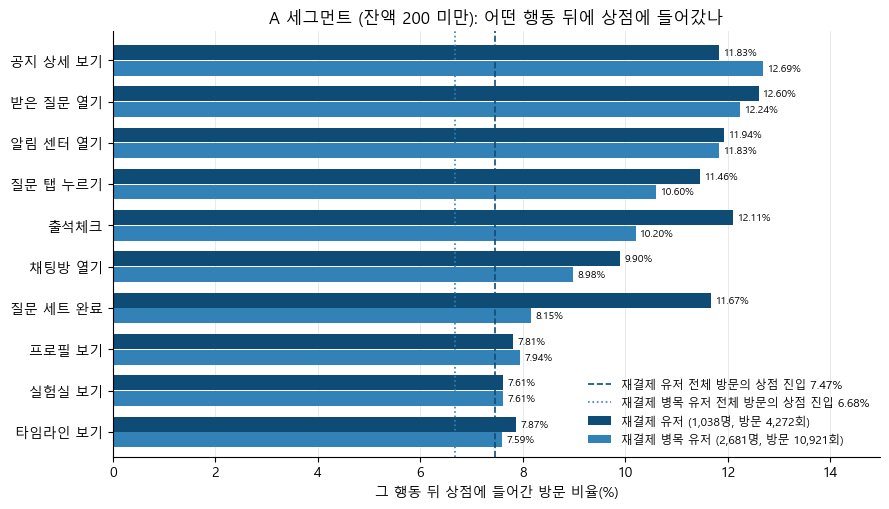

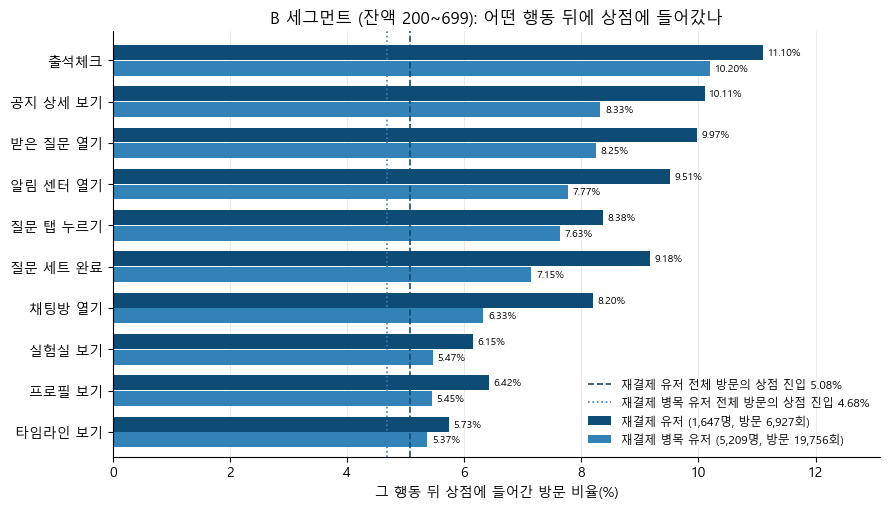

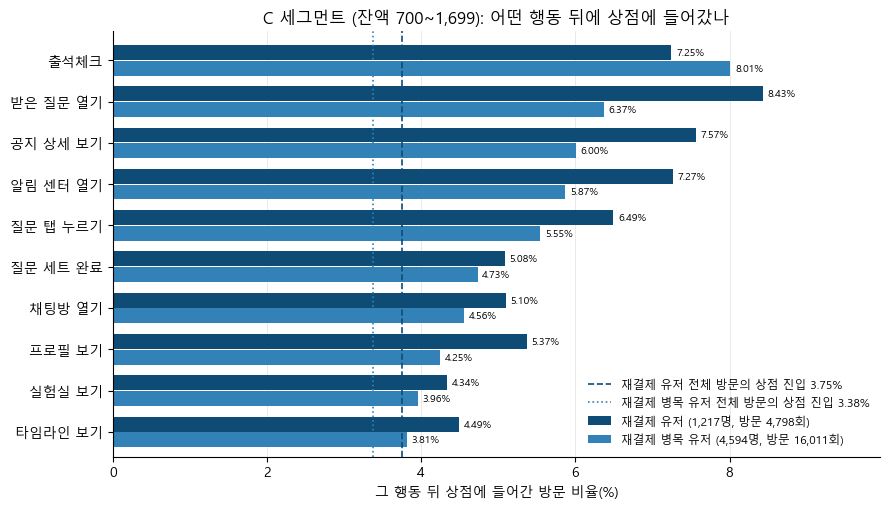

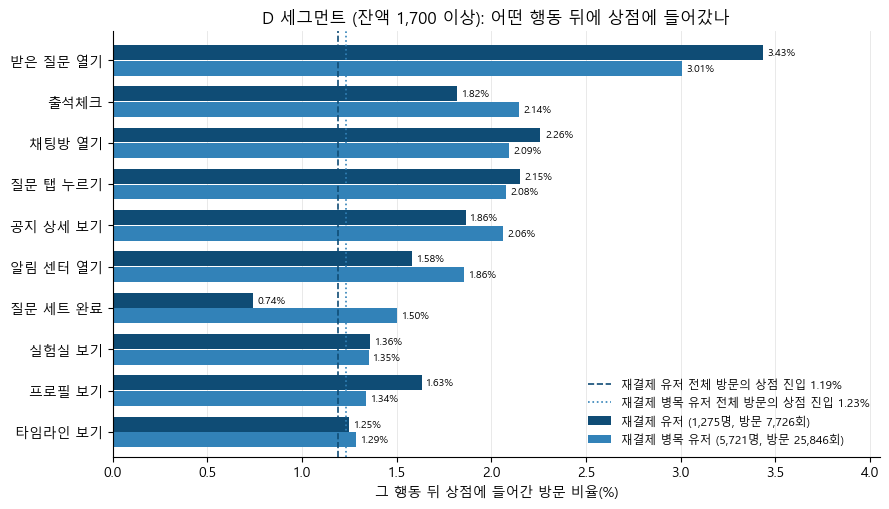

In [45]:
# 6-1 그래프: 세그먼트마다 재결제 유저·재결제 병목 유저의 행동 뒤 상점 진입률 (세로선 = 같은 세그먼트·그룹 전체 방문의 상점 진입률)
for seg in SEG8:
    a = act9[seg]
    order = a[GROUPS7[1]].sort_values(ascending=False).index
    y = np.arange(len(order)); h = 0.38
    xmax = a.values.max() * 1.18
    fig, ax = plt.subplots(figsize=(9, 5.2))
    for i, (g, col) in enumerate([(GROUPS7[0], C1), (GROUPS7[1], C2)]):
        m = meta9.loc[(seg, g)]
        v = a.loc[order, g]
        ax.barh(y + (i - 0.5) * h, v, h * 0.95, color=col, label=f"{g} ({int(m['사람']):,}명, 방문 {int(m['방문']):,}회)")
        for yy, x in zip(y + (i - 0.5) * h, v):
            ax.text(x + xmax * 0.006, yy, f'{x:.2f}%', va='center', fontsize=7.5)
    for g, col, ls in [(GROUPS7[0], C1, '--'), (GROUPS7[1], '#3282B8', ':')]:
        base9 = meta9.loc[(seg, g), '전체 방문 상점 진입(%)']
        ax.axvline(base9, color=col, ls=ls, lw=1.2, label=f'{g} 전체 방문의 상점 진입 {base9:.2f}%')
    ax.set_yticks(y); ax.set_yticklabels(order); ax.set_ylim(len(order) - 0.4, -0.7); ax.set_xlim(0, xmax)
    ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#E5E5E5', lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('그 행동 뒤 상점에 들어간 방문 비율(%)')
    ax.set_title(f"{seg.split(': ')[0]} 세그먼트 (잔액 {seg.split(': ')[1]}): 어떤 행동 뒤에 상점에 들어갔나")
    ax.legend(frameon=False, loc='lower right', fontsize=8.5)
    plt.tight_layout(); plt.show()

- A(200 미만)는 재결제 유저와 재결제 병목 유저의 차이가 작음. 열 개 행동 중 아홉 개에서 차이가 ±2%p 안임. 재결제 병목 유저도 공지 상세 보기 뒤 12.69%, 받은 질문 열기 뒤 12.24%로 같은 세그먼트 전체 방문(6.68%)의 1.8~1.9배임. 상점까지 오는 단계는 재결제 유저와 비슷하고, 차이는 상점에 들어온 뒤에 남(6-2)
- A에서 재결제 병목 유저가 재결제 유저보다 2%p 넘게 낮은 것은 질문 세트 완료 뒤(11.67% 대 8.15%)뿐임
- B(200~699)는 재결제 병목 유저가 모든 행동에서 0.4~2.0%p 낮음
- C(700~1,699)는 받은 질문 열기 뒤의 차이가 가장 큼(재결제 유저 8.43% 대 재결제 병목 유저 6.37%). 재결제 병목 유저는 출석체크 뒤가 8.01%로 가장 높고, 이 행동에서만 재결제 유저(7.25%)보다 높음
- D(1,700 이상)는 재결제 유저·재결제 병목 유저 모두 전체 방문의 상점 진입이 1.2%이고, 어떤 행동 뒤에도 3.5%를 넘지 않음. 행동과 상관없이 상점에 거의 가지 않음
- 부록 E-4와 같이 같은 방문 안의 순서만 봄. 그 행동 때문에 상점에 갔다는 뜻은 아님

### 6-2. 세그먼트별로 상점에 들어가서 무엇을 눌렀나
- 부록 E-5와 같은 분류로, 상점에 들어간 방문을 상점 안에서 누른 것으로 나눔. 유료 상품 = `click_purchase` 중 상품 이름에 '하트'가 있는 것, 무료충전소 = 상품 이름에 '무료'가 있는 것
- 세그먼트마다 재결제 유저와 재결제 병목 유저의 비중과 방문 중 결제 비율을 나란히 놓음

In [46]:
SHOP_KINDS = ['아무것도 안 누름', '무료충전소만', '유료 상품만', '무료충전소와 유료 상품']
sv9 = v9[v9.shop].copy()
c9 = ev5[(ev5.event_key == 'click_purchase') & ev5.visit.isin(sv9.index)]
it9 = c9.item_name.fillna('')
sv9['free'] = sv9.index.isin(c9[it9.str.contains('무료')].visit)
sv9['paid_click'] = sv9.index.isin(c9[~it9.str.contains('무료') & it9.str.contains('하트')].visit)
sv9['kind'] = np.select([sv9.free & sv9.paid_click, sv9.free, sv9.paid_click],
                        ['무료충전소와 유료 상품', '무료충전소만', '유료 상품만'], '아무것도 안 누름')

shop9 = {}
for seg in SEG8:
    for g in GROUPS7[:2]:
        s = sv9[(sv9.seg == seg) & (sv9.g == g)]
        t = s.groupby('kind').paid.agg(['size', 'mean']).reindex(SHOP_KINDS)
        shop9[(seg, g, '방문')] = t['size'].fillna(0)
        shop9[(seg, g, '비중(%)')] = t['size'].fillna(0) / len(s) * 100
        shop9[(seg, g, '방문 중 결제(%)')] = t['mean'] * 100
shop9 = pd.DataFrame(shop9).rename_axis('상점에서 누른 것')      # 열 = (세그먼트, 그룹, 값)
for seg in SEG8:
    t = shop9[seg].copy()
    t.columns = [f'{g} {c}' for g, c in t.columns]
    t['비중 차이(재결제 병목 유저−재결제 유저, %p)'] = t['재결제 병목 유저 비중(%)'] - t['재결제 유저 비중(%)']
    print(f"\n[{seg}] 상점 방문 재결제 유저 {int(meta9.loc[(seg, GROUPS7[0]), '상점 방문']):,}회, 재결제 병목 유저 {int(meta9.loc[(seg, GROUPS7[1]), '상점 방문']):,}회")
    display(t.round(1).astype({'재결제 유저 방문': int, '재결제 병목 유저 방문': int}))


[A: 200 미만] 상점 방문 재결제 유저 319회, 재결제 병목 유저 729회


,재결제 유저 방문,재결제 유저 비중(%),재결제 유저 방문 중 결제(%),재결제 병목 유저 방문,재결제 병목 유저 비중(%),재결제 병목 유저 방문 중 결제(%),"비중 차이(재결제 병목 유저−재결제 유저, %p)"
상점에서 누른 것,,,,,,,
아무것도 안 누름,142,44.5,0.0,355,48.7,0.0,4.2
무료충전소만,57,17.9,0.0,171,23.5,0.0,5.6
유료 상품만,75,23.5,85.3,85,11.7,81.2,-11.9
무료충전소와 유료 상품,45,14.1,77.8,118,16.2,68.6,2.1



[B: 200~699] 상점 방문 재결제 유저 352회, 재결제 병목 유저 924회


,재결제 유저 방문,재결제 유저 비중(%),재결제 유저 방문 중 결제(%),재결제 병목 유저 방문,재결제 병목 유저 비중(%),재결제 병목 유저 방문 중 결제(%),"비중 차이(재결제 병목 유저−재결제 유저, %p)"
상점에서 누른 것,,,,,,,
아무것도 안 누름,160,45.5,0.0,467,50.5,0.0,5.1
무료충전소만,56,15.9,0.0,263,28.5,0.0,12.6
유료 상품만,81,23.0,84.0,93,10.1,77.4,-12.9
무료충전소와 유료 상품,55,15.6,70.9,101,10.9,66.3,-4.7



[C: 700~1,699] 상점 방문 재결제 유저 180회, 재결제 병목 유저 541회


,재결제 유저 방문,재결제 유저 비중(%),재결제 유저 방문 중 결제(%),재결제 병목 유저 방문,재결제 병목 유저 비중(%),재결제 병목 유저 방문 중 결제(%),"비중 차이(재결제 병목 유저−재결제 유저, %p)"
상점에서 누른 것,,,,,,,
아무것도 안 누름,77,42.8,0.0,306,56.6,0.0,13.8
무료충전소만,43,23.9,0.0,154,28.5,0.0,4.6
유료 상품만,35,19.4,94.3,32,5.9,75.0,-13.5
무료충전소와 유료 상품,25,13.9,52.0,49,9.1,83.7,-4.8



[D: 1,700 이상] 상점 방문 재결제 유저 92회, 재결제 병목 유저 318회


,재결제 유저 방문,재결제 유저 비중(%),재결제 유저 방문 중 결제(%),재결제 병목 유저 방문,재결제 병목 유저 비중(%),재결제 병목 유저 방문 중 결제(%),"비중 차이(재결제 병목 유저−재결제 유저, %p)"
상점에서 누른 것,,,,,,,
아무것도 안 누름,74,80.4,0.0,252,79.2,0.0,-1.2
무료충전소만,13,14.1,0.0,59,18.6,0.0,4.4
유료 상품만,2,2.2,100.0,3,0.9,33.3,-1.2
무료충전소와 유료 상품,3,3.3,33.3,4,1.3,75.0,-2.0


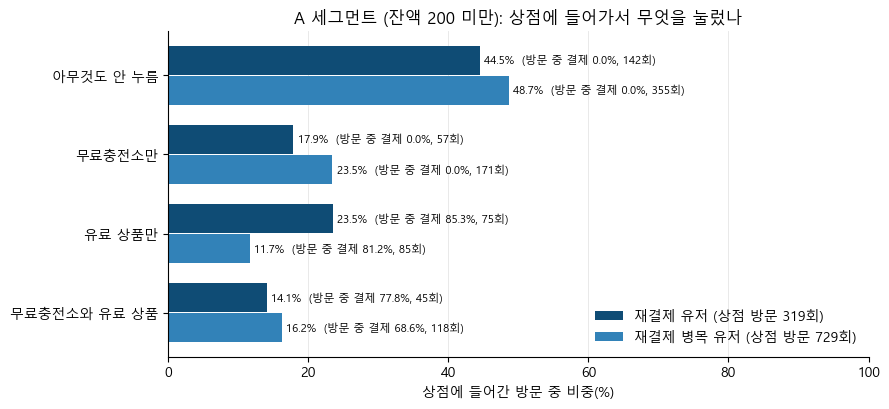

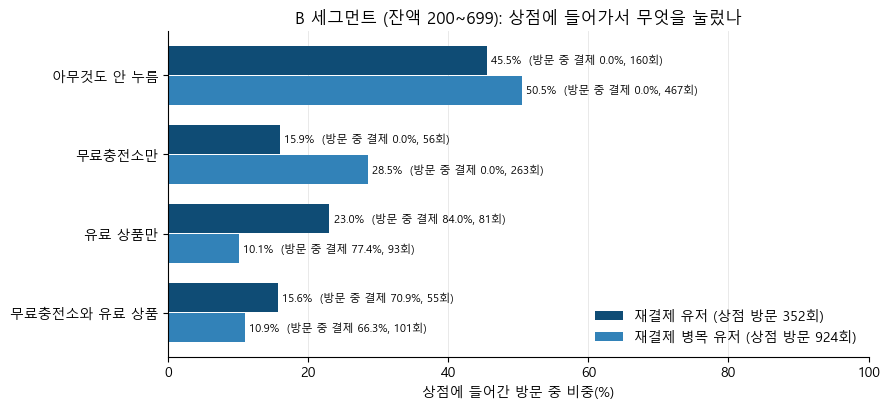

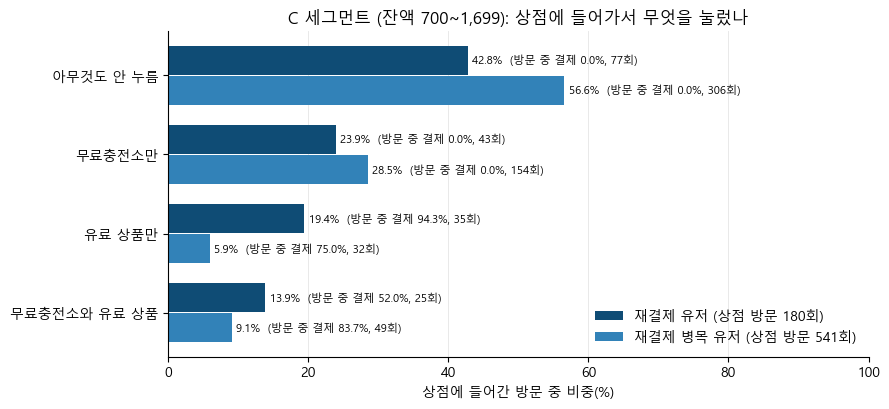

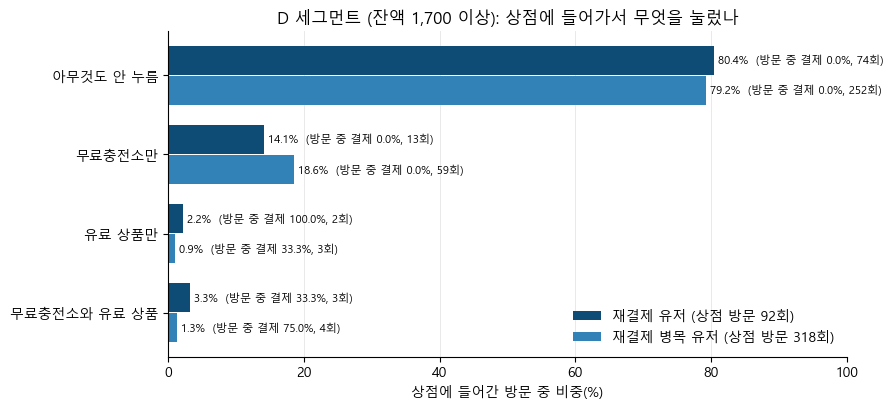

In [47]:
# 6-2 그래프: 세그먼트마다 상점 안에서 누른 것별 방문 비중 (괄호 = 방문 중 결제 비율, 방문 수)
for seg in SEG8:
    y = np.arange(len(SHOP_KINDS)); h = 0.38
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for i, (g, col) in enumerate([(GROUPS7[0], C1), (GROUPS7[1], C2)]):
        s = pd.DataFrame({k: shop9[(seg, g, k)] for k in ['방문', '비중(%)', '방문 중 결제(%)']})   # 열 이름 순서가 가나다순이 아니라 전체 키로 꺼냄
        ax.barh(y + (i - 0.5) * h, s['비중(%)'], h * 0.95, color=col,
                label=f"{g} (상점 방문 {int(meta9.loc[(seg, g), '상점 방문']):,}회)")
        for yy, x, p, n in zip(y + (i - 0.5) * h, s['비중(%)'], s['방문 중 결제(%)'], s['방문']):
            ax.text(x + 0.6, yy, f'{x:.1f}%  (방문 중 결제 {p:.1f}%, {int(n)}회)', va='center', fontsize=8)
    ax.set_yticks(y); ax.set_yticklabels(SHOP_KINDS); ax.invert_yaxis(); ax.set_xlim(0, 100)
    ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='x', color='#E5E5E5', lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel('상점에 들어간 방문 중 비중(%)')
    ax.set_title(f"{seg.split(': ')[0]} 세그먼트 (잔액 {seg.split(': ')[1]}): 상점에 들어가서 무엇을 눌렀나")
    ax.legend(frameon=False, loc='lower right')
    plt.tight_layout(); plt.show()

- A~C에서 재결제 병목 유저는 '유료 상품만' 누른 방문이 재결제 유저의 절반 이하임(A: 23.5% 대 11.7%, B: 23.0% 대 10.1%, C: 19.4% 대 5.9%). 유료 상품을 누른 방문은 재결제 유저·재결제 병목 유저 모두 절반 넘게 결제로 이어지므로(D를 빼면 52.0~94.3%), 상점에 들어온 뒤 유료 상품까지 누르는지에서 두 그룹이 갈림
- B(200~699)에서 무료충전소만 누르고 나간 방문은 재결제 병목 유저 28.5%, 재결제 유저 15.9%로 12.6%p 차이가 남. 네 세그먼트 중 이 차이가 가장 큼(A: 5.6%p, C: 4.6%p, D: 4.4%p). 무료충전소만 누른 방문에서는 결제가 없음
- C(700~1,699)는 아무것도 누르지 않고 나간 방문의 차이가 가장 큼(재결제 병목 유저 56.6% 대 재결제 유저 42.8%)
- D(1,700 이상)는 재결제 유저·재결제 병목 유저 모두 상점 방문의 약 80%가 아무것도 누르지 않음(80.4%, 79.2%). 유료 상품을 누른 방문은 재결제 유저 5회, 재결제 병목 유저 7회뿐임
- 세그먼트·그룹별 상점 방문이 92~924회라 칸마다 수십 회로 계산한 비율이 있음. 특히 C·D의 유료 상품 칸은 방문 수가 작아 방문 중 결제 비율이 흔들림

### 6-3. 재결제 유저가 처음 재결제할 때 산 상품
- 재결제 유저(7일 관찰 대상 중 재결제한 사람)의 첫 재결제 상품을 셈. 첫 재결제 = 첫 결제 후 10분이 지나고 7일 안에 한 결제 중 가장 빠른 결제
- 첫 결제를 특가(heart.777)로 했는지 정가 상품으로 했는지로 나눔(부록 C-8과 같은 구분)
- 부록 B-2는 8/10까지의 전체 결제를 순번으로 나눈 표라, 재결제한 사람이 처음 재결제할 때 고른 상품과는 다름
- 아래 표의 heart.777 가격은 0-2의 추정 판매가임

In [48]:
g1b = buyer[buyer.obs7 & buyer.re7][['user_id', 'first_product']].copy()
re_pay_g1 = pay[(pay.seq > 1) & (pay.gap > QUICK_GAP) & (pay.gap <= RE_WINDOW)]     # 재결제에 해당하는 결제 (pay는 유저·시각 순)
g1b['re_product'] = g1b.user_id.map(re_pay_g1.groupby('user_id').productId.first())
g1b['re_month'] = g1b.user_id.map(re_pay_g1.groupby('user_id').created_at.first()).dt.month.astype(str) + '월'
g1b['start'] = np.where(g1b.first_product == 'heart.777', '특가로 시작', '정가로 시작')
assert g1b.re_product.notna().all()

RE_ORDER = ['heart.1000', 'heart.200', 'heart.4000', 'heart.777']
def re_share(d, rows):
    # 행마다 첫 재결제 상품 비중(%)과 인원
    t = pd.crosstab(d[rows], d.re_product).reindex(columns=RE_ORDER, fill_value=0)
    pct = t.div(t.sum(axis=1), axis=0).mul(100).round(1)
    pct.insert(0, '인원', t.sum(axis=1))
    pct.columns = ['인원'] + [f'{p} ({PRICE[p]:,}원)' for p in RE_ORDER]
    return pct

re_tbl = re_share(g1b, 'start').reindex(['특가로 시작', '정가로 시작'])
re_tbl.loc['재결제 유저 전체'] = re_share(g1b.assign(all='재결제 유저 전체'), 'all').iloc[0]
re_tbl = re_tbl.astype({'인원': int})
print(f'재결제 유저 {len(g1b):,}명의 첫 재결제 상품 비중(%)')
display(re_tbl.rename_axis('첫 결제'))

print('\n첫 재결제가 일어난 달별 상품 비중(%)')
display(re_share(g1b, 're_month').astype({'인원': int}).rename_axis('첫 재결제 달'))

# 참고: 5장 세그먼트별 재결제 유저 (핵클 기간 잔액이 찍힌 재결제 유저만)
g1s = g1b.merge(p9[p9.grp == GROUPS7[0]].seg.astype(str).rename('seg'), left_on='user_id', right_index=True)
print('\n참고: 5장 세그먼트별 재결제 유저의 첫 재결제 상품 비중(%)')
display(re_share(g1s, 'seg').reindex(SEG8).astype({'인원': int}).rename_axis('세그먼트'))

재결제 유저 10,888명의 첫 재결제 상품 비중(%)


,인원,"heart.1000 (2,900원)",heart.200 (900원),"heart.4000 (9,900원)","heart.777 (1,900원)"
첫 결제,,,,,
특가로 시작,9562,49.1,47.1,3.6,0.2
정가로 시작,1326,28.4,10.9,8.1,52.6
재결제 유저 전체,10888,46.6,42.7,4.2,6.6



첫 재결제가 일어난 달별 상품 비중(%)


,인원,"heart.1000 (2,900원)",heart.200 (900원),"heart.4000 (9,900원)","heart.777 (1,900원)"
첫 재결제 달,,,,,
5월,10179,46.7,42.4,4.3,6.7
6월,640,44.5,47.0,3.0,5.5
7월,68,45.6,50.0,2.9,1.5
8월,1,100.0,0.0,0.0,0.0



참고: 5장 세그먼트별 재결제 유저의 첫 재결제 상품 비중(%)


,인원,"heart.1000 (2,900원)",heart.200 (900원),"heart.4000 (9,900원)","heart.777 (1,900원)"
세그먼트,,,,,
A: 200 미만,1038,45.9,46.1,3.4,4.7
B: 200~699,1647,46.9,42.3,3.4,7.4
"C: 700~1,699",1217,48.6,41.0,4.5,5.8
"D: 1,700 이상",1275,48.7,38.7,6.2,6.4


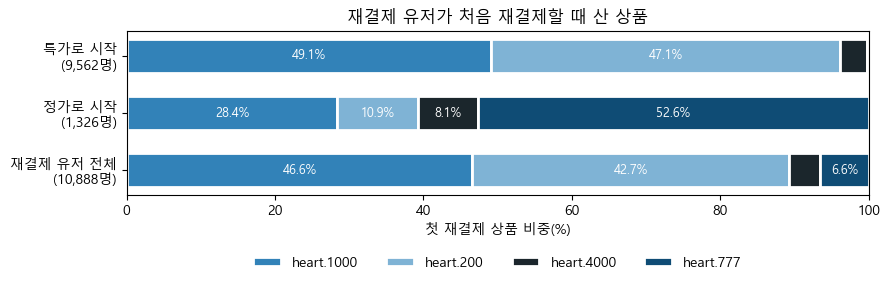

In [49]:
# 6-3 그래프: 첫 결제별 재결제 유저의 첫 재결제 상품 비중 (색은 0-4의 PROD_COLORS)
fig, ax = plt.subplots(figsize=(9, 3.2))
left = np.zeros(len(re_tbl))
for p in RE_ORDER:
    v = re_tbl[f'{p} ({PRICE[p]:,}원)'].values
    ax.barh(re_tbl.index, v, left=left, color=PROD_COLORS[p], edgecolor='white', linewidth=2, height=0.6, label=p)
    for i, (l, x) in enumerate(zip(left, v)):
        if x >= 6:
            ax.text(l + x / 2, i, f'{x:.1f}%', ha='center', va='center', color='white', fontsize=9)
    left += v
ax.set_yticks(range(len(re_tbl))); ax.set_yticklabels([f'{i}\n({n:,}명)' for i, n in zip(re_tbl.index, re_tbl['인원'])])
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel('첫 재결제 상품 비중(%)'); ax.set_title('재결제 유저가 처음 재결제할 때 산 상품')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.3), frameon=False)
plt.tight_layout(); plt.show()

- 특가로 시작한 재결제 유저(9,562명)는 첫 재결제로 heart.1000(49.1%)과 heart.200(47.1%)을 거의 반씩 삼. heart.4000은 3.6%임
- 정가로 시작한 재결제 유저(1,326명)는 52.6%가 첫 재결제로 특가 heart.777을 삼. 정가 상품을 먼저 사고 나서 특가 상품을 산 경우로 보임
- 재결제 유저 전체로는 heart.1000 46.6%, heart.200 42.7%로 두 상품이 89.3%임. 하트가 모자랄 때 제안할 상품은 이 둘이 후보이고, 비율 차이가 작아 어느 쪽을 먼저 보여 줄지는 데이터로 정할 수 없음. A/B 테스트로 정할 대상임
- 재결제 유저의 첫 재결제는 93.5%(10,179명)가 5월에 일어남. 6·7월에도 heart.1000과 heart.200이 91.5%, 95.6%로 상품 구성은 같은 모양이지만, 인원이 640명, 68명으로 적음. 핵클 기간의 재결제 병목 유저에게 같은 상품 구성이 맞는지는 이 표로 확인할 수 없음
- 5장 세그먼트별 재결제 유저도 같은 모양임(heart.1000 45.9~48.7%, heart.200 38.7~46.1%). B(200~699)의 재결제 유저는 46.9%와 42.3%임

### 6-4. 받은 질문 하나에서 힌트를 몇 번째 글자까지 열었나
- 포인트 기록(`accounts_pointhistory`)의 힌트 지출을 받은 질문(`user_question_record_id`) 단위로 묶음. 5/18 가격 변경 뒤 힌트는 첫째 글자 200, 둘째 500, 셋째 1,000이라 지출 폭으로 몇 번째 글자인지 알 수 있음(5장 도입)
- 기간은 가격 변경 뒤 전체(5/18~8/10)와 핵클 기간(7/18~8/10)
- 포인트 기록은 투표 데이터가 있는 유저(약 5천 명)만 있음. 그래서 5장 세그먼트별 값이 아니라 이 표본 전체의 값임

In [50]:
ph9 = read_cols('accounts_pointhistory', ['delta_point', 'created_at', 'user_id', 'user_question_record_id'], parse_dates=['created_at'])
HINT_STEPS = [-200, -500, -1000]                                  # 첫째, 둘째, 셋째 글자
h9 = ph9[(ph9.created_at < DATA_END) & ph9.delta_point.isin(HINT_STEPS) & ph9.user_question_record_id.notna()]
print(f'힌트 지출(−200·−500·−1,000) 기록 {len(h9):,}건, 첫 기록 {h9.created_at.min()}')

rows = []
for label, lo in [('5/18~8/10', h9.created_at.min()), ('핵클 기간 7/18~8/10', HK_START)]:
    x = h9[h9.created_at >= lo]
    q = x.groupby(['user_question_record_id', 'delta_point']).size().unstack().reindex(columns=HINT_STEPS).notna()   # 질문마다 연 글자
    n1, n2, n3 = q[-200].sum(), q[-500].sum(), q[-1000].sum()
    rows.append({'기간': label, '사람': x.user_id.nunique(), '첫째(200P)를 연 질문': n1, '둘째(500P)까지 연 질문': n2,
                 '셋째(1,000P)까지 연 질문': n3, '둘째 ÷ 첫째(%)': n2 / n1 * 100, '셋째 ÷ 첫째(%)': n3 / n1 * 100,
                 '셋째 ÷ 둘째(%)': n3 / n2 * 100, '첫째 없이 둘째': int((q[-500] & ~q[-200]).sum()),
                 '둘째 없이 셋째': int((q[-1000] & ~q[-500]).sum())})
hint9 = pd.DataFrame(rows).set_index('기간')
display(hint9.round(1))
print('분석 대상 유저(base)가 아닌 사람의 힌트 지출:', int((~h9.user_id.isin(base.user_id)).sum()), '건')

힌트 지출(−200·−500·−1,000) 기록 27,566건, 첫 기록 2023-05-18 21:19:05


,사람,첫째(200P)를 연 질문,둘째(500P)까지 연 질문,"셋째(1,000P)까지 연 질문",둘째 ÷ 첫째(%),셋째 ÷ 첫째(%),셋째 ÷ 둘째(%),첫째 없이 둘째,둘째 없이 셋째
기간,,,,,,,,,
5/18~8/10,3316,20259,5973,1334,29.5,6.6,22.3,314,117
핵클 기간 7/18~8/10,157,183,103,46,56.3,25.1,44.7,35,10


분석 대상 유저(base)가 아닌 사람의 힌트 지출: 0 건


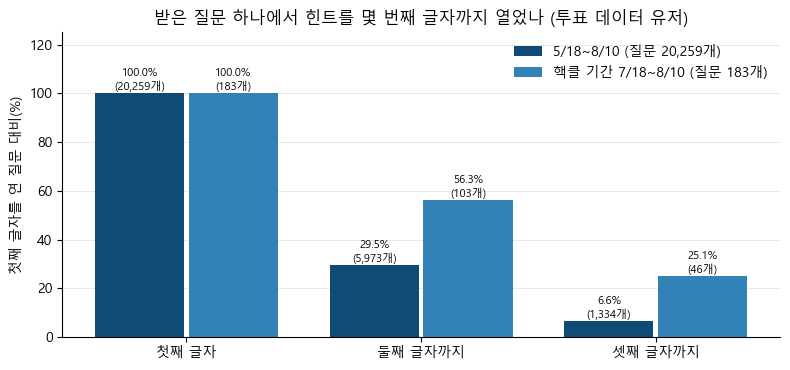

In [51]:
# 6-4 그래프: 첫째 글자를 연 질문을 100으로 둔 단계별 비율
steps = ['첫째(200P)를 연 질문', '둘째(500P)까지 연 질문', '셋째(1,000P)까지 연 질문']
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(3); w = 0.4
for i, (label, col) in enumerate(zip(hint9.index, [C1, C2])):
    n = hint9.loc[label, steps].astype(float).values
    r = n / n[0] * 100
    bars = ax.bar(x + (i - 0.5) * w, r, w * 0.95, color=col, label=f'{label} (질문 {int(n[0]):,}개)')
    for b_, v, k in zip(bars, r, n):
        ax.text(b_.get_x() + b_.get_width() / 2, v, f'{v:.1f}%\n({int(k):,}개)', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(['첫째 글자', '둘째 글자까지', '셋째 글자까지'])
ax.set_ylim(0, 125); ax.set_ylabel('첫째 글자를 연 질문 대비(%)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#E5E5E5', lw=0.6); ax.set_axisbelow(True)
ax.set_title('받은 질문 하나에서 힌트를 몇 번째 글자까지 열었나 (투표 데이터 유저)')
ax.legend(frameon=False, loc='upper right')
plt.tight_layout(); plt.show()

- 가격 변경 뒤(5/18~8/10) 첫째 글자를 연 질문 20,259개 중 둘째 글자까지 연 질문은 29.5%, 셋째 글자까지 연 질문은 6.6%임. 둘째를 연 질문 중 셋째까지 연 것은 22.3%임
- 단계마다 70~80%가 멈춤. 5장 구간 표처럼 한 질문만 놓고 보면 C(700~1,699)는 셋째 글자를 열 때 잔액이 모자라는데, 셋째 글자까지 여는 질문은 첫째의 6.6%뿐임. 그래서 한 질문 안에서 잔액이 모자라는 순간은 드묾. 여러 질문의 힌트를 이어서 열어 잔액이 모자라는 경우는 이 표로 알 수 없음
- 핵클 기간은 질문 183개(157명)로 작고, 둘째 56.3%, 셋째 25.1%로 가격 변경 뒤 전체보다 높음. 표본이 작아 방향만 참고함
- 둘째 글자 지출은 있는데 첫째가 없는 질문이 314개(핵클 기간 35개)임. 첫째 글자를 기간 전에 열었거나(가격 변경 전 −300 포함) 기록이 빠진 경우로 보이고, 이 표에서는 둘째까지 연 질문에 넣어 셈
- 부록 I은 가격 변경 뒤에 받은 투표만 셈. 힌트를 연 투표 18,895개 중 둘째 글자까지 연 투표는 27.9%(5,267개), 셋째 글자까지 연 투표는 5.7%(1,079개)임. 이 표는 힌트를 쓴 날로 기간을 나눠, 가격 변경 전에 받은 질문과 첫째 없이 둘째가 있는 질문까지 들어가 비율이 조금 높음. 두 기준 모두 셋째 글자까지 여는 질문이 드물다는 결론은 같음
- 포인트 기록은 투표 데이터가 있는 유저(이 기간 3,316명)만 있어 5장 세그먼트별 값이 아님

---
## 7. 결론

재결제가 끊긴 첫 결제자는 대부분 앱을 떠나지 않았음. 7일 안에 재결제하지 않은 46,983명 중 91.8%가 그 7일 동안 활동 기록이 있음(4-2). 핵클 기간 첫 결제자의 72.7%가 7일 안에 앱을 다시 켰지만, 상점에 다시 들어간 비율은 16.0%임(3-2). 재결제는 앱을 쓰지 않아서가 아니라, 상점에 들어가는 단계와 상점 안에서 끊김.

그래서 개선 대상을 재결제 병목 유저로 정함. 그중 핵클 기간에 방문 시작 잔액이 찍힌 18,205명을 하트 잔액으로 나눠 우선순위를 정함(5장). 힌트 가격은 첫째·둘째·셋째 글자가 200·500·1,000하트라, 세그먼트마다 하트가 모자라는 단계가 다름.

| 순위 | 세그먼트 | 하트가 모자라는 단계 | 방문 중 결제율 | 추가 결제자 | 개선 방향 |
|---|---|---|---|---|---|
| 1 | B (200~699) | 둘째 글자 | 2.6% | 155명 | 모자라는 순간 결제로 잇기, 상점 안 배치 바꾸기 |
| 2 | A (200 미만) | 첫째 글자 | 5.1% | 87명 | 상점에 온 뒤 결제로 마무리 |
| 3 | C (700~1,699) | 셋째 글자 | 1.4% | 103명 | 셋째 글자까지 쓰게 하기 |
| 4 | D (1,700 이상) | 한 질문 안에서는 모자라지 않음 | 0.1% | 9명 | 쌓인 하트를 쓰게 하기 |
| 별도 | 앱을 쓰지 않은 유저 (28,196명) | 잔액을 알 수 없음 | - | - | 앱으로 다시 불러오기 |

A 세그먼트는 추가 결제자가 C보다 적지만 방문 중 결제율이 5.1%로 가장 높아, 결제에 더 가까운 세그먼트로 보고 앞에 둠.

### 7-1. 1순위: B 세그먼트 (하트 잔액 200~699)

첫째 글자(200하트)는 열 수 있지만, 둘째 글자(500하트)를 열 때 하트가 모자라는 세그먼트임. 상점까지 오는 비율은 재결제 유저보다 행동마다 0.4~2.0%p 낮은 정도임(6-1). 차이가 큰 곳은 상점 안임.

- 무료충전소만 누르고 나간 방문이 28.5%로 재결제 유저(15.9%)보다 12.6%p 많음(6-2)
- 유료 상품만 누른 방문은 10.1%로 재결제 유저(23.0%)의 절반 이하임(6-2)

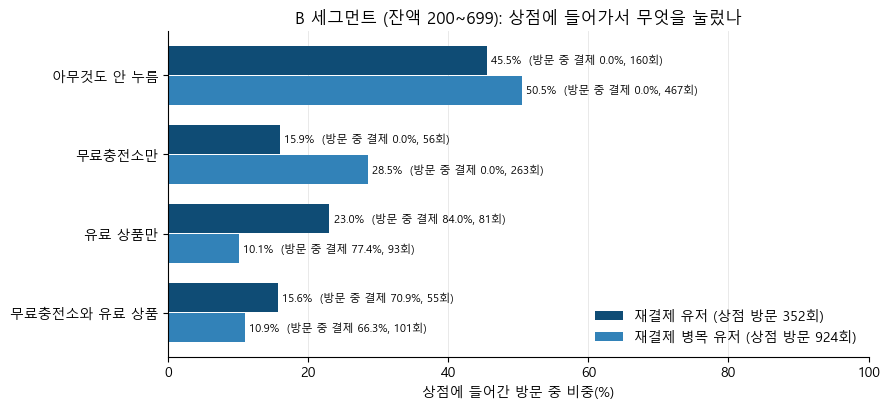

1. 하트가 모자라는 순간, 부족한 하트 수와 그만큼을 채울 상품을 함께 보여 주는 팝업
   - 둘째 글자를 열려다 하트가 모자라면 "하트 300개만 더 있으면 둘째 글자를 볼 수 있어요"처럼 부족한 양을 숫자로 알려 주고, 같은 화면에서 바로 결제할 수 있게 함
   - 보여 줄 상품은 이 세그먼트 재결제 유저가 처음 재결제할 때 산 상품을 따름. 1,000하트(2,900원) 46.9%, 200하트(900원) 42.3%로 두 상품이 대부분임(6-3)
   - 두 상품의 비율 차이가 작아, 어느 쪽을 먼저 보여 줄지는 A/B 테스트로 정함
2. 상점 안에서 유료 상품을 무료충전소보다 먼저 보여 주기
   - 유료 상품을 위에, 무료충전소를 아래에 두는 배치를 A/B 테스트함
   - 이 세그먼트에서 유료 상품을 누른 방문은 77.4%가 결제로 이어졌음(6-2). 그래서 유료 상품까지 누르게 하는 것이 목표임

재결제 유저가 처음 재결제할 때 산 상품 (6-3)

| 첫 결제 | 인원 | 1,000하트 (2,900원) | 200하트 (900원) | 4,000하트 (9,900원) | 특가 heart.777 (1,900원) |
|---|---|---|---|---|---|
| 특가로 시작 | 9,562 | 49.1% | 47.1% | 3.6% | 0.2% |
| 정가로 시작 | 1,326 | 28.4% | 10.9% | 8.1% | 52.6% |
| 재결제 유저 전체 | 10,888 | 46.6% | 42.7% | 4.2% | 6.6% |


### 7-2. 2순위: A 세그먼트 (하트 잔액 200 미만)

첫째 글자(200하트)부터 열 수 없는 세그먼트임. 상점에 간 사람(21.6%)이 포인트를 쓴 사람(20.2%)보다 많은 것은 네 세그먼트 중 여기뿐임(5-1).

상점까지 오는 경로는 재결제 유저와 비슷함.

- 열 개 행동 중 아홉 개에서 재결제 유저와 차이가 ±2%p 안임(6-1)
- 받은 질문을 연 뒤 상점에 들어간 비율은 12.24%로 재결제 유저(12.60%)와 거의 같음. 같은 세그먼트 전체 방문(6.68%)의 1.8배임(6-1)

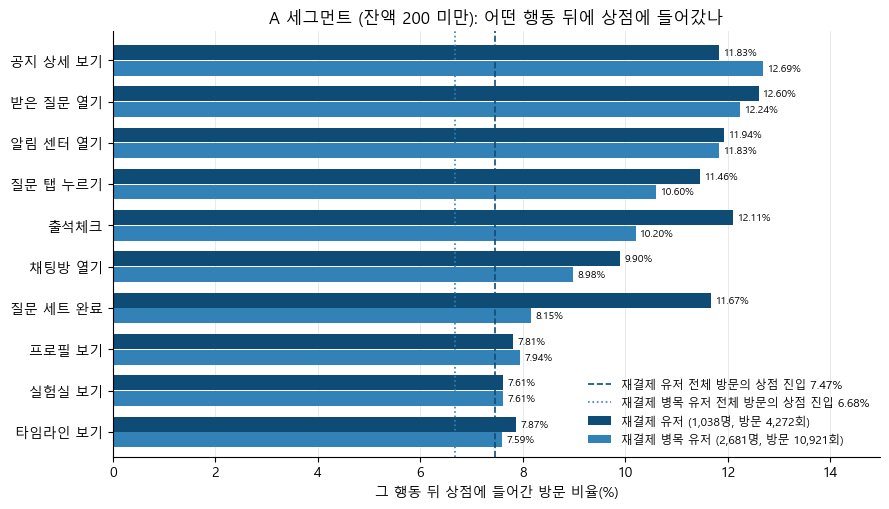

차이는 상점 안에서 남. 유료 상품만 누른 방문이 11.7%로 재결제 유저(23.5%)의 절반임(6-2). 따라서 상점에 온 사람이 결제까지 마치게 하는 것이 핵심임.

- 상점 첫 화면 맨 위에 200하트(900원)를 두고 "받은 질문 첫째 글자 바로 열기"를 함께 표시하는 안을 A/B 테스트함
- 200하트는 첫째 글자 가격과 같음. 받은 질문을 열다 상점에 온 사람에게 이 상품으로 무엇을 할 수 있는지 바로 보여 줌


### 7-3. 3순위: C 세그먼트 (하트 잔액 700~1,699)

첫째·둘째 글자(합계 700하트)는 열 수 있고, 셋째 글자(1,000하트)를 열 때 모자라는 세그먼트임. 이 세그먼트의 재결제 병목 유저는 받은 질문을 연 뒤 상점에 들어간 비율이 6.37%로 재결제 유저(8.43%)와 차이가 가장 큼(6-1).

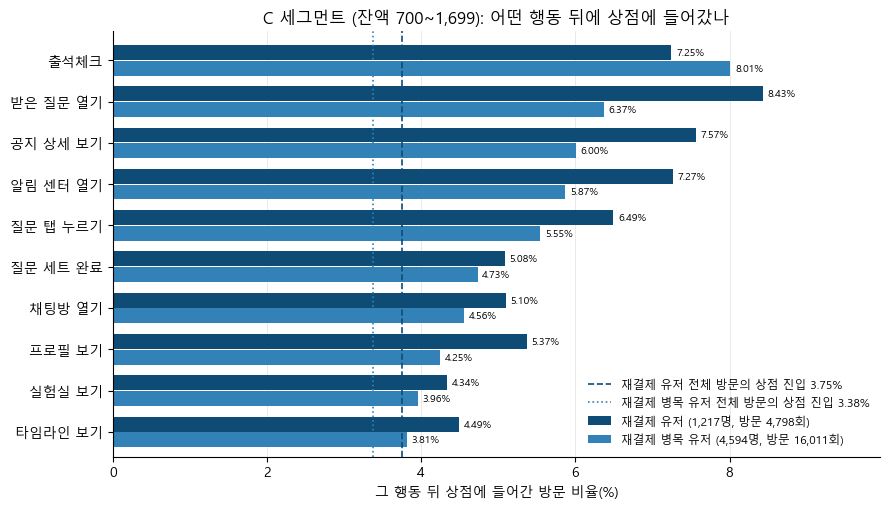

그런데 셋째 글자까지 여는 질문이 드물어, 하트가 모자라는 순간 자체가 잘 오지 않음.

| 기간 | 첫째 글자(200하트)를 연 질문 | 둘째(500하트)까지 연 질문 | 셋째(1,000하트)까지 연 질문 |
|---|---|---|---|
| 5/18~8/10 | 20,259개 | 5,973개 (첫째의 29.5%) | 1,334개 (첫째의 6.6%) |
| 핵클 기간 7/18~8/10 | 183개 | 103개 (56.3%) | 46개 (25.1%) |

- 이 표는 투표 데이터 유저 3,316명의 값이라 C 세그먼트만의 값은 아님(6-4)
- 둘째 글자를 열 때 500하트를 더 내면 셋째 글자까지 한 번에 여는 묶음 열기를 A/B 테스트함. 둘째와 셋째를 따로 열면 1,500하트(500+1,000)인데 묶음으로는 1,000하트에 열 수 있음. 셋째 글자를 싸게 열게 해서, 둘째에서 멈추던 질문에 하트를 더 쓰게 하는 것이 목적임
- 원래 셋째 글자까지 열던 질문(첫째의 6.6%)은 묶음으로 열면 하트를 덜 쓰게 됨(1,500하트 → 1,000하트). 그래서 A/B 테스트에서는 1인당 하트 사용량이 실제로 늘었는지, 하트가 모자라 상점에 들어간 비율이 올랐는지를 함께 봐야 함


### 7-4. 4순위: D 세그먼트 (하트 잔액 1,700 이상)

한 질문의 세 글자를 모두 열어도(1,700하트) 모자라지 않는 세그먼트임.

- 인원은 5,721명으로 가장 많지만, 상점에 간 사람 4.9%, 방문 중 결제율 0.1%임(5-1)
- 상점에 와도 약 80%는 아무것도 누르지 않음(6-2)
- 재결제 유저도 이 세그먼트에서는 0.2%만 결제함. 지금 구조에서는 하트를 살 이유가 거의 없음

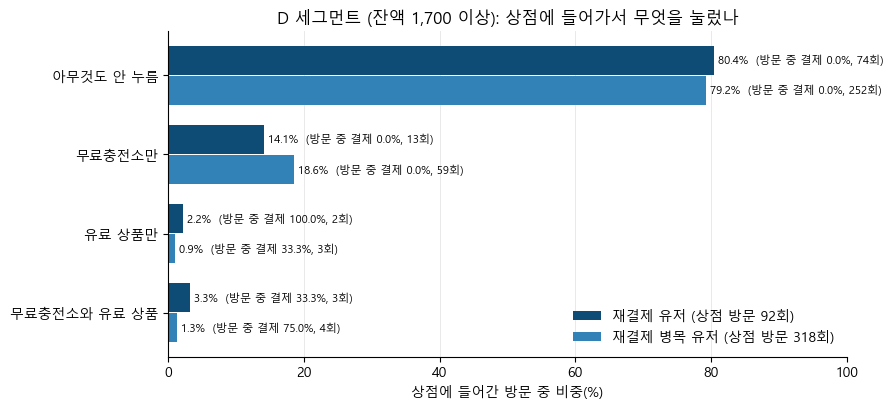

방향은 쌓인 하트를 쓰게 해서 A·B 세그먼트로 내려보내는 것임.

- 하트로 사는 꾸밈 상품을 추가해 쌓인 하트를 쓸 곳을 만듦. 지금 하트를 쓰는 곳은 힌트뿐이라, 한 질문의 세 글자를 모두 열 만큼 하트가 있는 유저는 상점에 와도 하트를 살 이유가 없음
- 예: 프로필 아바타를 꾸미는 기능을 만들고 옷·배경·소품 같은 꾸밈 요소를 하트로 팖. 꾸민 아바타가 친구에게 보이게 하면 쌓인 하트를 쓸 곳이 생김. 하트를 쓰면 잔액이 줄어 A·B 세그먼트로 내려오고, 그때부터 하트를 살 이유가 생김
- 이 안은 데이터 근거가 없는 가설임. 꾸밈 상품의 수요와, 하트를 쓴 유저가 실제로 하트를 사는지는 이번 데이터로 확인할 수 없음


### 7-5. 별도 대상: 앱을 쓰지 않은 유저

이탈 유저 3,847명과 핵클 기간에 방문이 없는 재결제 병목 유저 24,349명임. 핵클 기간의 하트 잔액이 없어 A~D 세그먼트로 나눌 수 없고, 상점 안 개선안도 앱에 돌아온 뒤에야 적용할 수 있으므로 앱으로 다시 불러오는 것이 먼저임.

- 7월에는 특정한 날 저녁 한 시간(18~21시)에 한두 달 쉬던 유저가 몰려 첫 결제와 복귀 구매를 함께 했음(부록 F)
- 이때 결제 직전 30분 안에 알림 센터를 연 비율은 73.7%로, 같은 기간의 그 밖의 결제(56.5%)보다 17.2%p 높음(부록 F). 운영 기록이 없어 추정이지만, 앱 안 알림이나 공지가 복귀의 계기가 될 수 있다는 단서임

- 한두 달 결제가 없는 첫 결제자에게, 7월에 결제가 몰린 저녁 18~21시에 앱 푸시를 보내 받은 질문이나 새 공지를 확인하러 들어오게 함
- 푸시로 돌아온 유저는 그때의 하트 잔액으로 A~D 세그먼트에 넣어 7-1~7-4의 개선안을 적용함
- 효과는 푸시를 보낸 군과 보내지 않은 군의 7일 안 앱 복귀율로 확인함

### 7-6. 확인 방법과 한계

- 추가 결제자는 재결제 병목 유저가 같은 세그먼트 재결제 유저 수준에 이른다고 가정한 값이라 기대 효과가 아님. 재결제 유저는 원래 더 사는 사람일 수 있음. 개선안의 효과는 A/B 테스트로 확인함
- 6-2의 세그먼트·그룹별 상점 방문은 92~924회뿐이라, 칸에 따라 비율이 흔들릴 수 있음
- 무료충전소는 핵클의 상품 이름으로만 확인했음. 누른 뒤 실제로 하트가 늘었는지는 확인하지 못함
- 힌트 가격(200·500·1,000)은 포인트 기록의 감소 폭에서 찾은 값임. 이 결론에서는 잔액과 가격을 모두 하트로 적었지만, 하트 1개가 힌트 1포인트와 같은지는 직접 확인하지 않음
- 이탈 유저와, 핵클 기간에 방문이 없는 재결제 병목 유저 24,349명은 하트 잔액이 없어 A~D 세그먼트로 나눌 수 없음. 앱으로 다시 불러오는 안은 7-5에 따로 적음

---
## 부록

본문(0~7장)의 결론에 직접 쓰지 않았지만 분석 과정에서 확인한 내용과, 기준을 정한 근거를 모음. 본문 셀을 모두 실행한 뒤 이어서 실행함.

최종 보고서에는 분량 제한으로 부록을 다섯 개(A~E)만 실었음. 오른쪽 열은 같은 내용을 담은 보고서 부록이고, -는 보고서에 따로 싣지 않은 부록임.

| 부록 | 내용 | 보고서 부록 |
|---|---|---|
| 준비 | 초기 친구 요청 수 붙이기 (부록 C·D·H가 씀) | - |
| A | 재결제 기준(관찰 기간 7일, 10분 안 연속 결제 제외)을 정한 근거 | A |
| B | 결제 구성 보충 (주별 결제를 첫 결제와 이후 결제로 나누기, 결제 순서별 상품) | - |
| C | 재결제 유저 특성 (가입 시기, 성별, 학교·학년, 지역, 초기 친구 요청 수, 첫 결제 상품) | - |
| D | 재결제에 영향을 주는 조건 (로지스틱 회귀, 피처 중요도, 첫 결제 주 차이의 원인, 힌트 가격 변경) | B |
| E | 상점 재방문과 상점 진입 보충 (핵클 기간 첫 결제자의 상점 재방문, 결제 경험자 전체의 상점 진입 경로와 상점 안 행동) | - |
| F | 7월 복귀: 계기가 있으면 결제 경험자도 다시 산다 | C |
| G | 세 그룹 보충 (같은 반 친구 활동별 구성, 그룹 기준 확인) | D |
| H | 첫 결제 분석 | - |
| I | 힌트 기능 확인 (힌트를 쓴 사람과 글자를 여는 순서, 5장 세그먼트 경계의 전제) | E |

### 부록 준비. 초기 친구 요청 수 붙이기: `req_1h`

- 부록 C·D·H가 쓰는 초기 친구 요청 수를 `base`, `buyer`, `rb`에 붙임
- `accounts_friendrequest`에서 데이터 끝 전에 만들어진 요청만 씀. 파일이 커서(약 1.1GB) 필요한 컬럼만 읽음
- 요청 1건을 보낸 사람과 받은 사람에게 1건씩 세고, 각자의 가입 시각부터 1시간 안에 만들어진 요청만 셈 (`created_at` 기준, 상태 무관)
- 요청이 없는 유저는 0. 보낸 요청 수(`sent_1h`)와 받은 요청 수(`recv_1h`)도 따로 붙임 (부록 H-3에서 사용)
- 초기 친구 요청 수 구간(`req_bin`)도 함께 붙임

In [52]:
fr = read_cols('accounts_friendrequest', ['send_user_id', 'receive_user_id', 'created_at'], parse_dates=['created_at'])
fr = fr[fr.created_at < DATA_END]
side = pd.concat([fr[['send_user_id', 'created_at']].rename(columns={'send_user_id': 'user_id'}).assign(sent=np.int8(1)),
                  fr[['receive_user_id', 'created_at']].rename(columns={'receive_user_id': 'user_id'}).assign(sent=np.int8(0))],
                 ignore_index=True)                                  # sent = 1이면 보낸 요청, 0이면 받은 요청
del fr

side = side.merge(base[['user_id', 'signup_at']], on='user_id', how='inner')
in_1h = (side.created_at >= side.signup_at) & (side.created_at < side.signup_at + REQ_WINDOW)
cnt = side[in_1h].groupby('user_id').sent.agg(['size', 'sum']).rename(columns={'size': 'req_1h', 'sum': 'sent_1h'})
cnt['recv_1h'] = cnt.req_1h - cnt.sent_1h
del side

REQ_COLS = ['req_1h', 'sent_1h', 'recv_1h']
base = base.drop(columns=REQ_COLS, errors='ignore').merge(cnt, on='user_id', how='left')
base[REQ_COLS] = base[REQ_COLS].fillna(0).astype(int)
buyer = buyer.drop(columns=REQ_COLS, errors='ignore').merge(base[['user_id'] + REQ_COLS], on='user_id', how='left')
print(f'가입 후 1시간 안에 요청이 1건 이상인 유저: {(base.req_1h > 0).mean():.1%} / 중앙값 {base.req_1h.median():.0f}건')

# 초기 친구 요청 수 구간 (부록 C·D)
REQ_BINS = [-1, 0, 4, 9, 19, 49, np.inf]
REQ_LABELS = ['0건', '1~4건', '5~9건', '10~19건', '20~49건', '50건 이상']
base['req_bin'] = pd.cut(base.req_1h, REQ_BINS, labels=REQ_LABELS)
req_map = base.set_index('user_id')
for t in (buyer, rb):
    for col in REQ_COLS:
        t[col] = t.user_id.map(req_map[col]).astype(int)
    t['req_bin'] = pd.Categorical(t.user_id.map(req_map.req_bin), categories=REQ_LABELS, ordered=True)
del req_map

가입 후 1시간 안에 요청이 1건 이상인 유저: 92.4% / 중앙값 12건


---
## 부록 A. 재결제 기준을 정한 근거

### A-1. 재결제 관찰 기간을 7일로 정한 근거

관찰 기간을 길게 잡으면 재결제를 더 많이 잡지만, 데이터 끝(8/10)까지 그 기간이 지나야 하므로 최근 첫 결제자를 빼야 함. 두 가지를 확인함.

1. 7일이 재결제를 얼마나 잡는지: 첫 결제 후 30일을 볼 수 있는 첫 결제자(첫 결제가 7/11 이전)를 대상으로, 30일 안에 재결제한 사람이 첫 결제 후 며칠 안에 재결제했는지를 누적 비율로 봄
2. 관찰 기간을 바꾸면 결론이 달라지는지: 관찰 기간을 3·7·14·30일로 바꿔 첫 결제 주별 재결제율과 대상 인원을 비교함

- 재결제 정의는 0장과 같음(첫 결제 후 10분이 지난 결제). 관찰 기간만 바꿈
- 기간마다 대상은 첫 결제가 (데이터 끝 − 관찰 기간) 전인 첫 결제자임
- 핵클 기간 첫 결제자는 3장 퍼널 분석에 쓸 수 있는 인원(첫 결제가 7/18 이후인 대상)임

30일 관찰 대상(첫 결제 7/11 이전): 56,905명 / 30일 안 재결제자 12,165명 (21.4%)


,재결제자,30일 안 재결제자 대비(%),14일 안 재결제자 대비(%)
첫 결제 후 기간,,,
1일 안,6103,50.2,52.0
3일 안,9112,74.9,77.6
7일 안,10836,89.1,92.3
14일 안,11745,96.5,100.0
21일 안,12043,99.0,NaN
30일 안,12165,100.0,NaN


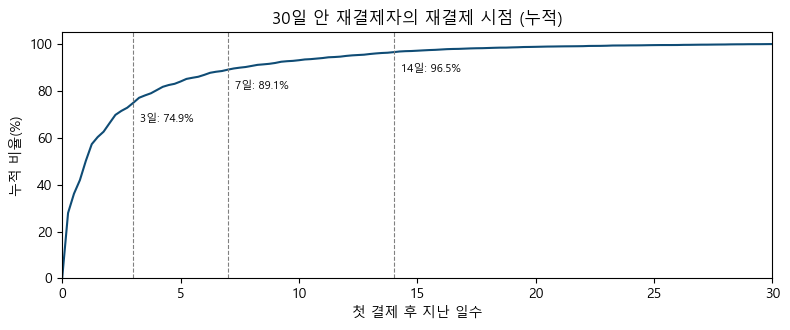

In [53]:
# 유저별로 첫 결제 후 10분이 지난 첫 번째 결제까지 걸린 시간 (없으면 NaT)
next_gap = pay[(pay.seq > 1) & (pay.gap > QUICK_GAP)].groupby('user_id').gap.min()

# 1) 30일을 볼 수 있는 첫 결제자 중 30일 안 재결제자의 재결제 시점
b30 = buyer[buyer.first_at < DATA_END - pd.Timedelta(days=30)].copy()
b30['next_gap'] = b30.user_id.map(next_gap)
re30 = b30[b30.next_gap <= pd.Timedelta(days=30)]
n14 = int((re30.next_gap <= pd.Timedelta(days=14)).sum())
print(f'30일 관찰 대상(첫 결제 7/11 이전): {len(b30):,}명 / 30일 안 재결제자 {len(re30):,}명 ({len(re30) / len(b30):.1%})')

cover = []
for d in [1, 3, 7, 14, 21, 30]:
    n = int((re30.next_gap <= pd.Timedelta(days=d)).sum())
    cover.append({'첫 결제 후 기간': f'{d}일 안', '재결제자': n,
                  '30일 안 재결제자 대비(%)': round(n / len(re30) * 100, 1),
                  '14일 안 재결제자 대비(%)': round(n / n14 * 100, 1) if d <= 14 else np.nan})
display(pd.DataFrame(cover).set_index('첫 결제 후 기간'))

days = np.arange(0, 30.01, 0.25)
cum = [(re30.next_gap <= pd.Timedelta(days=x)).mean() * 100 for x in days]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(days, cum, color=C1)
for d in [3, 7, 14]:
    v = (re30.next_gap <= pd.Timedelta(days=d)).mean() * 100
    ax.axvline(d, color='gray', linestyle='--', linewidth=0.8)
    ax.annotate(f'{d}일: {v:.1f}%', (d, v), textcoords='offset points', xytext=(5, -14), fontsize=8)
ax.set_xlim(0, 30); ax.set_ylim(0, 105)
ax.set_title('30일 안 재결제자의 재결제 시점 (누적)'); ax.set_xlabel('첫 결제 후 지난 일수'); ax.set_ylabel('누적 비율(%)')
plt.tight_layout(); plt.show()

- 첫 결제가 7/11 이전인 56,905명 중 12,165명(21.4%)이 30일 안에 재결제함
- 그중 50.2%가 1일 안, 74.9%가 3일 안, 89.1%가 7일 안, 96.5%가 14일 안에 재결제함. 7일 기준은 30일 안 재결제의 89.1%, 14일 안 재결제의 92.3%를 잡음
- 3일로 줄이면 30일 안 재결제의 25.1%를 놓침. 7일에서 14일로 늘려도 더 잡는 재결제는 909명(30일 안 재결제의 7.4%)임

,첫 결제 마감,대상 첫 결제자,첫 결제자 중 비율(%),핵클 기간 첫 결제자,재결제율(%),0주 재결제율(%),4주 재결제율(%),4주 ÷ 0주
관찰 기간,,,,,,,,
3일,08/07,58205,99.9,961,15.8,17.2,5.0,0.29
7일,08/03,57871,99.3,627,18.8,20.4,7.1,0.35
14일,07/27,57686,99.0,442,20.5,22.4,7.6,0.34
30일,07/11,56905,97.7,0,21.4,23.4,8.8,0.38


3일             7일            14일            30일        
              첫 결제자 재결제율(%)  첫 결제자 재결제율(%)  첫 결제자 재결제율(%)  첫 결제자 재결제율(%)
0주 (05/14~)   30035    17.2  30035    20.4  30035    22.4  30035    23.4
1주 (05/21~)   16879    17.3  16879    20.7  16879    22.0  16879    22.3
2주 (05/28~)    7207    11.7   7207    13.9   7207    14.9   7207    15.4
3주 (06/04~)    1682     6.8   1682     8.3   1682     9.2   1682     9.8
4주 (06/11~)     536     5.0    536     7.1    536     7.6    536     8.8
5주 (06/18~)     254     5.5    254     6.3    254     6.7    254     9.1
6주 (06/25~)     110     2.7    110     3.6    110     5.5    110     6.4
7주 (07/02~)      68     1.5     68     1.5     68     1.5     68     1.5
8주 (07/09~)     422     7.1    422     8.5    422     9.2    134    10.4
9주 (07/16~)     323     4.0    323     5.3    323     5.6   <NA>     NaN
10주 (07/23~)    278     3.2    278     3.6    170     5.9   <NA>     NaN
11주 (07/30~)    237     4.2     77     2.6   <NA>     NaN   <NA>     NaN
12주 (08/06~)    174     5.7   <NA>     NaN   <NA>     NaN   <NA>     NaN

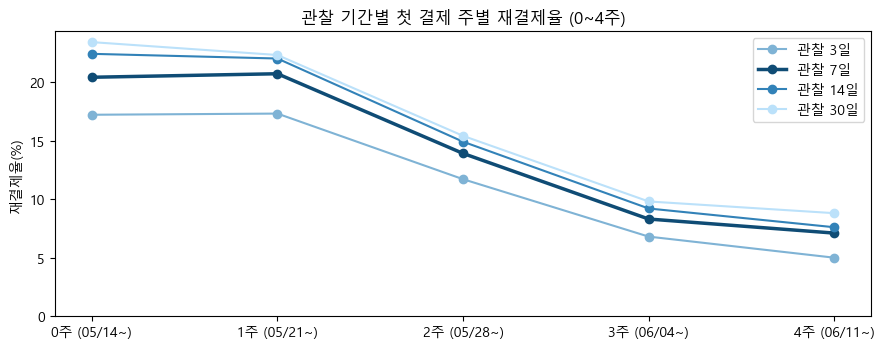

In [54]:
# 2) 관찰 기간별 대상 인원과 첫 결제 주별 재결제율
summary_rows, by_week = [], {}
for d in [3, 7, 14, 30]:
    W = pd.Timedelta(days=d)
    elig = buyer[buyer.first_at < DATA_END - W].copy()
    elig['re'] = elig.user_id.map(next_gap) <= W
    g = elig.groupby('first_week').re.agg(['size', 'mean'])
    by_week[(f'{d}일', '첫 결제자')] = g['size']
    by_week[(f'{d}일', '재결제율(%)')] = (g['mean'] * 100).round(1)
    summary_rows.append({'관찰 기간': f'{d}일', '첫 결제 마감': f'{(DATA_END - W - pd.Timedelta(seconds=1)):%m/%d}',
                         '대상 첫 결제자': len(elig), '첫 결제자 중 비율(%)': round(len(elig) / len(buyer) * 100, 1),
                         '핵클 기간 첫 결제자': int((elig.first_at >= HK_START).sum()),
                         '재결제율(%)': round(elig.re.mean() * 100, 1),
                         '0주 재결제율(%)': round(g.loc[0, 'mean'] * 100, 1), '4주 재결제율(%)': round(g.loc[4, 'mean'] * 100, 1)})
period_tbl = pd.DataFrame(summary_rows).set_index('관찰 기간')
period_tbl['4주 ÷ 0주'] = (period_tbl['4주 재결제율(%)'] / period_tbl['0주 재결제율(%)']).round(2)
display(period_tbl)

by_week = pd.DataFrame(by_week)
for d in ['3일', '7일', '14일', '30일']:
    by_week[(d, '첫 결제자')] = by_week[(d, '첫 결제자')].astype('Int64')       # 관찰할 수 없는 주는 빈칸
by_week.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in by_week.index]
display(by_week)

fig, ax = plt.subplots(figsize=(9, 3.6))
show = by_week.iloc[:5]                                          # 첫 결제자가 많은 0~4주만 그림
for d, c in zip(['3일', '7일', '14일', '30일'], ['#7FB3D5', C1, C2, C3]):
    ax.plot(show.index, show[(d, '재결제율(%)')], marker='o', color=c, label=f'관찰 {d}', linewidth=2.5 if d == '7일' else 1.5)
ax.set_title('관찰 기간별 첫 결제 주별 재결제율 (0~4주)'); ax.set_ylabel('재결제율(%)'); ax.set_ylim(0, None)
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

- 관찰 기간을 늘리면 재결제율이 3일 15.8%, 7일 18.8%, 14일 20.5%, 30일 21.4%로 오르지만 첫 결제 주별 하락 흐름은 같음. 4주 재결제율은 어느 기간에서도 0주의 0.29~0.38배임
- 대상 인원은 기간을 늘려도 크게 줄지 않음(7일 57,871명, 30일 56,905명). 첫 결제자 대부분이 5~6월에 몰려 있기 때문임
- 줄어드는 것은 최근 첫 결제자임. 핵클 기간 첫 결제자는 7일 기준 627명, 14일 기준 442명이고, 30일 기준으로는 0명이라 3장의 행동 분석을 할 수 없음
- 7일은 재결제의 89.1%를 잡으면서 핵클 기간 첫 결제자 627명을 남김. 14일은 30일 안 재결제를 7.4%p 더 잡는 대신 핵클 기간 첫 결제자가 약 30% 줄어들고(627 → 442명), 3일은 재결제의 4분의 1을 놓침. 이 비교를 근거로 재결제 관찰 기간을 7일로 둠

### A-2. 첫 결제 후 두 번째 결제까지 걸린 시간
- 대상: 7일 관찰 대상 중 8/10까지 두 번째 결제가 있는 유저
- 0장에서 10분 안의 결제를 연속 결제로 따로 본 근거가 되는 분포임. 두 번째 결제를 모두 재결제로 센 기존 기준과 비교한 결과는 부록 A-3에 있음

,유저,비율(%),누적 비율(%)
두 번째 결제까지 걸린 시간,,,
1분 안,2235,14.4,14.4
1~3분,1561,10.1,24.5
3~10분,935,6.0,30.5
10분~1시간,929,6.0,36.5
1시간~1일,4178,26.9,63.5
1~7일,4085,26.3,89.8
7일 넘게,1581,10.2,100.0


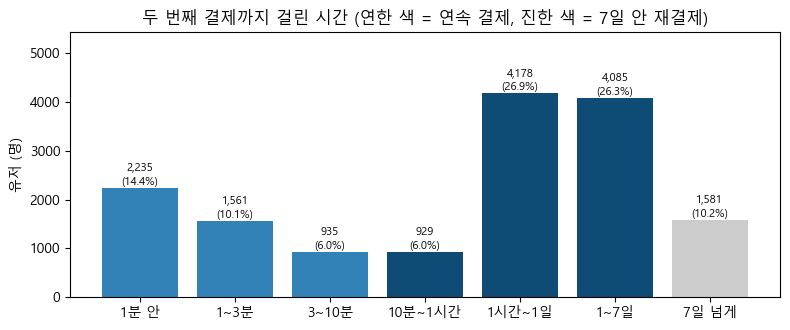

In [55]:
second = pay[(pay.seq == 2) & pay.user_id.isin(buyer.loc[buyer.obs7, 'user_id'])]
GAP_BINS = [pd.Timedelta(0), pd.Timedelta(minutes=1), pd.Timedelta(minutes=3), pd.Timedelta(minutes=10),
            pd.Timedelta(hours=1), pd.Timedelta(days=1), pd.Timedelta(days=7), pd.Timedelta(days=365)]
GAP_LABELS = ['1분 안', '1~3분', '3~10분', '10분~1시간', '1시간~1일', '1~7일', '7일 넘게']
g = pd.cut(second.gap, GAP_BINS, labels=GAP_LABELS, include_lowest=True).value_counts().reindex(GAP_LABELS)
gap_tbl = pd.DataFrame({'유저': g, '비율(%)': (g / g.sum() * 100).round(1), '누적 비율(%)': (g.cumsum() / g.sum() * 100).round(1)})
gap_tbl.index.name = '두 번째 결제까지 걸린 시간'
display(gap_tbl)

fig, ax = plt.subplots(figsize=(8, 3.4))
bars = ax.bar(gap_tbl.index, gap_tbl['유저'], color=[C2] * 3 + [C1] * 3 + ['#CCCCCC'])
for b, v, s in zip(bars, gap_tbl['유저'], gap_tbl['비율(%)']):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({s}%)', ha='center', va='bottom', fontsize=8)
ax.set_ylim(0, gap_tbl['유저'].max() * 1.3)
ax.set_title('두 번째 결제까지 걸린 시간 (연한 색 = 연속 결제, 진한 색 = 7일 안 재결제)'); ax.set_ylabel('유저 (명)')
plt.tight_layout(); plt.show()

- 두 번째 결제가 있는 15,504명 중 30.5%(4,731명)가 첫 결제 후 10분 안에 샀고, 1분 안이 14.4%로 가장 많음. 같은 방문에서 이어서 산 구매로 보고 재결제와 나눈 근거임
- 10분~1시간은 6.0%로 적고 1시간~7일이 53.2%임. 10분과 1시간 사이의 구매가 적어서 경계를 1시간으로 바꿔도 재결제율이 1%p 안팎만 바뀜(2-2)
- 10.2%는 첫 결제 후 7일이 지나서 두 번째 결제를 함. 7일 재결제율에서는 이 유저를 재결제자로 세지 않음

### A-3. 첫 결제 후 10분 안 결제(연속 결제)를 재결제에서 뺀 근거

이전까지 팀은 첫 결제 뒤 두 번째 결제가 있으면 재결제로 봤음(기존 기준). 0장 기준은 첫 결제 후 10분 안의 결제를 같은 방문에서 이어서 산 연속 결제로 보고 재결제에서 뺌. 두 기준을 같은 대상(7일 관찰 대상)으로 나란히 계산함.

| 구분 | 정의 |
|---|---|
| 기존 기준 재결제 | 첫 결제 후 7일 안에 결제가 하나라도 있음 (10분 안 포함) |
| 0장 기준 재결제 | 첫 결제 후 10분이 지나고 7일 안에 결제가 있음 |
| 10분 안 결제만 있음 | 기존 기준으로는 재결제자지만 0장 기준으로는 아닌 유저. 7일 동안 첫 결제 후 10분 안의 결제만 있음 |

- 두 번째 결제까지 걸린 시간의 분포는 부록 A-2에 있음

7일 관찰 대상 57,871명
재결제율: 기존 기준 24.1% / 0장 기준 18.8% / 10분 안 결제만 있음 5.2%
기존 기준 재결제자 13,923명 중 10분 안 결제만 있는 유저: 3,035명 (21.8%)
4주 ÷ 0주: 기존 기준 0.46 / 0장 기준 0.35


,첫 결제자,기존 기준 재결제율(%),0장 기준 재결제율(%),10분 안 결제만 있음(%)
0주 (05/14~),30035,25.5,20.4,5.1
1주 (05/21~),16879,25.8,20.7,5.1
2주 (05/28~),7207,19.1,13.9,5.2
3주 (06/04~),1682,14.5,8.3,6.2
4주 (06/11~),536,11.8,7.1,4.7
5주 (06/18~),254,11.4,6.3,5.1
6주 (06/25~),110,10.9,3.6,7.3
7주 (07/02~),68,10.3,1.5,8.8
8주 (07/09~),422,17.5,8.5,9.0
9주 (07/16~),323,17.3,5.3,12.1


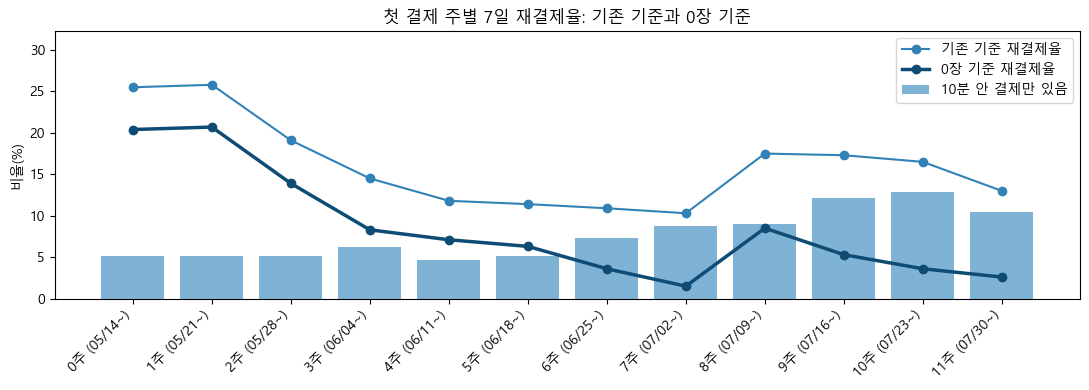

In [56]:
later = pay[pay.seq > 1]
old_users = set(later.loc[later.gap <= RE_WINDOW, 'user_id'])       # 기존 기준: 7일 안에 결제가 하나라도 있음
obs = buyer[buyer.obs7].copy()
obs['re_old'] = obs.user_id.isin(old_users)
obs['quick_only'] = obs.re_old & ~obs.re7                             # 10분 안 결제만 있음

n_old, n_qo = int(obs.re_old.sum()), int(obs.quick_only.sum())
print(f'7일 관찰 대상 {len(obs):,}명')
print(f'재결제율: 기존 기준 {obs.re_old.mean():.1%} / 0장 기준 {obs.re7.mean():.1%} / 10분 안 결제만 있음 {obs.quick_only.mean():.1%}')
print(f'기존 기준 재결제자 {n_old:,}명 중 10분 안 결제만 있는 유저: {n_qo:,}명 ({n_qo / n_old:.1%})')

def_cmp = obs.groupby('first_week').agg(n=('user_id', 'size'), old=('re_old', 'mean'), new=('re7', 'mean'), qo=('quick_only', 'mean'))
def_cmp[['old', 'new', 'qo']] = def_cmp[['old', 'new', 'qo']].mul(100).round(1)
def_cmp.columns = ['첫 결제자', '기존 기준 재결제율(%)', '0장 기준 재결제율(%)', '10분 안 결제만 있음(%)']
print(f"4주 ÷ 0주: 기존 기준 {def_cmp.loc[4, '기존 기준 재결제율(%)'] / def_cmp.loc[0, '기존 기준 재결제율(%)']:.2f}"
      f" / 0장 기준 {def_cmp.loc[4, '0장 기준 재결제율(%)'] / def_cmp.loc[0, '0장 기준 재결제율(%)']:.2f}")
def_cmp.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in def_cmp.index]
display(def_cmp)

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(def_cmp))
ax.bar(x, def_cmp['10분 안 결제만 있음(%)'], color='#7FB3D5', label='10분 안 결제만 있음')
ax.plot(x, def_cmp['기존 기준 재결제율(%)'], marker='o', color=C2, label='기존 기준 재결제율')
ax.plot(x, def_cmp['0장 기준 재결제율(%)'], marker='o', color=C1, linewidth=2.5, label='0장 기준 재결제율')
ax.set_xticks(x); ax.set_xticklabels(def_cmp.index, rotation=45, ha='right')
ax.set_ylim(0, def_cmp['기존 기준 재결제율(%)'].max() * 1.25)
ax.set_title('첫 결제 주별 7일 재결제율: 기존 기준과 0장 기준'); ax.set_ylabel('비율(%)')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

- 7일 관찰 대상 57,871명의 재결제율은 기존 기준 24.1%, 0장 기준 18.8%임. 기존 기준 재결제자 13,923명 중 21.8%(3,035명)는 첫 결제 후 10분 안의 결제만 있고, 다시 돌아와 산 기록이 없음
- 0~4주 하락은 두 기준 모두에서 보임(기존 기준 25.5% → 11.8%, 0장 기준 20.4% → 7.1%). 4주 값이 0주의 0.46배, 0.35배라 0장 기준에서 하락이 더 큼
- 10분 안 결제만 있는 비율은 0~5주 동안 4.7~6.2%로 거의 일정했지만, 0장 기준 재결제율은 같은 기간 20.4%에서 6.3%로 떨어짐. 줄어든 것은 같은 방문의 추가 구매가 아니라 다시 돌아와 사는 구매임
- 8~10주(07/09~07/29)에는 기존 기준이 16.5~17.5%로 다시 오른 것처럼 보이지만, 0장 기준은 3.6~8.5%로 계속 낮음. 이 차이는 10분 안 결제만 있는 비율(9.0~12.9%)에서 옴. 기존 기준을 쓰면 7월에 재결제가 회복됐다는 잘못된 결론이 나올 수 있음
- 8주 이후는 첫 결제자가 주 77~422명이라 값이 크게 흔들림
- 이 비교를 근거로, 다시 돌아와 사는 행동을 보는 재결제율에서는 10분 안 결제를 빼고 연속 결제율로 따로 집계함

#### A-3 보충. 10분 안 결제가 기록 오류는 아닌지, 무엇을 샀는지

- 전처리-2에서 유저·상품·결제 시각(초)이 모두 같은 완전 중복 결제 531건을 이미 지웠음(원본 95,140건 → 94,609건). 남은 결제에는 첫 결제와 같은 초에 찍힌 두 번째 결제가 없음
- 첫 결제 후 10분 안의 두 번째 결제를 간격(초)별로 나누고, 첫 결제와 같은 상품인지 봄
- 같은 상품이 10초 안에 다시 찍힌 결제는 중복 기록일 수 있는 의심 사례로 따로 셈
- 핵클 기간(7/18~)의 10분 안 두 번째 결제는 핵클 구매 이벤트와 대조함. 첫 결제 90초 전부터 두 번째 결제 90초 뒤까지 구매 완료(`complete_purchase`)가 2건 이상 있으면 앱에서도 두 번 산 것으로 봄. 유료 상품 클릭(`click_purchase` 중 상품 이름에 '하트'가 있는 것)도 함께 셈

In [57]:
q2 = pay[(pay.seq == 2) & (pay.gap <= QUICK_GAP)].copy()
first_prod = pay[pay.seq == 1].set_index('user_id').productId
q2['first_prod'] = q2.user_id.map(first_prod)
q2['same'] = q2.productId == q2.first_prod
q2['sec'] = q2.gap.dt.total_seconds()
print(f'첫 결제 후 10분 안의 두 번째 결제: {len(q2):,}건')

# 1) 간격(초)별 건수와 같은 상품 비율
SEC_LABELS = ['0초', '1~2초', '3~10초', '11~30초', '31~60초', '1~3분', '3~10분']
q2['간격'] = pd.cut(q2.sec, [-1, 0, 2, 10, 30, 60, 180, 600], labels=SEC_LABELS)
sec_tbl = q2.groupby('간격', observed=False).agg(건수=('id', 'size'), 같은_상품=('same', 'sum'))
sec_tbl['비율(%)'] = (sec_tbl['건수'] / len(q2) * 100).round(1)
sec_tbl['같은 상품 비율(%)'] = (sec_tbl['같은_상품'] / sec_tbl['건수'] * 100).round(1)
sec_tbl = sec_tbl.rename(columns={'같은_상품': '같은 상품'})
display(sec_tbl)

sus = q2[q2.same & (q2.sec <= 10)]
print(f'의심 사례(같은 상품, 10초 안): {len(sus)}건 ({len(sus) / len(q2):.1%}) / 상품: {sus.productId.value_counts().to_dict()}')

# 의심 사례를 뺐을 때 7일 관찰 대상의 연속 결제율과 기존 기준 재결제율
later2 = pay[(pay.seq > 1) & ~pay.id.isin(sus.id)]
quick2 = obs.user_id.isin(later2.loc[later2.gap <= QUICK_GAP, 'user_id'])
old2 = obs.user_id.isin(later2.loc[later2.gap <= RE_WINDOW, 'user_id'])
print(f'의심 사례를 빼면: 연속 결제율 {obs.quick.mean():.2%} → {quick2.mean():.2%}, '
      f'기존 기준 재결제율 {obs.re_old.mean():.2%} → {old2.mean():.2%}, 0장 기준 재결제율은 변화 없음')

# 2) 첫 결제 상품 → 10분 안 두 번째 결제 상품
display(pd.crosstab(q2.first_prod, q2.productId, margins=True, margins_name='합계')
        .rename_axis(index='첫 결제 상품', columns='두 번째 결제 상품'))
pair = np.where(q2.same, '같은 상품', q2.first_prod + ' → ' + q2.productId)
pair_tbl = pd.Series(pair).value_counts()
pair_tbl = pd.DataFrame({'건수': pair_tbl, '비율(%)': (pair_tbl / len(q2) * 100).round(1)})
pair_tbl.index.name = '첫 결제 → 두 번째 결제'
display(pair_tbl.head(6))
s777 = q2[(q2.first_prod == 'heart.777') & (q2.productId == 'heart.777')]
print(f'heart.777이 10분 안에 두 번 찍힌 경우: {len(s777)}건, 그중 10초 안: {int((s777.sec <= 10).sum())}건')

첫 결제 후 10분 안의 두 번째 결제: 4,791건


,건수,같은 상품,비율(%),같은 상품 비율(%)
간격,,,,
0초,0,0,0.0,NaN
1~2초,25,25,0.5,100.0
3~10초,17,14,0.4,82.4
11~30초,1195,75,24.9,6.3
31~60초,1013,63,21.1,6.2
1~3분,1593,93,33.2,5.8
3~10분,948,47,19.8,5.0


의심 사례(같은 상품, 10초 안): 39건 (0.8%) / 상품: {'heart.777': 36, 'heart.1000': 2, 'heart.200': 1}
의심 사례를 빼면: 연속 결제율 8.18% → 8.11%, 기존 기준 재결제율 24.06% → 24.01%, 0장 기준 재결제율은 변화 없음


두 번째 결제 상품,heart.1000,heart.200,heart.4000,heart.777,합계
첫 결제 상품,,,,,
heart.1000,190,37,34,438,699
heart.200,23,47,2,147,219
heart.4000,12,0,11,40,63
heart.777,2046,1572,123,69,3810
합계,2271,1656,170,694,4791


,건수,비율(%)
첫 결제 → 두 번째 결제,,
heart.777 → heart.1000,2046,42.7
heart.777 → heart.200,1572,32.8
heart.1000 → heart.777,438,9.1
같은 상품,317,6.6
heart.200 → heart.777,147,3.1
heart.777 → heart.4000,123,2.6


heart.777이 10분 안에 두 번 찍힌 경우: 69건, 그중 10초 안: 36건


In [58]:
# 3) 핵클 구매 이벤트와 대조 (핵클 기간 첫 결제 쌍)
hq = q2[q2.first_at >= HK_START]
parts = []
for ch in read_cols('hackle_events', ['event_datetime', 'event_key', 'session_id', 'item_name'],
                    parse_dates=['event_datetime'], chunksize=2_000_000):
    ch = ch[ch.event_key.isin(['complete_purchase', 'click_purchase'])].copy()
    ch['user_id'] = ch.session_id.map(sess2user)                     # 3-1에서 만든 세션 → 유저 연결표
    parts.append(ch[ch.user_id.isin(hq.user_id)])
pe = pd.concat(parts, ignore_index=True)
pe['user_id'] = pe.user_id.astype('int64')

m = hq[['id', 'user_id', 'first_at', 'created_at']].merge(pe, on='user_id')
m = m[(m.event_datetime >= m.first_at - pd.Timedelta(seconds=90)) & (m.event_datetime <= m.created_at + pd.Timedelta(seconds=90))]
n_complete = m[m.event_key == 'complete_purchase'].groupby('id').size().reindex(hq.id, fill_value=0)
n_click = m[(m.event_key == 'click_purchase') & m.item_name.fillna('').str.contains('하트')].groupby('id').size().reindex(hq.id, fill_value=0)
print(f'핵클 기간 10분 안 두 번째 결제: {len(hq)}건 / 핵클 이벤트에 연결된 유저의 결제 {int(hq.user_id.isin(pe.user_id).sum())}건')
print(f'구매 완료 2건 이상: {(n_complete >= 2).mean():.1%} / 분포 {n_complete.value_counts().sort_index().to_dict()}')
print(f'유료 상품 클릭 2건 이상: {(n_click >= 2).mean():.1%}')

핵클 기간 10분 안 두 번째 결제: 139건 / 핵클 이벤트에 연결된 유저의 결제 139건
구매 완료 2건 이상: 100.0% / 분포 {2: 120, 3: 15, 4: 4}
유료 상품 클릭 2건 이상: 97.1%


- 10분 안 두 번째 결제 4,791건 중 10초 안에 찍힌 것은 42건(0.9%)뿐이고, 11초부터 건수가 크게 늘어남. 상점에서 상품을 고르고 결제를 승인하는 데 10초 넘게 걸리기 때문으로 보임
- 같은 상품이 10초 안에 다시 찍힌 의심 사례는 39건(0.8%)이고, 그중 36건이 1인 1회 특가 heart.777임. 결제가 두 번 처리됐거나 기록이 중복됐을 가능성이 있음
- 의심 사례를 빼도 연속 결제율은 8.18%에서 8.11%로, 기존 기준 재결제율은 24.06%에서 24.01%로 거의 그대로임. 0장 기준 재결제율은 10분 안 결제를 원래 세지 않아 바뀌지 않음
- 핵클 기간의 10분 안 두 번째 결제 139건은 모두 구매 완료 이벤트가 2건 이상 있고, 97.1%는 유료 상품 클릭도 2건 이상 있음. 앱에서도 실제로 두 번 산 기록임. 다만 핵클은 7/18 이후만 있어 5월 결제는 이 방법으로 확인할 수 없음
- 두 번째 결제가 첫 결제와 같은 상품인 경우는 6.6%뿐임. 특가 heart.777 다음에 heart.1000(42.7%)이나 heart.200(32.8%)을 바로 산 경우가 75.5%이고, 정가 상품 다음에 특가를 산 경우(heart.1000 → heart.777 9.1%, heart.200 → heart.777 3.1%)가 그다음임
- 10분 안 결제도 특가 다음에 정가 상품을 산 것이 대부분이지만, 같은 방문 안에서 산 것이라 '다시 돌아와서 사는가'와는 다른 행동임. 그래서 버리지 않고 연속 결제율로 따로 보고함

---
## 부록 B. 결제 구성 보충

### B-1. 주별 결제 건수를 첫 결제와 첫 결제 이후 결제로 나누기
- 첫 결제 이후 결제를 연속 결제(첫 결제 후 10분 안)와 그 밖의 첫 결제 이후 결제로 나눔
- 첫 결제는 이전 가입자와 이후 가입자로 나눔. 0주의 첫 결제 몰림은 이전 가입자의 일회성 결제임

kind,첫 결제 (이전 가입자),첫 결제 (이후 가입자),연속 결제 (첫 결제 후 10분 안),그 밖의 첫 결제 이후 결제,결제 건수,첫 결제 이후 결제 비중(%)
0주 (05/14~),19154,10881,3049,10594,43678,31.2
1주 (05/21~),2932,13947,1704,9580,28163,40.1
2주 (05/28~),1786,5421,637,5334,13178,45.3
3주 (06/04~),534,1148,161,1372,3215,47.7
4주 (06/11~),169,367,36,409,981,45.4
5주 (06/18~),118,136,21,225,500,49.2
6주 (06/25~),53,57,11,75,196,43.9
7주 (07/02~),32,36,6,52,126,46.0
8주 (07/09~),324,98,54,219,695,39.3
9주 (07/16~),268,55,50,234,607,46.8


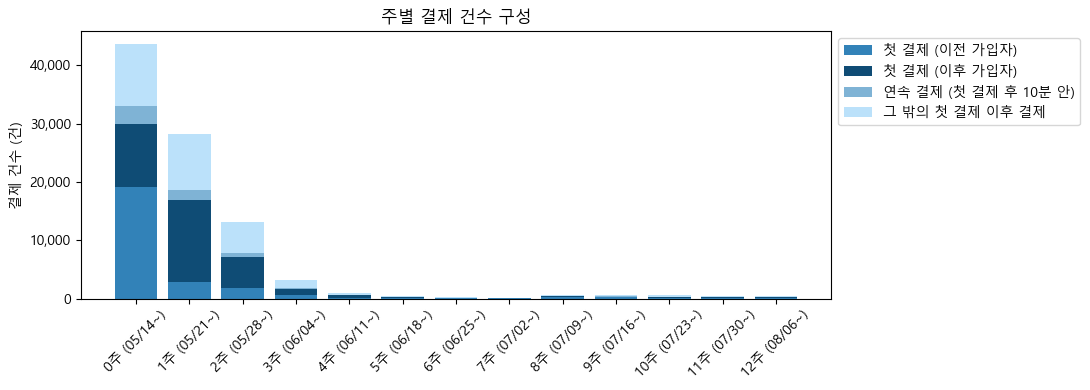

In [59]:
p2 = pay.merge(base[['user_id', 'period']], on='user_id', how='left')
KINDS = ['첫 결제 (이전 가입자)', '첫 결제 (이후 가입자)', '연속 결제 (첫 결제 후 10분 안)', '그 밖의 첫 결제 이후 결제']
p2['kind'] = np.select([(p2.seq == 1) & (p2.period == PERIODS[0]), p2.seq == 1, p2.gap <= QUICK_GAP], KINDS[:3], KINDS[3])
p2['week'] = week_no(p2.created_at)
wk_kind = p2.pivot_table(index='week', columns='kind', values='id', aggfunc='size', fill_value=0)[KINDS]
wk_kind['결제 건수'] = wk_kind.sum(axis=1)
wk_kind['첫 결제 이후 결제 비중(%)'] = ((wk_kind[KINDS[2]] + wk_kind[KINDS[3]]) / wk_kind['결제 건수'] * 100).round(1)
wk_kind.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in wk_kind.index]
display(wk_kind)

fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(wk_kind))
for k, c in zip(KINDS, [C2, C1, '#7FB3D5', C3]):
    ax.bar(wk_kind.index, wk_kind[k], bottom=bottom, color=c, label=k)
    bottom += wk_kind[k].values
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_title('주별 결제 건수 구성'); ax.set_ylabel('결제 건수 (건)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

- 0주 결제 43,678건 중 첫 결제가 30,035건이고, 그중 19,154건이 이전 가입자의 첫 결제임. 0주에서 1주로 줄어든 15,515건은 대부분 이전 가입자 첫 결제 감소(16,222건)에서 옴
- 첫 결제 이후 결제 비중은 0주 31.2%에서 2~3주 45~48%로 오름. 첫 결제가 더 빨리 줄어 비중이 커진 것이고, 건수는 0주 13,643건에서 3주 1,533건으로 함께 줄었음
- 8주(07/09~)에는 7주보다 569건 늘었고, 그중 292건(51%)이 이전 가입자의 첫 결제 증가임. 첫 결제 이후 결제도 215건 늘었음

### B-2. 결제 순서별 상품
- 8/10까지의 전체 결제를 결제 순번(첫 번째, 두 번째, 세 번째 이후)으로 나눠 상품 비율을 봄
- 두 번째 결제는 연속 결제(10분 안)와 그 뒤의 결제로 다시 나눔

In [60]:
order = np.select([pay.seq == 1, (pay.seq == 2) & (pay.gap <= QUICK_GAP), pay.seq == 2],
                  ['첫 번째', '두 번째 (10분 안)', '두 번째 (10분 뒤)'], '세 번째 이후')
prod = pd.crosstab(order, pay.productId)
prod = prod.reindex(['첫 번째', '두 번째 (10분 안)', '두 번째 (10분 뒤)', '세 번째 이후'])[list(PRICE)]
prod_pct = (prod.div(prod.sum(axis=1), axis=0) * 100).round(1)
prod_pct['결제 건수'] = prod.sum(axis=1)
prod_pct.index.name = '결제 순번'
display(prod_pct)

c777 = pay[pay.productId == 'heart.777'].groupby('user_id').size()
print(f'heart.777 구매자 {len(c777):,}명 중 두 번 이상 산 유저: {int((c777 > 1).sum())}명')
q777 = pay[(pay.seq == 2) & (pay.gap <= QUICK_GAP) & (pay.productId == 'heart.777')]
first_prod = pay[pay.seq == 1].set_index('user_id').productId
print('10분 안 두 번째 결제가 heart.777인 경우의 첫 결제 상품:', q777.user_id.map(first_prod).value_counts().to_dict())

productId,heart.777,heart.1000,heart.4000,heart.200,결제 건수
결제 순번,,,,,
첫 번째,94.1,4.0,0.9,1.0,58266
두 번째 (10분 안),14.5,47.4,3.5,34.6,4791
두 번째 (10분 뒤),6.7,45.1,3.2,45.0,10793
세 번째 이후,2.0,48.8,5.8,43.5,19094


heart.777 구매자 56,543명 중 두 번 이상 산 유저: 96명
10분 안 두 번째 결제가 heart.777인 경우의 첫 결제 상품: {'heart.1000': 438, 'heart.200': 147, 'heart.777': 69, 'heart.4000': 40}


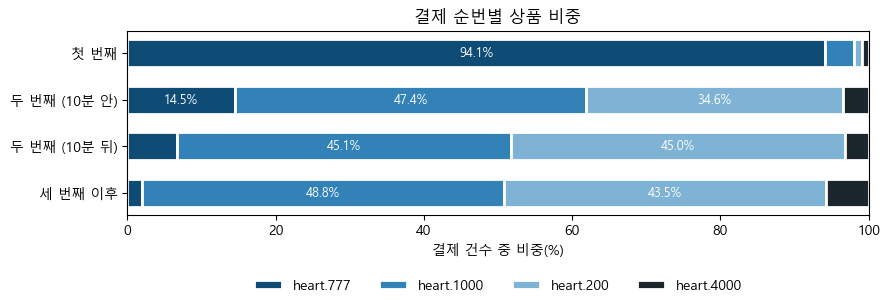

In [61]:
# 결제 순번별 상품 비중 그래프
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(prod_pct))
for p in ['heart.777', 'heart.1000', 'heart.200', 'heart.4000']:
    v = prod_pct[p].values
    ax.barh(prod_pct.index, v, left=left, color=PROD_COLORS[p], edgecolor='white', linewidth=2, height=0.6, label=p)
    for i, (l, x) in enumerate(zip(left, v)):
        if x >= 8:
            ax.text(l + x / 2, i, f'{x:.1f}%', ha='center', va='center', color='white', fontsize=9)
    left += v
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel('결제 건수 중 비중(%)'); ax.set_title('결제 순번별 상품 비중')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.28), frameon=False)
plt.tight_layout(); plt.show()

- 첫 결제의 94.1%가 특가 상품 heart.777임. heart.777 구매자 56,543명 중 두 번 이상 산 유저가 96명뿐이라 1인 1회 상품으로 추정함
- 두 번째 결제부터는 정가 상품(heart.1000, heart.200)이 대부분임. 두 상품의 비중은 10분 안 연속 결제 82.0%, 10분 뒤 두 번째 결제 90.1%, 세 번째 이후 결제 92.3%임
- 따라서 재결제는 특가로 시작한 유저가 정가 상품을 사는지의 문제로 볼 수 있음. 10분 안 연속 결제의 heart.777(14.5%)은 대부분 정가 상품을 먼저 사고 특가를 바로 산 경우(625건)이고, 69건은 특가가 두 번 찍힌 경우임. 그중 36건은 10초 안에 찍혀 중복 기록일 가능성이 있음(부록 A-3 보충)

---
## 부록 C. 재결제 유저 특성

가입 시기, 성별, 학교·학년, 학교·반 가입자 수, 지역, 초기 친구 요청 수, 첫 결제 상품, 연속 결제 여부에 따라 7일 재결제율이 어떻게 다른지 하나씩 봄.

- 대상: 7일 관찰 대상 (첫 결제가 8/3 이전인 첫 결제자). 0-10의 `rb`를 씀
- 재결제율 = 구간의 재결제자 수 ÷ 구간의 7일 관찰 대상 수 × 100
- 이전 가입자와 이후 가입자로 나눠 봄. 첫 결제자만 대상이라 인원이 적어 그래프 기준 인원을 300명으로 낮춤(`MIN_N_RB`)
- 첫 결제와 관련된 조건(첫 결제 상품, 연속 결제)은 첫 결제 후 10분 안에 정해지므로 재결제 여부보다 앞선 정보임

In [62]:
display(rate_table(rb.assign(전체='전체'), '전체', 're7'))

이전 가입자             이후 가입자                 전체             
       인원   해당자 비율(%)     인원   해당자 비율(%)     인원    해당자 비율(%)
전체                                                          
전체  25572  4014  15.7  32299  6874  21.3  57871  10888  18.8

### C-1. 가입 주별 재결제율
- 가입 주 기준 (2-2는 첫 결제 주 기준)

이전 가입자             이후 가입자                 전체            
                    인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
signup_week_lbl                                                         
03/26~               1     0   0.0      0     0   NaN      1     0   0.0
04/09~               3     0   0.0      0     0   NaN      3     0   0.0
04/16~             136    16  11.8      0     0   NaN    136    16  11.8
04/23~             454    34   7.5      0     0   NaN    454    34   7.5
04/30~            3054   372  12.2      0     0   NaN   3054   372  12.2
05/07~           21924  3592  16.4      0     0   NaN  21924  3592  16.4
05/14~               0     0   NaN  17178  3725  21.7  17178  3725  21.7
05/21~               0     0   NaN  12017  2567  21.4  12017  2567  21.4
05/28~               0     0   NaN   2514   496  19.7   2514   496  19.7
06/04~               0     0   NaN    410    60  14.6    410    60  14.6
06/11~               0     0   NaN     97    15  15.5     97    15  15.5
06/18~               0     0   NaN     20     3  15.0     20     3  15.0
06/25~               0     0   NaN      8     1  12.5      8     1  12.5
07/02~               0     0   NaN      1     0   0.0      1     0   0.0
07/09~               0     0   NaN     34     5  14.7     34     5  14.7
07/16~               0     0   NaN     14     2  14.3     14     2  14.3
07/23~               0     0   NaN      6     0   0.0      6     0   0.0

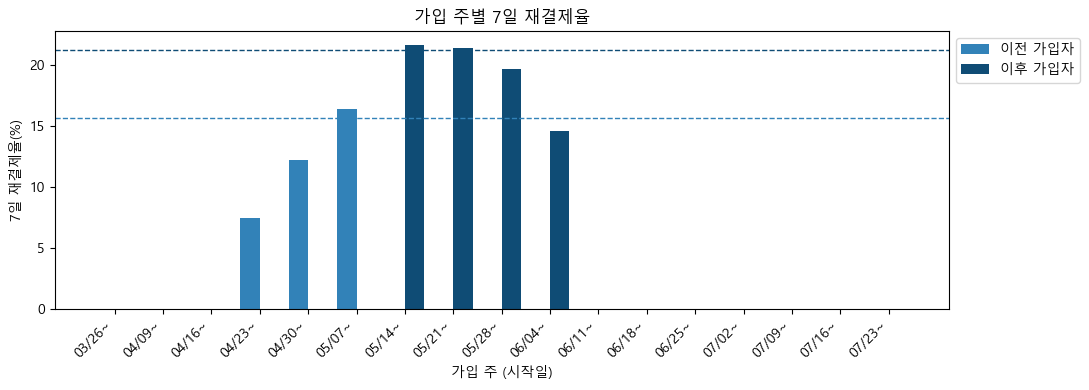

이후 가입자 중 가입 주와 첫 결제 주가 같은 비율: 70.0%
이전 가입자 중 0주(5/14~5/20)에 첫 결제한 비율: 74.9%


In [63]:
_ = show_rate(rb, 'signup_week_lbl', 're7', '가입 주별 7일 재결제율', '7일 재결제율(%)', '가입 주 (시작일)',
              figsize=(11, 4), min_n=MIN_N_RB)

# 가입 주와 첫 결제 주가 얼마나 겹치는지
aft = rb[rb.period == PERIODS[1]]
print(f'이후 가입자 중 가입 주와 첫 결제 주가 같은 비율: {(week_no(aft.signup_at) == aft.first_week).mean():.1%}')
print(f'이전 가입자 중 0주(5/14~5/20)에 첫 결제한 비율: {(rb.loc[rb.period == PERIODS[0], "first_week"] == 0).mean():.1%}')

- 이후 가입자(21.3%)가 이전 가입자(15.7%)보다 5.6%p 높음
- 이전 가입자는 결제 시작 직전 주(05/07~) 가입자가 16.4%로 그 전 주(12.2%)보다 높음. 이후 가입자는 0주 21.7%, 1주 21.4%, 2주 19.7%로 비슷하다가 3주(06/04~) 14.6%로 낮아짐
- 이후 가입자의 70.0%는 가입 주와 첫 결제 주가 같고, 이전 가입자의 74.9%는 0주에 첫 결제함. 두 변수가 많이 겹쳐서 부록 D 모형에는 가입 주를 넣지 않고 첫 결제 주와 가입 시기(이전/이후)만 넣음

### C-2. 성별 재결제율

이전 가입자             이후 가입자                 전체            
             인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
gender_k                                                         
여         12936  2243  17.3  14569  3314  22.7  27505  5557  20.2
남         12636  1771  14.0  17730  3560  20.1  30366  5331  17.6

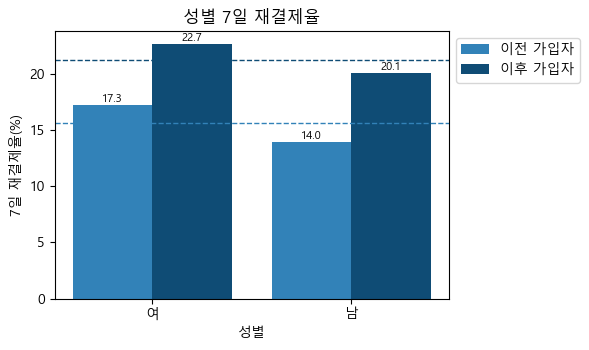

In [64]:
_ = show_rate(rb, 'gender_k', 're7', '성별 7일 재결제율', '7일 재결제율(%)', '성별', figsize=(6, 3.6), min_n=MIN_N_RB)

- 여학생이 높음. 전체 20.2% 대 17.6%이고, 이전·이후 가입자 모두 여학생이 2.6~3.3%p 높음

### C-3. 학교 유형·학년별 재결제율

이전 가입자             이후 가입자                 전체            
                 인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
school_grade                                                         
중1                0     0   NaN      2     1  50.0      2     1  50.0
중2             3867   508  13.1   3129   516  16.5   6996  1024  14.6
중3             7632  1228  16.1   5682  1189  20.9  13314  2417  18.2
고1             8886  1463  16.5  11082  2388  21.5  19968  3851  19.3
고2             4260   672  15.8   8392  1814  21.6  12652  2486  19.6
고3              924   142  15.4   4010   965  24.1   4934  1107  22.4

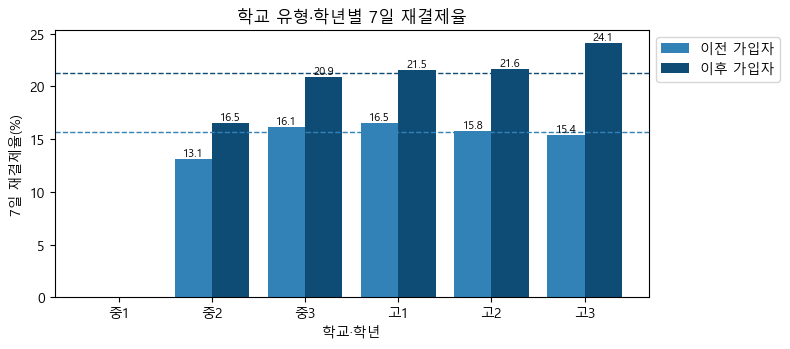

In [65]:
_ = show_rate(rb, 'school_grade', 're7', '학교 유형·학년별 7일 재결제율', '7일 재결제율(%)', '학교·학년', figsize=(8, 3.6), min_n=MIN_N_RB)

#### 참고: 같은 구간의 첫 결제율
- 재결제율과 비교하려고 학교·학년별 첫 결제율을 함께 봄
- 8/10까지 결제율 = 그 구간 유저 중 8/10까지 한 번이라도 결제한 비율
- 7일 첫 결제율 = 이후 가입자(8/3까지 가입) 중 가입 후 7일 안에 첫 결제한 비율 (부록 H-2와 같은 기준)

In [66]:
GRADES = ['중2', '중3', '고1', '고2', '고3']
b33 = base[base.school_grade.isin(GRADES)].copy()
b33['school_grade'] = b33.school_grade.astype(str)
b33['paid'] = b33.user_id.isin(buyer.user_id)                         # 8/10까지 결제 경험
fp_at = buyer.set_index('user_id').first_at
aft33 = b33[(b33.period == PERIODS[1]) & (b33.signup_at < OBS_END)].copy()
aft33['pay7'] = aft33.user_id.map(fp_at) < aft33.signup_at + RE_WINDOW   # 가입 후 7일 안 첫 결제
grade_first = pd.DataFrame({
    '이전 가입자 8/10까지 결제율(%)': b33[b33.period == PERIODS[0]].groupby('school_grade').paid.mean().mul(100).round(2),
    '이후 가입자 8/10까지 결제율(%)': b33[b33.period == PERIODS[1]].groupby('school_grade').paid.mean().mul(100).round(2),
    '이후 가입자 7일 첫 결제율(%)': aft33.groupby('school_grade').pay7.mean().mul(100).round(2),
    '7일 재결제율(%)': rb.assign(sg=rb.school_grade.astype(str)).groupby('sg').re7.mean().mul(100).round(1),
}).reindex(GRADES)
grade_first.index.name = '학교·학년'
grade_first

,이전 가입자 8/10까지 결제율(%),이후 가입자 8/10까지 결제율(%),이후 가입자 7일 첫 결제율(%),7일 재결제율(%)
학교·학년,,,,
중2,4.38,4.97,4.07,14.6
중3,8.30,10.59,8.98,18.2
고1,8.28,12.07,10.11,19.3
고2,7.73,11.96,10.50,19.6
고3,6.79,11.64,10.33,22.4


- 중2가 14.6%로 가장 낮고 중3 18.2%, 고1 19.3%, 고2 19.6%, 고3 22.4%로 학년이 오를수록 높음
- 이후 가입자 고3이 24.1%로 가장 높음. 첫 결제율은 반대로 고3이 고1보다 낮아(8/10까지 결제율 이전 가입자 6.79% 대 8.28%, 이후 가입자 11.64% 대 12.07%) 재결제와 방향이 다름. 다만 이후 가입자의 가입 후 7일 첫 결제율은 고3 10.33%, 고1 10.11%로 비슷함
- 중1은 2명뿐이라 해석하지 않음

### C-4. 학교 가입자 수 구간별 재결제율

이전 가입자             이후 가입자                 전체            
                    인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
school_size_bin                                                         
100명 미만           2247   350  15.6   5289  1080  20.4   7536  1430  19.0
100~299명         18331  2903  15.8  22727  4862  21.4  41058  7765  18.9
300명 이상           4994   761  15.2   4283   932  21.8   9277  1693  18.2

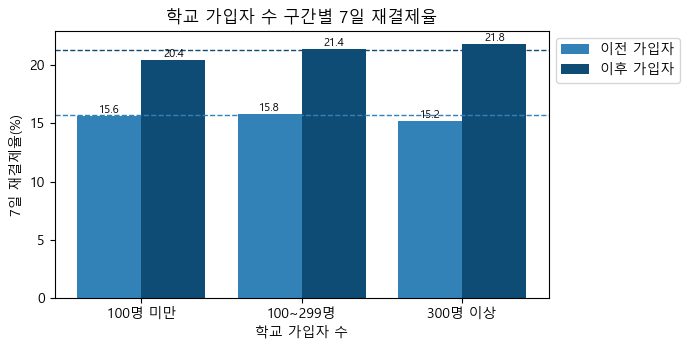

In [67]:
_ = show_rate(rb, 'school_size_bin', 're7', '학교 가입자 수 구간별 7일 재결제율', '7일 재결제율(%)', '학교 가입자 수',
              figsize=(7, 3.6), min_n=MIN_N_RB)

- 이후 가입자 20.4% / 21.4% / 21.8%, 이전 가입자 15.6% / 15.8% / 15.2%로 구간 사이 차이가 1%p 안팎임
- 학교 가입자 수만으로는 재결제율이 거의 달라지지 않음. 부록 D에서 다른 조건을 맞추면 100명 미만 학교가 3.3%p 높게 나옴

### C-5. 반 가입자 수 구간별 재결제율

이전 가입자             이후 가입자                 전체            
                   인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
class_size_bin                                                         
10명 미만           4920   623  12.7   8832  1674  19.0  13752  2297  16.7
10~19명          17427  2817  16.2  20222  4436  21.9  37649  7253  19.3
20~29명           3095   550  17.8   3068   728  23.7   6163  1278  20.7
30명 이상            130    24  18.5    177    36  20.3    307    60  19.5

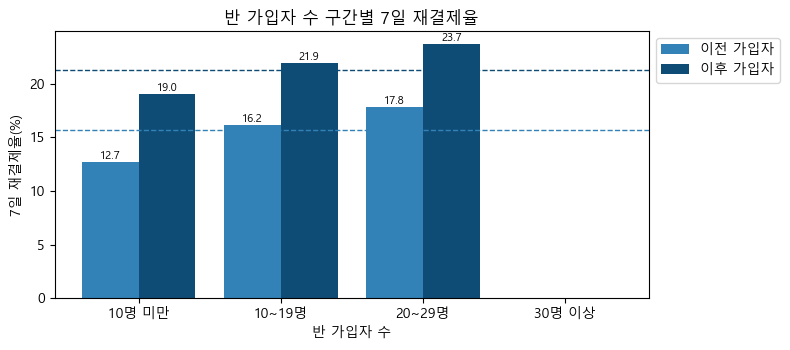

In [68]:
_ = show_rate(rb, 'class_size_bin', 're7', '반 가입자 수 구간별 7일 재결제율', '7일 재결제율(%)', '반 가입자 수',
              figsize=(8, 3.6), min_n=MIN_N_RB)

- 반 가입자가 많을수록 재결제율이 높음. 전체 기준 10명 미만 16.7%, 10~19명 19.3%, 20~29명 20.7%이고, 이전·이후 가입자 모두 같은 방향
- 30명 이상은 307명뿐이라 해석하지 않음
- 같은 반에 앱을 쓰는 친구가 많으면 받는 투표가 많아 하트를 쓸 일이 계속 생긴다는 설명이 가능하지만, 이 표만으로는 확인되지 않음

### C-6. 지역(시·도, 권역)별 재결제율
- 시·도는 전체 재결제율이 높은 순으로 놓음

이전 가입자             이후 가입자                전체            
            인원   해당자 비율(%)     인원  해당자 비율(%)     인원   해당자 비율(%)
sido                                                           
미상           3     1  33.3      2    1  50.0      5     2  40.0
전라남도       727   165  22.7   3650  944  25.9   4377  1109  25.3
강원도        456    87  19.1   1678  399  23.8   2134   486  22.8
경상남도       691   122  17.7   3858  879  22.8   4549  1001  22.0
광주광역시      653   166  25.4   1868  371  19.9   2521   537  21.3
경상북도       955   184  19.3   2373  523  22.0   3328   707  21.2
제주특별자치도     75    14  18.7    416   88  21.2    491   102  20.8
전라북도       493   103  20.9   3316  677  20.4   3809   780  20.5
대전광역시      585   125  21.4   1317  242  18.4   1902   367  19.3
충청북도      1127   193  17.1    786  176  22.4   1913   369  19.3
충청남도      1704   246  14.4   1659  384  23.1   3363   630  18.7
부산광역시     1196   201  16.8   2247  439  19.5   3443   640  18.6
울산광역시     1063   152  14.3    658  156  23.7   1721   308  17.9
대구광역시     1390   234  16.8   1574  282  17.9   2964   516  17.4
인천광역시     1654   264  16.0   1678  295  17.6   3332   559  16.8
경기도       9473  1327  14.0   4180  827  19.8  13653  2154  15.8
서울특별시     3327   430  12.9   1039  191  18.4   4366   621  14.2

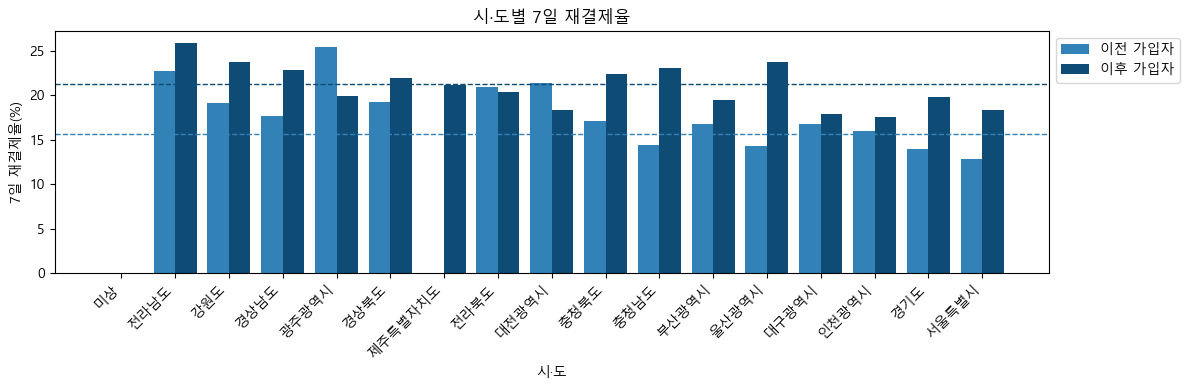

이전 가입자             이후 가입자                 전체            
           인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
region                                                         
수도권     14454  2021  14.0   6897  1313  19.0  21351  3334  15.6
광역시      4887   878  18.0   7664  1490  19.4  12551  2368  18.9
도        6228  1114  17.9  17736  4070  22.9  23964  5184  21.6
미상          3     1  33.3      2     1  50.0      5     2  40.0

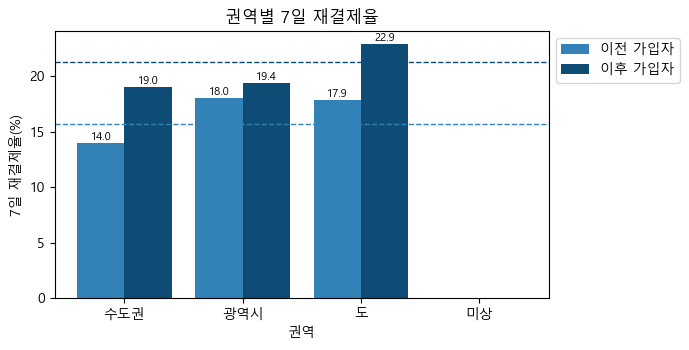

In [69]:
order_sido = rb.groupby('sido').re7.mean().sort_values(ascending=False).index
rb['sido'] = pd.Categorical(rb.sido, order_sido, ordered=True)
_ = show_rate(rb, 'sido', 're7', '시·도별 7일 재결제율', '7일 재결제율(%)', '시·도', figsize=(12, 4), min_n=MIN_N_RB)
_ = show_rate(rb, 'region', 're7', '권역별 7일 재결제율', '7일 재결제율(%)', '권역', figsize=(7, 3.6), min_n=MIN_N_RB)

- 권역으로 묶으면 수도권 15.6%, 광역시 18.9%, 도 21.6%로 차이가 뚜렷함. 시·도별로는 서울(14.2%)과 경기(15.8%)가 가장 낮고 전남(25.3%)이 가장 높음
- 수도권은 이전 가입자가 많아(21,351명 중 14,454명) 가입 시기 차이가 섞였을 수 있음. 이후 가입자만 봐도 수도권 19.0%, 도 22.9%로 차이가 남
- 지역 미상 5명은 해석하지 않음

### C-7. 초기 친구 요청 수 구간별 재결제율
- 초기 친구 요청 수 = 가입 후 1시간 안에 보낸 요청과 받은 요청의 합 (0-2 용어)

이전 가입자             이후 가입자                 전체            
            인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
req_bin                                                         
0건        2153   364  16.9   2448   537  21.9   4601   901  19.6
1~4건      5161   898  17.4   4030   859  21.3   9191  1757  19.1
5~9건      5233   817  15.6   4976  1062  21.3  10209  1879  18.4
10~19건    7259  1096  15.1   9047  1830  20.2  16306  2926  17.9
20~49건    5121   758  14.8   9776  2107  21.6  14897  2865  19.2
50건 이상     645    81  12.6   2022   479  23.7   2667   560  21.0

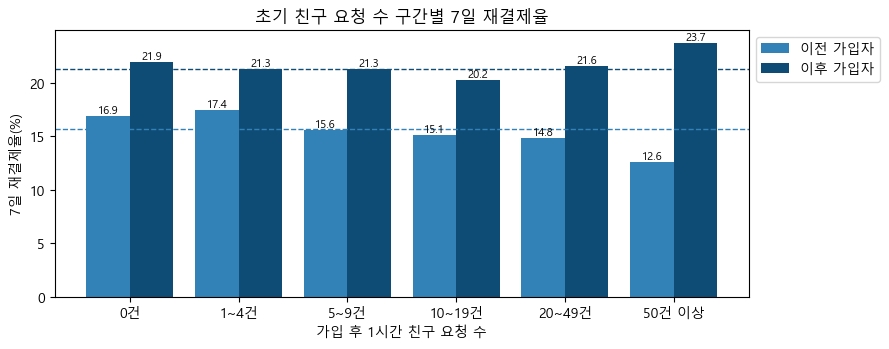

In [70]:
_ = show_rate(rb, 'req_bin', 're7', '초기 친구 요청 수 구간별 7일 재결제율', '7일 재결제율(%)', '가입 후 1시간 친구 요청 수',
              figsize=(9, 3.6), min_n=MIN_N_RB)

- 이후 가입자는 0건 21.9%에서 50건 이상 23.7%까지 20~24% 사이로 평평함. 이전 가입자는 0건 16.9%에서 50건 이상 12.6%로 조금 낮아짐
- 초기 친구 요청 수는 첫 결제(부록 H-3)와 달리 재결제와는 거의 관련이 없음

### C-8. 첫 결제 상품, 연속 결제 여부별 재결제율
- 첫 결제 상품: 특가(heart.777)와 정가 상품(heart.1000, heart.200, heart.4000)
- 연속 결제: 첫 결제 후 10분 안에 더 산 적이 있는지

이전 가입자             이후 가입자                 전체            
                   인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
first_kind                                                             
특가 (heart.777)  24079  3483  14.5  30404  6079  20.0  54483  9562  17.6
정가 상품            1493   531  35.6   1895   795  42.0   3388  1326  39.1

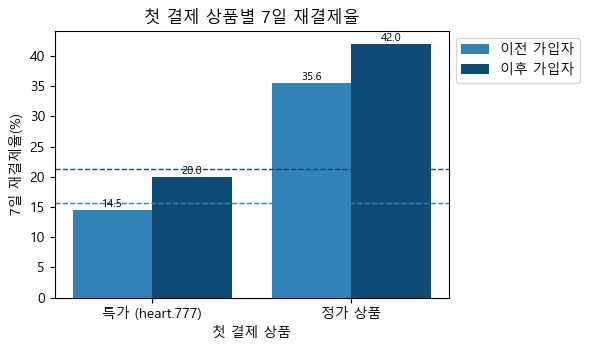

이전 가입자             이후 가입자                 전체            
            인원   해당자 비율(%)     인원   해당자 비율(%)     인원   해당자 비율(%)
quick_k                                                         
없음       23434  3321  14.2  29706  5871  19.8  53140  9192  17.3
있음        2138   693  32.4   2593  1003  38.7   4731  1696  35.8

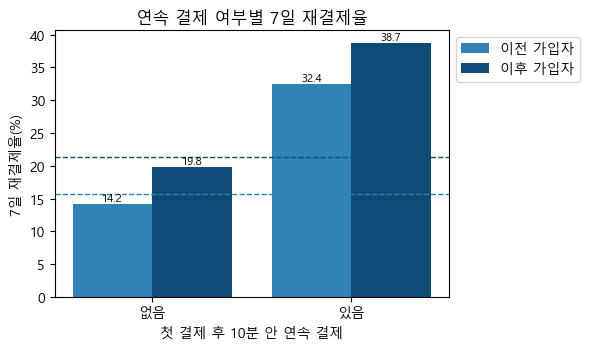

In [71]:
_ = show_rate(rb, 'first_kind', 're7', '첫 결제 상품별 7일 재결제율', '7일 재결제율(%)', '첫 결제 상품', figsize=(6, 3.6), min_n=MIN_N_RB)
_ = show_rate(rb, 'quick_k', 're7', '연속 결제 여부별 7일 재결제율', '7일 재결제율(%)', '첫 결제 후 10분 안 연속 결제', figsize=(6, 3.6), min_n=MIN_N_RB)

- 첫 결제로 정가 상품을 산 유저(3,388명)의 재결제율은 39.1%로, 특가로 시작한 유저(17.6%)의 두 배가 넘음
- 첫 결제 후 10분 안에 더 산 유저(4,731명)도 35.8%로 그렇지 않은 유저(17.3%)보다 높음
- 두 조건은 7일 관찰 대상의 6~8%만 해당함. 처음부터 하트를 많이 사는 유저가 다음에도 사는 것으로, 결제 의향이 큰 유저를 가려내는 표시로 보임

---
## 부록 D. 재결제에 영향을 주는 조건 (로지스틱 회귀, 피처 중요도)

부록 C는 조건을 하나씩 봤기 때문에 조건끼리 겹친 영향(예: 고등학생에 남학생이 많음)을 나눌 수 없음. 부록 D는 여러 조건을 한 모형에 넣어 다른 조건이 같을 때의 차이를 보고, 어떤 조건이 재결제를 가르는 데 많이 쓰이는지(피처 중요도)를 비교함.

| 항목 | 기준 |
|---|---|
| 모형 | 로지스틱 회귀 (scikit-learn `LogisticRegression`, 규제를 사실상 끈 `C=1e6`, 끝까지 수렴하도록 `solver='newton-cholesky'`). 결과 변수가 0/1이라 예측값이 0~1 사이의 확률로 나옴 |
| 결과 변수 | 7일 재결제 여부 `re7` (0장 기준) |
| 대상 | `rb`(7일 관찰 대상) 중 아래 설명 변수가 모두 있는 유저. 중1 2명과 학교 정보가 없는 5명을 뺌 |
| 설명 변수 | 초기 친구 요청 수, 성별, 학교·학년, 권역, 학교 가입자 수, 반 가입자 수, 가입 시기, 첫 결제 주, 첫 결제 상품, 연속 결제 (10개). 모두 범주형이고, 변수마다 기준 구간을 하나 정해(부록 D-3 표의 '(기준)') 나머지 구간마다 0/1 열을 만듦 |
| 결과 표기 | 계수(오즈비) 대신 예측 재결제율 차이(%p). 모든 유저의 한 조건만 그 구간으로 바꿔 예측한 평균 재결제율에서, 기준 구간으로 바꿔 예측한 평균 재결제율을 뺀 값. 95% 신뢰구간은 델타 방법으로 계산 |
| 성능 | 학습 80% / 평가 20%로 나누고(재결제 비율 유지, `random_state=42`) 평가 데이터의 AUC로 확인 |
| 피처 중요도 | ① 퍼뮤테이션 중요도: 평가 데이터에서 한 변수의 값만 무작위로 섞었을 때 AUC가 얼마나 떨어지는지 (30번 반복 평균) ② 변수 제거 중요도: 그 변수를 빼고 다시 학습했을 때 평가 AUC가 얼마나 떨어지는지 |

- 학년은 학교 유형과 묶어 한 변수(중2~고3)로 넣음. 학교 유형과 학년을 따로 넣으면 '3학년'이 중3과 고3을 섞은 값이 되기 때문임
- 가입 주는 첫 결제 주, 가입 시기(이전/이후)와 겹쳐 넣지 않음
- 예측 재결제율 차이와 중요도는 함께 움직이는 정도를 보여 줄 뿐 원인이라는 뜻이 아님. 모형에 없는 요인(앱 활동량 등)이 섞여 있을 수 있음

### D-1. 데이터 준비

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# 설명 변수: 이름 → (컬럼, 구간 목록). 구간 목록의 첫 값이 기준 구간
VARS = {
    '초기 친구 요청 수': ('req_bin', REQ_LABELS),
    '성별': ('gender_k', ['여', '남']),
    '학교·학년': ('school_grade', ['중2', '중3', '고1', '고2', '고3']),
    '권역': ('region', ['수도권', '광역시', '도']),
    '학교 가입자 수': ('school_size_bin', ['100~299명', '100명 미만', '300명 이상']),
    '반 가입자 수': ('class_size_bin', ['10~19명', '10명 미만', '20~29명', '30명 이상']),
    '가입 시기': ('period', PERIODS),
    '첫 결제 주': ('first_week_g', ['0주', '1주', '2주', '3주', '4주 이후']),
    '첫 결제 상품': ('first_kind', ['특가 (heart.777)', '정가 상품']),
    '연속 결제': ('quick_k', ['없음', '있음']),
}

reg = rb.copy()
keep = pd.Series(True, index=reg.index)
for v, (c, levels) in VARS.items():
    reg[c] = reg[c].astype(str)
    ok = reg[c].isin(levels)
    if (~ok).sum():
        print(f'{v}: 구간 밖 또는 빈 값 {int((~ok).sum()):,}명 (다른 변수와 겹칠 수 있음)')
    keep &= ok
reg = reg[keep].copy()
print(f'분석 대상: {len(reg):,}명 (rb {len(rb):,}명 중) / 7일 재결제율 {reg.re7.mean():.1%}')

def design(df, drop=None):
    # 범주형 설명 변수를 구간별 0/1 열로 바꿈 (기준 구간은 열을 만들지 않음). drop에 적은 변수는 뺌
    cols = {}
    for v, (c, levels) in VARS.items():
        if v == drop:
            continue
        for lv in levels[1:]:
            cols[f'{v}: {lv}'] = (df[c] == lv).astype(float)
    return pd.DataFrame(cols, index=df.index)

def fit(df, ycol='re7', drop=None):
    # newton-cholesky: 계수를 끝까지 수렴시키는 풀이법 (기본 lbfgs는 이 데이터에서 계수가 0.09까지 덜 수렴함)
    return LogisticRegression(C=1e6, solver='newton-cholesky', tol=1e-10, max_iter=200).fit(design(df, drop), df[ycol].astype(int))

X_all = design(reg)
print(f'설명 변수 {len(VARS)}개 → 0/1 열 {X_all.shape[1]}개')

학교·학년: 구간 밖 또는 빈 값 7명 (다른 변수와 겹칠 수 있음)
권역: 구간 밖 또는 빈 값 5명 (다른 변수와 겹칠 수 있음)
분석 대상: 57,864명 (rb 57,871명 중) / 7일 재결제율 18.8%
설명 변수 10개 → 0/1 열 24개


### D-2. 모형 학습과 성능
- AUC는 재결제자와 비재결제자를 하나씩 뽑았을 때 재결제자의 예측값이 더 높을 확률임. 0.5면 무작위와 같음
- 10분위 표는 평가 데이터를 예측값 순으로 10묶음으로 나눠 예측 재결제율과 실제 재결제율을 비교한 것임

학습 46,291명 / 평가 11,573명
AUC 학습 0.655 / 평가 0.652


,인원,예측 재결제율(%),실제 재결제율(%)
분위,,,
1,1158,7.1,7.0
2,1157,11.5,10.3
3,1157,13.4,13.7
4,1157,14.8,15.4
5,1158,16.3,16.8
6,1157,17.9,18.3
7,1157,19.8,19.9
8,1157,22.1,21.0
9,1157,25.7,25.2


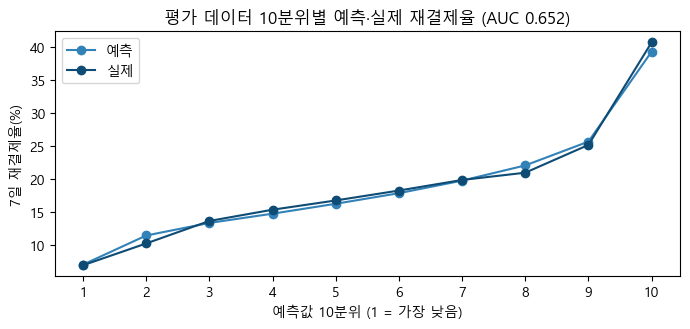

In [73]:
tr, te = train_test_split(reg, test_size=0.2, random_state=42, stratify=reg.re7)
model = fit(tr)
p_tr = model.predict_proba(design(tr))[:, 1]
p_te = model.predict_proba(design(te))[:, 1]
AUC_TE = roc_auc_score(te.re7, p_te)
print(f'학습 {len(tr):,}명 / 평가 {len(te):,}명')
print(f'AUC 학습 {roc_auc_score(tr.re7, p_tr):.3f} / 평가 {AUC_TE:.3f}')

dec = pd.qcut(pd.Series(p_te).rank(method='first'), 10, labels=range(1, 11))
calib = (pd.DataFrame({'분위': dec.values, '예측': p_te, '실제': te.re7.values.astype(int)})
         .groupby('분위', observed=True).agg(인원=('실제', 'size'), 예측_재결제율=('예측', 'mean'), 실제_재결제율=('실제', 'mean')))
calib[['예측_재결제율', '실제_재결제율']] = calib[['예측_재결제율', '실제_재결제율']].mul(100).round(1)
calib.columns = ['인원', '예측 재결제율(%)', '실제 재결제율(%)']
display(calib)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(calib.index.astype(int), calib['예측 재결제율(%)'], marker='o', color=C2, label='예측')
ax.plot(calib.index.astype(int), calib['실제 재결제율(%)'], marker='o', color=C1, label='실제')
ax.set_xticks(range(1, 11)); ax.set_xlabel('예측값 10분위 (1 = 가장 낮음)'); ax.set_ylabel('7일 재결제율(%)')
ax.set_title(f'평가 데이터 10분위별 예측·실제 재결제율 (AUC {AUC_TE:.3f})'); ax.legend()
plt.tight_layout(); plt.show()

- 평가 데이터 AUC는 0.652이고 학습 데이터(0.655)와 거의 같아 과적합은 없음
- 10분위별 예측 재결제율(7.1~39.3%)이 실제 재결제율(7.0~40.7%)과 모든 분위에서 1.5%p 안으로 맞음
- AUC가 0.65 수준이라 이 모형으로 개인의 재결제를 맞히기는 어려움. 부록 D-3, D-4는 조건별 차이와 변수끼리의 상대적인 중요도를 보는 데 씀

### D-3. 조건별 예측 재결제율 차이
- 분석 대상 전체로 다시 학습한 모형을 씀
- 단순 재결제율은 그 구간의 실제 재결제율(다른 조건을 맞추지 않은 값)임
- 예측 재결제율 차이는 다른 조건을 그대로 둔 채 그 조건만 바꿨을 때의 차이(%p)임

인원  단순 재결제율(%)  예측 재결제율(%)  차이(%p)  95% 하한  \
변수         구간                                                                   
초기 친구 요청 수 0건 (기준)               4600       19.59       19.46    0.00     NaN   
           1~4건                  9189       19.11       19.69    0.23   -1.14   
           5~9건                 10207       18.39       18.56   -0.90   -2.24   
           10~19건               16306       17.94       17.93   -1.53   -2.79   
           20~49건               14895       19.23       18.97   -0.48   -1.76   
           50건 이상                2667       21.00       20.15    0.69   -1.16   
성별         여 (기준)               27501       20.20       20.20    0.00     NaN   
           남                    30363       17.55       17.55   -2.64   -3.28   
학교·학년      중2 (기준)               6996       14.64       14.64    0.00     NaN   
           중3                   13314       18.15       17.93    3.29    2.26   
           고1                   19968       19.29       19.16    4.52    3.54   
           고2                   12652       19.65       19.97    5.33    4.23   
           고3                    4934       22.44       22.79    8.15    6.67   
권역         수도권 (기준)             21351       15.62       16.46    0.00     NaN   
           광역시                  12551       18.87       18.29    1.83    0.99   
           도                    23962       21.63       21.06    4.60    3.83   
학교 가입자 수   100~299명 (기준)        41056       18.91       18.61    0.00     NaN   
           100명 미만               7531       18.96       21.93    3.32    2.23   
           300명 이상               9277       18.25       17.51   -1.11   -1.96   
반 가입자 수    10~19명 (기준)          37649       19.26       19.24    0.00     NaN   
           10명 미만               13746       16.69       16.64   -2.60   -3.38   
           20~29명                6163       20.74       20.86    1.61    0.52   
           30명 이상                 306       19.61       22.13    2.89   -1.88   
가입 시기      이전 가입자 (기준)          25569       15.69       15.54    0.00     NaN   
           이후 가입자               32295       21.28       21.44    5.90    5.17   
첫 결제 주     0주 (기준)              30031       20.41       22.72    0.00     NaN   
           1주                   16878       20.68       17.93   -4.79   -5.61   
           2주                    7207       13.92       12.57  -10.14  -11.09   
           3주                    1682        8.26        7.83  -14.88  -16.25   
           4주 이후                 2066        6.00        6.58  -16.14  -17.36   
첫 결제 상품    특가 (heart.777) (기준)  54479       17.55       17.75    0.00     NaN   
           정가 상품                 3385       39.11       34.81   17.06   15.45   
연속 결제      없음 (기준)              53134       17.30       17.54    0.00     NaN   
           있음                    4730       35.84       32.27   14.73   13.38   

                                95% 상한  
변수         구간                           
초기 친구 요청 수 0건 (기준)                 NaN  
           1~4건                   1.60  
           5~9건                   0.44  
           10~19건                -0.27  
           20~49건                 0.80  
           50건 이상                 2.55  
성별         여 (기준)                  NaN  
           남                     -2.01  
학교·학년      중2 (기준)                 NaN  
           중3                     4.32  
           고1                     5.50  
           고2                     6.43  
           고3                     9.64  
권역         수도권 (기준)                NaN  
           광역시                    2.68  
           도                      5.38  
학교 가입자 수   100~299명 (기준)           NaN  
           100명 미만                4.42  
           300명 이상               -0.25  
반 가입자 수    10~19명 (기준)             NaN  
           10명 미만                -1.82  
           20~29명                 2.70  
           30명 이상                 7.65  
가입 시기      이전 가입자 (기준)             NaN  
           이후 가입자                 6.63  
첫 결제 주     

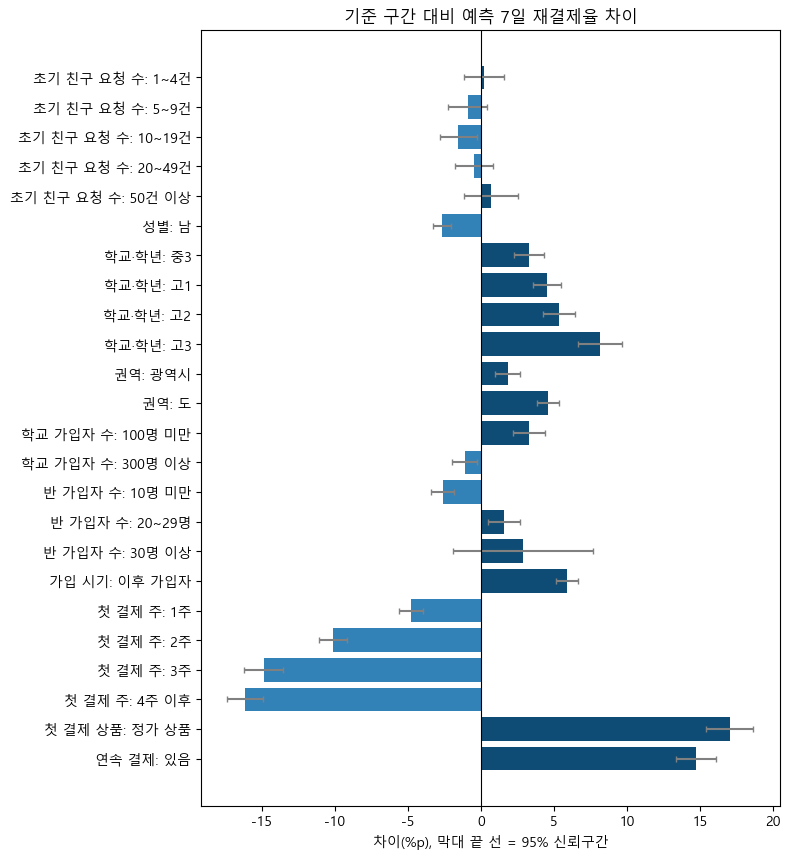

In [74]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def effect_table(df, ycol='re7'):
    # 전체 데이터로 학습하고, 조건마다 예측 재결제율 차이(%p)와 델타 방법 95% 신뢰구간을 계산
    m = fit(df, ycol)
    X = design(df)
    Xc = np.column_stack([np.ones(len(X)), X.values])
    beta = np.r_[m.intercept_, m.coef_.ravel()]
    p = sigmoid(Xc @ beta)
    cov = np.linalg.inv((Xc * (p * (1 - p))[:, None]).T @ Xc)      # 계수의 공분산 행렬
    names = list(X.columns)
    rows = []
    for v, (c, levels) in VARS.items():
        idx = [names.index(f'{v}: {lv}') + 1 for lv in levels[1:]]
        X0 = Xc.copy(); X0[:, idx] = 0                               # 모두 기준 구간으로
        p0 = sigmoid(X0 @ beta); g0 = (p0 * (1 - p0))[:, None] * X0
        rows.append({'변수': v, '구간': levels[0] + ' (기준)', '인원': int((df[c] == levels[0]).sum()),
                     '단순 재결제율(%)': df.loc[df[c] == levels[0], ycol].mean() * 100,
                     '예측 재결제율(%)': p0.mean() * 100, '차이(%p)': 0.0, '95% 하한': np.nan, '95% 상한': np.nan})
        for lv, j in zip(levels[1:], idx):
            X1 = X0.copy(); X1[:, j] = 1                             # 모두 이 구간으로
            p1 = sigmoid(X1 @ beta); g1 = (p1 * (1 - p1))[:, None] * X1
            d = (p1 - p0).mean() * 100
            grad = (g1 - g0).mean(axis=0)
            se = np.sqrt(grad @ cov @ grad) * 100
            rows.append({'변수': v, '구간': lv, '인원': int((df[c] == lv).sum()),
                         '단순 재결제율(%)': df.loc[df[c] == lv, ycol].mean() * 100,
                         '예측 재결제율(%)': p1.mean() * 100, '차이(%p)': d, '95% 하한': d - 1.96 * se, '95% 상한': d + 1.96 * se})
    return pd.DataFrame(rows).set_index(['변수', '구간']).round(2)

eff = effect_table(reg)
display(eff)

e = eff[eff['95% 하한'].notna()].iloc[::-1]
labels = [f'{v}: {lv}' for v, lv in e.index]
fig, ax = plt.subplots(figsize=(8, 0.3 * len(e) + 1.5))
ax.barh(labels, e['차이(%p)'], color=[C1 if v >= 0 else C2 for v in e['차이(%p)']],
        xerr=[e['차이(%p)'] - e['95% 하한'], e['95% 상한'] - e['차이(%p)']], ecolor='gray', capsize=2)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('기준 구간 대비 예측 7일 재결제율 차이'); ax.set_xlabel('차이(%p), 막대 끝 선 = 95% 신뢰구간')
plt.tight_layout(); plt.show()

- 첫 결제 주의 차이가 가장 큼. 다른 조건이 같아도 0주 첫 결제자보다 1주 -4.8%p, 2주 -10.1%p, 3주 -14.9%p, 4주 이후 -16.1%p 낮음. 단순 재결제율(0주 20.4%, 4주 이후 6.0%, 차이 14.4%p)과 크기가 비슷해서, 모형에 넣은 다른 조건(학년, 지역, 첫 결제 상품 등)의 구성이 바뀌어 생긴 하락은 아님
- 첫 결제를 정가 상품으로 한 유저 +17.1%p, 10분 안 연속 결제가 있는 유저 +14.7%p. 단순 비교(39.1% 대 17.6%, 35.8% 대 17.3%)보다 조금 줄었지만 여전히 큼
- 이후 가입자는 첫 결제 주를 맞춰도 이전 가입자보다 5.9%p 높음
- 학교·학년(중2 대비 고3 +8.2%p), 권역(수도권 대비 도 +4.6%p), 성별(남 -2.6%p)도 신뢰구간이 0을 지나지 않음. 반 가입자 10명 미만은 -2.6%p, 학교 가입자 100명 미만은 +3.3%p
- 초기 친구 요청 수는 모든 구간이 -1.5~+0.7%p이고, 10~19건(-1.5%p)을 빼면 신뢰구간이 0을 지남

### D-4. 피처 중요도
- 퍼뮤테이션 중요도: 부록 D-2에서 학습한 모형을 그대로 두고, 평가 데이터에서 한 변수(그 변수의 0/1 열 전부)의 값을 유저끼리 무작위로 섞은 뒤 AUC가 떨어진 크기임. 30번 반복한 평균과 표준편차를 보여 줌
- 변수 제거 중요도: 그 변수를 빼고 학습 데이터로 다시 학습한 뒤 평가 AUC가 떨어진 크기임. 다른 변수가 같은 정보를 대신 담으면 작게 나옴
- 두 값 모두 AUC 단위이고, 클수록 재결제자와 비재결제자를 가르는 데 많이 쓰인 변수임

,퍼뮤테이션 중요도,표준편차,변수 제거 중요도,퍼뮤테이션 순위,변수 제거 순위,중요도 비중(%)
변수,,,,,,
첫 결제 주,0.0495,0.0043,0.0251,1,1,30.0
연속 결제,0.0283,0.0027,0.0189,2,2,17.1
가입 시기,0.0260,0.0032,0.0073,3,4,15.8
첫 결제 상품,0.0249,0.0021,0.0152,4,3,15.1
권역,0.0125,0.0024,0.0056,5,5,7.6
학교·학년,0.0123,0.0018,0.0054,6,6,7.4
반 가입자 수,0.0037,0.0018,0.0010,7,8,2.3
성별,0.0036,0.0011,0.0015,8,7,2.2
학교 가입자 수,0.0035,0.0015,0.0005,9,9,2.1


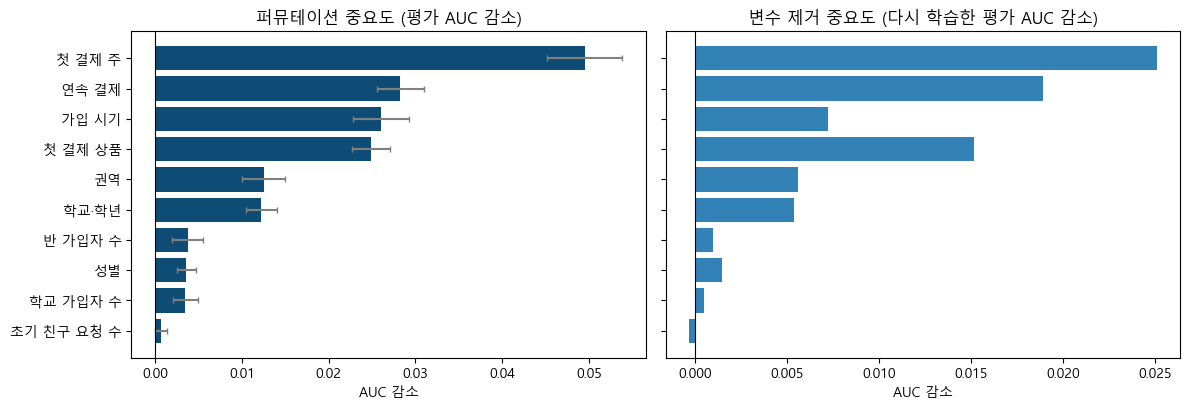

In [75]:
N_REPEAT = 30

def perm_importance(m, df, ycol='re7', n_repeat=N_REPEAT, seed=42):
    rng = np.random.default_rng(seed)
    base_auc = roc_auc_score(df[ycol], m.predict_proba(design(df))[:, 1])
    rows = []
    for v, (c, levels) in VARS.items():
        drops = []
        for _ in range(n_repeat):
            d = df.copy()
            d[c] = rng.permutation(d[c].values)
            drops.append(base_auc - roc_auc_score(d[ycol], m.predict_proba(design(d))[:, 1]))
        rows.append({'변수': v, '퍼뮤테이션 중요도': np.mean(drops), '표준편차': np.std(drops)})
    return pd.DataFrame(rows).set_index('변수')

def drop_importance(tr, te, ycol='re7'):
    full = roc_auc_score(te[ycol], fit(tr, ycol).predict_proba(design(te))[:, 1])
    out = {}
    for v in VARS:
        m = fit(tr, ycol, drop=v)
        out[v] = full - roc_auc_score(te[ycol], m.predict_proba(design(te, drop=v))[:, 1])
    return pd.Series(out, name='변수 제거 중요도')

imp = perm_importance(model, te).join(drop_importance(tr, te))
imp = imp.sort_values('퍼뮤테이션 중요도', ascending=False)
imp['퍼뮤테이션 순위'] = range(1, len(imp) + 1)
imp['변수 제거 순위'] = imp['변수 제거 중요도'].rank(ascending=False).astype(int)
imp['중요도 비중(%)'] = (imp['퍼뮤테이션 중요도'].clip(lower=0) / imp['퍼뮤테이션 중요도'].clip(lower=0).sum() * 100).round(1)
display(imp.round(4))

p = imp.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
axes[0].barh(p.index, p['퍼뮤테이션 중요도'], xerr=p['표준편차'], color=C1, ecolor='gray', capsize=2)
axes[0].set_title('퍼뮤테이션 중요도 (평가 AUC 감소)'); axes[0].set_xlabel('AUC 감소')
axes[1].barh(p.index, p['변수 제거 중요도'], color=C2)
axes[1].set_title('변수 제거 중요도 (다시 학습한 평가 AUC 감소)'); axes[1].set_xlabel('AUC 감소')
for ax in axes:
    ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout(); plt.show()

- 두 방법 모두 첫 결제 주가 1위임(퍼뮤테이션 중요도 0.0495, 전체의 30.0%). 퍼뮤테이션 기준으로 그다음은 연속 결제, 가입 시기, 첫 결제 상품임. 시기에 관한 두 변수(첫 결제 주, 가입 시기)와 첫 결제 방식에 관한 두 변수(연속 결제, 첫 결제 상품)가 중요도의 78%를 차지함
- 권역과 학교·학년이 5·6위(각 7% 안팎)이고, 반 가입자 수·성별·학교 가입자 수는 각 2% 안팎임
- 초기 친구 요청 수는 두 방법 모두 10위이고, 변수 제거 중요도가 음수(-0.0003)라 빼도 예측이 나빠지지 않음
- 가입 시기는 퍼뮤테이션 3위에서 변수 제거 4위로 내려감. 첫 결제 주와 정보가 겹쳐서, 가입 시기를 빼면 첫 결제 주가 그 몫을 일부 대신하기 때문으로 보임

### D-5. 민감도 확인: 연속 결제 경계를 1시간으로 바꿨을 때
- 결과 변수를 `re7_1h`(첫 결제 후 1시간 초과 7일 이내 결제)로 바꿔 부록 D-3, D-4를 다시 계산함
- 예측 재결제율 차이의 방향과 중요도 순위가 같으면 10분 경계 때문에 결론이 달라지지 않았다는 뜻임

In [76]:
eff_1h = effect_table(reg, 're7_1h')
cmp_eff = pd.DataFrame({'10분 경계 차이(%p)': eff['차이(%p)'], '1시간 경계 차이(%p)': eff_1h['차이(%p)']})
display(cmp_eff[eff['95% 하한'].notna()])

model_1h = fit(tr, 're7_1h')
imp_1h = perm_importance(model_1h, te, 're7_1h')
cmp_imp = pd.DataFrame({'10분 경계 순위': imp['퍼뮤테이션 순위'],
                        '1시간 경계 순위': imp_1h['퍼뮤테이션 중요도'].rank(ascending=False).astype(int),
                        '1시간 경계 중요도': imp_1h['퍼뮤테이션 중요도'].round(4)}).sort_values('10분 경계 순위')
print(f"1시간 경계 평가 AUC: {roc_auc_score(te.re7_1h, model_1h.predict_proba(design(te))[:, 1]):.3f}")
cmp_imp

10분 경계 차이(%p)  1시간 경계 차이(%p)
변수         구간                                   
초기 친구 요청 수 1~4건              0.23           0.02
           5~9건             -0.90          -0.73
           10~19건           -1.53          -1.54
           20~49건           -0.48          -0.61
           50건 이상            0.69           0.55
성별         남                -2.64          -2.66
학교·학년      중3                3.29           3.12
           고1                4.52           4.21
           고2                5.33           5.09
           고3                8.15           7.59
권역         광역시               1.83           1.75
           도                 4.60           4.37
학교 가입자 수   100명 미만           3.32           3.30
           300명 이상          -1.11          -1.01
반 가입자 수    10명 미만           -2.60          -2.40
           20~29명            1.61           1.69
           30명 이상            2.89           2.21
가입 시기      이후 가입자            5.90           5.70
첫 결제 주     1주               -4.79          -4.63
           2주              -10.14          -9.99
           3주              -14.88         -14.97
           4주 이후           -16.14         -15.92
첫 결제 상품    정가 상품            17.06          16.14
연속 결제      있음               14.73          13.61

1시간 경계 평가 AUC: 0.652


,10분 경계 순위,1시간 경계 순위,1시간 경계 중요도
변수,,,
첫 결제 주,1,1,0.0509
연속 결제,2,3,0.0260
가입 시기,3,2,0.0270
첫 결제 상품,4,4,0.0244
권역,5,6,0.0121
학교·학년,6,5,0.0122
반 가입자 수,7,9,0.0034
성별,8,8,0.0038
학교 가입자 수,9,7,0.0039


- 1시간 경계에서도 예측 재결제율 차이의 방향이 모든 구간에서 같고, 크기도 대부분 0.5%p 안에서 비슷함. 가장 많이 바뀐 것은 연속 결제 있음(14.7 → 13.6%p)과 정가 상품(17.1 → 16.1%p)임
- 중요도 순위는 첫 결제 주 1위, 첫 결제 상품 4위, 성별 8위, 초기 친구 요청 수 10위가 같음. 가입 시기와 연속 결제(2·3위), 권역과 학교·학년(5·6위), 학교 가입자 수와 반 가입자 수(7·9위)는 서로 자리를 바꿨는데, 바뀐 두 변수끼리는 중요도 차이가 작음(예: 권역 0.0121, 학교·학년 0.0122)
- 연속 결제 경계를 10분에서 1시간으로 바꿔도 부록 D의 결론은 달라지지 않음

### D-6. 첫 결제 주 차이는 그 시기의 무엇과 함께 움직였나

부록 D-3에서 다른 조건을 맞춰도 첫 결제 주에 따른 차이가 줄지 않았음(0주 대비 4주 이후 −16.1%p). 늦게 첫 결제한 사람이 원래 덜 사는 집단이라서가 아니라, 같은 조건이라도 늦은 시기에 첫 결제하면 재결제가 적었다는 뜻임. 그래서 부록 D-6~D-8은 재결제율이 크게 떨어진 0~4주(5/14~6/17)에 무엇이 함께 달라졌는지 봄.

| 가설 | 지표 | 데이터 | 범위 |
|---|---|---|---|
| ① 앱 전체 이용 감소 | 신규 가입자, 친구 요청 수, 친구 요청을 주고받은 유저 수 | 유저, 친구 요청 | 전체 유저 |
| ② 하트를 쓸 일 감소 | 투표 수, 투표한·투표 받은 유저 수, 힌트 사용 수 | 투표 기록, 포인트 기록 | 투표 표본 10개 학교 |
| ③ 힌트 가격 변경 | 5/18 힌트 가격 변경 전후 첫 결제자의 재결제율 | 결제, 포인트 기록 | 전체 첫 결제자 (부록 D-7) |

- 지표는 달력 주(5/14 일요일부터 7일)로 셈. 첫 결제 주의 재결제율과 나란히 놓고, 재결제율이 떨어질 때 같이 떨어진 지표를 후보로 남김
- 투표·포인트 기록은 10개 학교 유저(약 5천 명)만 있음. 이 학교들은 가입자의 거의 전원이 투표자라 학교 안의 시간 변화는 볼 수 있음
- 출석 기록은 5/27부터라 0~1주를 볼 수 없어 쓰지 않음

  accounts_userquestionrecord.csv: 107.5 MB
  accounts_pointhistory.csv: 110.8 MB


,첫 결제 주 7일 재결제율(%),신규 가입자,친구 요청 수,친구 요청을 주고받은 유저,투표 수 (표본),투표한 유저 (표본),투표 받은 유저 (표본),힌트 사용 수 (표본),힌트 사용 유저 (표본)
-1주 (05/07~),NaN,284682,6098942,347510,282661,3086,8363,14845,2582
0주 (05/14~),20.4,161483,4381013,465990,375984,3328,8673,23146,2791
1주 (05/21~),20.7,108871,3592515,493978,212741,2905,9342,11945,2272
2주 (05/28~),13.9,33728,1296562,407769,101058,2294,8850,5633,1593
3주 (06/04~),8.3,6770,294710,185019,31558,1247,5719,2019,804
4주 (06/11~),7.1,2142,95825,73645,9952,598,3310,759,364
5주 (06/18~),6.3,736,37220,36813,4297,307,2062,373,192
6주 (06/25~),3.6,370,17391,18678,2249,170,1232,271,136


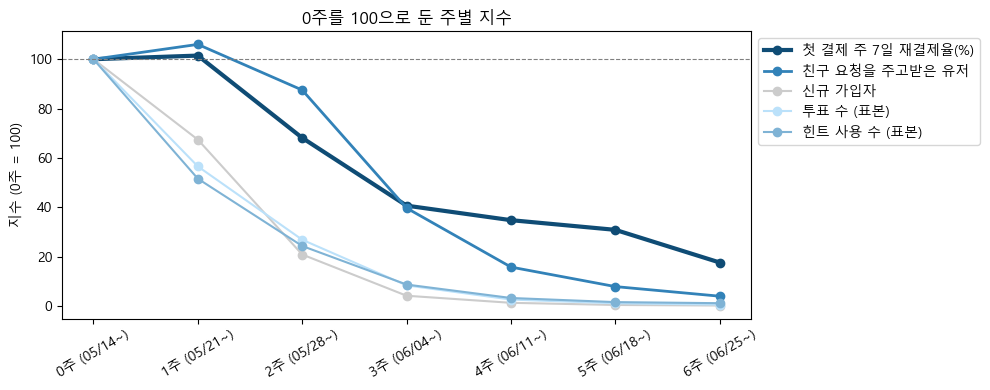

In [77]:
fetch_csv(['accounts_userquestionrecord', 'accounts_pointhistory'])
WEEKS6 = range(-1, 7)

env = pd.DataFrame(index=WEEKS6)
env['첫 결제 주 7일 재결제율(%)'] = buyer[buyer.obs7].groupby('first_week').re7.mean().mul(100).round(1)

# ① 앱 전체: 신규 가입자, 친구 요청
env['신규 가입자'] = base.groupby(week_no(base.signup_at)).size()
fr4 = read_cols('accounts_friendrequest', ['send_user_id', 'receive_user_id', 'created_at'], parse_dates=['created_at'])
fr4 = fr4[fr4.created_at < DATA_END]
env['친구 요청 수'] = fr4.groupby(week_no(fr4.created_at)).size()
user_day = pd.concat([fr4[['send_user_id', 'created_at']].rename(columns={'send_user_id': 'user_id'}),
                      fr4[['receive_user_id', 'created_at']].rename(columns={'receive_user_id': 'user_id'})], ignore_index=True)
del fr4
user_day['day'] = user_day.created_at.dt.normalize()
user_day = user_day[['user_id', 'day']].drop_duplicates()                     # 유저가 친구 요청을 주고받은 날 (부록 D-8에서도 씀)
env['친구 요청을 주고받은 유저'] = user_day.groupby(week_no(user_day.day)).user_id.nunique()

# ② 투표 표본: 투표, 힌트
uqr = read_cols('accounts_userquestionrecord', ['created_at', 'chosen_user_id', 'user_id'], parse_dates=['created_at'])
env['투표 수 (표본)'] = uqr.groupby(week_no(uqr.created_at)).size()
env['투표한 유저 (표본)'] = uqr.groupby(week_no(uqr.created_at)).user_id.nunique()
env['투표 받은 유저 (표본)'] = uqr.groupby(week_no(uqr.created_at)).chosen_user_id.nunique()
ph4 = read_cols('accounts_pointhistory', ['delta_point', 'created_at', 'user_id'], parse_dates=['created_at'])
HINT_PRICES = [-200, -300, -500, -1000]                                       # 초성 힌트에 쓴 포인트
hint = ph4[ph4.delta_point.isin(HINT_PRICES)]
env['힌트 사용 수 (표본)'] = hint.groupby(week_no(hint.created_at)).size()
env['힌트 사용 유저 (표본)'] = hint.groupby(week_no(hint.created_at)).user_id.nunique()

for c in env.columns:
    if '율' not in c:                                   # 재결제율은 결제가 없던 주(−1주)를 빈칸으로 둠
        env[c] = env[c].fillna(0).astype(int)
env.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in env.index]
display(env)

# 0주를 100으로 둔 지수로 그림 (0~6주)
idx_cols = ['첫 결제 주 7일 재결제율(%)', '친구 요청을 주고받은 유저', '신규 가입자', '투표 수 (표본)', '힌트 사용 수 (표본)']
idx = env[idx_cols].iloc[1:] / env[idx_cols].iloc[1] * 100
fig, ax = plt.subplots(figsize=(10, 4))
for c, col, lw in zip(idx_cols, [C1, C2, '#CCCCCC', C3, '#7FB3D5'], [3, 2, 1.5, 1.5, 1.5]):
    ax.plot(idx.index, idx[c], marker='o', color=col, linewidth=lw, label=c)
ax.axhline(100, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('0주를 100으로 둔 주별 지수'); ax.set_ylabel('지수 (0주 = 100)')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

- 재결제율은 0주 20.4%, 1주 20.7%로 유지되다 2주 13.9%, 3주 8.3%, 4주 7.1%로 떨어짐
- ① 친구 요청을 주고받은 유저는 0주 46.6만 명, 1주 49.4만 명으로 유지되다 2주 40.8만 명, 3주 18.5만 명, 4주 7.4만 명으로 줄어, 재결제율과 같은 시점에 꺾임. 신규 가입자와 친구 요청 수는 0주부터 줄기 시작해 재결제율보다 먼저 떨어짐
- ② 투표 표본의 투표 수(0주 37.6만 → 1주 21.3만)와 힌트 사용 수(2.3만 → 1.2만)는 1주에 이미 절반 가까이 줄었지만, 재결제율은 1주에 그대로였음. 투표 받은 유저 수는 2주까지 유지되다 3주부터 줄어 재결제율보다 한 주 늦게 꺾임. 어느 쪽도 재결제율과 시점이 맞지 않음. 다만 10개 학교 표본이라 전체 유저와 다를 수 있음
- 재결제율과 같은 시점에 움직인 지표는 실제로 앱을 쓰는 유저 수(친구 요청을 주고받은 유저)임. 부록 D-8에서 이 후보를 개인 단위로 확인함

### D-7. 5/18 힌트 가격 변경 전후의 재결제율 (가설 ③)
- 포인트 기록에서 힌트 가격이 바뀐 시각을 확인함. 바뀌기 전에는 한 글자에 300, 바뀐 뒤에는 첫째·둘째·셋째 글자가 200·500·1,000
- 0주(5/14~5/20) 첫 결제자를 가격 변경 전과 후로 나눠 7일 재결제율을 비교함. 변경이 일어난 5/18 21시대는 뺌

In [78]:
h518 = ph4[(ph4.created_at >= '2023-05-18 18:00') & (ph4.created_at < '2023-05-19 00:00') & ph4.delta_point.isin(HINT_PRICES)]
display(h518.pivot_table(index=h518.created_at.dt.strftime('%m/%d %H시'), columns='delta_point', values='user_id',
                         aggfunc='size', fill_value=0).rename_axis(index='시각', columns='힌트에 쓴 포인트'))

CHANGE_FROM, CHANGE_TO = pd.Timestamp('2023-05-18 21:00'), pd.Timestamp('2023-05-18 22:00')
w0 = buyer[buyer.obs7 & (buyer.first_week == 0)]
price_tbl = pd.DataFrame([
    {'구분': '변경 전 (5/14 ~ 5/18 20시대)', '첫 결제자': int((w0.first_at < CHANGE_FROM).sum()),
     '7일 재결제율(%)': round(w0.loc[w0.first_at < CHANGE_FROM, 're7'].mean() * 100, 1)},
    {'구분': '변경 후 (5/18 22시 ~ 5/20)', '첫 결제자': int((w0.first_at >= CHANGE_TO).sum()),
     '7일 재결제율(%)': round(w0.loc[w0.first_at >= CHANGE_TO, 're7'].mean() * 100, 1)}]).set_index('구분')
display(price_tbl)

d2 = buyer[buyer.obs7 & (buyer.first_at >= '2023-05-14') & (buyer.first_at < '2023-05-28')]
day_re = d2.groupby(d2.first_at.dt.strftime('%m/%d')).re7.agg(['size', 'mean'])
day_re.columns = ['첫 결제자', '7일 재결제율(%)']
day_re['7일 재결제율(%)'] = (day_re['7일 재결제율(%)'] * 100).round(1)
day_re.index.name = '첫 결제일'
day_re.T

힌트에 쓴 포인트,-1000,-500,-300,-200
시각,,,,
05/18 18시,0,0,217,0
05/18 19시,0,0,120,0
05/18 20시,0,0,117,0
05/18 21시,3,15,157,56
05/18 22시,12,63,11,209
05/18 23시,8,80,0,248


,첫 결제자,7일 재결제율(%)
구분,,
변경 전 (5/14 ~ 5/18 20시대),24472,20.1
변경 후 (5/18 22시 ~ 5/20),5340,21.8


첫 결제일,05/14,05/15,05/16,05/17,05/18,05/19,05/20,05/21,05/22,05/23,05/24,05/25,05/26,05/27
첫 결제자,9336.0,5206.0,4893.0,3439.0,2320.0,2091.0,2750.0,3068.0,2630.0,2574.0,2514.0,2253.0,1976.0,1864.0
7일 재결제율(%),20.4,20.8,21.4,17.8,17.1,22.0,22.9,21.6,21.5,20.3,21.4,21.3,20.7,16.8


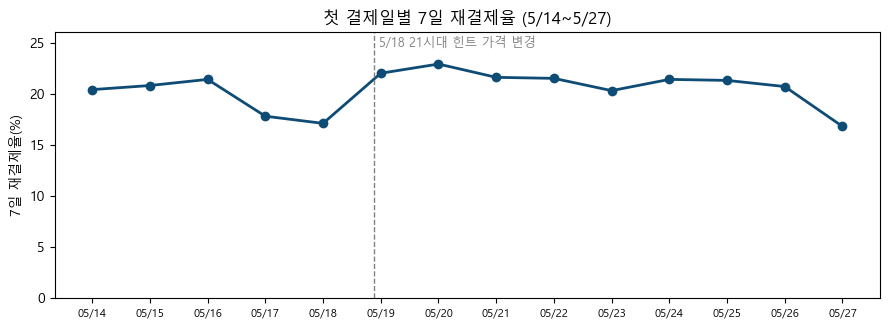

In [79]:
# 첫 결제일별 7일 재결제율 그래프 (점선 = 힌트 가격이 바뀐 5/18 21시대)
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(len(day_re))
ax.plot(x, day_re['7일 재결제율(%)'], color=C1, lw=2, marker='o')
chg = list(day_re.index).index('05/18') + 21 / 24
ax.axvline(chg, color='gray', ls='--', lw=1)
ax.text(chg + 0.1, 24.6, '5/18 21시대 힌트 가격 변경', color='gray', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(day_re.index, fontsize=8)
ax.set_ylim(0, 26); ax.set_ylabel('7일 재결제율(%)'); ax.set_title('첫 결제일별 7일 재결제율 (5/14~5/27)')
plt.tight_layout(); plt.show()

- 포인트 기록에서 5/18 21시대에 힌트 가격이 바뀐 것이 확인됨. 21시대부터 -200·-500·-1,000이 나타나고, 22시대부터 -300이 거의 사라짐
- 0주 첫 결제자의 7일 재결제율은 변경 전 20.1%(24,472명), 변경 후 21.8%(5,340명)로 오히려 조금 높음
- 날짜별로도 5/17 17.8%, 5/18 17.1%에서 5/19 22.0%, 5/20 22.9%로, 변경 뒤에 낮아지지 않음
- 힌트 가격 변경은 재결제율 하락의 원인으로 보기 어려움

### D-8. 같은 반 친구의 활동을 모형에 넣으면 첫 결제 주 차이가 줄어드나
- 부록 D-6에서 남은 후보(①)를 개인 단위로 확인함. 첫 결제자마다 '첫 결제일부터 7일 동안 친구 요청을 주고받은 같은 반 친구 수'(본인 제외)를 셈
- 본인의 활동은 쓰지 않음. 재결제 자체가 활동이라, 본인 활동을 넣으면 결과로 결과를 설명하게 됨. 같은 반 친구의 활동은 본인 결제와 떨어진 그 시기의 환경 지표임
- 이 변수를 부록 D 모형에 더해 다시 학습하고, 첫 결제 주의 예측 재결제율 차이(부록 D-3)가 얼마나 줄어드는지 봄. 크게 줄면 첫 결제 주 차이의 상당 부분을 같은 반 친구 활동의 감소로 설명할 수 있음
- 같은 반 친구의 친구 요청에는 그 친구가 본인과 주고받은 요청도 들어 있음. 본인이 활발하면 친구 활동도 조금 늘어나는 몫이 섞일 수 있음. 이 몫을 뺀 결과는 D-8 보충에서 봄

In [80]:
# 같은 반 친구가 친구 요청을 주고받은 날 → 첫 결제자의 7일 창에 들어오는 친구 수
mates = user_day.merge(base[['user_id', 'group_id']], on='user_id').rename(columns={'user_id': 'mate_id'})
fb = buyer[buyer.obs7 & buyer.group_id.notna()][['user_id', 'group_id', 'first_at']].copy()
fb['d0'] = fb.first_at.dt.normalize()
mm = fb.merge(mates, on='group_id')
mm = mm[(mm.mate_id != mm.user_id) & (mm.day >= mm.d0) & (mm.day < mm.d0 + RE_WINDOW)]
active_mates = mm.groupby('user_id').mate_id.nunique()
del mates, mm, user_day                                                       # 메모리 확보

MATES_LABELS = ['0명', '1~2명', '3~5명', '6~9명', '10명 이상']
rb['active_mates'] = rb.user_id.map(active_mates).fillna(0).astype(int)
rb['mates_bin'] = pd.cut(rb.active_mates, [-1, 0, 2, 5, 9, np.inf], labels=MATES_LABELS)
print(f"첫 결제 후 7일 동안 활동한 같은 반 친구 수: 중앙값 {rb.active_mates.median():.0f}명, 평균 {rb.active_mates.mean():.1f}명")

mates_rate = rb.groupby('mates_bin', observed=False).re7.agg(['size', 'mean'])
mates_rate.columns = ['첫 결제자', '7일 재결제율(%)']
mates_rate['7일 재결제율(%)'] = (mates_rate['7일 재결제율(%)'] * 100).round(1)
display(mates_rate.rename_axis('활동한 같은 반 친구 수'))

mix = pd.crosstab(rb.first_week_g, rb.mates_bin, normalize='index').mul(100).round(1)
display(mix.rename_axis(index='첫 결제 주', columns='활동한 같은 반 친구 수 (행 비중 %)'))

첫 결제 후 7일 동안 활동한 같은 반 친구 수: 중앙값 11명, 평균 10.5명


,첫 결제자,7일 재결제율(%)
활동한 같은 반 친구 수,,
0명,2417,6.1
1~2명,3248,11.2
3~5명,6432,14.4
6~9명,12611,18.2
10명 이상,33163,21.6


활동한 같은 반 친구 수 (행 비중 %),0명,1~2명,3~5명,6~9명,10명 이상
첫 결제 주,,,,,
0주,0.7,2.3,7.8,20.6,68.6
1주,1.5,4.6,11.9,24.4,57.6
2주,4.9,12.2,21.8,26.9,34.1
3주,18.7,28.1,23.1,16.0,14.1
4주 이후,61.9,20.4,6.8,4.3,6.6


In [81]:
# 부록 D 모형에 '활동한 같은 반 친구 수'를 더해 다시 학습
reg['mates_bin'] = reg.user_id.map(rb.set_index('user_id').mates_bin).astype(str)
VARS_BASE = dict(VARS)
VARS_MATES = dict(VARS)
VARS_MATES['활동한 같은 반 친구 수'] = ('mates_bin', MATES_LABELS)

def effect_with(vars_dict):
    # design, fit, effect_table은 전역 VARS를 쓰므로 잠시 바꿔서 계산한 뒤 되돌림
    global VARS
    saved = VARS
    VARS = vars_dict
    try:
        t = effect_table(reg)
        m = fit(tr.assign(mates_bin=reg.loc[tr.index, 'mates_bin']))
        auc = roc_auc_score(te.re7, m.predict_proba(design(te.assign(mates_bin=reg.loc[te.index, 'mates_bin'])))[:, 1])
    finally:
        VARS = saved
    return t, auc

eff_base, auc_base = effect_with(VARS_BASE)
eff_mates, auc_mates = effect_with(VARS_MATES)
print(f'평가 AUC: 기존 모형 {auc_base:.3f} → 같은 반 친구 활동 추가 {auc_mates:.3f}')

wk_cmp = pd.DataFrame({'기존 모형 차이(%p)': eff_base.loc['첫 결제 주', '차이(%p)'],
                       '친구 활동 추가 후 차이(%p)': eff_mates.loc['첫 결제 주', '차이(%p)']})
wk_cmp = wk_cmp[wk_cmp['기존 모형 차이(%p)'] != 0]
wk_cmp['줄어든 비율(%)'] = ((1 - wk_cmp['친구 활동 추가 후 차이(%p)'] / wk_cmp['기존 모형 차이(%p)']) * 100).round(1)
display(wk_cmp.rename_axis('첫 결제 주 (0주 대비)'))
display(eff_mates.loc['활동한 같은 반 친구 수'])

평가 AUC: 기존 모형 0.652 → 같은 반 친구 활동 추가 0.658


,기존 모형 차이(%p),친구 활동 추가 후 차이(%p),줄어든 비율(%)
첫 결제 주 (0주 대비),,,
1주,-4.79,-4.14,13.6
2주,-10.14,-8.44,16.8
3주,-14.88,-11.85,20.4
4주 이후,-16.14,-11.03,31.7


,인원,단순 재결제율(%),예측 재결제율(%),차이(%p),95% 하한,95% 상한
구간,,,,,,
0명 (기준),2413,6.01,8.52,0.00,NaN,NaN
1~2명,3247,11.24,12.28,3.75,1.96,5.55
3~5명,6431,14.35,14.11,5.59,3.93,7.24
6~9명,12611,18.21,17.62,9.10,7.50,10.69
10명 이상,33162,21.58,21.30,12.78,11.08,14.47


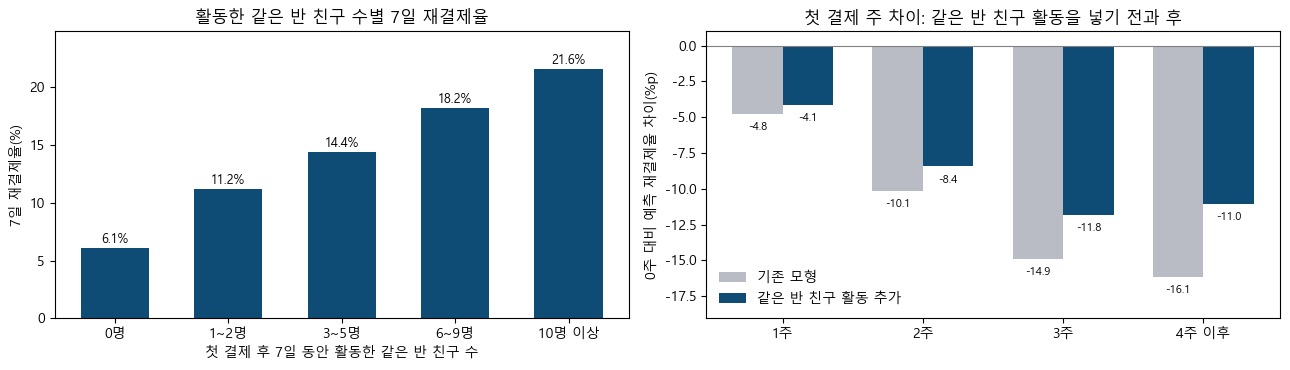

In [82]:
# 왼쪽: 활동한 같은 반 친구 수별 7일 재결제율 / 오른쪽: 친구 활동을 넣기 전후의 첫 결제 주 차이
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
r = mates_rate['7일 재결제율(%)']
ax.bar(r.index.astype(str), r, color=C1, width=0.6)
for i, v in enumerate(r):
    ax.text(i, v + 0.4, f'{v:.1f}%', ha='center', fontsize=9)
ax.set_ylim(0, r.max() * 1.15); ax.set_ylabel('7일 재결제율(%)')
ax.set_xlabel('첫 결제 후 7일 동안 활동한 같은 반 친구 수'); ax.set_title('활동한 같은 반 친구 수별 7일 재결제율')

ax = axes[1]
x = np.arange(len(wk_cmp)); w = 0.36
b0 = wk_cmp['기존 모형 차이(%p)']; b1 = wk_cmp['친구 활동 추가 후 차이(%p)']
ax.bar(x - w / 2, b0, w, color=GRAY_BAR, label='기존 모형')
ax.bar(x + w / 2, b1, w, color=C1, label='같은 반 친구 활동 추가')
for i in range(len(x)):
    ax.text(x[i] - w / 2, b0.iloc[i] - 0.5, f'{b0.iloc[i]:.1f}', ha='center', va='top', fontsize=8)
    ax.text(x[i] + w / 2, b1.iloc[i] - 0.5, f'{b1.iloc[i]:.1f}', ha='center', va='top', fontsize=8)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(wk_cmp.index); ax.set_ylim(b0.min() * 1.18, 1)
ax.set_ylabel('0주 대비 예측 재결제율 차이(%p)'); ax.set_title('첫 결제 주 차이: 같은 반 친구 활동을 넣기 전과 후')
ax.legend(frameon=False, loc='lower left')
plt.tight_layout(); plt.show()

- 첫 결제 후 7일 동안 친구 요청을 주고받은 같은 반 친구가 0명이면 7일 재결제율이 6.1%, 10명 이상이면 21.6%임
- 늦은 첫 결제자일수록 활동한 같은 반 친구가 적음. 0주 첫 결제자는 68.6%가 10명 이상이었지만, 4주 이후 첫 결제자는 61.9%가 0명임
- 이 변수를 부록 D 모형에 더하면 첫 결제 주의 차이가 줄어듦. 4주 이후 −16.1%p → −11.0%p(31.7% 감소), 3주 −14.9%p → −11.9%p(20.4% 감소). 다른 조건이 같아도 활동한 같은 반 친구가 10명 이상이면 0명보다 12.8%p 높음
- 늦은 시기에 재결제가 적었던 이유의 일부(4주 이후 기준 약 3분의 1)는 같은 반 친구들이 앱을 덜 쓰게 된 것으로 설명됨. 함께 쓰는 친구가 줄면 받는 투표와 하트를 쓸 일이 줄어든다는 흐름으로 볼 수 있지만, 이 분석으로 그 과정까지 확인한 것은 아님
- 나머지 차이(4주 이후 −11.0%p)는 여전히 남음. 친구 요청은 앱 활동의 일부만 잡으므로, 다른 활동(받은 투표, 질문 확인 등)까지 재면 더 설명될 수 있음. 시험 기간 같은 데이터 밖 요인도 배제하지 못함
- 평가 AUC는 0.652에서 0.658로 조금 오름

#### D-8 보충. 본인과 주고받은 요청을 빼도 결과가 같은가
- D-8의 '활동한 같은 반 친구'에는 그 친구가 첫 결제자 본인과 주고받은 요청도 들어 있음. 본인이 활발하면 친구 수가 늘어나는 몫이 섞여, 본인 활동으로 재결제를 설명하는 셈이 될 수 있음
- 같은 반 친구가 그날 주고받은 상대가 첫 결제자 본인뿐이면 그날은 활동으로 세지 않고 다시 셈. 상대가 둘 이상이거나 본인이 아니면 그대로 활동으로 셈
- 다시 센 변수로 D-8 모형을 다시 학습해 첫 결제 주 차이와 친구 수 효과를 비교함. 결과가 거의 같으면 D-8 결론에 본인 활동이 섞인 영향은 작다는 뜻임

In [83]:
# 같은 반 친구의 활동에서 첫 결제자 본인과 주고받은 요청을 뺌
fr8 = read_cols('accounts_friendrequest', ['send_user_id', 'receive_user_id', 'created_at'], parse_dates=['created_at'])
fr8 = fr8[fr8.created_at < DATA_END]
fr8['day'] = fr8.created_at.dt.normalize()
cols8 = ['mate_id', 'other_id', 'day']
pd8 = pd.concat([fr8[['send_user_id', 'receive_user_id', 'day']].set_axis(cols8, axis=1),
                 fr8[['receive_user_id', 'send_user_id', 'day']].set_axis(cols8, axis=1)], ignore_index=True)
del fr8
# 친구(mate)가 그날 요청을 주고받은 상대 수와, 상대가 한 명뿐일 때 그 상대
md8 = pd8.drop_duplicates().groupby(['mate_id', 'day']).other_id.agg(n_other='size', only_other='first').reset_index()
del pd8
md8 = md8.merge(base[['user_id', 'group_id']].rename(columns={'user_id': 'mate_id'}), on='mate_id')
mm8 = fb.merge(md8, on='group_id')
mm8 = mm8[(mm8.mate_id != mm8.user_id) & (mm8.day >= mm8.d0) & (mm8.day < mm8.d0 + RE_WINDOW)]
keep8 = (mm8.n_other >= 2) | (mm8.only_other != mm8.user_id)
pairs_all = mm8[['user_id', 'mate_id']].drop_duplicates()
pairs_keep = mm8.loc[keep8, ['user_id', 'mate_id']].drop_duplicates()
active_x = mm8[keep8].groupby('user_id').mate_id.nunique()
del md8, mm8

rb['active_mates_x'] = rb.user_id.map(active_x).fillna(0).astype(int)
rb['mates_bin_x'] = pd.cut(rb.active_mates_x, [-1, 0, 2, 5, 9, np.inf], labels=MATES_LABELS)
n_drop = len(pairs_all) - len(pairs_keep)
print(f'본인과 주고받은 요청 때문에만 활동으로 세어진 (첫 결제자, 같은 반 친구) 쌍: {n_drop:,} / {len(pairs_all):,} ({n_drop / len(pairs_all) * 100:.2f}%)')
print(f'활동한 같은 반 친구 수 평균: {rb.active_mates.mean():.2f}명 → {rb.active_mates_x.mean():.2f}명')
print(f'친구 수 구간이 바뀐 첫 결제자: {(rb.mates_bin.astype(str) != rb.mates_bin_x.astype(str)).mean() * 100:.2f}%')

rate_x = pd.DataFrame({
    'D-8 기준 재결제율(%)': rb.groupby('mates_bin', observed=False).re7.mean().mul(100).round(1),
    '본인 요청 제외 첫 결제자': rb.groupby('mates_bin_x', observed=False).size(),
    '본인 요청 제외 재결제율(%)': rb.groupby('mates_bin_x', observed=False).re7.mean().mul(100).round(1)})
display(rate_x.rename_axis('활동한 같은 반 친구 수'))

reg['mates_bin'] = reg.user_id.map(rb.set_index('user_id').mates_bin_x).astype(str)
eff_x, auc_x = effect_with(VARS_MATES)
reg['mates_bin'] = reg.user_id.map(rb.set_index('user_id').mates_bin).astype(str)   # D-8 값으로 되돌림
print(f'평가 AUC: 기존 모형 {auc_base:.3f} / D-8 {auc_mates:.3f} / 본인 요청 제외 {auc_x:.3f}')

wk_x = pd.DataFrame({'기존 모형(%p)': eff_base.loc['첫 결제 주', '차이(%p)'],
                     'D-8(%p)': eff_mates.loc['첫 결제 주', '차이(%p)'],
                     '본인 요청 제외(%p)': eff_x.loc['첫 결제 주', '차이(%p)']})
wk_x = wk_x[wk_x['기존 모형(%p)'] != 0]
wk_x['D-8 줄어든 비율(%)'] = ((1 - wk_x['D-8(%p)'] / wk_x['기존 모형(%p)']) * 100).round(1)
wk_x['본인 요청 제외 줄어든 비율(%)'] = ((1 - wk_x['본인 요청 제외(%p)'] / wk_x['기존 모형(%p)']) * 100).round(1)
display(wk_x.rename_axis('첫 결제 주 (0주 대비)'))
display(pd.DataFrame({'D-8(%p)': eff_mates.loc['활동한 같은 반 친구 수', '차이(%p)'],
                      '본인 요청 제외(%p)': eff_x.loc['활동한 같은 반 친구 수', '차이(%p)']}).rename_axis('활동한 같은 반 친구 수 (0명 대비)'))
rb.drop(columns=['active_mates_x', 'mates_bin_x'], inplace=True)
del pairs_all, pairs_keep, active_x

본인과 주고받은 요청 때문에만 활동으로 세어진 (첫 결제자, 같은 반 친구) 쌍: 1,312 / 610,298 (0.21%)
활동한 같은 반 친구 수 평균: 10.55명 → 10.52명
친구 수 구간이 바뀐 첫 결제자: 0.38%


,D-8 기준 재결제율(%),본인 요청 제외 첫 결제자,본인 요청 제외 재결제율(%)
활동한 같은 반 친구 수,,,
0명,6.1,2445,6.2
1~2명,11.2,3276,11.4
3~5명,14.4,6458,14.3
6~9명,18.2,12633,18.3
10명 이상,21.6,33059,21.6


평가 AUC: 기존 모형 0.652 / D-8 0.658 / 본인 요청 제외 0.658


,기존 모형(%p),D-8(%p),본인 요청 제외(%p),D-8 줄어든 비율(%),본인 요청 제외 줄어든 비율(%)
첫 결제 주 (0주 대비),,,,,
1주,-4.79,-4.14,-4.15,13.6,13.4
2주,-10.14,-8.44,-8.44,16.8,16.8
3주,-14.88,-11.85,-11.85,20.4,20.4
4주 이후,-16.14,-11.03,-11.06,31.7,31.5


,D-8(%p),본인 요청 제외(%p)
활동한 같은 반 친구 수 (0명 대비),,
0명 (기준),0.00,0.00
1~2명,3.75,3.93
3~5명,5.59,5.46
6~9명,9.10,9.11
10명 이상,12.78,12.67


- 본인과 주고받은 요청 때문에만 '활동'으로 세어진 (첫 결제자, 같은 반 친구) 쌍은 610,298쌍 중 1,312쌍(0.21%)임. 활동한 같은 반 친구 수 평균은 10.55명에서 10.52명이 되고, 친구 수 구간이 바뀐 첫 결제자는 0.38%임
- 구간별 7일 재결제율은 0명 6.2%, 10명 이상 21.6%로 D-8과 0.2%p 안에서 같음
- 다시 센 변수를 모형에 넣어도 4주 이후 첫 결제 주 차이는 −11.03%p에서 −11.06%p로 거의 같고(줄어든 비율 31.7% → 31.5%), 10명 이상의 효과는 +12.78%p에서 +12.67%p, 평가 AUC는 0.658로 같음
- D-8의 결론(4주 이후 첫 결제 주 차이의 약 3분의 1을 같은 반 친구 활동 감소로 설명)에 본인 활동이 섞인 영향은 작음

---
## 부록 E. 상점 재방문과 상점 진입 보충
- E-1~E-3: 3-1~3-2와 같은 대상(핵클 기간에 첫 결제한 7일 관찰 대상 626명)
- E-4·E-5: 3-3과 같은 결제 경험자 전체의 방문. 6-1·6-2는 같은 계산을 5장 세그먼트별로 한 것임

### E-1. 상점 재방문 직전 행동과 재결제
- 관찰 구간 안의 상점 화면 진입(`view_shop` 이벤트)마다 같은 세션의 바로 앞 이벤트를 봄. 세션의 첫 이벤트면 '그 밖'에 넣음
- 상점 안에서 다시 진입한 이벤트도 1건으로 세므로, 이 절의 '방문'은 상점 화면 진입 이벤트 수임
- 방문 후 30분 안에 재결제(10분 초과 7일 이내 결제)가 있으면 재결제로 이어진 방문으로 봄

In [84]:
ACTION = {'click_question_open': '받은 질문을 연 직후', 'click_bottom_navigation_questions': '질문 탭을 누른 직후',
          'click_attendance': '출석체크 직후', 'view_shop': '상점 안에서 다시', 'click_purchase': '상점 안에서 다시',
          'complete_question': '질문 세트를 마친 직후', 'click_question_start': '질문 세트를 마친 직후',
          'skip_question': '질문 세트를 마친 직후', 'click_notice_detail': '공지를 본 직후'}
hev['prev_key'] = hev.groupby(['user_id', 'session_id']).event_key.shift()
visit = hev[(hev.event_key == 'view_shop') & (hev.t > QUICK_GAP) & (hev.t <= RE_WINDOW)].copy()
visit['직전 행동'] = visit.prev_key.map(ACTION).fillna('그 밖')

# 방문 후 30분 안의 재결제
rp = re_pay[['user_id', 'created_at']].sort_values('created_at')
rp['created_at'] = rp.created_at.astype('datetime64[ns]')                # merge_asof는 두 시각의 단위가 같아야 함
visit['event_datetime'] = visit.event_datetime.astype('datetime64[ns]')
visit = pd.merge_asof(visit.sort_values('event_datetime'), rp.rename(columns={'created_at': 'next_re'}),
                      left_on='event_datetime', right_on='next_re', by='user_id', direction='forward',
                      tolerance=pd.Timedelta(minutes=30))
visit['재결제'] = visit.next_re.notna()

act = visit.groupby('직전 행동').agg(방문=('재결제', 'size'), 재결제로_이어진_방문=('재결제', 'sum'))
act['방문 중 재결제(%)'] = (act['재결제로_이어진_방문'] / act['방문'] * 100).round(1)
act['방문 비중(%)'] = (act['방문'] / act['방문'].sum() * 100).round(1)
act['재결제 비중(%)'] = (act['재결제로_이어진_방문'] / act['재결제로_이어진_방문'].sum() * 100).round(1)
act = act.rename(columns={'재결제로_이어진_방문': '재결제로 이어진 방문'}).sort_values('방문', ascending=False)
print(f'관찰 구간 안 상점 방문 {len(visit):,}건 (방문한 유저 {visit.user_id.nunique():,}명)')
display(act)
print("'그 밖'에 들어간 바로 앞 이벤트")
visit.loc[visit['직전 행동'] == '그 밖', 'prev_key'].fillna('(세션의 첫 이벤트)').value_counts().head(8)

관찰 구간 안 상점 방문 203건 (방문한 유저 106명)


,방문,재결제로 이어진 방문,방문 중 재결제(%),방문 비중(%),재결제 비중(%)
직전 행동,,,,,
그 밖,67,21,31.3,33.0,42.0
받은 질문을 연 직후,50,13,26.0,24.6,26.0
출석체크 직후,34,1,2.9,16.7,2.0
질문 탭을 누른 직후,24,5,20.8,11.8,10.0
상점 안에서 다시,15,3,20.0,7.4,6.0
질문 세트를 마친 직후,11,5,45.5,5.4,10.0
공지를 본 직후,2,2,100.0,1.0,4.0


'그 밖'에 들어간 바로 앞 이벤트


prev_key
launch_app                          16
view_timeline_tap                   14
view_lab_tap                        13
view_questions_tap                   8
$session_start                       6
click_bottom_navigation_timeline     2
click_appbar_chat_rooms              2
click_friend_invite                  1
Name: count, dtype: int64

- 첫 결제자의 상점 화면 진입 203건 중 '그 밖'(33.0%)을 빼면 받은 질문을 연 직후가 50건(24.6%)으로 가장 많고, 그중 26.0%가 재결제로 이어짐
- '그 밖'은 앱을 켠 직후(`launch_app`, `$session_start` 22건)와 타임라인·실험실·질문 화면을 보던 중(35건)이 대부분임
- 출석체크 직후 진입은 34건(16.7%)이지만 재결제는 1건(2.9%)뿐임. 출석체크 뒤 상점에 들르는 것은 결제 목적이 아닌 경우가 많은 것으로 보임
- 결제 경험자의 방문 전체로 넓혀 봐도 받은 질문 열기 뒤의 상점 진입이 가장 높음(부록 E-4)
- 진입이 203건뿐이라 구간별 비율은 참고로만 봄

### E-2. 상점 재방문 때 하트 잔액과 재결제
- 첫 결제자의 상점 재방문을 진입 때 하트 잔액으로 나눔. 하트 잔액은 진입 이벤트에 찍힌 `heart_balance` 값임
- 핵클 `heart_balance`는 결제 직후 바로 바뀌지 않고 몇 분 뒤 이벤트부터 늘어난 값이 찍히는 경우가 많음(2026-11-13 확인). 실제 잔액과 어긋날 수 있어 참고로만 봄

In [85]:
HB_BINS = [-1, 99, 199, 299, 499, 999, np.inf]
HB_LABELS = ['0~99', '100~199', '200~299', '300~499', '500~999', '1000 이상']
visit['하트 잔액'] = pd.cut(visit.heart_balance, HB_BINS, labels=HB_LABELS)
hb = visit.groupby('하트 잔액', observed=False).agg(방문=('재결제', 'size'), 재결제로_이어진_방문=('재결제', 'sum'))
hb['방문 중 재결제(%)'] = (hb['재결제로_이어진_방문'] / hb['방문'] * 100).round(1)
hb = hb.rename(columns={'재결제로_이어진_방문': '재결제로 이어진 방문'})
print(f'하트 잔액이 비어 있는 방문: {int(visit.heart_balance.isna().sum())}건')
hb

하트 잔액이 비어 있는 방문: 0건


,방문,재결제로 이어진 방문,방문 중 재결제(%)
하트 잔액,,,
0~99,31,10,32.3
100~199,36,12,33.3
200~299,13,3,23.1
300~499,67,15,22.4
500~999,42,10,23.8
1000 이상,14,0,0.0


- 잔액이 0~199일 때 진입 중 재결제가 32~33%로, 300~999일 때(22~24%)보다 높음. 잔액 1000 이상에서 들어간 14건은 재결제가 없음
- 하트가 떨어졌을 때 다시 산다는 가설과 같은 방향이지만, 진입이 203건뿐이고 잔액 값이 늦게 찍히는 문제가 있어 근거로 쓰기에는 약함

### E-3. 상점 화면 진입 횟수별 재결제율
- 유저마다 관찰 구간 안의 상점 화면 진입(`view_shop` 이벤트) 횟수를 세고 7일 재결제율을 비교함. 몇 분 사이에 다시 들어간 것도 따로 셈
- 재결제한 사람은 결제하려고 상점에 들어가므로 진입 횟수가 늘어나는 역방향 관계가 섞여 있음

In [86]:
n_visit = target.user_id.map(visit.groupby('user_id').size()).fillna(0)
target['상점 진입'] = pd.cut(n_visit, [-1, 0, 1, 2, 4, np.inf], labels=['0회', '1회', '2회', '3~4회', '5회 이상'])
vt = target.groupby('상점 진입', observed=False).re7.agg(['size', 'sum', 'mean'])
vt.columns = ['유저', '재결제자', '7일 재결제율(%)']
vt['7일 재결제율(%)'] = (vt['7일 재결제율(%)'] * 100).round(1)
vt['유저 비중(%)'] = (vt['유저'] / vt['유저'].sum() * 100).round(1)
vt

,유저,재결제자,7일 재결제율(%),유저 비중(%)
상점 진입,,,,
0회,520,2,0.4,83.1
1회,60,5,8.3,9.6
2회,24,8,33.3,3.8
3~4회,16,7,43.8,2.6
5회 이상,6,4,66.7,1.0


- 첫 결제 후 7일 안에 상점에 다시 들어가지 않은 유저가 83.1%이고, 이들의 재결제율은 0.4%(2명)임
- 한 번이라도 다시 들어간 106명의 재결제율은 22.6%(24명)이고, 진입 횟수가 많을수록 높아짐
- 재결제자 26명 중 24명이 상점에 다시 들어갔음. 재결제율을 올리려면 상점 재방문부터 늘려야 한다는 근거가 되지만, 결제하려는 사람이 상점에 들어가는 역방향 관계도 섞여 있음

### E-4. 방문 안에서 무엇을 한 뒤 상점에 가나
- 행동마다 그 행동이 있었던 방문 중, 그 행동을 처음 한 뒤에 상점에 들어간 방문의 비율을 셈
- 전체 방문의 상점 진입률(3-3)과 비교해 높으면 상점으로 이어지는 행동임

In [87]:
rows = []
for k, name in ACTS5.items():
    first_act = ev5[ev5.event_key == k].groupby('visit').event_datetime.min()
    d = pd.DataFrame({'act': first_act}).join(shop_at.rename('shop'))
    rows.append({'행동': name, '그 행동이 있는 방문': len(d), '방문 비중(%)': round(len(d) / len(vis) * 100, 1),
                 '행동 뒤 상점 진입(%)': round((d.shop >= d.act).mean() * 100, 2)})
act5 = pd.DataFrame(rows).set_index('행동').sort_values('행동 뒤 상점 진입(%)', ascending=False)
display(act5)
print(f'전체 방문의 상점 진입률: {vis.shop.mean():.2%}')

,그 행동이 있는 방문,방문 비중(%),행동 뒤 상점 진입(%)
행동,,,
받은 질문 열기,26767,25.3,7.39
출석체크,22374,21.2,6.70
공지 상세 보기,15259,14.4,6.60
알림 센터 열기,22475,21.3,6.25
질문 탭 누르기,40106,38.0,6.21
채팅방 열기,13208,12.5,5.30
질문 세트 완료,16812,15.9,5.06
프로필 보기,30450,28.8,4.52
실험실 보기,51525,48.8,4.32


전체 방문의 상점 진입률: 3.61%


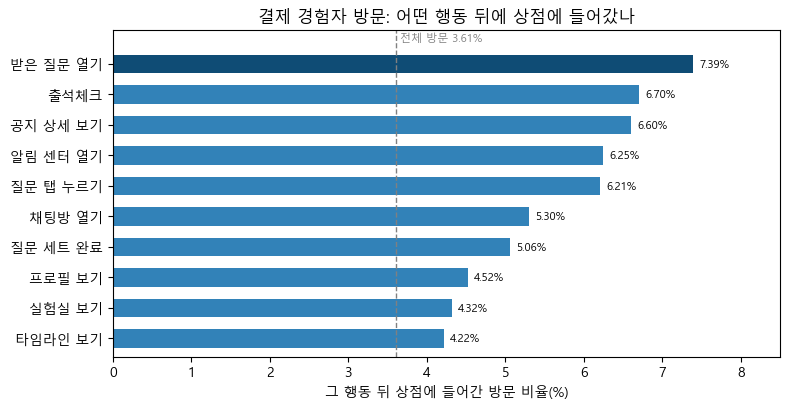

In [88]:
# 행동 뒤 상점 진입률 그래프 (점선 = 전체 방문의 상점 진입률)
v = act5['행동 뒤 상점 진입(%)']
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(v.index, v, color=[C1] + [C2] * (len(v) - 1), height=0.6)
for i, x in enumerate(v):
    ax.text(x + 0.08, i, f'{x:.2f}%', va='center', fontsize=8)
base_rate = vis.shop.mean() * 100
ax.axvline(base_rate, color='gray', ls='--', lw=1)
ax.text(base_rate + 0.05, -0.75, f'전체 방문 {base_rate:.2f}%', color='gray', fontsize=8)
ax.set_ylim(len(v) - 0.4, -1.1); ax.set_xlim(0, v.max() * 1.15)
ax.set_xlabel('그 행동 뒤 상점에 들어간 방문 비율(%)'); ax.set_title('결제 경험자 방문: 어떤 행동 뒤에 상점에 들어갔나')
plt.tight_layout(); plt.show()

- 받은 질문 열기 뒤 상점 진입이 7.39%로 가장 높고, 출석체크(6.70%), 공지 상세 보기(6.60%), 알림 센터 열기(6.25%), 질문 탭 누르기(6.21%)가 그다음임. 전체 방문의 상점 진입률(3.61%)의 약 2배임
- 가장 흔한 행동인 실험실 보기(방문의 48.8%)와 타임라인 보기(47.6%) 뒤의 상점 진입은 4.2~4.3%로 낮음
- 상점으로 이어지는 길은 받은 질문 확인이 중심임. 방문의 절반 가까이를 차지하는 실험실·타임라인 화면은 상점으로 이어지는 계기가 약함

### E-5. 상점에 들어가서 무엇을 했나
- 상점에 들어간 방문을 상점 안에서 누른 것으로 나눔. 유료 상품 = `click_purchase` 중 상품 이름에 '하트'가 있는 것, 무료충전소 = 상품 이름이 '무료충전소'인 것
- 무료충전소를 누른 방문과 누르지 않은 방문의 방문 중 결제 비율을 비교해, 무료 하트가 결제를 대신하는지 봄

In [89]:
clk = ev5[(ev5.event_key == 'click_purchase') & ev5.visit.isin(vis[vis.shop].index)].copy()
clk['what'] = np.where(clk.item_name.fillna('').str.contains('무료'), '무료충전소',
                       np.where(clk.item_name.fillna('').str.contains('하트'), '유료 상품', '그 밖'))
sv = vis[vis.shop].copy()
sv['free'] = sv.index.isin(clk[clk.what == '무료충전소'].visit)
sv['paid_click'] = sv.index.isin(clk[clk.what == '유료 상품'].visit)
kind = np.select([sv.free & sv.paid_click, sv.free, sv.paid_click], ['무료충전소와 유료 상품', '무료충전소만', '유료 상품만'], '아무것도 안 누름')
shop_tbl = sv.groupby(kind).agg(방문=('paid', 'size'), 방문_중_결제=('paid', 'mean'))
shop_tbl['방문 비중(%)'] = (shop_tbl['방문'] / len(sv) * 100).round(1)
shop_tbl['방문_중_결제'] = (shop_tbl['방문_중_결제'] * 100).round(1)
shop_tbl.columns = ['방문', '방문 중 결제(%)', '방문 비중(%)']
display(shop_tbl.rename_axis('상점에서 누른 것').sort_values('방문', ascending=False))
print(f'상점에 들어간 방문 {len(sv):,}회 중 무료충전소를 누른 방문 {sv.free.mean():.1%}, 유료 상품을 누른 방문 {sv.paid_click.mean():.1%}')
print(f'방문 중 결제: 무료충전소를 누른 방문 {sv[sv.free].paid.mean():.1%} / 누르지 않은 방문 {sv[~sv.free].paid.mean():.1%}')

,방문,방문 중 결제(%),방문 비중(%)
상점에서 누른 것,,,
아무것도 안 누름,2003,0.0,52.6
무료충전소만,898,0.0,23.6
유료 상품만,475,82.9,12.5
무료충전소와 유료 상품,435,70.1,11.4


상점에 들어간 방문 3,811회 중 무료충전소를 누른 방문 35.0%, 유료 상품을 누른 방문 23.9%
방문 중 결제: 무료충전소를 누른 방문 22.9% / 누르지 않은 방문 15.9%


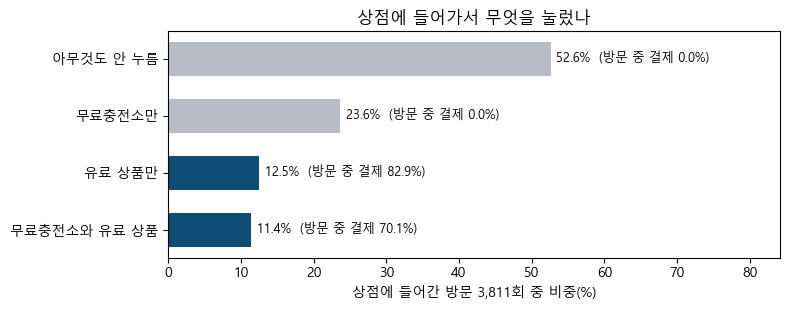

In [90]:
# 상점 안에서 누른 것별 방문 비중 그래프 (괄호 = 방문 중 결제 비율)
st = shop_tbl.reindex(['아무것도 안 누름', '무료충전소만', '유료 상품만', '무료충전소와 유료 상품'])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(st.index, st['방문 비중(%)'], color=[GRAY_BAR, GRAY_BAR, C1, C1], height=0.6); ax.invert_yaxis()
for i, (s, p) in enumerate(zip(st['방문 비중(%)'], st['방문 중 결제(%)'])):
    ax.text(s + 0.8, i, f'{s}%  (방문 중 결제 {p}%)', va='center', fontsize=9)
ax.set_xlim(0, st['방문 비중(%)'].max() * 1.6)
ax.set_xlabel(f'상점에 들어간 방문 {len(sv):,}회 중 비중(%)'); ax.set_title('상점에 들어가서 무엇을 눌렀나')
plt.tight_layout(); plt.show()

- 상점에 들어간 방문 3,811회 중 52.6%는 아무것도 누르지 않았고, 23.6%는 무료충전소만 누름. 두 경우 모두 방문 중 결제는 없음
- 유료 상품을 누른 방문(유료 상품만 12.5%, 무료충전소와 함께 11.4%)은 70.1~82.9%가 결제로 이어짐
- 무료충전소를 누른 방문의 결제율(22.9%)이 누르지 않은 방문(15.9%)보다 높은 것은 무료충전소와 유료 상품을 함께 누른 방문이 섞였기 때문임. 무료충전소만 누른 방문은 결제가 없어, 상점 방문의 약 4분의 1은 무료 하트로 해결하고 나가는 경로임
- 상점에 들어와도 절반은 아무것도 누르지 않고 나감. 상점 진입을 늘리는 것과 함께, 들어온 뒤 유료 상품을 누르게 하는 것도 과제임

---
## 부록 F. 7월 복귀: 계기가 있으면 결제 경험자도 다시 산다

부록 B-1에서 8주(07/09~)부터 결제 건수가 다시 늘었음. 이 장은 그 반등이 누구에게서, 언제, 어떻게 나왔는지 보고, 끊긴 결제가 다시 이어진 사례로서 재결제 방안의 근거를 찾음.

| 용어 | 정의 |
|---|---|
| 첫 결제 | 그 유저의 첫 번째 결제 (0장과 같음) |
| 연속 결제 | 첫 결제 후 10분 안의 결제 (0장과 같음) |
| 7일 안 재구매 | 직전 결제 후 7일 안에 다시 한 결제 (연속 결제 제외) |
| 복귀 구매 | 직전 결제 후 7일이 넘게 지나 다시 한 결제. 한동안 결제가 없던 결제 경험자가 돌아와 산 것 |
| 몰린 날 | 하루 첫 결제자가 50명 이상인 날 (7월 중 7/11·12·13·18·20·21) |
| 피크 시각 | 몰린 날 중 첫 결제가 가장 많았던 1시간 |

- 0장의 7일 재결제율은 첫 결제 후 7일만 보므로, 이 장의 복귀 구매(대부분 첫 결제 후 한두 달 뒤)는 재결제율에 잡히지 않음
- 알림이나 광고 같은 운영 기록은 데이터에 없음. 계기는 결제 시각과 앱 안 행동으로 추정함

In [91]:
fetch_csv(['event_receipts', 'accounts_attendance'])

JUL = (pd.Timestamp('2023-07-01'), pd.Timestamp('2023-07-23'))   # 일별로 볼 기간 (7/1~7/22)
SPIKE_MIN = 50                                                    # 하루 첫 결제자가 이 수 이상이면 몰린 날
DAY_NAMES = ['월', '화', '수', '목', '금', '토', '일']

# 결제마다 종류 붙이기 (위 용어 표)
p6 = pay.copy()
p6['prev_at'] = p6.groupby('user_id').created_at.shift()          # 같은 유저의 직전 결제 시각
p6 = p6.merge(base[['user_id', 'period']], on='user_id', how='left')
p6['kind'] = np.select([(p6.seq == 1) & (p6.period == PERIODS[0]), p6.seq == 1, p6.gap <= QUICK_GAP,
                        (p6.created_at - p6.prev_at) > RE_WINDOW],
                       ['첫 결제 (이전 가입자)', '첫 결제 (이후 가입자)', '연속 결제', '복귀 구매'], '7일 안 재구매')
KINDS6 = ['첫 결제 (이전 가입자)', '첫 결제 (이후 가입자)', '연속 결제', '7일 안 재구매', '복귀 구매']

er = read_cols('event_receipts', ['created_at', 'event_id', 'user_id'], parse_dates=['created_at'])   # 이벤트 참여 기록
print(p6.kind.value_counts().reindex(KINDS6).to_string())

  event_receipts.csv: 0.0 MB
  accounts_attendance.csv: 40.1 MB
kind
첫 결제 (이전 가입자)    25631
첫 결제 (이후 가입자)    32635
연속 결제             5857
7일 안 재구매         25721
복귀 구매             3100


### F-1. 8주 이후 늘어난 첫 결제 이후 결제는 누구의 결제인가
- 부록 B-1의 '그 밖의 첫 결제 이후 결제'(첫 결제 후 10분이 지나서 한 결제)를 결제한 사람의 첫 결제 시점으로 나눔

In [92]:
o6 = p6[(p6.seq > 1) & (p6.gap > QUICK_GAP)].copy()
o6['week'] = week_no(o6.created_at)
SRC = ['첫 결제 후 7일 안 (재결제율에 잡힘)', '첫 결제가 0~4주 (5/14~6/17)', '그 밖']
o6['src'] = np.select([o6.gap <= RE_WINDOW, week_no(o6.first_at) <= 4], SRC[:2], SRC[2])
src_tbl = o6[o6.week.between(5, 12)].pivot_table(index='week', columns='src', values='id', aggfunc='size', fill_value=0)[SRC]
src_tbl['합계'] = src_tbl.sum(axis=1)
src_tbl['결제한 사람'] = o6[o6.week.between(5, 12)].groupby('week').user_id.nunique()
src_tbl.index = [f'{w}주 ({(PAY_START + w * WEEK):%m/%d}~)' for w in src_tbl.index]
display(src_tbl)

late = o6[o6.week.between(8, 12)]
late_users = late.drop_duplicates('user_id')
print(f'8~12주 그 밖의 첫 결제 이후 결제: {len(late):,}건 / {len(late_users):,}명')
print('그중 첫 결제 월:', late_users.first_at.dt.strftime('%Y-%m').value_counts().sort_index().to_dict())
print('직전 결제 후 30일 넘은 결제 비율:', f'{((late.created_at - late.prev_at) > pd.Timedelta(days=30)).mean():.1%}')

src,첫 결제 후 7일 안 (재결제율에 잡힘),첫 결제가 0~4주 (5/14~6/17),그 밖,합계,결제한 사람
5주 (06/18~),39,186,0,225,175
6주 (06/25~),5,69,1,75,60
7주 (07/02~),2,49,1,52,43
8주 (07/09~),50,158,11,219,162
9주 (07/16~),32,190,12,234,164
10주 (07/23~),22,270,10,302,211
11주 (07/30~),7,188,8,203,162
12주 (08/06~),19,193,10,222,152


8~12주 그 밖의 첫 결제 이후 결제: 1,180건 / 819명
그중 첫 결제 월: {'2023-05': 645, '2023-06': 75, '2023-07': 77, '2023-08': 22}
직전 결제 후 30일 넘은 결제 비율: 58.4%


- 8주(07/09~)부터 그 밖의 첫 결제 이후 결제가 7주 52건에서 주 203~302건으로 늘었고 12주까지 유지됨
- 늘어난 결제의 대부분은 첫 결제가 0~4주(5/14~6/17)인 유저의 결제임(8~12주 주 158~270건). 같은 주 새 첫 결제자의 7일 안 재결제는 주 7~50건뿐임
- 8~12주에 다시 산 819명 중 645명(79%)이 5월 첫 결제자이고, 이 결제의 58.4%는 직전 결제 후 30일이 넘어서 일어남. 5~6월에 결제하고 한동안 쉬던 유저가 7월에 돌아와 다시 산 것임
- 이 복귀 구매는 0장의 7일 재결제율에 잡히지 않음. 재결제율이 낮게 이어지는 동안에도 결제 경험자의 복귀 구매는 따로 있었음

### F-2. 7월 일별 결제 구성
- 7/1~7/22의 결제를 날짜별로 위 다섯 종류로 나누고, 같은 날의 이벤트 참여 건수(`event_receipts`, '코드잇 은행 가입 이벤트' 등)를 함께 놓음

kind,첫 결제 (이전 가입자),첫 결제 (이후 가입자),연속 결제,7일 안 재구매,복귀 구매,이벤트 참여
07/01 (토),9,7,1,2,4,4
07/02 (일),6,6,3,4,14,5
07/03 (월),6,5,1,1,5,1
07/04 (화),4,9,1,1,4,2
07/05 (수),2,4,0,3,7,1
07/06 (목),6,6,0,0,1,1
07/07 (금),5,2,1,0,2,0
07/08 (토),3,4,0,2,8,2
07/09 (일),10,3,1,2,13,1
07/10 (월),2,4,0,0,4,0


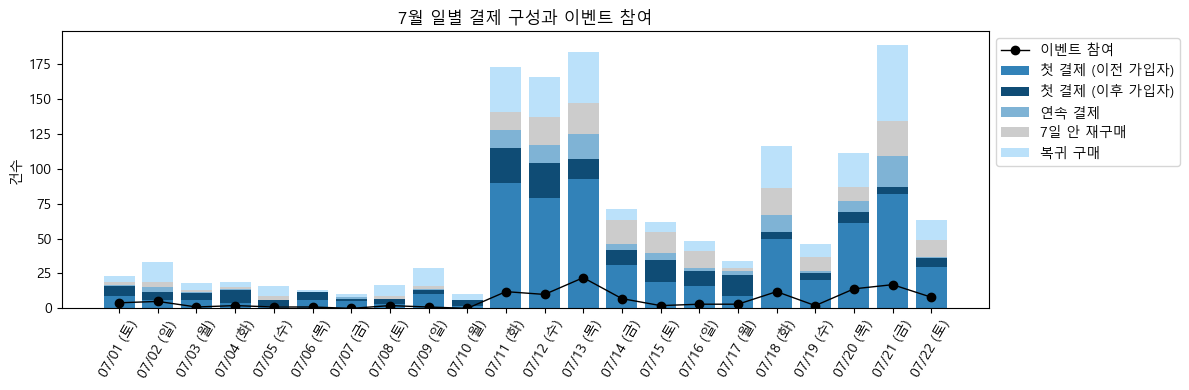

In [93]:
jul = p6[(p6.created_at >= JUL[0]) & (p6.created_at < JUL[1])].copy()
jul['day'] = jul.created_at.dt.normalize()
days = pd.date_range(JUL[0], JUL[1] - pd.Timedelta(days=1))
daily = jul.pivot_table(index='day', columns='kind', values='id', aggfunc='size', fill_value=0)
daily = daily.reindex(index=days, columns=KINDS6, fill_value=0)
ev_jul = er[(er.created_at >= JUL[0]) & (er.created_at < JUL[1])]
daily['이벤트 참여'] = ev_jul.groupby(ev_jul.created_at.dt.normalize()).size().reindex(days, fill_value=0)
daily.index = [f'{d:%m/%d} ({DAY_NAMES[d.dayofweek]})' for d in days]
display(daily)

fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(daily))
for k, c in zip(KINDS6, [C2, C1, '#7FB3D5', '#CCCCCC', C3]):
    ax.bar(daily.index, daily[k], bottom=bottom, color=c, label=k)
    bottom += daily[k].values
ax.plot(daily.index, daily['이벤트 참여'], color='black', marker='o', linewidth=1, label='이벤트 참여')
ax.set_title('7월 일별 결제 구성과 이벤트 참여'); ax.set_ylabel('건수')
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); ax.tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

- 7/1~7/10에는 첫 결제가 하루 6~16건, 복귀 구매가 하루 1~14건이었음
- 7/11(화)부터 사흘 동안 첫 결제가 하루 104~115건으로 늘었고, 대부분 이전 가입자(90·79·93명)임. 같은 날 복귀 구매도 32·29·37건, 이벤트 참여도 12·10·22건으로 함께 늘었음
- 7/18(화), 7/20(목), 7/21(금)에도 같은 모양이 반복됨(첫 결제 55·69·87건, 복귀 구매 30·24·55건)
- 몰린 날 다음 날부터 7일 안 재구매가 이어짐(7/14~16 하루 17·15·12건, 7/1~7/10은 하루 0~4건)

### F-3. 몰린 날에는 결제가 특정 시각에 몰렸나
- 날마다 첫 결제가 가장 많았던 1시간(피크 시각)과 그 1시간이 하루 첫 결제에서 차지하는 비중을 구함
- 몰린 날에는 같은 1시간에 복귀 구매가 몇 건 있었는지도 셈

In [94]:
first_jul = jul[jul.kind.str.startswith('첫 결제')]
ret_jul = jul[jul.kind == '복귀 구매']
rows = []
for d in days:
    f = first_jul[first_jul.day == d]
    r = ret_jul[ret_jul.day == d]
    hr = int(f.created_at.dt.hour.value_counts().idxmax()) if len(f) else None
    rows.append({'날짜': f'{d:%m/%d} ({DAY_NAMES[d.dayofweek]})', '첫 결제': len(f), '피크 시각': hr,
                 '피크 1시간 첫 결제': int((f.created_at.dt.hour == hr).sum()) if len(f) else 0,
                 '복귀 구매': len(r), '피크 1시간 복귀 구매': int((r.created_at.dt.hour == hr).sum()) if len(f) else 0})
hour_tbl = pd.DataFrame(rows).set_index('날짜')
hour_tbl['피크 1시간 비중(%)'] = (hour_tbl['피크 1시간 첫 결제'] / hour_tbl['첫 결제'] * 100).round(1)
hour_tbl['몰린 날'] = np.where(hour_tbl['첫 결제'] >= SPIKE_MIN, '예', '')
display(hour_tbl)

spike_days = [d for d in days if len(first_jul[first_jul.day == d]) >= SPIKE_MIN]
peak_hour = {d: int(first_jul[first_jul.day == d].created_at.dt.hour.value_counts().idxmax()) for d in spike_days}
print('몰린 날과 피크 시각:', {f'{d:%m/%d}': f'{h}시' for d, h in peak_hour.items()})
for d, h in peak_hour.items():
    f = first_jul[(first_jul.day == d) & (first_jul.created_at.dt.hour == h)]
    print(f'{d:%m/%d} {h}시 첫 결제 10분 단위:', (f.created_at.dt.minute // 10 * 10).value_counts().sort_index().to_dict())

,첫 결제,피크 시각,피크 1시간 첫 결제,복귀 구매,피크 1시간 복귀 구매,피크 1시간 비중(%),몰린 날
날짜,,,,,,,
07/01 (토),16,21,3,4,0,18.8,
07/02 (일),12,23,2,14,0,16.7,
07/03 (월),11,1,2,5,0,18.2,
07/04 (화),13,22,3,4,0,23.1,
07/05 (수),6,20,1,7,0,16.7,
07/06 (목),12,21,3,1,0,25.0,
07/07 (금),7,0,2,2,0,28.6,
07/08 (토),7,23,2,8,0,28.6,
07/09 (일),13,7,2,13,0,15.4,


몰린 날과 피크 시각: {'07/11': '18시', '07/12': '21시', '07/13': '19시', '07/18': '19시', '07/20': '20시', '07/21': '20시'}
07/11 18시 첫 결제 10분 단위: {0: 2, 10: 22, 20: 20, 30: 6, 40: 1, 50: 4}
07/12 21시 첫 결제 10분 단위: {0: 13, 10: 13, 20: 5, 30: 4, 40: 3, 50: 3}
07/13 19시 첫 결제 10분 단위: {0: 6, 10: 7, 20: 7, 30: 9, 40: 7, 50: 4}
07/18 19시 첫 결제 10분 단위: {0: 7, 10: 7, 20: 3, 30: 4, 40: 3, 50: 1}
07/20 20시 첫 결제 10분 단위: {0: 1, 20: 5, 30: 5, 40: 8, 50: 10}
07/21 20시 첫 결제 10분 단위: {0: 8, 10: 6, 20: 6, 30: 3, 40: 1, 50: 4}


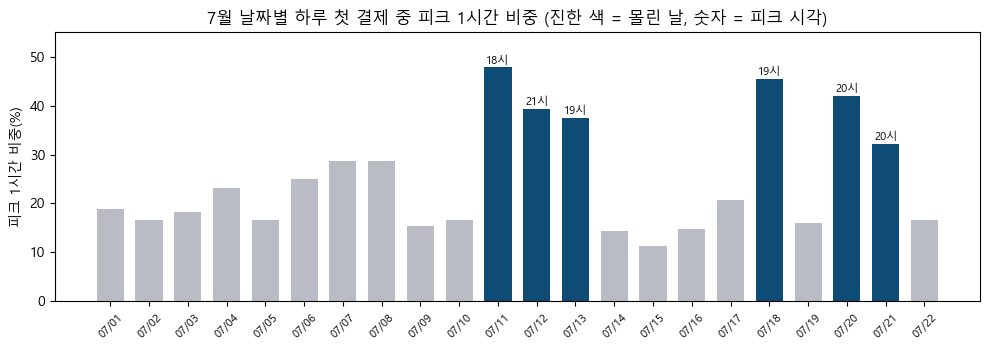

In [95]:
# 날짜별 피크 1시간 비중 그래프 (진한 색 = 몰린 날, 숫자 = 피크 시각)
spike = (hour_tbl['몰린 날'] == '예').values
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar([i[:5] for i in hour_tbl.index], hour_tbl['피크 1시간 비중(%)'], color=np.where(spike, C1, GRAY_BAR), width=0.7)
for i, (y, s, h) in enumerate(zip(hour_tbl['피크 1시간 비중(%)'], spike, hour_tbl['피크 시각'])):
    if s:
        ax.text(i, y + 0.8, f'{int(h)}시', ha='center', fontsize=8)
ax.set_ylim(0, hour_tbl['피크 1시간 비중(%)'].max() * 1.15); ax.set_ylabel('피크 1시간 비중(%)')
ax.set_title('7월 날짜별 하루 첫 결제 중 피크 1시간 비중 (진한 색 = 몰린 날, 숫자 = 피크 시각)')
plt.setp(ax.get_xticklabels(), rotation=45, fontsize=8)
plt.tight_layout(); plt.show()

- 평소에는 하루 첫 결제 중 가장 많은 1시간이 11~29%를 차지함. 몰린 날에는 32~48%가 저녁의 한 시간에 몰림(7/11 18시, 7/12 21시, 7/13 19시, 7/18 19시, 7/20·7/21 20시)
- 7/11에는 18:10~18:29의 20분 동안 42명이 첫 결제함
- 같은 1시간에 복귀 구매도 몰림(7/11 32건 중 14건, 7/13 37건 중 14건 등). 첫 결제자와 결제 경험자가 같은 계기로 함께 들어온 것으로 보임
- 몰린 시각이 날마다 다르고 한 시간 안에 집중되는 것은, 정해진 시각에 유저를 불러온 운영 조치(알림 등)와 맞는 모양임. 운영 기록이 없어 확정할 수는 없음

### F-4. 7/11~13 첫 결제자는 누구인가
- 대상: 7/11~7/13에 첫 결제한 유저. 비교 모집단: 7/10까지 가입했고 그때까지 결제하지 않은 유저(이 사흘에 첫 결제할 수 있었던 사람)
- 첫 결제율(10만 명당) = 그 구간에서 이 사흘에 첫 결제한 수 ÷ 그 구간의 모집단 수 × 100,000
- 학교·반 몰림: 같은 학교나 같은 반에서 여러 명이 나왔는지 봄. 한 학교에 몰렸다면 입소문, 흩어졌다면 앱 전체에 걸친 계기로 볼 수 있음

In [96]:
D0, D1 = pd.Timestamp('2023-07-11'), pd.Timestamp('2023-07-14')
first_at_u = buyer.set_index('user_id').first_at
b6 = base.copy()
b6['first_at'] = b6.user_id.map(first_at_u)
b6['signup_m'] = b6.signup_at.dt.strftime('%Y-%m')
grp = b6[(b6.first_at >= D0) & (b6.first_at < D1)].copy()
pool = b6[(b6.signup_at < D0) & ~(b6.first_at < D0)]
print(f'7/11~13 첫 결제자: {len(grp):,}명 / 비교 모집단(7/10까지 가입, 미결제): {len(pool):,}명')

def share_table(col, order=None):
    a, b_ = grp[col].astype(str).value_counts(), pool[col].astype(str).value_counts()
    t = pd.DataFrame({'첫 결제자': a, '비중(%)': (a / len(grp) * 100).round(1),
                      '모집단 비중(%)': (b_ / len(pool) * 100).round(1), '첫 결제율(10만 명당)': (a / b_ * 1e5).round(1)})
    t = t.reindex(order) if order else t.sort_values('첫 결제자', ascending=False)
    t['첫 결제자'] = t['첫 결제자'].fillna(0).astype(int)
    return t

for col, order in [('period', PERIODS), ('signup_m', ['2023-04', '2023-05', '2023-06', '2023-07']),
                   ('gender_k', ['여', '남']), ('school_grade', ['중2', '중3', '고1', '고2', '고3']),
                   ('region', ['수도권', '광역시', '도'])]:
    display(share_table(col, order).rename_axis(col))
display(share_table('sido').head(8).rename_axis('시·도 (첫 결제자 많은 순)'))

sc = grp.school_id.value_counts()
gc = grp.group_id.value_counts()
print(f'학교 {sc.size}곳에 흩어짐 / 상위 10개 학교 비중 {sc.head(10).sum() / len(grp):.1%} / '
      f'2명 이상 나온 학교 {int((sc >= 2).sum())}곳({int(sc[sc >= 2].sum())}명) / 2명 이상 나온 반 {int((gc >= 2).sum())}개({int(gc[gc >= 2].sum())}명)')
print('첫 결제 상품:', buyer[buyer.user_id.isin(grp.user_id)].first_product.value_counts().to_dict())
print(f"이벤트 참여자(전체 기간): {int(grp.user_id.isin(er.user_id).sum())}명")

7/11~13 첫 결제자: 326명 / 비교 모집단(7/10까지 가입, 미결제): 614,937명


,첫 결제자,비중(%),모집단 비중(%),첫 결제율(10만 명당)
period,,,,
이전 가입자,262,80.4,54.1,78.8
이후 가입자,64,19.6,45.9,22.7


,첫 결제자,비중(%),모집단 비중(%),첫 결제율(10만 명당)
signup_m,,,,
2023-04,38,11.7,2.8,221.1
2023-05,259,79.4,94.5,44.6
2023-06,16,4.9,2.7,98.0
2023-07,13,4.0,0.1,3225.8


,첫 결제자,비중(%),모집단 비중(%),첫 결제율(10만 명당)
gender_k,,,,
여,68,20.9,59.6,18.6
남,258,79.1,40.4,103.7


,첫 결제자,비중(%),모집단 비중(%),첫 결제율(10만 명당)
school_grade,,,,
중2,39,12.0,23.4,27.0
중3,74,22.7,21.6,55.8
고1,132,40.5,29.4,73.1
고2,51,15.6,18.5,44.8
고3,30,9.2,7.1,68.8


,첫 결제자,비중(%),모집단 비중(%),첫 결제율(10만 명당)
region,,,,
수도권,195,59.8,46.3,68.6
광역시,22,6.7,20.5,17.4
도,109,33.4,33.2,53.4


,첫 결제자,비중(%),모집단 비중(%),첫 결제율(10만 명당)
시·도 (첫 결제자 많은 순),,,,
경기도,126,38.7,28.8,71.2
서울특별시,66,20.2,11.3,94.8
충청남도,49,15.0,6.4,125.3
경상북도,22,6.7,4.3,82.9
충청북도,15,4.6,3.4,71.9
대구광역시,10,3.1,5.2,31.3
전라남도,9,2.8,4.4,33.3
전라북도,6,1.8,4.9,19.8


학교 258곳에 흩어짐 / 상위 10개 학교 비중 10.4% / 2명 이상 나온 학교 49곳(117명) / 2명 이상 나온 반 18개(39명)
첫 결제 상품: {'heart.777': 302, 'heart.1000': 21, 'heart.200': 3}
이벤트 참여자(전체 기간): 9명


- 7/11~13 첫 결제자 326명 중 80.4%가 이전 가입자임. 4월 가입자의 첫 결제율(10만 명당 221.1)이 5월 가입자(44.6)의 약 5배로, 앱 초기부터 쓰던 유저가 많이 돌아옴
- 남학생이 79.1%(모집단 40.4%)로, 첫 결제율이 여학생의 약 5.6배임. 학년은 고1(40.5%), 지역은 수도권(59.8%)과 충남(15.0%)이 많음
- 326명이 258개 학교에 흩어져 있고 상위 10개 학교를 합쳐도 10.4%임. 한 학교나 지역의 입소문보다는 앱 전체에 걸친 계기로 보임
- 92.6%가 특가 heart.777로 첫 결제했고, 이벤트 참여자는 9명뿐이라 이벤트가 사람을 불러온 것은 아님
- 7월 가입자(13명, 첫 결제율 3,225.8)는 모집단이 작아 해석하지 않음

### F-5. 7/11~13 첫 결제자는 앱을 쉬다 돌아왔나
- 친구 요청: 첫 결제 직전 마지막 친구 요청(보낸 것과 받은 것)이 첫 결제보다 며칠 앞이었는지 셈
- 출석: 출석 기록(`accounts_attendance`, 5/27~)이 있는 유저가 바로 전 주(7/4~7/10)와 7/11~7/13에 출석했는지 봄. 출석 기록은 앱 사용자 일부만 잡힘

In [97]:
import json

fr = read_cols('accounts_friendrequest', ['send_user_id', 'receive_user_id', 'created_at'], parse_dates=['created_at'])
side6 = pd.concat([fr[['send_user_id', 'created_at']].rename(columns={'send_user_id': 'user_id'}),
                   fr[['receive_user_id', 'created_at']].rename(columns={'receive_user_id': 'user_id'})], ignore_index=True)
del fr
side6 = side6[side6.user_id.isin(grp.user_id)].merge(grp[['user_id', 'first_at']], on='user_id')
last_fr = side6[side6.created_at < side6.first_at].groupby('user_id').created_at.max()
idle = (grp.first_at - grp.user_id.map(last_fr)).dt.days
IDLE_LABELS = ['같은 날', '1~7일', '8~30일', '31~60일', '61일 이상']
idle_tbl = pd.cut(idle, [-1, 0, 7, 30, 60, np.inf], labels=IDLE_LABELS).value_counts().reindex(IDLE_LABELS)
display(pd.DataFrame({'첫 결제자': idle_tbl, '비중(%)': (idle_tbl / len(grp) * 100).round(1)})
        .rename_axis('직전 친구 요청 후 경과일'))
print('친구 요청 기록이 없는 첫 결제자:', int(idle.isna().sum()))

att = read_cols('accounts_attendance', ['attendance_date_list', 'user_id'])
att = att[att.user_id.isin(grp.user_id)]
att_days = att.attendance_date_list.apply(lambda s: set(json.loads(s)) if isinstance(s, str) else set())
week_before = {f'2023-07-{d:02d}' for d in range(4, 11)}
same_days = {'2023-07-11', '2023-07-12', '2023-07-13'}
print(f'출석 기록이 있는 첫 결제자 {len(att)}명 중 7/4~7/10 출석 {int(att_days.apply(lambda x: bool(x & week_before)).sum())}명, '
      f'7/11~7/13 출석 {int(att_days.apply(lambda x: bool(x & same_days)).sum())}명')

,첫 결제자,비중(%)
직전 친구 요청 후 경과일,,
같은 날,44,13.5
1~7일,7,2.1
8~30일,34,10.4
31~60일,213,65.3
61일 이상,28,8.6


친구 요청 기록이 없는 첫 결제자: 0


출석 기록이 있는 첫 결제자 258명 중 7/4~7/10 출석 9명, 7/11~7/13 출석 204명


- 첫 결제 직전 마지막 친구 요청이 31~60일 전인 유저가 65.3%, 61일 이상이 8.6%임. 73.9%가 한두 달 넘게 친구 요청이 없다가 첫 결제함
- 출석 기록이 있는 258명 중 바로 전 주(7/4~7/10)에 출석한 사람은 9명뿐인데, 7/11~13에는 204명이 출석함
- 앱을 떠나 있던 유저가 그날 돌아와 출석하고 첫 결제까지 한 것임

### F-6. 같은 날 돌아온 결제 경험자와, 이때 첫 결제한 사람의 재결제
- 7/11~13의 복귀 구매(직전 결제 후 7일이 넘게 지나 다시 한 결제)를 한 사람이 언제 첫 결제했고 무엇을 샀는지 봄
- 7/11~13 첫 결제자의 7일 재결제율(0장 기준)을 다른 시기 첫 결제자와 비교함

In [98]:
ret = jul[(jul.kind == '복귀 구매') & (jul.created_at >= D0) & (jul.created_at < D1)]
print(f'7/11~13 복귀 구매: {len(ret)}건 / {ret.user_id.nunique()}명')
print('첫 결제 월:', ret.first_at.dt.strftime('%Y-%m').value_counts().sort_index().to_dict())
prod_ret = ret.productId.value_counts()
print('상품:', prod_ret.to_dict(), f'/ 정가 상품 비중 {(1 - prod_ret.get("heart.777", 0) / len(ret)):.1%}')
gap_days = (ret.created_at - ret.prev_at).dt.days
print('직전 결제 후 경과일:', pd.cut(gap_days, [7, 30, 45, 60, np.inf], labels=['8~30일', '31~45일', '46~60일', '61일 이상'])
      .value_counts().sort_index().to_dict())

after7 = daily.loc[[i for i in daily.index if i[:5] in ('07/14', '07/15', '07/16')], '7일 안 재구매']
print('7/14~16 7일 안 재구매:', after7.to_dict())

obs6 = buyer[buyer.obs7]
cmp_rows = [('0~2주 첫 결제자 (5/14~6/3)', obs6.first_week.between(0, 2)),
            ('5~7주 첫 결제자 (6/18~7/8)', obs6.first_week.between(5, 7)),
            ('7/11~13 첫 결제자', (obs6.first_at >= D0) & (obs6.first_at < D1)),
            ('9~11주 첫 결제자 (7/16~8/3)', obs6.first_week.between(9, 11))]
cmp6 = pd.DataFrame([{'구분': n, '첫 결제자': int(m.sum()), '재결제자': int(obs6.loc[m, 're7'].sum()),
                      '7일 재결제율(%)': round(obs6.loc[m, 're7'].mean() * 100, 1)} for n, m in cmp_rows]).set_index('구분')
display(cmp6)

7/11~13 복귀 구매: 98건 / 98명
첫 결제 월: {'2023-05': 80, '2023-06': 17, '2023-07': 1}
상품: {'heart.1000': 50, 'heart.200': 41, 'heart.777': 5, 'heart.4000': 2} / 정가 상품 비중 94.9%
직전 결제 후 경과일: {'8~30일': 15, '31~45일': 24, '46~60일': 59, '61일 이상': 0}
7/14~16 7일 안 재구매: {'07/14 (금)': 17, '07/15 (토)': 15, '07/16 (일)': 12}


,첫 결제자,재결제자,7일 재결제율(%)
구분,,,
0~2주 첫 결제자 (5/14~6/3),54121,10625,19.6
5~7주 첫 결제자 (6/18~7/8),432,21,4.9
7/11~13 첫 결제자,326,26,8.0
9~11주 첫 결제자 (7/16~8/3),678,29,4.3


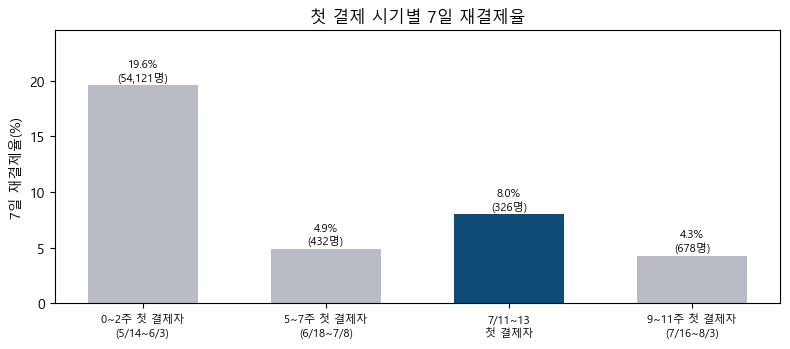

In [99]:
# 첫 결제 시기별 7일 재결제율 그래프
r6 = cmp6['7일 재결제율(%)']
labels = [n.replace(' (', '\n(').replace('7/11~13 ', '7/11~13\n') for n in cmp6.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(labels, r6, color=[C1 if n.startswith('7/11') else GRAY_BAR for n in cmp6.index], width=0.6)
for i, (y, n) in enumerate(zip(r6, cmp6['첫 결제자'])):
    ax.text(i, y + 0.4, f'{y}%\n({n:,}명)', ha='center', fontsize=8)
ax.set_ylim(0, r6.max() * 1.25); ax.set_ylabel('7일 재결제율(%)'); ax.set_title('첫 결제 시기별 7일 재결제율')
plt.setp(ax.get_xticklabels(), fontsize=8)
plt.tight_layout(); plt.show()

- 7/11~13 복귀 구매 98명 중 80명이 5월 첫 결제자이고, 59명은 직전 결제 후 46~60일 동안 결제가 없었음
- 94.9%가 정가 상품(heart.1000 50건, heart.200 41건 등)을 샀음. 특가가 아니라 제값을 내고 다시 산 것임
- 같은 계기로 첫 결제한 326명의 7일 재결제율은 8.0%로, 같은 시기 평소 첫 결제자(4.9%, 4.3%)보다 높지만 0~2주 첫 결제자(19.6%)의 절반에 못 미침
- 계기 하나로 새 첫 결제와 결제 경험자의 복귀 구매는 함께 늘었지만, 새 첫 결제자가 7일 안에 다시 사게 만들려면 첫 결제 뒤의 장치가 따로 필요함

### F-7. 피크 시각 결제 직전에 앱에서 무엇을 했나 (핵클, 7/18~)
- 7/11~13은 핵클 로그 이전이라, 같은 모양이 반복된 7/18·7/20·7/21의 피크 시각 결제를 봄
- 대상: 핵클 기간(7/18~8/10)의 첫 결제와 복귀 구매. 몰린 날의 피크 시각 결제와 그 밖의 결제로 나눔
- 결제 직전 30분 안에 각 행동이 한 번이라도 있었던 결제의 비율을 비교함. 유저 연결은 3-1의 `sess2user`를 씀

In [100]:
hk6 = p6[(p6.created_at >= HK_START) & p6.kind.isin(['첫 결제 (이전 가입자)', '첫 결제 (이후 가입자)', '복귀 구매'])].copy()
hk6['day'] = hk6.created_at.dt.normalize()
hk6['peak'] = [(d in peak_hour) and (t.hour == peak_hour[d]) for d, t in zip(hk6.day, hk6.created_at)]

parts = []
for ch in read_cols('hackle_events', ['event_datetime', 'event_key', 'session_id'], parse_dates=['event_datetime'], chunksize=2_000_000):
    ch['user_id'] = ch.session_id.map(sess2user)
    parts.append(ch[ch.user_id.isin(hk6.user_id)][['user_id', 'event_datetime', 'event_key']])
ev6 = pd.concat(parts, ignore_index=True)
ev6['user_id'] = ev6.user_id.astype('int64')

m6 = hk6[['id', 'user_id', 'created_at', 'peak']].merge(ev6, on='user_id')
m6 = m6[(m6.event_datetime <= m6.created_at) & (m6.event_datetime >= m6.created_at - pd.Timedelta(minutes=30))]
ACTS = {'click_appbar_alarm_center': '알림 센터 열기', 'click_notice_detail': '공지 상세 보기',
        'click_attendance': '출석체크', 'click_question_open': '받은 질문 열기'}
flags = pd.DataFrame({name: m6[m6.event_key == k].groupby('id').size().reindex(hk6.id).notna().values
                      for k, name in ACTS.items()}, index=hk6.id)
flags['peak'] = hk6.set_index('id').peak
act_tbl = flags.groupby('peak').mean().mul(100).round(1).T
act_tbl.columns = ['그 밖의 결제', '피크 시각 결제']
act_tbl.loc['결제 수'] = flags.groupby('peak').size().values
act_tbl['차이(%p)'] = (act_tbl['피크 시각 결제'] - act_tbl['그 밖의 결제']).round(1)
act_tbl.loc['결제 수', '차이(%p)'] = np.nan
display(act_tbl)

,그 밖의 결제,피크 시각 결제,차이(%p)
알림 센터 열기,56.5,73.7,17.2
공지 상세 보기,41.6,51.7,10.1
출석체크,49.9,48.3,-1.6
받은 질문 열기,41.0,29.7,-11.3
결제 수,1504.0,118.0,NaN


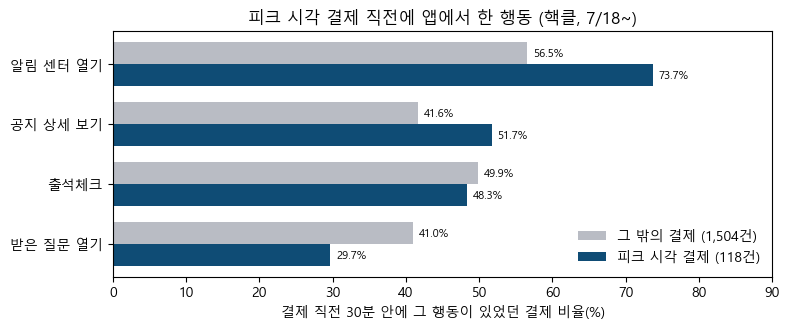

In [101]:
# 결제 직전 30분 안 행동 비율 그래프
a7 = act_tbl.drop('결제 수'); n7 = act_tbl.loc['결제 수']
y = np.arange(len(a7)); h = 0.36
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(y - h / 2, a7['그 밖의 결제'], h, color=GRAY_BAR, label=f"그 밖의 결제 ({int(n7['그 밖의 결제']):,}건)")
ax.barh(y + h / 2, a7['피크 시각 결제'], h, color=C1, label=f"피크 시각 결제 ({int(n7['피크 시각 결제']):,}건)")
for i in range(len(a7)):
    ax.text(a7['그 밖의 결제'].iloc[i] + 0.8, y[i] - h / 2, f"{a7['그 밖의 결제'].iloc[i]}%", va='center', fontsize=8)
    ax.text(a7['피크 시각 결제'].iloc[i] + 0.8, y[i] + h / 2, f"{a7['피크 시각 결제'].iloc[i]}%", va='center', fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(a7.index); ax.invert_yaxis(); ax.set_xlim(0, 90)
ax.set_xlabel('결제 직전 30분 안에 그 행동이 있었던 결제 비율(%)'); ax.set_title('피크 시각 결제 직전에 앱에서 한 행동 (핵클, 7/18~)')
ax.legend(frameon=False, loc='lower right')
plt.tight_layout(); plt.show()

- 피크 시각 결제 118건은 그 밖의 결제 1,504건보다 결제 직전 30분 안에 알림 센터를 연 비율이 17.2%p(73.7% 대 56.5%), 공지 상세를 본 비율이 10.1%p(51.7% 대 41.6%) 높음
- 받은 질문 열기는 11.3%p 낮고(29.7% 대 41.0%), 출석체크는 비슷함(48.3% 대 49.9%)
- 피크 시각 결제는 평소처럼 받은 질문을 열다 상점으로 간 경우보다, 알림이나 공지를 보고 들어온 경우가 많았음. 앱 안 알림·공지가 계기였다는 추정과 맞음
- 7/11~13은 핵클 이전이라 직접 확인하지 못했고, 같은 모양이 반복된 7/18 이후로 미루어 본 것임

---
## 부록 G. 세 그룹 보충

### G-1. 같은 반 친구 활동 구간별 그룹 구성
- 부록 D-8의 '활동한 같은 반 친구 수' 구간마다 첫 결제자가 세 그룹에 어떻게 나뉘는지 봄

그룹 (행 비중 %),첫 결제자,재결제 유저,재결제 병목 유저,이탈 유저
활동한 같은 반 친구 수,,,,
0명,2417,6.1,64.8,29.1
1~2명,3248,11.2,65.5,23.2
3~5명,6432,14.4,72.0,13.7
6~9명,12611,18.2,75.5,6.3
10명 이상,33163,21.6,76.3,2.2


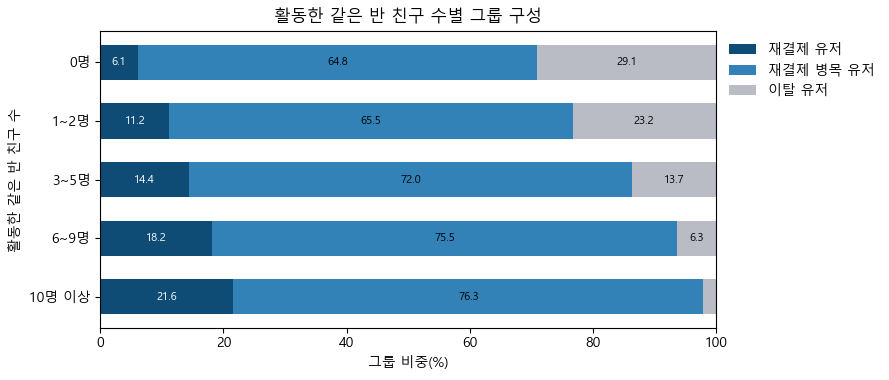

In [102]:
g7['mates_bin'] = g7.user_id.map(rb.set_index('user_id').mates_bin)       # 부록 D-8에서 만든 같은 반 친구 활동 구간
mt7 = pd.crosstab(g7.mates_bin, g7.grp, normalize='index').mul(100).round(1)
mt7.insert(0, '첫 결제자', g7.groupby('mates_bin', observed=False).size())
display(mt7.rename_axis(index='활동한 같은 반 친구 수', columns='그룹 (행 비중 %)'))
stack_bar(mt7[GROUPS7], '활동한 같은 반 친구 수별 그룹 구성', '활동한 같은 반 친구 수')

- 활동한 같은 반 친구가 적을수록 이탈 유저 비중이 커짐. 0명 29.1%, 10명 이상 2.2%임
- 재결제 유저 비중은 0명 6.1%에서 10명 이상 21.6%로 커지고(부록 D-8과 같은 값), 재결제 병목 유저 비중은 64.8~76.3%로 구간 사이 차이가 작음
- 같은 반 친구의 활동이 적은 첫 결제자는 재결제가 적을 뿐 아니라 본인의 활동 기록도 적음. 다만 같은 반 친구 수에는 그 친구가 본인과 주고받은 요청도 들어 있어(부록 D-8), 본인 활동이 없으면 친구 수도 조금 줄어드는 몫이 섞임

### G-2. 그룹 기준 확인: 받은 요청만 있는 사람, 핵클로 볼 수 있는 첫 결제자
- 본인 행동만 활동으로 셀 때(보낸 요청, 받은 요청 수락, 출석, 투표 데이터, 핵클) 그룹 크기가 얼마나 바뀌는지 봄
- 핵클 기간 첫 결제자(7/18~8/3)는 앱 사용 기록이 남아 있어, 그룹마다 실제로 앱을 썼는지 확인할 수 있음

In [103]:
own = (g7.fr_sent > 0) | (g7.fr_acc > 0) | g7.att7 | g7.vote7 | g7.hk7
alt7 = pd.Series(np.select([g7.re7, own], GROUPS7[:2], GROUPS7[2]), index=g7.index)
sens7 = pd.DataFrame({'4장 기준': g7.grp.value_counts().reindex(GROUPS7),
                      '본인 행동만 활동으로 셈': alt7.value_counts().reindex(GROUPS7)})
for c in list(sens7.columns):
    sens7[f'{c} 비중(%)'] = (sens7[c] / len(g7) * 100).round(1)
display(sens7.rename_axis('그룹'))
print(f"재결제 병목 유저 → 이탈 유저로 옮겨지는 사람(받은 요청만 있음): {int(((g7.grp == GROUPS7[1]) & (alt7 == GROUPS7[2])).sum()):,}명 / "
      f"이탈 유저 → 재결제 병목 유저로 옮겨지는 사람(7일 안에 요청 수락만 함): {int(((g7.grp == GROUPS7[2]) & (alt7 == GROUPS7[1])).sum()):,}명")

h7 = g7[g7.first_at >= HK_START]
hk_tbl = h7.groupby('grp', observed=False).agg(인원=('user_id', 'size'), 핵클=('hk7', 'mean'), 출석=('att7', 'mean'),
                                              받은질문열기=('hk_qopen', lambda s: (s > 0).mean()), 상점방문=('hk_shop', lambda s: (s > 0).mean()))
hk_tbl[['핵클', '출석', '받은질문열기', '상점방문']] = hk_tbl[['핵클', '출석', '받은질문열기', '상점방문']].mul(100).round(1)
hk_tbl.columns = ['인원', '핵클 기록(%)', '출석(%)', '받은 질문 열기(%)', '상점 방문(%)']
display(hk_tbl.rename_axis('그룹 (첫 결제 7/18~8/3, 첫 결제 후 7일)'))

,4장 기준,본인 행동만 활동으로 셈,4장 기준 비중(%),본인 행동만 활동으로 셈 비중(%)
그룹,,,,
재결제 유저,10888,10888,18.8,18.8
재결제 병목 유저,43136,39347,74.5,68.0
이탈 유저,3847,7636,6.6,13.2


재결제 병목 유저 → 이탈 유저로 옮겨지는 사람(받은 요청만 있음): 4,266명 / 이탈 유저 → 재결제 병목 유저로 옮겨지는 사람(7일 안에 요청 수락만 함): 477명


,인원,핵클 기록(%),출석(%),받은 질문 열기(%),상점 방문(%)
"그룹 (첫 결제 7/18~8/3, 첫 결제 후 7일)",,,,,
재결제 유저,26,100.0,69.2,84.6,100.0
재결제 병목 유저,600,99.7,66.7,53.5,40.3
이탈 유저,1,0.0,0.0,0.0,0.0


- 받은 요청만 있는 4,266명을 활동 없음으로 보면 재결제 병목 유저는 39,347명(68.0%), 이탈 유저는 7,636명(13.2%)이 됨. 7일 안에 요청을 수락만 한 477명은 반대로 이탈 유저에서 재결제 병목 유저로 옮겨짐. 받은 요청을 활동으로 보는지에 따라 이탈 유저 크기가 두 배 가까이 달라지므로, 그룹 크기를 말할 때 이 기준을 함께 밝혀야 함
- 핵클로 볼 수 있는 첫 결제자 627명 중 이탈 유저는 1명뿐임. 다만 활동을 첫 결제 시각부터 세서, 결제 직후의 핵클 이벤트도 활동으로 들어감. 첫 결제 10분 뒤부터 세면 이 627명 중 이탈 유저는 72명(11.5%)이 됨. 기록이 남아 있는 시기에도 이탈 유저는 생기지만, 이탈 유저의 대부분은 기록이 적던 5~6월 첫 결제자임
- 7일 관찰 대상 전체로 보면, 첫 결제 10분 뒤부터 셀 때 재결제 병목 유저 182명이 이탈 유저로 옮겨짐. 문제 정의의 91.8%는 91.4%가 되어 결론은 같음
- 같은 첫 결제자 중 재결제 병목 유저 600명은 40.3%만 7일 안에 상점에 왔고, 받은 질문을 연 비율은 재결제 유저 84.6%, 재결제 병목 유저 53.5%임. 재결제 병목 유저는 앱을 쓰지만 상점까지 가지 않는다는 3장 결과와 같은 방향임
- 재결제 유저의 상점 방문 100%는 재결제하려면 상점에 가야 해서 당연히 나오는 값임. 재결제 병목 유저의 핵클 기록 99.7%도 이 기간에는 핵클 기록이 재결제 병목 유저에 들어가는 기준이라 높게 나옴. 두 값은 그룹 차이의 근거로 쓰지 않음. 재결제 유저가 26명뿐이라 이 표는 방향을 보는 참고용임

---
## 부록 H. 첫 결제 분석

### H-1. 이전 가입자의 누적 첫 결제 비율

,결제 시작 후 일수,누적 첫 결제자,누적 비율(%)
날짜,,,
2023-05-14,0,8640,2.42
2023-05-20,6,19154,5.36
2023-05-27,13,22086,6.18
2023-06-13,30,24507,6.86
2023-07-31,78,25546,7.15
2023-08-10,88,25631,7.17


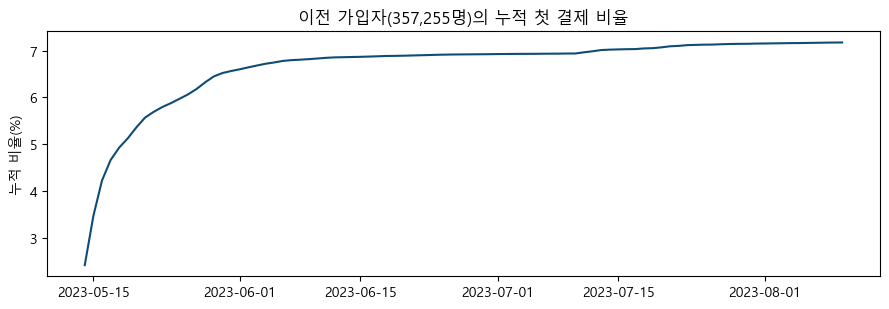

In [104]:
first_at = buyer.set_index('user_id').first_at
before = base[base.period == PERIODS[0]]
f_before = before.user_id.map(first_at)
rows = []
for d in ['2023-05-14', '2023-05-20', '2023-05-27', '2023-06-13', '2023-07-31', '2023-08-10']:
    n = int((f_before < pd.Timestamp(d) + pd.Timedelta(days=1)).sum())
    rows.append({'날짜': d, '결제 시작 후 일수': (pd.Timestamp(d) - PAY_START).days, '누적 첫 결제자': n,
                 '누적 비율(%)': round(n / len(before) * 100, 2)})
display(pd.DataFrame(rows).set_index('날짜'))

days = pd.date_range(PAY_START, DATA_END - pd.Timedelta(days=1))
cum = [(f_before < d + pd.Timedelta(days=1)).mean() * 100 for d in days]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(days, cum, color=C1)
ax.set_title(f'이전 가입자({len(before):,}명)의 누적 첫 결제 비율'); ax.set_ylabel('누적 비율(%)')
plt.tight_layout(); plt.show()

- 이전 가입자 357,255명 중 결제 시작 첫 주(5/20까지)에 5.36%가 첫 결제했고, 8/10까지는 7.17%로 1.8%p만 늘었음
- 결제 시작 전에 쌓인 수요가 첫 주에 한 번에 빠진 것으로 추정함

### H-2. 이후 가입자의 가입 주별 7일 첫 결제율
- 7일 첫 결제 = 가입 후 168시간 안의 첫 결제. 7일을 볼 수 있는 8/3까지 가입자만 셈

,가입자,7일 안 첫 결제자,7일 첫 결제율(%)
0주 (05/14~),161483,14030,8.69
1주 (05/21~),108871,11037,10.14
2주 (05/28~),33728,2290,6.79
3주 (06/04~),6770,356,5.26
4주 (06/11~),2142,78,3.64
5주 (06/18~),736,11,1.49
6주 (06/25~),370,5,1.35
7주 (07/02~),303,1,0.33
8주 (07/09~),714,34,4.76
9주 (07/16~),519,14,2.70


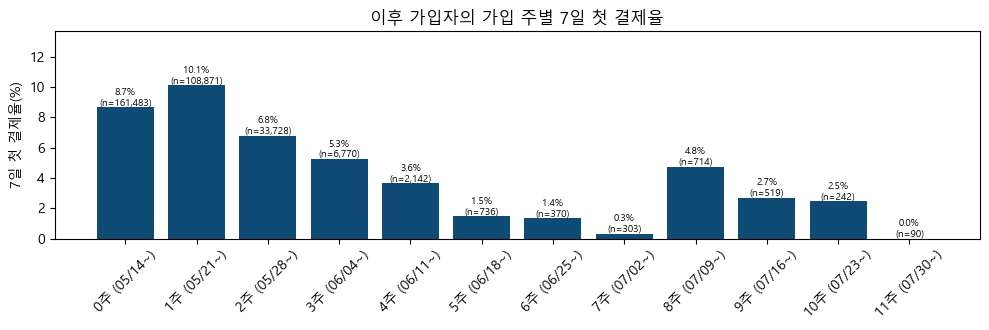

In [105]:
after = base[(base.period == PERIODS[1]) & (base.signup_at < OBS_END)].copy()
after['pay7'] = after.user_id.map(first_at) < after.signup_at + RE_WINDOW
a_wk = after.groupby('signup_week').pay7.agg(['size', 'sum', 'mean'])
a_wk.columns = ['가입자', '7일 안 첫 결제자', '7일 첫 결제율(%)']
a_wk['7일 첫 결제율(%)'] = (a_wk['7일 첫 결제율(%)'] * 100).round(2)
a_wk.index = [f'{week_no(w)}주 ({w:%m/%d}~)' for w in a_wk.index]
display(a_wk)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(a_wk.index, a_wk['7일 첫 결제율(%)'], color=C1)
for i, (v, n) in enumerate(zip(a_wk['7일 첫 결제율(%)'], a_wk['가입자'])):
    ax.text(i, v, f'{v:.1f}%\n(n={n:,})', ha='center', va='bottom', fontsize=7)
ax.set_ylim(0, a_wk['7일 첫 결제율(%)'].max() * 1.35)
ax.set_title('이후 가입자의 가입 주별 7일 첫 결제율'); ax.set_ylabel('7일 첫 결제율(%)'); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

- 0주 8.69%, 1주 10.14%에서 2주 6.79%, 3주 5.26%, 4주 3.64%로 떨어짐
- 8주(07/09~)에 4.76%로 다시 오른 것은 가입자 714명 중 34명의 값임

### H-3. 초기 친구 요청 수와 7일 첫 결제율
- 대상: 부록 H-2와 같은 이후 가입자. 가입 후 1시간 안에 보낸 요청, 받은 요청, 둘의 합을 같은 구간으로 나눔
- 요청 수는 0장의 공통 기준(가입 후 1시간)으로 셈
- 가입 후 1시간 안에 이미 첫 결제한 유저는 요청 집계 구간과 결제 시점이 겹침. 그 인원을 함께 출력함

보낸 요청               받은 요청             보낸+받은 요청            
                 가입자 7일 첫 결제율(%)     가입자 7일 첫 결제율(%)      가입자 7일 첫 결제율(%)
가입 후 1시간 요청 수                                                            
0건             35406        6.93  178817        7.20    27533        6.15
1~4건           45349        7.60  117159       10.36    42643        7.17
5~9건           53907        8.42   16733       13.64    51211        8.16
10~19건         87813        8.90    3108       17.54    90935        8.84
20~49건         79352        9.97     151       19.21    88411       10.18
50건 이상         14141       12.04       0         NaN    15235       12.36

가입 후 1시간 안에 첫 결제한 유저: 1,444명 (7일 안 첫 결제자의 5.2%)


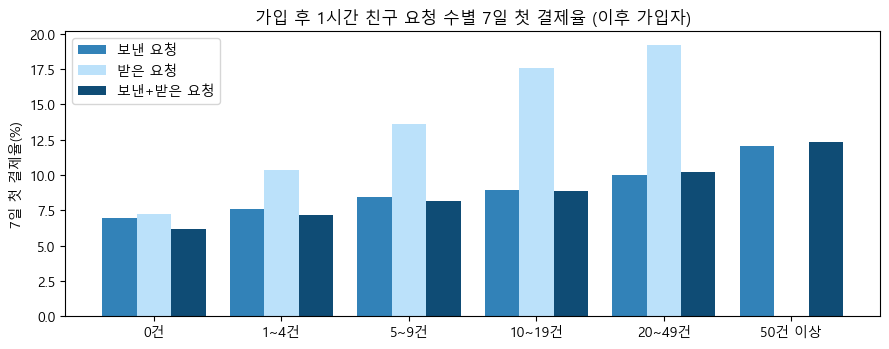

In [106]:
req_tbl = {}
for col, name in [('sent_1h', '보낸 요청'), ('recv_1h', '받은 요청'), ('req_1h', '보낸+받은 요청')]:
    b = pd.cut(after[col], REQ_BINS, labels=REQ_LABELS)
    g = after.groupby(b, observed=False).pay7.agg(['size', 'mean'])
    req_tbl[(name, '가입자')] = g['size']
    req_tbl[(name, '7일 첫 결제율(%)')] = (g['mean'] * 100).round(2)
req_tbl = pd.DataFrame(req_tbl)
req_tbl.index.name = '가입 후 1시간 요청 수'
display(req_tbl)
early = after.user_id.map(first_at) < after.signup_at + REQ_WINDOW
print(f'가입 후 1시간 안에 첫 결제한 유저: {int(early.sum()):,}명 (7일 안 첫 결제자의 {early.sum() / after.pay7.sum():.1%})')

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(REQ_LABELS)); w = 0.27
for i, (name, c) in enumerate(zip(['보낸 요청', '받은 요청', '보낸+받은 요청'], [C2, C3, C1])):
    ax.bar(x + (i - 1) * w, req_tbl[(name, '7일 첫 결제율(%)')], w, color=c, label=name)
ax.set_xticks(x); ax.set_xticklabels(REQ_LABELS)
ax.set_title('가입 후 1시간 친구 요청 수별 7일 첫 결제율 (이후 가입자)'); ax.set_ylabel('7일 첫 결제율(%)')
ax.legend()
plt.tight_layout(); plt.show()

- 받은 요청이 많을수록 7일 첫 결제율이 뚜렷하게 높음. 0건 7.20%, 1~4건 10.36%, 5~9건 13.64%, 10~19건 17.54%
- 보낸 요청도 0건 6.93%에서 50건 이상 12.04%로 오르지만 기울기가 완만함
- 가입 후 1시간 안에 첫 결제한 1,444명(7일 안 첫 결제자의 5.2%)은 요청을 세는 구간과 결제 시점이 겹침
- 초기 친구 요청 수는 첫 결제와는 관련이 있지만 재결제와는 거의 관련이 없음(부록 C-7, 부록 D-4)

---
## 부록 I. 힌트 기능 확인

5장과 6-4는 힌트를 '투표를 받은 사람이 하트(포인트)를 써서, 자신을 고른 사람의 이름을 첫째·둘째·셋째 글자 순서로 여는 기능'으로 보고 세그먼트 경계를 정했음. 프로젝트 안내 자료의 서비스 설명에는 '포인트(하트)를 사용하여 자신을 선택한 사람의 초성을 확인할 수 있다'고 되어 있음. 이 장은 그 설명이 데이터와 맞는지 확인함.

| 확인할 것 | 데이터 |
|---|---|
| 힌트 지출은 투표 하나(`accounts_userquestionrecord`)에 묶여 있나 | `accounts_pointhistory.user_question_record_id` |
| 힌트를 쓴 사람은 그 투표를 받은 사람(`chosen_user_id`)인가, 보낸 사람(`user_id`)인가 | 포인트 기록의 `user_id`와 투표 기록의 두 컬럼 비교 |
| 힌트는 투표가 생긴 뒤에 쓰였나 | 두 기록의 시각 비교 |
| 투표 하나에 힌트를 몇 번 썼나, 투표 기록의 `opened_times`·`status`와 맞나 | 5/18 가격 변경 뒤 투표만 (첫째·둘째·셋째 글자 = −200·−500·−1,000) |

- 포인트 기록과 투표 기록은 투표를 시작한 유저 약 5천 명만 있음
- 힌트가 보여 주는 내용(초성)은 데이터에 없음. 데이터로는 누가, 어떤 투표에, 몇 번 썼는지까지만 확인할 수 있음

In [107]:
# 힌트 지출을 투표 기록에 붙임
ph_i = read_cols('accounts_pointhistory', ['delta_point', 'created_at', 'user_id', 'user_question_record_id'], parse_dates=['created_at'])
ph_i = ph_i[ph_i.created_at < DATA_END]
uqr_i = read_cols('accounts_userquestionrecord', ['id', 'status', 'created_at', 'user_id', 'chosen_user_id', 'opened_times'], parse_dates=['created_at'])
uqr_i = uqr_i.rename(columns={'id': 'user_question_record_id', 'user_id': 'voter_id', 'created_at': 'voted_at'})
pi = ph_i.merge(uqr_i, on='user_question_record_id', how='left')

hint_i = pi[pi.delta_point.isin(HINT_PRICES)]
gain_i = pi[pi.delta_point > 0]
chk = pd.DataFrame([
    {'기록': '힌트 지출 (−200·−300·−500·−1,000)', '건수': len(hint_i),
     '투표 기록과 이어짐(%)': hint_i.voter_id.notna().mean() * 100,
     '쓴 사람 = 투표를 받은 사람(%)': (hint_i.user_id == hint_i.chosen_user_id).mean() * 100,
     '쓴 사람 = 투표를 보낸 사람(%)': (hint_i.user_id == hint_i.voter_id).mean() * 100,
     '투표가 생긴 뒤에 기록됨(%)': (hint_i.created_at >= hint_i.voted_at).mean() * 100},
    {'기록': '포인트 적립 (참고)', '건수': len(gain_i),
     '투표 기록과 이어짐(%)': gain_i.voter_id.notna().mean() * 100,
     '쓴 사람 = 투표를 받은 사람(%)': (gain_i.user_id == gain_i.chosen_user_id).mean() * 100,
     '쓴 사람 = 투표를 보낸 사람(%)': (gain_i.user_id == gain_i.voter_id).mean() * 100,
     '투표가 생긴 뒤에 기록됨(%)': (gain_i.created_at >= gain_i.voted_at).mean() * 100},
]).set_index('기록').round(1)
chk = chk.rename(columns={'쓴 사람 = 투표를 받은 사람(%)': '기록한 사람 = 투표를 받은 사람(%)', '쓴 사람 = 투표를 보낸 사람(%)': '기록한 사람 = 투표를 보낸 사람(%)'})
display(chk)

# 5/18 가격 변경 뒤 투표: 투표 하나에 쓴 힌트 수와 opened_times, status
CHANGE_DONE = pd.Timestamp('2023-05-18 22:00')
new_h = hint_i[(hint_i.voted_at >= CHANGE_DONE) & hint_i.delta_point.isin([-200, -500, -1000])]
per_v = new_h.groupby('user_question_record_id').agg(n_hint=('delta_point', 'size'), max_price=('delta_point', 'min'),
                                                  opened_times=('opened_times', 'first'), status=('status', 'first'))
per_v['same_open'] = per_v.n_hint == per_v.opened_times
per_v['is_I'] = per_v.status == 'I'
n_tbl = pd.DataFrame({'투표': per_v.groupby('n_hint').size(),
                      'opened_times가 힌트 수와 같음(%)': per_v.groupby('n_hint').same_open.mean().mul(100).round(1),
                      'status가 I(%)': per_v.groupby('n_hint').is_I.mean().mul(100).round(1)}).rename_axis('투표 하나에 쓴 힌트 수')
display(n_tbl)
print(f'힌트를 쓴 투표 {len(per_v):,}개 중 opened_times가 힌트 수와 같은 비율: {(per_v.n_hint == per_v.opened_times).mean() * 100:.1f}%')
seq_ok = new_h.sort_values('created_at').groupby('user_question_record_id').delta_point.apply(
    lambda s: list(s) == [-200, -500, -1000][:len(s)])
print(f'첫째(−200) → 둘째(−500) → 셋째(−1,000) 순서로 쓰인 투표: {seq_ok.mean() * 100:.1f}%')

v_new = uqr_i[(uqr_i.voted_at >= CHANGE_DONE) & (uqr_i.voted_at < DATA_END)]
has_h = v_new.user_question_record_id.isin(per_v.index)
print(f'5/18 이후 투표 {len(v_new):,}개 중 status가 I인 비율: 힌트 있음 {(v_new[has_h].status == "I").mean() * 100:.1f}% / 힌트 없음 {(v_new[~has_h].status == "I").mean() * 100:.1f}%')
del ph_i, uqr_i, pi, hint_i, gain_i, new_h

,건수,투표 기록과 이어짐(%),기록한 사람 = 투표를 받은 사람(%),기록한 사람 = 투표를 보낸 사람(%),투표가 생긴 뒤에 기록됨(%)
기록,,,,,
"힌트 지출 (−200·−300·−500·−1,000)",67832,100.0,100.0,0.1,100.0
포인트 적립 (참고),2219761,99.9,45.3,54.7,99.9


,투표,opened_times가 힌트 수와 같음(%),status가 I(%)
투표 하나에 쓴 힌트 수,,,
1,13628,99.9,99.9
2,4188,99.8,100.0
3,1079,100.0,99.8


힌트를 쓴 투표 18,895개 중 opened_times가 힌트 수와 같은 비율: 99.9%
첫째(−200) → 둘째(−500) → 셋째(−1,000) 순서로 쓰인 투표: 100.0%


5/18 이후 투표 454,764개 중 status가 I인 비율: 힌트 있음 99.9% / 힌트 없음 0.6%


- 힌트 지출 67,832건은 모두 투표 기록과 이어지고, 기록한 사람은 그 투표를 받은 사람(`chosen_user_id`)임(100.0%). 모두 투표가 생긴 뒤에 기록됨. 힌트는 투표를 받은 사람이 받은 투표 하나에 쓰는 기능임
- 포인트 적립은 투표를 보낸 사람 54.7%, 받은 사람 45.3%로 섞여 있어 힌트 지출과 다름
- 5/18 가격 변경 뒤 힌트를 쓴 투표 18,895개는 투표 하나에 힌트를 1번(13,628개), 2번(4,188개), 3번(1,079개) 썼고 4번 이상은 없음. 모두 −200 → −500 → −1,000 순서로 쓰임. 투표 하나에서 여는 글자는 세 개까지이고 첫째 글자부터 차례로 연다는 5장의 전제와 맞음
- 투표 기록의 `opened_times`는 99.9%가 그 투표에 쓴 힌트 수와 같음. `status`는 힌트를 쓴 투표의 99.9%가 I이고 쓰지 않은 투표는 0.6%만 I라, I는 힌트를 연 투표를 뜻하는 것으로 보임
- 힌트가 보여 주는 내용이 투표한 사람의 초성이라는 점은 데이터로 확인할 수 없고 서비스 설명에 따름. 데이터로 확인한 것은 '투표를 받은 사람이, 받은 투표 하나에, 첫째 글자부터 최대 세 번' 힌트를 쓴다는 것임

---
## 정리

### 확인한 것 (본문)

1. **배경**: 8/10까지 결제 92,944건의 88.1%가 5월에 몰려 있음 (1-2)
2. **현상과 문제**: 7일 재결제율은 첫 결제 0주 20.4%, 1주 20.7%에서 4주 7.1%로 떨어졌고, 8~11주(7/9~8/3)에는 5.9%임. 같은 기간 주별 첫 결제자는 30,035명에서 536명으로 줄었음. 1시간 경계에서도 19.4%에서 6.5%로 같은 흐름이고, 관찰 기간을 3·14·30일로 바꿔도 하락 흐름은 같음. 재결제한 사람은 첫 결제 뒤 7일 동안 재결제로 1인당 4,983원을 더 썼음(1인당 7일 추정 매출 7,558원 대 2,147원). 6월부터 매출의 절반 안팎이 첫 결제 이후 결제이고, 그중 대부분은 첫 결제 7일 뒤 결제임. 7일 안에 재결제하지 않은 첫 결제자 46,983명 중 91.8%는 그 7일 동안 활동 기록이 있음 (1-2, 2-2, 2-3, 4-2, 부록 A-1)
3. **퍼널**: 핵클 기간 첫 결제자의 72.7%가 7일 안에 앱을 다시 켰지만 상점에 다시 들어간 비율은 16.0%임. 재결제자 26명 중 24명이 상점에 다시 들어갔음. 결제 경험자 방문으로 넓혀 보면 하트 잔액이 많을수록 상점에 덜 가고(잔액 0~99 6.72%, 2,000 이상 1.27%), 받은 질문을 열다 잔액이 모자랄 때 상점에 감. 방문의 29.7%가 잔액 2,000 이상에서 시작함. 상점에 들어와도 절반은 아무것도 누르지 않음 (3장, 부록 E-5)
4. **재결제 그룹**: 7일 관찰 대상 첫 결제자를 재결제 유저(재결제함) 18.8%, 재결제 병목 유저(활동은 하는데 재결제 안 함) 74.5%, 이탈 유저(기록상 활동도 재결제도 없음) 6.6%로 나눔. 재결제 유저와 재결제 병목 유저는 연속 결제·정가 첫 결제에서 차이가 남. 이탈 유저는 가입 후 첫 결제까지 오래 걸린(중앙값 11.6일) 사람임 (4장)
5. **재결제 병목 유저 개선 우선순위**: 핵클 기간에 방문 시작 잔액이 찍힌 재결제 병목 유저 18,205명을 하트 잔액(힌트 가격 기준)으로 네 세그먼트로 나눔. 잔액이 적을수록 방문 중 결제율이 높음(200 미만 5.1%, 1,700 이상 0.1%). 같은 세그먼트 재결제 유저의 결제율을 기준치로 두면 추가 결제자가 200~699에서 155명으로 가장 많아, 우선순위는 200~699 → 200 미만 → 700~1,699 → 1,700 이상임 (5장)
6. **세그먼트별 개선안의 근거**: 잔액 1,700 미만 세 세그먼트에서 재결제 병목 유저는 상점에 들어온 뒤 유료 상품만 누른 방문이 재결제 유저의 절반 이하임(200~699: 23.0% 대 10.1%). 200~699에서는 무료충전소만 누르고 나간 방문이 재결제 유저보다 12.6%p 많음. 200 미만은 상점까지 오는 경로가 재결제 유저와 비슷함(받은 질문 열기 뒤 12.60% 대 12.24%). 재결제 유저의 첫 재결제 상품은 heart.1000 46.6%, heart.200 42.7%임. 받은 질문의 힌트를 셋째 글자까지 연 질문은 첫째 글자를 연 질문의 6.6%뿐임(투표 데이터 유저) (6장)

### 부록에서 확인한 것

- **재결제 상품**: 첫 결제의 94.1%가 특가 heart.777이고, 10분 뒤 두 번째 결제의 90.1%가 정가 heart.1000·heart.200임. 재결제는 특가 다음에 정가 상품을 사는지의 문제임 (부록 B-2)
- **재결제 조건**: 다른 조건을 맞춰도 첫 결제 주 차이가 그대로 남음(4주 이후 −16.1%p, 단순 비교 −14.4%p). 늦게 첫 결제한 사람이 원래 덜 사는 집단이라서가 아님. 첫 결제 방식도 함께 움직여, 첫 결제를 정가 상품으로 한 유저는 +17.1%p, 연속 결제가 있는 유저는 +14.7%p 높음 (부록 D-3)
- **시기 효과의 원인**: 첫 결제 주 차이 중 일부(4주 이후 −16.1%p 중 약 3분의 1)는 첫 결제 후 7일 동안 함께 활동한 같은 반 친구가 줄어든 것으로 설명됨. 본인과 주고받은 요청을 빼고 세도 결과가 같음. 힌트 가격 변경(5/18)은 원인이 아님. 나머지 차이는 남음 (부록 D-6~D-8)
- **유저 특성**: 학교·학년, 권역, 성별도 차이가 있지만 중요도는 각각 8% 이하임. 여학생이 높고 학년이 오를수록 높음. 학년은 첫 결제율과 방향이 다름(첫 결제율은 고3이 고1보다 낮음, 부록 C-3 참고). 초기 친구 요청 수는 재결제와 거의 관련이 없음 (부록 C, 부록 D)
- **7월 복귀**: 7/11~13, 7/18, 7/20, 7/21 저녁의 한 시간에 한두 달 쉬던 유저가 몰려 첫 결제(7/11~13 326명)와 결제 경험자의 복귀 구매(98명, 정가 상품 94.9%)를 함께 함. 결제 직전 알림 센터·공지를 본 비율이 높아 앱 안 알림·공지가 계기로 보임. 계기가 있으면 끊긴 결제도 다시 이어짐 (부록 F)
- **힌트 기능**: 힌트 지출 67,832건은 모두 그 투표를 받은 사람이 썼고, 5/18 이후에는 투표 하나에 첫째(−200)·둘째(−500)·셋째(−1,000) 글자 순서로 최대 세 번 쓰임. 5장 세그먼트 경계의 전제와 맞음 (부록 I)

### 수치를 볼 때 주의할 것

- 테스트 계정(`point` 100만 초과 4명)을 분석 대상에서 빼서, MySQL `final_clean`에서 바로 센 값보다 건수가 1~3씩 적음(0-9)
- 재결제는 첫 결제 후 10분 안의 결제(연속 결제)를 뺀 값임. 두 번째 결제를 모두 재결제로 센 기존 기준으로는 재결제율이 24.1%이고, 7월에 회복한 것처럼 보이는 착시가 생김 (부록 A-3)
- 3-1~3-2와 부록 E-1~E-3은 7~8월 첫 결제자 626명(재결제자 26명)만 볼 수 있어 방향을 보는 참고용임. 3-3·3-4, 부록 E-4·E-5, 부록 F-7도 핵클 기간(7~8월)의 이용자만 볼 수 있음
- 부록 F의 계기(알림 등)는 운영 기록이 없어, 결제 시각이 몰린 모양과 결제 직전 앱 안 행동으로 추정한 것임
- 부록 D 모형의 AUC는 0.65임. 예측 재결제율 차이와 중요도는 조건끼리 비교하는 데 쓰고, 원인이라는 뜻으로 쓰지 않음
- 4장의 이탈 유저는 활동 기록이 남지 않은 사람임. 출석은 5/27부터, 핵클은 7/18부터 기록되고 투표 데이터는 일부 유저만 있어, 0주 첫 결제자는 친구 요청과 투표 데이터로만 판단함. 받은 요청만 있는 사람을 활동 없음으로 보면 이탈 유저는 6.6%에서 13.2%로 커짐 (부록 G-2)
- 5장의 기준치(같은 세그먼트 재결제 유저의 결제율)는 비교 기준이지 예상 효과가 아님. 재결제 유저는 원래 더 사는 사람일 수 있음 (5-2)
- 6-2의 세그먼트·그룹별 상점 방문은 92~924회라 칸에 따라 비율이 흔들릴 수 있음. 6-4는 투표 데이터 유저(3,316명)의 값이라 5장 세그먼트별 값이 아님

### 다음 분석에서 볼 것

- 하트 잔액 중 결제로 산 하트와 무료로 받은 하트를 나눌 수 있는지. 3-4에서 잔액이 많으면 상점에 덜 간다는 것은 확인했지만, 그 잔액이 어디서 왔는지는 모름. 하트 사용 기록은 투표자 약 5천 명 표본과 핵클 기간에만 있음
- 첫 결제 주 차이 중 같은 반 친구 활동으로 설명되지 않는 나머지(4주 이후 −11.0%p, 부록 D-8). 친구 요청 외의 활동(받은 투표, 질문 확인)을 전체 유저 단위로 잴 방법이 있는지